# Rice From Space: What Does a Satellite Foundation Model Add?

**DIMER Philippines Rice Mapping Capstone** · **Profile:** `E2E` · **Mode:** `WORKSHOP` · **Kind:** `CAPSTONE` · **Notebook standard:** DIMER Notebook Specification `2.4` · **Release status:** Candidate · **Model:** `ibm-nasa-geospatial/Prithvi-EO-2.0-300M` @ `9eb1b1102806` · **Data:** Kaggle `kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching`, version 1

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use. Its rice maps are not official crop statistics, area estimates or agricultural advice.

**Driving question:** Given 32 labelled Sentinel-2 chips, does a head trained on frozen Prithvi-EO-2.0 features map Philippine rice better than a hand-built spectral-temporal baseline, and what can 8 validation chips actually establish?

Rice paddies change through the year: fields are flooded, the crop greens up, and then it is harvested. Optical satellites see that cycle as a pattern over time, not in a single image [1]. In this notebook you will compare three ways of turning a year of Sentinel-2 observations [2] into a rice map, and practise stating only what a small, clustered evaluation can support. It is an optional capstone after the *Rice from space* course lessons [L3 (Sentinel-2 LightGBM)](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) [11] and [L3B (AlphaEarth LightGBM)](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline) [12] on Kaggle; it links to them rather than re-teaching feature engineering.

**Who this notebook is for.** Learners who can open a hosted notebook, run cells in order and read short Python. No prior remote-sensing or deep-learning experience is assumed: each geospatial or evaluation term is explained at first use, and the glossary below collects them.

**Prerequisites and runtime.** A fresh Google Colab session with a **T4 GPU** (Runtime → Change runtime type → T4 GPU) and at least 12 GiB free disk. No account, token, upload, DIMER service or Git clone is needed. The notebook downloads the public teaching dataset (about 350 MB), the 1.33 GB model checkpoint and a hash-locked Python 3.12.12 environment (Linux x86_64 only). **Expected runtime: about 10 minutes** for Run all on the default path, measured as 589 s on a fresh Colab Tesla T4 for the previous blob `33037307` (commit `d82963c`, Colab CLI sequential execution, 2026-10-11, including the 75 s environment setup); about 11 minutes (633 s) in the same environment with the fine-tune and bring-your-own-data sections switched on. Each run measures and records its own runtime and GPU memory.

**Input → System → Output.** A year of six-band Sentinel-2 surface reflectance for a 2.56 km chip (24 calendar bins, 20 m pixels) → one of three systems: **A** call everything non-rice, **B** a LightGBM model on hand-built spectral-temporal features, or **C** a small head on frozen Prithvi-EO-2.0 features [3] → a 0/1 rice map scored against a published rice map. The trained head is exported, reloaded in a fresh process and can score your own chips.

### Learning objectives

By the end of this notebook you will be able to:

1. **Explain** Sentinel-2 bands, 20 m pixels, cloud gaps and temporal compositing, and why rice is a temporal signal.
2. **Trace** how the input a pretrained model expects is built — four quarterly frames, standardised, gaps filled — without resizing, and **identify** what was filled.
3. **Run** the training of a small head on frozen features and **compare** it with two baselines under a frozen protocol.
4. **Interpret** pooled precision, recall, F1 and IoU for a minority class, and **explain** why accuracy hides failure.
5. **Run** one controlled experiment (one frame versus four) and **explain** the result.
6. **Write** a bounded conclusion that states its evidence, its uncertainty and what it cannot claim.

### How to use this notebook

- **Run all** from a fresh T4 runtime (Runtime → Run all). Every cell runs in order without editing; nothing asks for input, and no manual restart is needed. The optional fine-tuning and bring-your-own-data sections are switched off by default.
- **Infrastructure** cells are collapsed and titled *Infrastructure*. They make the run reproducible. You may run them without studying their implementation; they are not learning objectives.
- Sections are tagged **[Concept]**, **[Evaluation practice]** or **[Engineering]**.
- Before each result you will be asked to **predict**. Write your prediction down first. After each result, **What to notice** describes normal output, and a collapsed **Check your reasoning** box holds a sample answer: open it only after answering.
- Completion notes are optional personal learning aids, **not required submissions**.

### Roadmap

| Section | What you do | Kind |
|---|---|---|
| 1 | Prepare a reproducible, isolated runtime | Engineering |
| 2 | Inspect the chips: bands, gaps, the rice season, the labels | Concept |
| 3 | Predict, declare the protocol, and run baselines A and B | Evaluation practice |
| 4 | Trace how Prithvi's input is built and extract frozen features | Concept |
| 5 | Train head C on the fit chips; choose epoch and threshold on development | Concept |
| 6 | Change one thing: one frame versus four | Evaluation practice |
| 7 | Optional extension: fine-tune the encoder (off by default) | Evaluation practice |
| 8 | Score A, B and C once on the validation chips | Evaluation practice |
| 9 | Interpret: pooled and per-chip results, error maps, the 320 m patch effect | Evaluation practice |
| 10 | Export, reload in a fresh process and verify | Engineering |
| 11 | Read the run's answer and conclude with evidence | Evaluation practice |
| 12 | Optional: bring your own chips | Engineering |

**Evidence boundary.** 40 chip-years: 32 for training, 8 for validation, all validation chips from two regions (Central and Eastern Visayas). This is a teaching comparison, not a national accuracy estimate, and it stays Candidate until a browser Run all of this exact notebook, including the upload dialog, is recorded.

### Problem statement

**Who has the problem.** Agencies, researchers and analysts who monitor rice in the Philippines and want a yearly map of where rice is grown, made from satellite imagery rather than from field surveys alone.

**The task.** Turn a year of Sentinel-2 observations of a 2.56 km chip into a 20 m map that marks each pixel rice or non-rice.

**What a useful outcome looks like.** On the 8 validation chips, which are scored once, a system is useful if its pooled rice F1 is clearly above the all-non-rice floor (A, F1 0). A pretrained foundation model adds something here only if its head (C) reaches a higher pooled rice F1 than the hand-built spectral-temporal baseline (B) on the same pixels. Section 10 states this run's answer from its own validation table.

**Scope boundary.** This notebook does not estimate rice area, cropping intensity or planting dates, does not forecast early in the season, and makes no national or operational accuracy claim.

### Data context

The sample is the public Kaggle dataset *Philippines Rice S2 AlphaEarth v1 Teaching*, version 1 [9] (CC BY 4.0), compiled by Kurt Valcorza. It is a 40-chip teaching subset of a larger benchmark of Philippine chips from 2019–2021: 32 training chips and 8 validation chips, each 128 × 128 pixels at 20 m (about 350 MB in total). Each chip holds 24 calendar-bin median composites of six Sentinel-2 surface-reflectance bands (modified Copernicus Sentinel data [2]), a validity mask, AlphaEarth annual embeddings [8] (not used here), and a label from published 20 m annual rice maps [4]: 0 non-rice, 1 rice, 255 ignore.

**How representative it is.** The chips were chosen by a seeded geographic sampling rule that favours rice-containing chips, not drawn as a probability sample, and all 8 validation chips come from two neighbouring regions (PH-07 Central Visayas, PH-08 Eastern Visayas). Rice is a minority of the labelled pixels. Labels are map products, not field observations. Whether Prithvi-EO-2.0's pretraining imagery covered these places is unknown. These gaps limit the results to tutorial evidence about these chips.

<details>
<summary><strong>Glossary</strong> — open when a term is unfamiliar</summary>

| Term | Meaning in this notebook |
|---|---|
| **Pixel** | One grid cell; here 20 m × 20 m on the ground. A chip is 128 × 128 pixels = 2.56 km square. |
| **Band** | One measured wavelength range. We use six Sentinel-2 bands: blue B2, green B3, red B4, narrow near-infrared B8A, shortwave-infrared B11 and B12 [2]. |
| **Surface reflectance** | The fraction of sunlight a surface reflects after atmospheric correction. The chips store it directly (digital number × 0.0001). |
| **Calendar bin / compositing** | The year is cut into 24 equal bins; each bin holds the median of the cloud-free observations that fell in it. Empty bins are missing, not zero. |
| **Valid mask** | `S2_valid` is 1 where a bin has a cloud-free observation. Missing values are NaN and are never read as reflectance. |
| **NDVI** | (NIR − red) / (NIR + red): high for green vegetation, low for water and bare soil. |
| **Label** | 0 non-rice, 1 rice, 255 ignore (including a 20 m band along class edges). Ignored pixels are never scored. |
| **Foundation model** | A large model pretrained on broad data and then adapted; Prithvi-EO-2.0 is one for Earth observation [3]. |
| **Frozen features / head** | The pretrained encoder's internal outputs, used without changing its weights; the *head* is the small trainable layer on top. |
| **Patch / token** | Prithvi cuts each frame into 16 × 16 pixel patches (320 m here) and describes each with a 1024-number *token*. |
| **Fit / development / validation** | Fit chips train models; development chips make every choice; validation chips are scored once, at the end. |
| **Threshold** | The cut-off that turns a rice score in [0, 1] into a rice/non-rice decision; choosing it is model selection. |
| **TP / FP / FN / TN** | Rice found / non-rice called rice / rice missed / non-rice correctly left. |
| **Precision / recall / F1 / IoU** | TP/(TP+FP) / TP/(TP+FN) / 2TP/(2TP+FP+FN) / TP/(TP+FP+FN). |
| **Pooled** | Counts summed over all scored pixels of all chips before computing a ratio. |
| **Epoch** | One pass of training over all fit chips; more epochs fit the fit chips more closely, which can stop helping on new chips. |
| **Loss (cross-entropy)** | The number training lowers: small when the head gives high rice scores to rice pixels and low ones to non-rice. |
| **Early stopping** | Keeping the epoch (or boosting round) where the development score was best instead of the last one. |
| **LightGBM / gradient boosting** | A fast method that adds many small decision trees, each correcting the previous ones; baseline B uses it on per-pixel features. |
| **Transformer encoder** | Prithvi's network: layers (blocks) that let every patch token exchange information with every other before the next block. |

</details>

## 1. Prepare a reproducible environment · [Engineering]

> **Infrastructure.** The next three code cells are collapsed. You may run them without studying their implementation; the learning activities start in Section 2.

**Input:** a fresh supported GPU runtime. **System:** hash-verified embedded files and a hash-locked dependency set installed into an isolated environment. **Output:** an isolated process for each stage and a record of the exact source, data and model identities.

Supported runtime: Google Colab (Linux x86_64) with a T4 GPU; the lock is built for manylinux x86_64 and the first cell stops on any other platform. Colab's own Python (3.13) and packages are left untouched: the model stack runs in a separate CPython 3.12.12 environment, so nothing is installed into the notebook kernel and no restart is needed. The cells download public data anonymously and stop on any failed integrity check; do not remove pins to get past a failure. Each run writes to a new directory.

In [1]:
# @title Infrastructure: check the runtime, GPU and disk; create a fresh run directory
import hashlib
import json
import os
import platform
import shutil
import subprocess
import time
import urllib.error
import urllib.request
import uuid
import zipfile
from pathlib import Path

SESSION_START = time.perf_counter()
if platform.system() != 'Linux' or platform.machine() != 'x86_64':
    raise RuntimeError('Supported runtime: Google Colab (Linux x86_64) with a T4 GPU. The hash lock is built for '
                       'manylinux x86_64; other platforms are not supported.')
try:
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], capture_output=True, text=True)
except FileNotFoundError as exc:
    raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then Runtime > Run all.') from exc
if gpu.returncode:
    raise RuntimeError('Select a fresh T4 GPU runtime; CUDA was not detected.')
print('GPU:', gpu.stdout.strip())
ROOT = Path.cwd() / 'outputs' / 'philippines_rice' / uuid.uuid4().hex[:12]
ROOT.mkdir(parents=True)
if shutil.disk_usage(ROOT).free < 12 * 1024**3:
    raise RuntimeError('At least 12 GiB free disk is required for the environment, weights, chips and exports.')
print('Run directory:', ROOT)

GPU: Tesla T4, 15360 MiB
Run directory: /content/outputs/philippines_rice/040eb744c708


In [2]:
# @title Infrastructure: write and verify the embedded source, lock and manifests
CARRIED_FILES = {
    'capstone.py': (
        '"""Stage runner for the DIMER Philippines Rice Mapping Capstone (E2E, WORKSHOP; capstone specification\n'
        'docs/philippines-rice-mapping-capstone-spec.md).\n'
        '\n'
        "The notebook writes this file, the repository's verbatim `pipeline.py` (as `prithvi_pipeline.py`), the hash lock and\n"
        'the manifests to a fresh run directory and runs each stage in a child process of the isolated environment:\n'
        '\n'
        '    prepare -> baseline -> features -> train-head -> activity -> [finetune] -> evaluate -> export -> reload -> report\n'
        '    byod (optional, after reload)\n'
        '\n'
        'Everything above the stage functions is numpy-only and importable without torch, h5py, lightgbm or matplotlib, so the\n'
        "repository's CPU tests exercise the scoring and bookkeeping contract on synthetic arrays.\n"
        '"""\n'
        '\n'
        'from __future__ import annotations\n'
        '\n'
        'import argparse\n'
        'import csv\n'
        'import hashlib\n'
        'import json\n'
        'import math\n'
        'import os\n'
        'import shutil\n'
        'import sys\n'
        'import time\n'
        'import zipfile\n'
        'from collections.abc import Callable, Iterable, Mapping, Sequence\n'
        'from pathlib import Path\n'
        'from typing import Any\n'
        '\n'
        'import numpy as np\n'
        '\n'
        "try:  # the notebook carries the repository's pipeline.py beside this file\n"
        '    import prithvi_pipeline as pp\n'
        'except ImportError:  # repository checkout (tests)\n'
        '    from prithvi_eo_feature_extraction_pipeline import pipeline as pp\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# identities and frozen protocol constants\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        'DATASET_SLUG = "kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching"\n'
        'DATASET_VERSION = 1  # v2 and v3 (2026-10-11) change only the card and rights wording; Kaggle built no download\n'
        '# archive for them, so the notebook pins v1, whose data, INDEX.jsonl and member hashes are identical\n'
        'INDEX_SHA256 = "e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d"\n'
        'DATASET_LICENSE = "CC BY 4.0"\n'
        'DEVELOPMENT_EXAMPLE_GROUP = "ph_96_766"  # a parent training sample: never used for selection or scoring\n'
        '\n'
        'N_BINS = 24\n'
        'N_BANDS = 6\n'
        'CHIP = 128\n'
        'QUARTERS = 4\n'
        'BINS_PER_QUARTER = N_BINS // QUARTERS\n'
        'BAND_NAMES = ("B2", "B3", "B4", "B8A", "B11", "B12")  # = pp.BANDS order: blue, green, red, narrow NIR, SWIR1, SWIR2\n'
        'IGNORE = 255\n'
        'PIXEL_METRES = 20.0\n'
        'EPSG = 32651\n'
        'REFLECTANCE_MIN = -0.5\n'
        'REFLECTANCE_MAX = pp.REFLECTANCE_MAX  # 2.0: larger values are reflectance x 10 000 and are refused, never rescaled\n'
        'FEATURE_LAYER = pp.FEATURE_LAYER  # 11 = block 12 of 24 (D3, fixed)\n'
        'PATCH = pp.PATCH\n'
        'EMBED_DIM = pp.EMBED_DIM\n'
        '\n'
        'SPLIT_SALT = "rice-capstone-split"\n'
        'DEV_FRACTION = 0.25\n'
        'MIN_DEV_RICE_CHIPS = 2\n'
        'THRESHOLDS = tuple(i / 100 for i in range(10, 91, 5))\n'
        'SPLIT_RULE = (\n'
        '    "whole regions ordered by SHA-256(\'rice-capstone-split:<k>:<region>\') are added to development while it holds at "\n'
        '    "most round(0.25 x training chips); the first k = 0, 1, ... giving at least target - 2 development chips, at least "\n'
        '    "two rice development chips and both classes in fit is used"\n'
        ')\n'
        '\n'
        'SEED = 0\n'
        'PIXEL_SEED = 20261003\n'
        'PIXEL_CAP = 65_536\n'
        'LGBM_PARAMS: dict[str, Any] = {\n'
        '    "objective": "binary", "metric": "None", "num_leaves": 31, "learning_rate": 0.05, "min_data_in_leaf": 100,\n'
        '    "feature_fraction": 0.8, "bagging_fraction": 1.0, "lambda_l2": 1.0, "deterministic": True, "force_col_wise": True,\n'
        '    "device_type": "cpu", "num_threads": 2, "seed": SEED, "feature_fraction_seed": SEED, "data_random_seed": SEED,\n'
        '    "verbosity": -1,\n'
        '}\n'
        'LGBM_ROUND_CAP = 200\n'
        'LGBM_PATIENCE = 50\n'
        '\n'
        'HEAD_HIDDEN = 256\n'
        'HEAD_CONFIG: dict[str, Any] = {\n'
        '    "optimizer": "AdamW", "learning_rate": 1e-3, "weight_decay": 0.01, "batch_size": 8, "max_epochs": 30,\n'
        '    "seed": SEED, "loss": "cross-entropy, ignore_index=255, no class weights", "augmentation": "none",\n'
        '    "epoch_rule": "highest development rice F1 at threshold 0.5; earliest epoch on ties",\n'
        '}\n'
        'FT_CONFIG: dict[str, Any] = {\n'
        '    "trainable": "patch_embed + cls_token + encoder blocks 1-12 (the blocks feeding block 12); blocks 13-24 and the "\n'
        '                 "decoder frozen",\n'
        '    "optimizer": "AdamW", "encoder_learning_rate": 1e-5, "head_learning_rate": 1e-3, "weight_decay": 0.01,\n'
        '    "batch_size": 4, "epochs": 10, "seed": SEED, "precision": "fp16 autocast + GradScaler",\n'
        '    "epoch_rule": "highest development rice F1 at threshold 0.5; earliest epoch on ties",\n'
        '}\n'
        'ARTIFACT_FORMAT = "org.valcorza.prithvi-rice-capstone.head.v1"\n'
        'ARTIFACT_WEIGHTS = "adapter.safetensors"\n'
        'ARTIFACT_MANIFEST = "manifest.json"\n'
        'HEAD_TENSORS = ("conv1.weight", "conv1.bias", "conv2.weight", "conv2.bias")\n'
        'RELOAD_TOLERANCE = 1e-4\n'
        'BYOD_MAX_FILES = 200\n'
        'BYOD_MAX_BYTES = 4 * 2**30  # expanded size of everything collected for one BYOD run\n'
        'BYOD_MIN_ADAPT_CHIPS = 6\n'
        '\n'
        'M1_STATS = ("mean", "std", "min", "max", "p10", "p50", "p90")\n'
        'M1_NAMES = [f"{b}_{s}" for b in BAND_NAMES for s in M1_STATS]\n'
        'M1_NAMES += [f"q{q + 1}_{b}_mean" for q in range(QUARTERS) for b in BAND_NAMES]\n'
        'M1_NAMES += [f"q{q + 1}_observed_fraction" for q in range(QUARTERS)]\n'
        '\n'
        'ATTRIBUTION = (\n'
        '    "Rice labels: Chen et al., rice maps of the Philippines (Zenodo, https://doi.org/10.5281/zenodo.15124936), CC BY 4.0.\\n"\n'
        '    "Contains modified Copernicus Sentinel data 2019-2021.\\n"\n'
        '    "AlphaEarth Foundations Satellite Embedding (Google / Google DeepMind; Brown et al., 2025), CC BY 4.0 - carried "\n'
        '    "in the dataset files; not read or shown by this notebook.\\n"\n'
        '    "Administrative regions: geoBoundaries PHL ADM1, CC BY 3.0 IGO.\\n"\n'
        '    "Dataset compilation: Kurt Valcorza, rice-philippines-s2-alphaearth-v1-teaching (Kaggle, version 1), CC BY 4.0.\\n"\n'
        '    "Model: ibm-nasa-geospatial/Prithvi-EO-2.0-300M (Apache-2.0), revision " + pp.MODEL_REVISION + ".\\n"\n'
        ')\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# small utilities\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def sha256_bytes(data: bytes) -> str:\n'
        '    return hashlib.sha256(data).hexdigest()\n'
        '\n'
        '\n'
        'def sha256_file(path: Path) -> str:\n'
        '    digest = hashlib.sha256()\n'
        '    with open(path, "rb") as handle:\n'
        '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
        '            digest.update(chunk)\n'
        '    return digest.hexdigest()\n'
        '\n'
        '\n'
        'def write_json(path: Path, value: Any) -> None:\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    path.write_text(json.dumps(value, indent=2, sort_keys=True, default=_json_default) + "\\n", encoding="utf-8")\n'
        '\n'
        '\n'
        'def _json_default(value: Any) -> Any:\n'
        '    if isinstance(value, np.generic):\n'
        '        return value.item()\n'
        '    if isinstance(value, np.ndarray):\n'
        '        return value.tolist()\n'
        '    if isinstance(value, Path):\n'
        '        return str(value)\n'
        '    raise TypeError(f"not JSON serialisable: {type(value).__name__}")\n'
        '\n'
        '\n'
        'def read_json(path: Path) -> Any:\n'
        '    if not path.is_file():\n'
        '        raise FileNotFoundError(f"{path.name} is missing: run the earlier stages in order (Runtime > Run all).")\n'
        '    return json.loads(path.read_text(encoding="utf-8"))\n'
        '\n'
        '\n'
        'def chip_id(row: Mapping[str, Any]) -> str:\n'
        '    return f"{row[\'group_id\']}_{row[\'year\']}"\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        "# chip schema (the BYOD contract is the dataset's own schema)\n"
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'class ChipError(ValueError):\n'
        '    """A chip does not satisfy the BYOD schema stated in Section 12; the message names the failed rule."""\n'
        '\n'
        '\n'
        'def validate_chip(arrays: Mapping[str, Any], *, name: str = "chip", require_label: bool = True) -> dict[str, Any]:\n'
        '    """Check one chip against the BYOD schema and return a normalised copy: S2 float32 with NaN wherever S2_valid is 0,\n'
        '    S2_valid uint8, label uint8 (or None). Raises ChipError with an actionable message."""\n'
        '    for key in ("S2", "S2_valid"):\n'
        '        if key not in arrays:\n'
        '            raise ChipError(f"{name}: missing key {key!r}; expected keys S2, S2_valid and label (see the schema)")\n'
        '    s2 = np.asarray(arrays["S2"])\n'
        '    valid = np.asarray(arrays["S2_valid"])\n'
        '    if s2.shape != (N_BINS, N_BANDS, CHIP, CHIP):\n'
        '        raise ChipError(f"{name}: S2 has shape {s2.shape}; expected {(N_BINS, N_BANDS, CHIP, CHIP)} (bins, bands, rows, cols)")\n'
        '    if not np.issubdtype(s2.dtype, np.floating):\n'
        '        raise ChipError(f"{name}: S2 has dtype {s2.dtype}; expected float32 reflectance")\n'
        '    if valid.shape != (N_BINS, CHIP, CHIP):\n'
        '        raise ChipError(f"{name}: S2_valid has shape {valid.shape}; expected {(N_BINS, CHIP, CHIP)}")\n'
        '    if not np.isin(valid, (0, 1)).all():\n'
        '        raise ChipError(f"{name}: S2_valid must contain only 0 and 1")\n'
        '    valid = valid.astype(np.uint8)\n'
        '    observed = np.broadcast_to(valid[:, None].astype(bool), s2.shape)\n'
        '    values = s2[observed]\n'
        '    if values.size and not np.isfinite(values).all():\n'
        '        raise ChipError(f"{name}: S2 has non-finite values where S2_valid = 1; mark those observations invalid")\n'
        '    if values.size and float(values.max()) > REFLECTANCE_MAX:\n'
        '        raise ChipError(\n'
        '            f"{name}: S2 maximum {float(values.max()):.1f} exceeds {REFLECTANCE_MAX}; the file looks like reflectance "\n'
        '            "x 10 000 - multiply by 0.0001 before uploading"\n'
        '        )\n'
        '    if values.size and float(values.min()) < REFLECTANCE_MIN:\n'
        '        raise ChipError(f"{name}: S2 minimum {float(values.min()):.3f} is below {REFLECTANCE_MIN}; not surface reflectance")\n'
        '    clean = np.where(observed, s2, np.nan).astype(np.float32)\n'
        '    label = None\n'
        '    if "label" in arrays:\n'
        '        label = np.asarray(arrays["label"])\n'
        '        if label.shape != (CHIP, CHIP):\n'
        '            raise ChipError(f"{name}: label has shape {label.shape}; expected {(CHIP, CHIP)}")\n'
        '        if not np.isin(label, (0, 1, IGNORE)).all():\n'
        '            bad = sorted(set(np.unique(label).tolist()) - {0, 1, IGNORE})[:5]\n'
        '            raise ChipError(f"{name}: label values {bad} are outside 0 (non-rice), 1 (rice), 255 (ignore)")\n'
        '        label = label.astype(np.uint8)\n'
        '    elif require_label:\n'
        '        raise ChipError(f"{name}: missing key \'label\'; scoring and adaptation need the 0/1/255 rice label")\n'
        '    return {"S2": clean, "S2_valid": valid, "label": label}\n'
        '\n'
        '\n'
        'def georeference_attrs(raw: Mapping[str, Any]) -> dict[str, Any]:\n'
        '    """Upper-left x_min/y_max and the site group from HDF5 attributes. Accepts this dataset\'s own schema (`affine` as a\n'
        '    JSON list or numeric array [a, b, c, d, e, f], `crs`, `group_id`) and the plain `x_min`/`y_max`/`group` form.\n'
        '    Coordinates must be finite; plain ones are refused with any CRS other than EPSG:32651, and an affine grid is used\n'
        '    only when it is EPSG:32651, 20 m and north-up. Anything else stays ungeoreferenced rather than mislocated."""\n'
        '\n'
        '    def text(value: Any) -> str | None:\n'
        '        try:\n'
        '            return value.decode("utf-8") if isinstance(value, bytes) else str(value)\n'
        '        except UnicodeDecodeError:\n'
        '            return None  # an undecodable optional attribute is unusable, not fatal\n'
        '\n'
        '    crs = (text(raw["crs"]) or "<undecodable>") if "crs" in raw else None\n'
        '    attrs: dict[str, Any] = {}\n'
        '    if "x_min" in raw and "y_max" in raw and crs in (None, "EPSG:32651"):\n'
        '        try:\n'
        '            x_min, y_max = float(raw["x_min"]), float(raw["y_max"])\n'
        '        except (TypeError, ValueError):\n'
        '            x_min = y_max = math.nan\n'
        '        if math.isfinite(x_min) and math.isfinite(y_max):\n'
        '            attrs.update(x_min=x_min, y_max=y_max)\n'
        '    if "affine" in raw and not attrs:\n'
        '        try:\n'
        '            value = raw["affine"]\n'
        '            numbers = json.loads(text(value)) if isinstance(value, (str, bytes)) else list(value)\n'
        '            a, b, c, d, e, f = (float(v) for v in numbers)\n'
        '        except (TypeError, ValueError):\n'
        '            a = b = c = d = e = f = math.nan\n'
        '        if crs == "EPSG:32651" and (a, b, d, e) == (20.0, 0.0, 0.0, -20.0) and math.isfinite(c) and math.isfinite(f):\n'
        '            attrs.update(x_min=c, y_max=f)\n'
        '    for key in ("group", "group_id"):\n'
        '        group = text(raw[key]) if key in raw else None\n'
        '        if group:\n'
        '            attrs["group"] = group\n'
        '            break\n'
        '    return attrs\n'
        '\n'
        '\n'
        'def read_chip_h5(path: Path, *, require_label: bool = True) -> dict[str, Any]:\n'
        '    """Read only S2, S2_valid, label (and the georeferencing attributes) from one HDF5 chip, then validate it."""\n'
        '    import h5py\n'
        '\n'
        '    try:\n'
        '        with h5py.File(path, "r") as handle:\n'
        '            arrays = {}\n'
        '            for key, shape in (("S2", (N_BINS, N_BANDS, CHIP, CHIP)), ("S2_valid", (N_BINS, CHIP, CHIP)),\n'
        '                               ("label", (CHIP, CHIP))):\n'
        '                if key not in handle:\n'
        '                    continue\n'
        '                dataset = handle[key]\n'
        '                if not isinstance(dataset, h5py.Dataset) or dataset.shape != shape or dataset.dtype.kind not in "fiub":\n'
        '                    declared = getattr(dataset, "shape", "a group")\n'
        '                    raise ChipError(f"{path.name}: {key} is {declared} ({getattr(dataset, \'dtype\', \'no dtype\')}); "\n'
        '                                    f"expected a numeric dataset of shape {shape} (checked before reading)")\n'
        '                arrays[key] = dataset[...]\n'
        '            attrs = georeference_attrs(dict(handle.attrs))\n'
        '    except OSError as exc:\n'
        '        raise ChipError(f"{path.name}: not a readable HDF5 file ({exc})") from exc\n'
        '    chip = validate_chip(arrays, name=path.name, require_label=require_label)\n'
        '    chip["attrs"] = attrs\n'
        '    return chip\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# Prithvi input: quarterly frame selection, NaN accounting, normalisation\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def valid_fractions(valid: np.ndarray) -> np.ndarray:\n'
        '    return np.asarray(valid, dtype=np.float64).reshape(N_BINS, -1).mean(axis=1)\n'
        '\n'
        '\n'
        'def select_frames(valid: np.ndarray) -> dict[str, Any]:\n'
        '    """The clearest bin of each calendar quarter (highest valid fraction), earliest bin on ties (study protocol)."""\n'
        '    fractions = valid_fractions(valid)\n'
        '    bins = []\n'
        '    for quarter in range(QUARTERS):\n'
        '        candidates = range(quarter * BINS_PER_QUARTER, (quarter + 1) * BINS_PER_QUARTER)\n'
        '        bins.append(min(candidates, key=lambda b: (-fractions[b], b)))\n'
        '    return {"bins": bins, "valid_fractions": [round(float(fractions[b]), 6) for b in bins]}\n'
        '\n'
        '\n'
        'def prithvi_input(chip: Mapping[str, Any], bins: Sequence[int]) -> tuple[np.ndarray, dict[str, Any]]:\n'
        '    """(6, T, 128, 128) standardised model input for the given bins and the fill record. Reflectance x 10 000, then the\n'
        "    pinned config means/stds (the repository's own `_normalise`), then every missing value -> 0, the pretraining mean.\n"
        '    Pure: the chip is not modified and repeated calls return identical arrays."""\n'
        '    s2 = np.asarray(chip["S2"], dtype=np.float32)\n'
        '    frames = s2[list(bins)].transpose(1, 0, 2, 3)  # (6, T, H, W) reflectance with NaN where unobserved\n'
        '    standard = pp._normalise(frames[None])[0].astype(np.float32)\n'
        '    missing = ~np.isfinite(standard)\n'
        '    filled = np.where(missing, np.float32(0.0), standard).astype(np.float32)\n'
        '    per_frame = missing.any(axis=0).reshape(len(bins), -1).mean(axis=1)\n'
        '    no_observation = missing.any(axis=0).all(axis=0)\n'
        '    record = {\n'
        '        "bins": [int(b) for b in bins],\n'
        '        "filled_fraction_per_frame": [round(float(v), 6) for v in per_frame],\n'
        '        "filled_fraction": round(float(missing.mean()), 6),\n'
        '        "pixels_without_any_observation": int(no_observation.sum()),\n'
        '    }\n'
        '    return filled, record\n'
        '\n'
        '\n'
        'def single_quarter_bins(selection: Mapping[str, Any], quarter: int) -> list[int]:\n'
        '    return [selection["bins"][quarter]]\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# fit / development split (whole regions, declared hash order, no RNG)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def split_fit_dev(rows: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '    """Assign the training chips to fit and development by whole region. Regions are ordered by\n'
        '    SHA-256("rice-capstone-split:<k>:<region>") and added to development while it holds at most round(0.25 n) chips;\n'
        '    the first attempt k = 0, 1, ... whose development set has at least target - 2 chips, at least two rice chips,\n'
        '    and leaves both classes in fit is used. Deterministic across library versions."""\n'
        '    train = sorted((r for r in rows if r["split"] == "train"), key=chip_id)\n'
        '    if not train:\n'
        '        raise ValueError("no training chips to split")\n'
        '    target = round(DEV_FRACTION * len(train))\n'
        '    regions = sorted({r["region_iso"] for r in train})\n'
        '    for attempt in range(100):\n'
        '        order = sorted(regions, key=lambda g: sha256_bytes(f"{SPLIT_SALT}:{attempt}:{g}".encode()))\n'
        '        dev_regions: list[str] = []\n'
        '        count = 0\n'
        '        for region in order:\n'
        '            size = sum(r["region_iso"] == region for r in train)\n'
        '            if count + size <= target:\n'
        '                dev_regions.append(region)\n'
        '                count += size\n'
        '            if count == target:\n'
        '                break\n'
        '        dev = [r for r in train if r["region_iso"] in dev_regions]\n'
        '        fit = [r for r in train if r["region_iso"] not in dev_regions]\n'
        '        rice_dev = sum(r["stratum"] == "rice" for r in dev)\n'
        '        fit_strata = {r["stratum"] for r in fit}\n'
        '        if len(dev) >= target - 2 and rice_dev >= MIN_DEV_RICE_CHIPS and fit_strata == {"rice", "nonrice"}:\n'
        '            return {\n'
        '                "rule": SPLIT_RULE,\n'
        '                "attempt": attempt, "target_dev_chips": target,\n'
        '                "development_regions": sorted(dev_regions), "fit_regions": sorted({r["region_iso"] for r in fit}),\n'
        '                "fit": [chip_id(r) for r in fit], "development": [chip_id(r) for r in dev],\n'
        '                "development_rice_chips": rice_dev,\n'
        '            }\n'
        '    raise ValueError("no region assignment satisfies the declared development constraints")\n'
        '\n'
        '\n'
        'def check_roles(roles: Mapping[str, Sequence[str]]) -> None:\n'
        '    seen: dict[str, str] = {}\n'
        '    for role, ids in roles.items():\n'
        '        for cid in ids:\n'
        '            if cid in seen:\n'
        '                raise ValueError(f"{cid} is in both {seen[cid]} and {role}")\n'
        '            if cid.startswith(DEVELOPMENT_EXAMPLE_GROUP + "_"):\n'
        '                raise ValueError("the development example is a training sample and must never be a scoring chip")\n'
        '            seen[cid] = role\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# metrics (pooled over label != 255; undefined ratios are null with a reason)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def confusion(probability: np.ndarray, label: np.ndarray, threshold: float) -> dict[str, int]:\n'
        '    probability = np.asarray(probability, dtype=np.float64)\n'
        '    label = np.asarray(label)\n'
        '    if probability.shape != label.shape:\n'
        '        raise ValueError(f"prediction shape {probability.shape} != label shape {label.shape}")\n'
        '    if not np.isin(label, (0, 1, IGNORE)).all():\n'
        '        raise ValueError("label values outside 0/1/255")\n'
        '    scored = label != IGNORE\n'
        '    if not np.isfinite(probability[scored]).all():\n'
        '        raise ValueError("non-finite score on a scored pixel; pixels are never hidden")\n'
        '    if ((probability[scored] < 0) | (probability[scored] > 1)).any():\n'
        '        raise ValueError("scores must lie in [0, 1]")\n'
        '    positive = probability >= threshold\n'
        '    return {\n'
        '        "tp": int((scored & positive & (label == 1)).sum()), "fp": int((scored & positive & (label == 0)).sum()),\n'
        '        "fn": int((scored & ~positive & (label == 1)).sum()), "tn": int((scored & ~positive & (label == 0)).sum()),\n'
        '    }\n'
        '\n'
        '\n'
        'def scores(counts: Mapping[str, int]) -> dict[str, Any]:\n'
        '    tp, fp, fn, tn = (int(counts[k]) for k in ("tp", "fp", "fn", "tn"))\n'
        '\n'
        '    def ratio(numerator: int, denominator: int) -> float | None:\n'
        '        return numerator / denominator if denominator else None\n'
        '\n'
        '    values = {\n'
        '        "f1": ratio(2 * tp, 2 * tp + fp + fn), "iou": ratio(tp, tp + fp + fn),\n'
        '        "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn), "accuracy": ratio(tp + tn, tp + fp + fn + tn),\n'
        '    }\n'
        '    reasons = {\n'
        '        "f1": "no reference rice and no predicted rice", "iou": "no reference rice and no predicted rice",\n'
        '        "precision": "no pixel predicted rice", "recall": "no reference rice pixel", "accuracy": "no scored pixel",\n'
        '    }\n'
        '    return {\n'
        '        "tp": tp, "fp": fp, "fn": fn, "tn": tn, "scored_pixels": tp + fp + fn + tn, "reference_rice_pixels": tp + fn,\n'
        '        **values, "undefined": "; ".join(f"{k}: {reasons[k]}" for k, v in values.items() if v is None),\n'
        '    }\n'
        '\n'
        '\n'
        'def pooled(probabilities: Sequence[np.ndarray], labels: Sequence[np.ndarray], threshold: float) -> dict[str, Any]:\n'
        '    if len(probabilities) != len(labels) or not labels:\n'
        '        raise ValueError("probabilities and labels must be non-empty and aligned")\n'
        '    total = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}\n'
        '    for probability, label in zip(probabilities, labels, strict=True):\n'
        '        for key, value in confusion(probability, label, threshold).items():\n'
        '            total[key] += value\n'
        '    return scores(total)\n'
        '\n'
        '\n'
        'def select_threshold(probabilities: Sequence[np.ndarray], labels: Sequence[np.ndarray]) -> dict[str, Any]:\n'
        '    """Highest pooled development rice F1 over THRESHOLDS; ties closest to 0.5, then the lower threshold."""\n'
        '    sweep = [{"threshold": t, **pooled(probabilities, labels, t)} for t in THRESHOLDS]\n'
        '    defined = [row for row in sweep if row["f1"] is not None]\n'
        '    if not defined:\n'
        '        raise ValueError("development F1 is undefined at every threshold (no reference rice on development chips)")\n'
        '    best = min(defined, key=lambda row: (-row["f1"], abs(row["threshold"] - 0.5), row["threshold"]))\n'
        '    return {"threshold": best["threshold"], "f1": best["f1"], "sweep": sweep}\n'
        '\n'
        '\n'
        'def select_epoch(curve: Sequence[Mapping[str, Any]]) -> int:\n'
        '    """Epoch (1-based) with the highest development F1 at 0.5; earliest on ties; undefined F1 counts as -1."""\n'
        '    if not curve:\n'
        '        raise ValueError("empty training curve")\n'
        '    return min(curve, key=lambda row: (-(row["dev_f1"] if row["dev_f1"] is not None else -1.0), row["epoch"]))["epoch"]\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        "# baseline B: the study's M1 spectral-temporal features (70 axes), class-stratified pixel sample, fit-only fill\n"
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def m1_features(chip: Mapping[str, Any]) -> np.ndarray:\n'
        '    """(H*W, 70) float32: per band mean/std/min/max/p10/p50/p90 of observed values, quarterly band means, quarterly\n'
        '    observed fractions. Missing statistics stay NaN here and are filled by the fit-only fill (study recipe)."""\n'
        '    import warnings\n'
        '\n'
        '    valid = np.asarray(chip["S2_valid"]).astype(bool)\n'
        '    values = np.where(valid[:, None], chip["S2"], np.nan)\n'
        '    blocks: list[np.ndarray] = []\n'
        '    with warnings.catch_warnings():\n'
        '        warnings.simplefilter("ignore", RuntimeWarning)\n'
        '        for band in range(N_BANDS):\n'
        '            x = values[:, band]\n'
        '            blocks += [np.nanmean(x, axis=0), np.nanstd(x, axis=0), np.nanmin(x, axis=0), np.nanmax(x, axis=0)]\n'
        '            blocks += list(np.nanpercentile(x, [10, 50, 90], axis=0))\n'
        '        for quarter in range(QUARTERS):\n'
        '            blocks.extend(np.nanmean(values[quarter * BINS_PER_QUARTER:(quarter + 1) * BINS_PER_QUARTER], axis=0))\n'
        '    blocks += [valid[q * BINS_PER_QUARTER:(q + 1) * BINS_PER_QUARTER].mean(axis=0) for q in range(QUARTERS)]\n'
        '    return np.stack(blocks, axis=-1).reshape(-1, len(M1_NAMES)).astype(np.float32)\n'
        '\n'
        '\n'
        'def fit_fill(features: np.ndarray) -> np.ndarray:\n'
        '    finite = np.isfinite(features)\n'
        '    count = finite.sum(axis=0)\n'
        '    if not count.all():\n'
        '        raise ValueError("a feature has no finite fit observation")\n'
        '    return np.where(finite, features, 0).sum(axis=0, dtype=np.float64) / count\n'
        '\n'
        '\n'
        'def fill_features(features: np.ndarray, fill: np.ndarray) -> np.ndarray:\n'
        '    if features.shape[-1] != len(fill) or not np.isfinite(fill).all():\n'
        '        raise ValueError("feature/fill mismatch")\n'
        '    return np.where(np.isfinite(features), features, fill).astype(np.float32)\n'
        '\n'
        '\n'
        'def pixel_sample(labels: Sequence[np.ndarray], cap: int, seed: int) -> list[np.ndarray]:\n'
        '    """Round-robin quotas over non-empty (chip, class) strata, then seeded selection without replacement (study)."""\n'
        '    if cap < 1:\n'
        '        raise ValueError("cap must be positive")\n'
        '    strata = [(i, c, np.flatnonzero(np.asarray(y).reshape(-1) == c)) for i, y in enumerate(labels) for c in (0, 1)]\n'
        '    strata = [s for s in strata if len(s[2])]\n'
        '    quotas = np.zeros(len(strata), dtype=int)\n'
        '    budget = min(cap, sum(len(s[2]) for s in strata))\n'
        '    while budget:\n'
        '        active = [j for j, s in enumerate(strata) if quotas[j] < len(s[2])]\n'
        '        step = max(1, budget // len(active))\n'
        '        for j in active:\n'
        '            take = min(step, len(strata[j][2]) - quotas[j], budget)\n'
        '            quotas[j] += take\n'
        '            budget -= take\n'
        '            if not budget:\n'
        '                break\n'
        '    selected: list[list[int]] = [[] for _ in labels]\n'
        '    rng = np.random.default_rng(seed)\n'
        '    for (i, _c, pixels), n in zip(strata, quotas, strict=True):\n'
        '        selected[i].extend(rng.choice(pixels, n, replace=False).tolist())\n'
        '    return [np.asarray(sorted(p), dtype=np.int64) for p in selected]\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# head artifact (safetensors + manifest), GeoTIFF, CSV and ZIP helpers\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def head_shapes(in_channels: int, hidden: int) -> dict[str, tuple[int, ...]]:\n'
        '    return {\n'
        '        "conv1.weight": (hidden, in_channels, 1, 1), "conv1.bias": (hidden,),\n'
        '        "conv2.weight": (2, hidden, 1, 1), "conv2.bias": (2,),\n'
        '    }\n'
        '\n'
        '\n'
        'def save_head(params: Mapping[str, np.ndarray], out_dir: Path, metadata: Mapping[str, Any]) -> Path:\n'
        '    """Write adapter.safetensors (float32 head tensors only; no base weights) and a manifest with digests."""\n'
        '    from safetensors.numpy import save_file\n'
        '\n'
        '    in_channels = int(params["conv1.weight"].shape[1])\n'
        '    hidden = int(params["conv1.weight"].shape[0])\n'
        '    expected = head_shapes(in_channels, hidden)\n'
        '    if set(params) != set(HEAD_TENSORS):\n'
        '        raise ValueError(f"head tensors {sorted(params)} != {sorted(HEAD_TENSORS)}")\n'
        '    for name, shape in expected.items():\n'
        '        if tuple(params[name].shape) != shape:\n'
        '            raise ValueError(f"{name}: shape {tuple(params[name].shape)} != {shape}")\n'
        '    out_dir.mkdir(parents=True, exist_ok=True)\n'
        '    weights = out_dir / ARTIFACT_WEIGHTS\n'
        '    save_file({k: np.ascontiguousarray(params[k], dtype=np.float32) for k in HEAD_TENSORS}, str(weights),\n'
        '              metadata={"format": ARTIFACT_FORMAT})\n'
        '    manifest = {\n'
        '        "format": ARTIFACT_FORMAT, "format_version": "1.0", "in_channels": in_channels, "hidden": hidden,\n'
        '        "tensors": {k: list(v) for k, v in expected.items()},\n'
        '        "files": [{"path": ARTIFACT_WEIGHTS, "bytes": weights.stat().st_size, "sha256": sha256_file(weights)}],\n'
        '        **dict(metadata),\n'
        '    }\n'
        '    write_json(out_dir / ARTIFACT_MANIFEST, manifest)\n'
        '    return out_dir\n'
        '\n'
        '\n'
        'def load_head(artifact_dir: Path, *, expect: Mapping[str, Any] | None = None) -> tuple[dict[str, np.ndarray], dict[str, Any]]:\n'
        '    """Read and verify an exported head: format, digests, tensor names and shapes, and any `expect` manifest keys."""\n'
        '    from safetensors.numpy import load_file\n'
        '\n'
        '    manifest = read_json(artifact_dir / ARTIFACT_MANIFEST)\n'
        '    if manifest.get("format") != ARTIFACT_FORMAT:\n'
        '        raise ValueError(f"artifact format {manifest.get(\'format\')!r} != {ARTIFACT_FORMAT!r}")\n'
        '    for key, value in (expect or {}).items():\n'
        '        if manifest.get(key) != value:\n'
        '            raise ValueError(f"artifact {key} {manifest.get(key)!r} != expected {value!r}")\n'
        '    for entry in manifest["files"]:\n'
        '        path = artifact_dir / entry["path"]\n'
        '        if path.stat().st_size != entry["bytes"] or sha256_file(path) != entry["sha256"]:\n'
        '            raise ValueError(f"{entry[\'path\']}: size or SHA-256 differs from the manifest")\n'
        '    params = load_file(str(artifact_dir / ARTIFACT_WEIGHTS))\n'
        '    expected = head_shapes(int(manifest["in_channels"]), int(manifest["hidden"]))\n'
        '    if set(params) != set(expected):\n'
        '        raise ValueError(f"artifact tensors {sorted(params)} != {sorted(expected)}")\n'
        '    for name, shape in expected.items():\n'
        '        if tuple(params[name].shape) != shape or list(shape) != manifest["tensors"][name]:\n'
        '            raise ValueError(f"{name}: shape mismatch against the manifest")\n'
        '    return params, manifest\n'
        '\n'
        '\n'
        'def head_forward_numpy(params: Mapping[str, np.ndarray], features: np.ndarray) -> np.ndarray:\n'
        '    """Patch-grid rice logits margin (B, h, w) of the 1x1-conv head, numpy reference (before upsampling)."""\n'
        '    from math import sqrt\n'
        '\n'
        '    w1 = params["conv1.weight"][:, :, 0, 0]\n'
        '    hidden = np.einsum("oc,bchw->bohw", w1, features) + params["conv1.bias"][None, :, None, None]\n'
        '    erf = np.vectorize(math.erf)\n'
        '    hidden = 0.5 * hidden * (1.0 + erf(hidden / sqrt(2.0)))\n'
        '    logits = np.einsum("oc,bchw->bohw", params["conv2.weight"][:, :, 0, 0], hidden) + params["conv2.bias"][None, :, None, None]\n'
        '    return logits[:, 1] - logits[:, 0]\n'
        '\n'
        '\n'
        'def write_geotiff(path: Path, array: np.ndarray, *, x_min: float | None, y_max: float | None,\n'
        '                  nodata: int | None = IGNORE, dtype: Any = np.uint8) -> None:\n'
        '    """Single-band GeoTIFF (EPSG:32651, 20 m, upper-left x_min/y_max) via tifffile GeoTIFF tags; without\n'
        '    coordinates a plain TIFF is written and the manifest says so. uint8 decisions by default; float32 for scores,\n'
        '    which have no nodata value (nodata=None)."""\n'
        '    import tifffile\n'
        '\n'
        '    array = np.ascontiguousarray(array, dtype=dtype)\n'
        '    extratags = [] if nodata is None else [(42113, "s", 0, str(nodata), True)]  # GDAL_NODATA\n'
        '    if x_min is not None and y_max is not None:\n'
        '        extratags += [\n'
        '            (33550, "d", 3, (PIXEL_METRES, PIXEL_METRES, 0.0), True),  # ModelPixelScale\n'
        '            (33922, "d", 6, (0.0, 0.0, 0.0, float(x_min), float(y_max), 0.0), True),  # ModelTiepoint\n'
        '            # GeoKeyDirectory: version 1.1.0, 3 keys: GTModelType=Projected, GTRasterType=PixelIsArea, ProjectedCRS\n'
        '            (34735, "H", 16, (1, 1, 0, 3, 1024, 0, 1, 1, 1025, 0, 1, 1, 3072, 0, 1, EPSG), True),\n'
        '        ]\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    tifffile.imwrite(path, array, photometric="minisblack", compression=None, extratags=extratags)\n'
        '\n'
        '\n'
        'def read_geotiff(path: Path) -> tuple[np.ndarray, dict[str, Any]]:\n'
        '    import tifffile\n'
        '\n'
        '    with tifffile.TiffFile(path) as tif:\n'
        '        page = tif.pages[0]\n'
        '        array = page.asarray()\n'
        '        tags = {tag.code: tag.value for tag in page.tags.values()}\n'
        '    geo: dict[str, Any] = {"nodata": int(tags[42113]) if 42113 in tags else None}\n'
        '    if 33922 in tags:\n'
        '        geo.update(x_min=float(tags[33922][3]), y_max=float(tags[33922][4]), pixel=float(tags[33550][0]),\n'
        '                   epsg=int(tags[34735][-1]))\n'
        '    return array, geo\n'
        '\n'
        '\n'
        'def _csv_value(value: Any) -> Any:\n'
        '    if value is None:\n'
        '        return ""\n'
        '    if isinstance(value, float):\n'
        '        return repr(round(value, 6))\n'
        '    return value\n'
        '\n'
        '\n'
        'def table_columns(rows: Sequence[Mapping[str, Any]]) -> list[str]:\n'
        '    """Every key of every row, in first-seen order, so rows with extra columns (labelled BYOD chips) keep them."""\n'
        '    return list(dict.fromkeys(key for row in rows for key in row))\n'
        '\n'
        '\n'
        'def write_csv(path: Path, rows: Sequence[Mapping[str, Any]], columns: Sequence[str] | None = None) -> None:\n'
        '    if not rows:\n'
        '        raise ValueError(f"refusing to write an empty table: {path.name}")\n'
        '    columns = list(columns or rows[0].keys())\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    with path.open("w", newline="", encoding="utf-8") as handle:\n'
        '        writer = csv.DictWriter(handle, fieldnames=columns, extrasaction="ignore", lineterminator="\\n")\n'
        '        writer.writeheader()\n'
        '        for row in rows:\n'
        '            writer.writerow({k: _csv_value(row.get(k)) for k in columns})\n'
        '\n'
        '\n'
        'def read_csv(path: Path) -> list[dict[str, Any]]:\n'
        '    def parse(value: str) -> Any:\n'
        '        if value == "":\n'
        '            return None\n'
        '        try:\n'
        '            return int(value)\n'
        '        except ValueError:\n'
        '            pass\n'
        '        try:\n'
        '            return float(value)\n'
        '        except ValueError:\n'
        '            return value\n'
        '\n'
        '    with path.open(newline="", encoding="utf-8") as handle:\n'
        '        return [{k: parse(v) for k, v in row.items()} for row in csv.DictReader(handle)]\n'
        '\n'
        '\n'
        'def build_zip(zip_path: Path, base: Path, members: Iterable[Path]) -> dict[str, str]:\n'
        '    """Deterministic ZIP (sorted names, fixed timestamps) with a checksums.json entry; returns the member digests."""\n'
        '    entries = sorted({p.resolve() for p in members if p.is_file()})\n'
        '    checksums = {p.relative_to(base.resolve()).as_posix(): sha256_file(p) for p in entries}\n'
        '    payload = json.dumps(checksums, indent=2, sort_keys=True).encode("utf-8")\n'
        '    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:\n'
        '        for name in sorted(checksums):\n'
        '            info = zipfile.ZipInfo(name, date_time=(2026, 1, 1, 0, 0, 0))\n'
        '            info.compress_type = zipfile.ZIP_DEFLATED\n'
        '            archive.writestr(info, (base / name).read_bytes())\n'
        '        info = zipfile.ZipInfo("checksums.json", date_time=(2026, 1, 1, 0, 0, 0))\n'
        '        archive.writestr(info, payload)\n'
        '    return checksums\n'
        '\n'
        '\n'
        'def verify_zip(zip_path: Path) -> dict[str, Any]:\n'
        '    with zipfile.ZipFile(zip_path) as archive:\n'
        '        names = archive.namelist()\n'
        '        for name in names:\n'
        '            if name.startswith("/") or ".." in Path(name).parts:\n'
        '                raise ValueError(f"unsafe member name {name!r}")\n'
        '        checksums = json.loads(archive.read("checksums.json"))\n'
        '        missing = sorted(set(checksums) - set(names))\n'
        '        mismatched = [n for n, d in checksums.items() if n in names and sha256_bytes(archive.read(n)) != d]\n'
        '        extra = sorted(set(names) - set(checksums) - {"checksums.json"})\n'
        '    if mismatched or extra or missing:\n'
        '        raise ValueError(f"results.zip integrity failure: mismatched {mismatched}, missing {missing}, unlisted {extra}")\n'
        '    return {"members": len(checksums), "verified": True}\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# dataset acquisition (public, anonymous; INDEX and member SHA-256 verified; expanded or zipped layouts)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def locate_member(root: Path, row: Mapping[str, Any], cache: Path) -> Path:\n'
        '    """Find one INDEX member in an expanded (`data-train/<path>`) or zipped (`data-train.zip`) layout, verify its\n'
        '    SHA-256 against INDEX and return a local path. Zip members are read in memory and written only after verifying."""\n'
        '    stem = row["archive"].removesuffix(".zip")\n'
        '    for candidate in (root / stem / row["path"], root / row["path"]):\n'
        '        if candidate.is_file():\n'
        '            if sha256_file(candidate) != row["sha256"]:\n'
        '                raise ValueError(f"{row[\'path\']}: SHA-256 differs from INDEX.jsonl")\n'
        '            return candidate\n'
        '    archive_path = root / row["archive"]\n'
        '    if archive_path.is_file():\n'
        '        with zipfile.ZipFile(archive_path) as archive:\n'
        '            data = archive.read(row["path"])\n'
        '        if sha256_bytes(data) != row["sha256"]:\n'
        '            raise ValueError(f"{row[\'path\']} in {row[\'archive\']}: SHA-256 differs from INDEX.jsonl")\n'
        '        target = cache / row["path"]\n'
        '        target.parent.mkdir(parents=True, exist_ok=True)\n'
        '        target.write_bytes(data)\n'
        '        return target\n'
        '    raise FileNotFoundError(f"{row[\'path\']} not found in {root} (neither expanded nor zipped)")\n'
        '\n'
        '\n'
        'def read_index(root: Path) -> list[dict[str, Any]]:\n'
        '    data = (root / "INDEX.jsonl").read_bytes()\n'
        '    if sha256_bytes(data) != INDEX_SHA256:\n'
        '        raise ValueError(f"INDEX.jsonl SHA-256 {sha256_bytes(data)} != pinned {INDEX_SHA256}; the dataset changed")\n'
        '    rows = [json.loads(line) for line in data.decode("utf-8").splitlines() if line.strip()]\n'
        '    if any(r["group_id"] == DEVELOPMENT_EXAMPLE_GROUP for r in rows):\n'
        '        raise ValueError("the development example must not appear in the scoring index")\n'
        '    return rows\n'
        '\n'
        '\n'
        'def download_dataset(cache: Path) -> Path:\n'
        '    os.environ.setdefault("KAGGLEHUB_CACHE", str(cache / "kagglehub"))\n'
        '    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"):\n'
        '        os.environ.pop(name, None)  # anonymous: no credential is needed or used\n'
        '    import kagglehub\n'
        '\n'
        '    started = time.perf_counter()\n'
        '    path = Path(kagglehub.dataset_download(f"{DATASET_SLUG}/versions/{DATASET_VERSION}"))\n'
        '    print(f"dataset resolved anonymously by kagglehub in {time.perf_counter() - started:.1f} s: {path}", flush=True)\n'
        '    return path\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# stage context\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'class Context:\n'
        '    def __init__(self, root: Path):\n'
        '        self.root = root\n'
        '        self.out = root / "outputs"\n'
        '        self.figures = self.out / "figures"\n'
        '        self.work = root / "work"\n'
        '        for path in (self.out, self.figures, self.work):\n'
        '            path.mkdir(parents=True, exist_ok=True)\n'
        '        self.started = time.perf_counter()\n'
        '\n'
        '    def records(self) -> dict[str, Any]:\n'
        '        return read_json(self.work / "records.json")\n'
        '\n'
        '    def chip(self, cid: str, *, require_label: bool = True) -> dict[str, Any]:\n'
        '        info = self.records()["chips"][cid]\n'
        '        return read_chip_h5(Path(info["path"]), require_label=require_label)\n'
        '\n'
        '    def receipt(self, stage: str, **extra: Any) -> None:\n'
        '        record = {"stage": stage, "seconds": round(time.perf_counter() - self.started, 2), **extra}\n'
        '        try:\n'
        '            import torch\n'
        '\n'
        '            if torch.cuda.is_available():\n'
        '                record["peak_gpu_gib"] = round(torch.cuda.max_memory_allocated() / 2**30, 3)\n'
        '        except ImportError:\n'
        '            pass\n'
        '        write_json(self.work / "receipts" / f"{stage}.json", record)\n'
        '        print(json.dumps(record), flush=True)\n'
        '\n'
        '\n'
        'def _plt():\n'
        '    import matplotlib\n'
        '\n'
        '    matplotlib.use("Agg")\n'
        '    import matplotlib.pyplot as plt\n'
        '\n'
        '    return plt\n'
        '\n'
        '\n'
        'def _rgb(chip: Mapping[str, Any], b: int, bands: Sequence[int]) -> np.ndarray:\n'
        '    image = np.stack([chip["S2"][b, i] for i in bands], axis=-1)\n'
        '    finite = np.isfinite(image)\n'
        '    hi = np.nanpercentile(image, 98) if finite.any() else 1.0\n'
        '    return np.clip(np.where(finite, image, 0) / max(hi, 1e-6), 0, 1)\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# stages\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def stage_prepare(ctx: Context) -> None:\n'
        '    manifest = read_json(ctx.root / "data_manifest.json")\n'
        '    if manifest["index_sha256"] != INDEX_SHA256 or manifest["slug"] != DATASET_SLUG:\n'
        '        raise ValueError("carried data manifest disagrees with the stage runner\'s pins")\n'
        '    root = download_dataset(ctx.root / "cache")\n'
        '    rows = read_index(root)\n'
        '    layout = "expanded" if (root / "data-train").is_dir() else "zipped"\n'
        '    package = {}\n'
        '    if (root / "PACKAGE.sha256").is_file():\n'
        '        for line in (root / "PACKAGE.sha256").read_text(encoding="utf-8").splitlines():\n'
        '            if line.strip():\n'
        '                digest, name = line.split(None, 1)\n'
        '                package[name.strip().lstrip("*")] = digest\n'
        '        if package.get("INDEX.jsonl") != INDEX_SHA256:\n'
        '            raise ValueError("PACKAGE.sha256 does not list the pinned INDEX.jsonl digest")\n'
        '    if layout == "zipped":\n'
        '        for archive in ("data-train.zip", "data-validation.zip"):\n'
        '            if sha256_file(root / archive) != manifest["package_sha256"][archive]:\n'
        '                raise ValueError(f"{archive}: SHA-256 differs from the pinned PACKAGE.sha256")\n'
        '    split = split_fit_dev(rows)\n'
        '    validation = sorted(chip_id(r) for r in rows if r["split"] == "validation")\n'
        '    roles = {"fit": split["fit"], "development": split["development"], "validation": validation}\n'
        '    check_roles(roles)\n'
        '    role_of = {cid: role for role, ids in roles.items() for cid in ids}\n'
        '    chips: dict[str, Any] = {}\n'
        '    table = []\n'
        '    valid_counts = np.zeros(N_BINS)\n'
        '    for row in sorted(rows, key=chip_id):\n'
        '        cid = chip_id(row)\n'
        '        path = locate_member(root, row, ctx.work / "chips")\n'
        '        chip = read_chip_h5(path)\n'
        '        frames = select_frames(chip["S2_valid"])\n'
        '        _x, fill = prithvi_input(chip, frames["bins"])\n'
        '        label = chip["label"]\n'
        '        valid_counts += chip["S2_valid"].reshape(N_BINS, -1).sum(axis=1)\n'
        '        chips[cid] = {\n'
        '            "path": str(path), "sha256": row["sha256"], "role": role_of[cid], "region": row["region_iso"],\n'
        '            "year": row["year"], "stratum": row["stratum"], "x_min": row["x_min"], "y_max": row["y_max"],\n'
        '            "frames": frames, "fill": fill,\n'
        '        }\n'
        '        table.append({\n'
        '            "chip": cid, "role": role_of[cid], "region": row["region_iso"], "year": row["year"],\n'
        '            "rice_pixels": int((label == 1).sum()), "nonrice_pixels": int((label == 0).sum()),\n'
        '            "ignored_pixels": int((label == IGNORE).sum()), "selected_bins": " ".join(map(str, frames["bins"])),\n'
        '            "min_selected_valid_fraction": min(frames["valid_fractions"]), "filled_fraction": fill["filled_fraction"],\n'
        '        })\n'
        '    for role in ("development", "validation"):\n'
        '        if not any(t["rice_pixels"] for t in table if t["role"] == role):\n'
        '            raise ValueError(f"no reference rice pixel in the {role} chips; the comparison cannot be scored")\n'
        '    probes = _refusal_probes(chips[roles["fit"][0]]["path"])  # validation must refuse bad chips before anything is written\n'
        '    write_json(ctx.work / "records.json", {"chips": chips, "roles": roles, "dataset_root": str(root), "layout": layout})\n'
        '    write_csv(ctx.out / "chips.csv", table)\n'
        '    write_json(ctx.out / "preprocessing.json", {\n'
        '        "frame_rule": "clearest bin (highest valid fraction) in each calendar quarter, earliest bin on ties",\n'
        '        "normalisation": "reflectance x 10000, then (x - mean) / std with the pinned Prithvi config statistics",\n'
        '        "means": list(pp.MEANS), "stds": list(pp.STDS), "missing_value_fill": 0.0,\n'
        '        "missing_fill_meaning": "0 after standardisation = the pretraining mean; pixels with no valid observation "\n'
        '        "in any selected frame stay scored",\n'
        '        "resampling": "none: native 20 m Sentinel-2 grid (Prithvi-EO-2.0 was pretrained on 30 m HLS)",\n'
        '        "chips": {cid: {"role": c["role"], **c["frames"], **c["fill"]} for cid, c in chips.items()},\n'
        '    })\n'
        '    write_json(ctx.out / "data_manifest.json", {\n'
        '        **manifest, "layout": layout, "chips_verified": len(chips), "index_rows": len(rows),\n'
        '        "roles": roles, "split": split,\n'
        '        "development_example": f"{DEVELOPMENT_EXAMPLE_GROUP} (a parent training sample) is never read",\n'
        '        "package_sha256_downloaded": package,\n'
        '    })\n'
        '    _prepare_figures(ctx, chips, table, valid_counts)\n'
        '    write_json(ctx.out / "prepare.json", {\n'
        '        "layout": layout, "chips": len(chips), "roles": {k: len(v) for k, v in roles.items()},\n'
        '        "development_regions": split["development_regions"], "fit_regions": split["fit_regions"],\n'
        '        "split_attempt": split["attempt"], "refusal_probes": probes, "table": table,\n'
        '    })\n'
        '    ctx.receipt("prepare", chips=len(chips), layout=layout)\n'
        '\n'
        '\n'
        'def _with_label_two(label: np.ndarray) -> np.ndarray:\n'
        '    """A copy of `label` with one labelled pixel set to 2, so the probe is invalid whether or not the chip holds rice."""\n'
        '    bad = np.array(label, dtype=np.uint8, copy=True)\n'
        '    labelled = np.flatnonzero(bad != 255)\n'
        '    bad.flat[labelled[0] if labelled.size else 0] = 2\n'
        '    return bad\n'
        '\n'
        '\n'
        'def _refusal_probes(path: str) -> list[dict[str, str]]:\n'
        '    chip = read_chip_h5(Path(path))\n'
        '    base = {"S2": chip["S2"], "S2_valid": chip["S2_valid"], "label": chip["label"]}\n'
        '    cases = {\n'
        '        "12 bins instead of 24": {**base, "S2": base["S2"][:12]},\n'
        '        "label value 2": {**base, "label": _with_label_two(base["label"])},\n'
        '        "reflectance x 10 000": {**base, "S2": np.nan_to_num(base["S2"]) * 10000.0},\n'
        '    }\n'
        '    results = []\n'
        '    for case, arrays in cases.items():\n'
        '        try:\n'
        '            validate_chip(arrays, name="probe")\n'
        '        except ChipError as exc:\n'
        '            results.append({"probe": case, "refused": "yes", "message": str(exc)})\n'
        '        else:\n'
        '            raise RuntimeError(f"validation accepted an invalid chip: {case}")\n'
        '    return results\n'
        '\n'
        '\n'
        'def _prepare_figures(ctx: Context, chips: Mapping[str, Any], table: Sequence[Mapping[str, Any]], counts: np.ndarray) -> None:\n'
        '    plt = _plt()\n'
        '    fit_rice = [t for t in table if t["role"] == "fit" and t["rice_pixels"]]\n'
        '    show = max(fit_rice, key=lambda t: (t["rice_pixels"], t["chip"]))["chip"]\n'
        '    chip = read_chip_h5(Path(chips[show]["path"]))\n'
        '    best = chips[show]["frames"]["bins"][int(np.argmax(chips[show]["frames"]["valid_fractions"]))]\n'
        '    label = chip["label"]\n'
        '    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))\n'
        '    axes[0].imshow(_rgb(chip, best, (2, 1, 0)))\n'
        '    axes[0].set_title(f"True colour (B4/B3/B2), bin {best}")\n'
        '    axes[1].imshow(_rgb(chip, best, (4, 3, 2)))\n'
        '    axes[1].set_title("False colour (B11/B8A/B4)")\n'
        '    overlay = np.zeros((*label.shape, 4))\n'
        '    overlay[label == 1] = (1.0, 0.85, 0.0, 0.75)\n'
        '    overlay[label == IGNORE] = (0.6, 0.6, 0.6, 0.6)\n'
        '    axes[2].imshow(_rgb(chip, best, (2, 1, 0)))\n'
        '    axes[2].imshow(overlay)\n'
        '    axes[2].set_title("Label: rice (yellow), ignore (grey)")\n'
        '    for ax in axes:\n'
        '        ax.set_axis_off()\n'
        '    fig.suptitle(f"{show} ({chips[show][\'region\']}, fit chip; 128 x 128 px = 2.56 km)")\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "overview_composites.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '\n'
        '    nir, red = chip["S2"][:, 3], chip["S2"][:, 2]\n'
        '    with np.errstate(invalid="ignore", divide="ignore"):\n'
        '        ndvi = (nir - red) / (nir + red)\n'
        '    rice_px = np.argwhere(label == 1)\n'
        '    non_px = np.argwhere(label == 0)\n'
        '    fig, ax = plt.subplots(figsize=(9, 3.8))\n'
        '    for pixels, name, colour in ((rice_px, "rice pixel", "#c08a00"), (non_px, "non-rice pixel", "#2a7a2a")):\n'
        '        if len(pixels):\n'
        '            r, c = pixels[len(pixels) // 2]\n'
        '            ax.plot(range(N_BINS), ndvi[:, r, c], marker="o", label=f"{name} (row {r}, col {c})", color=colour)\n'
        '    for q in range(1, QUARTERS):\n'
        '        ax.axvline(q * BINS_PER_QUARTER - 0.5, color="grey", lw=0.8, ls=":")\n'
        '    ax.set(xlabel="Calendar bin (24 per year; quarters dotted)", ylabel="NDVI", title=f"NDVI through the year, {show}")\n'
        '    ax.legend()\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "overview_ndvi_series.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '\n'
        '    fig, ax = plt.subplots(figsize=(9, 3.4))\n'
        '    ax.bar(range(N_BINS), counts / (len(chips) * CHIP * CHIP), color="#4a6fa5")\n'
        '    ax.set(xlabel="Calendar bin", ylabel="Valid fraction (all 40 chips)", ylim=(0, 1),\n'
        '           title="How often each bin has a cloud-free observation")\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "overview_valid_by_bin.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '\n'
        '\n'
        'def _labels(ctx: Context, ids: Sequence[str]) -> list[np.ndarray]:\n'
        '    return [ctx.chip(cid)["label"] for cid in ids]\n'
        '\n'
        '\n'
        'def stage_baseline(ctx: Context) -> None:\n'
        '    import lightgbm as lgb\n'
        '\n'
        '    roles = ctx.records()["roles"]\n'
        '    fit_chips = [ctx.chip(cid) for cid in roles["fit"]]\n'
        '    dev_chips = [ctx.chip(cid) for cid in roles["development"]]\n'
        '    fit_labels = [c["label"] for c in fit_chips]\n'
        '    dev_labels = [c["label"] for c in dev_chips]\n'
        '    picks = pixel_sample(fit_labels, PIXEL_CAP, PIXEL_SEED)\n'
        '    raw = np.concatenate([m1_features(c)[p] for c, p in zip(fit_chips, picks, strict=True)])\n'
        '    y = np.concatenate([c["label"].reshape(-1)[p] for c, p in zip(fit_chips, picks, strict=True)]).astype(np.float32)\n'
        '    fill = fit_fill(raw)\n'
        '    x = fill_features(raw, fill)\n'
        '    dev_features = [fill_features(m1_features(c), fill) for c in dev_chips]\n'
        '    keep = [lab.reshape(-1) != IGNORE for lab in dev_labels]\n'
        '    xd = np.concatenate([f[k] for f, k in zip(dev_features, keep, strict=True)])\n'
        '    yd = np.concatenate([lab.reshape(-1)[k] for lab, k in zip(dev_labels, keep, strict=True)]).astype(np.float32)\n'
        '\n'
        '    def dev_f1(probability, dataset):\n'
        '        score = pooled([probability], [dataset.get_label().astype(np.uint8)], 0.5)["f1"]\n'
        '        return "dev_rice_f1_at_0p5", score if score is not None else 0.0, True\n'
        '\n'
        '    started = time.perf_counter()\n'
        '    booster = lgb.train(LGBM_PARAMS, lgb.Dataset(x, label=y, feature_name=M1_NAMES), num_boost_round=LGBM_ROUND_CAP,\n'
        '                        valid_sets=[lgb.Dataset(xd, label=yd, feature_name=M1_NAMES)], valid_names=["development"],\n'
        '                        feval=dev_f1, callbacks=[lgb.early_stopping(LGBM_PATIENCE, verbose=False)])\n'
        '    seconds = time.perf_counter() - started\n'
        '    booster.save_model(str(ctx.work / "baseline_b.txt"), num_iteration=booster.best_iteration)\n'
        '    np.save(ctx.work / "baseline_b_fill.npy", fill)\n'
        '    dev_probs = [booster.predict(f, num_iteration=booster.best_iteration).reshape(CHIP, CHIP) for f in dev_features]\n'
        '    zero = [np.zeros((CHIP, CHIP)) for _ in dev_labels]\n'
        '    b_sel = select_threshold(dev_probs, dev_labels)\n'
        '    selection = {\n'
        '        "protocol": "every choice is made on development chips only and frozen before validation scoring",\n'
        '        "A": {"system": "all non-rice", "threshold": None},\n'
        '        "B": {"system": "M1 spectral-temporal LightGBM", "threshold": b_sel["threshold"], "dev_f1": b_sel["f1"],\n'
        '              "best_iteration": int(booster.best_iteration), "params": LGBM_PARAMS, "pixel_cap": PIXEL_CAP,\n'
        '              "pixel_seed": PIXEL_SEED, "fit_pixels": int(len(y)), "fit_rice_pixels": int(y.sum()),\n'
        '              "training_seconds": round(seconds, 2), "sweep": [_sweep_row(r) for r in b_sel["sweep"]]},\n'
        '    }\n'
        '    write_json(ctx.out / "selection.json", selection)\n'
        '    rows = [{"system": "A all-non-rice", "threshold": None, **pooled(zero, dev_labels, 0.5)},\n'
        '            {"system": "B LightGBM", "threshold": b_sel["threshold"], **pooled(dev_probs, dev_labels, b_sel["threshold"])}]\n'
        '    write_csv(ctx.out / "development_metrics.csv", rows, METRIC_COLUMNS)\n'
        '    ctx.receipt("baseline", best_iteration=int(booster.best_iteration))\n'
        '\n'
        '\n'
        'METRIC_COLUMNS = ["system", "threshold", "f1", "iou", "precision", "recall", "accuracy", "tp", "fp", "fn", "tn",\n'
        '                  "scored_pixels", "reference_rice_pixels", "undefined"]\n'
        'CHIP_COLUMNS = ["chip", "region", "system", "threshold", *METRIC_COLUMNS[2:]]\n'
        '\n'
        '\n'
        'def _sweep_row(row: Mapping[str, Any]) -> dict[str, Any]:\n'
        '    return {k: row[k] for k in ("threshold", "f1", "iou", "precision", "recall")}\n'
        '\n'
        '\n'
        '# ---- model stages (torch is imported only here) ------------------------------------------------------\n'
        '\n'
        '\n'
        'def _torch_setup(deterministic: bool = True):\n'
        '    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")\n'
        '    import torch\n'
        '\n'
        '    torch.manual_seed(SEED)\n'
        '    if deterministic:\n'
        '        torch.backends.cudnn.benchmark = False\n'
        '        torch.backends.cudnn.deterministic = True\n'
        '        torch.use_deterministic_algorithms(True, warn_only=True)\n'
        '    return torch\n'
        '\n'
        '\n'
        'def load_prithvi(ctx: Context) -> Any:\n'
        '    reports: list[Any] = []\n'
        '    weights = ctx.root / "weights" / pp.MODEL_KEY\n'
        '    pipe = pp.PrithviFeaturePipeline.from_pretrained(weights_dir=weights, allow_download=True, report=reports.append)\n'
        '    record = {\n'
        '        "model_id": pp.MODEL_ID, "revision": pp.MODEL_REVISION, "source_checkpoint_sha256": pp.SOURCE_CKPT_SHA256,\n'
        '        "converted_sha256": pp.CONVERTED_SHA256, "pickle_audit_sha256": pp.PICKLE_AUDIT_SHA256,\n'
        '        "parameters": pp.PARAMETER_COUNT, "strict_load": True, "device": pipe.device, "source": pipe.source,\n'
        '        "feature_layer_zero_based": FEATURE_LAYER, "conversion": reports,\n'
        '    }\n'
        '    write_json(ctx.out / "model.json", record)\n'
        '    return pipe\n'
        '\n'
        '\n'
        'def encode(pipe: Any, batch: np.ndarray) -> np.ndarray:\n'
        '    """(B, 6, T, H, W) standardised input -> (B, 1024, H/16, W/16) temporal mean of block-12 patch tokens."""\n'
        '    import torch\n'
        '\n'
        '    b, _c, t, h, w = batch.shape\n'
        '    with torch.inference_mode():\n'
        '        features = pipe.model.encoder.forward_features(torch.from_numpy(np.ascontiguousarray(batch)).to(pipe.device))\n'
        '    tokens = features[FEATURE_LAYER][:, 1:].float()\n'
        '    expected = t * (h // PATCH) * (w // PATCH)\n'
        '    if tokens.shape[1] != expected:\n'
        '        raise RuntimeError(f"encoder returned {tokens.shape[1]} patch tokens, expected {expected} (1 + T*64 with CLS)")\n'
        '    if not torch.isfinite(tokens).all():\n'
        '        raise RuntimeError("non-finite encoder features")\n'
        '    grid = tokens.reshape(b, t, h // PATCH, w // PATCH, EMBED_DIM).mean(dim=1).permute(0, 3, 1, 2)\n'
        '    return grid.contiguous().cpu().numpy()\n'
        '\n'
        '\n'
        'def stage_features(ctx: Context) -> None:\n'
        '    torch = _torch_setup()\n'
        '    if not torch.cuda.is_available():\n'
        '        raise RuntimeError("CUDA is not available; select a T4 GPU runtime")\n'
        '    torch.cuda.reset_peak_memory_stats()\n'
        '    pipe = load_prithvi(ctx)\n'
        '    records = ctx.records()\n'
        '    started = time.perf_counter()\n'
        '    t4: dict[str, np.ndarray] = {}\n'
        '    t1: dict[int, dict[str, np.ndarray]] = {q: {} for q in range(QUARTERS)}\n'
        '    token_checks = {}\n'
        '    for cid, info in sorted(records["chips"].items()):\n'
        '        chip = ctx.chip(cid)\n'
        '        x, _fill = prithvi_input(chip, info["frames"]["bins"])\n'
        '        t4[cid] = encode(pipe, x[None])[0]\n'
        '        token_checks[cid] = list(t4[cid].shape)\n'
        '        if info["role"] in ("fit", "development"):\n'
        '            for q in range(QUARTERS):\n'
        '                xq, _ = prithvi_input(chip, single_quarter_bins(info["frames"], q))\n'
        '                t1[q][cid] = encode(pipe, xq[None])[0]\n'
        '    np.savez(ctx.work / "features_t4.npz", **t4)\n'
        '    for q in range(QUARTERS):\n'
        '        np.savez(ctx.work / f"features_t1_q{q + 1}.npz", **t1[q])\n'
        '    seconds = time.perf_counter() - started\n'
        '    write_json(ctx.out / "features.json", {\n'
        '        "feature": "block 12 (zero-based 11) patch tokens, temporal mean, grid 8 x 8 x 1024 per 128 px chip",\n'
        '        "precision": "float32, inference mode, deterministic cuDNN", "chips_t4": len(t4),\n'
        '        "chips_t1_per_quarter": len(t1[0]), "seconds": round(seconds, 2),\n'
        '        "peak_gpu_gib": round(torch.cuda.max_memory_allocated() / 2**30, 3), "torch": torch.__version__,\n'
        '        "gpu": torch.cuda.get_device_name(0), "grid_shapes": sorted({tuple(v) for v in token_checks.values()}),\n'
        '    })\n'
        '    ctx.receipt("features")\n'
        '\n'
        '\n'
        'HEAD_OUTPUT_ORDER = ("both logit channels bilinearly upsampled from 8 x 8 to 128 x 128 px (align_corners=False), then "\n'
        '                     "softmax over the two channels; the rice score is channel 1")\n'
        '\n'
        '\n'
        'def _head_module(torch: Any, in_channels: int = EMBED_DIM, hidden: int = HEAD_HIDDEN):\n'
        '    nn = torch.nn\n'
        '\n'
        '    class Head(nn.Module):\n'
        '        def __init__(self):\n'
        '            super().__init__()\n'
        '            self.conv1 = nn.Conv2d(in_channels, hidden, 1)\n'
        '            self.act = nn.GELU()\n'
        '            self.conv2 = nn.Conv2d(hidden, 2, 1)\n'
        '\n'
        '        def forward(self, x):\n'
        '            logits = self.conv2(self.act(self.conv1(x)))\n'
        '            return torch.nn.functional.interpolate(logits, size=(CHIP, CHIP), mode="bilinear", align_corners=False)\n'
        '\n'
        '    return Head()\n'
        '\n'
        '\n'
        'def head_probabilities(torch: Any, head: Any, features: np.ndarray, device: str = "cpu") -> np.ndarray:\n'
        '    head.eval()\n'
        '    with torch.inference_mode():\n'
        '        logits = head(torch.from_numpy(np.ascontiguousarray(features)).float().to(device))\n'
        '        return torch.softmax(logits, dim=1)[:, 1].double().cpu().numpy()\n'
        '\n'
        '\n'
        'def train_head(torch: Any, fit_x: np.ndarray, fit_y: np.ndarray, dev_x: np.ndarray, dev_y: np.ndarray,\n'
        '               epochs: int, *, select_best: bool = True,\n'
        '               log: Callable[[str], None] = print) -> tuple[dict[str, np.ndarray], list[dict[str, Any]]]:\n'
        '    """Train the head on cached features (CPU, seed 0) and return (state, development curve). With select_best the\n'
        '    state is the epoch chosen by `select_epoch`; without it, the state after exactly `epochs` epochs."""\n'
        '    torch.manual_seed(SEED)\n'
        '    head = _head_module(torch, fit_x.shape[1])\n'
        '    optimiser = torch.optim.AdamW(head.parameters(), lr=HEAD_CONFIG["learning_rate"], weight_decay=HEAD_CONFIG["weight_decay"])\n'
        '    xs = torch.from_numpy(fit_x).float()\n'
        '    ys = torch.from_numpy(fit_y.astype(np.int64))\n'
        '    generator = torch.Generator().manual_seed(SEED)\n'
        '    curve: list[dict[str, Any]] = []\n'
        '    states: dict[int, dict[str, np.ndarray]] = {}\n'
        '    for epoch in range(1, epochs + 1):\n'
        '        head.train()\n'
        '        order = torch.randperm(len(xs), generator=generator)\n'
        '        losses = []\n'
        '        for start in range(0, len(xs), HEAD_CONFIG["batch_size"]):\n'
        '            idx = order[start:start + HEAD_CONFIG["batch_size"]]\n'
        '            loss = torch.nn.functional.cross_entropy(head(xs[idx]), ys[idx], ignore_index=IGNORE)\n'
        '            optimiser.zero_grad()\n'
        '            loss.backward()\n'
        '            optimiser.step()\n'
        '            losses.append(float(loss))\n'
        '        probs = head_probabilities(torch, head, dev_x)\n'
        '        dev = pooled(list(probs), list(dev_y), 0.5)\n'
        '        with torch.inference_mode():\n'
        '            dev_loss = float(torch.nn.functional.cross_entropy(head(torch.from_numpy(dev_x).float()),\n'
        '                                                               torch.from_numpy(dev_y.astype(np.int64)), ignore_index=IGNORE))\n'
        '        curve.append({"epoch": epoch, "fit_loss": float(np.mean(losses)), "dev_loss": dev_loss, "dev_f1": dev["f1"]})\n'
        '        states[epoch] = {k: v.detach().cpu().numpy().copy() for k, v in head.state_dict().items()}\n'
        '        log(f"epoch {epoch:2d}  fit loss {curve[-1][\'fit_loss\']:.4f}  dev loss {dev_loss:.4f}  dev F1@0.5 {dev[\'f1\']}")\n'
        '    return states[select_epoch(curve) if select_best else epochs], curve\n'
        '\n'
        '\n'
        'def _stack(cache: Mapping[str, np.ndarray], ids: Sequence[str]) -> np.ndarray:\n'
        '    return np.stack([cache[cid] for cid in ids]).astype(np.float32)\n'
        '\n'
        '\n'
        'def _load_head(torch: Any, state: Mapping[str, np.ndarray]):\n'
        '    head = _head_module(torch, int(state["conv1.weight"].shape[1]), int(state["conv1.weight"].shape[0]))\n'
        '    head.load_state_dict({k: torch.from_numpy(np.asarray(v)) for k, v in state.items()}, strict=True)\n'
        '    return head\n'
        '\n'
        '\n'
        'def stage_train_head(ctx: Context) -> None:\n'
        '    torch = _torch_setup()\n'
        '    roles = ctx.records()["roles"]\n'
        '    cache = dict(np.load(ctx.work / "features_t4.npz"))\n'
        '    fit_y = np.stack(_labels(ctx, roles["fit"]))\n'
        '    dev_y = np.stack(_labels(ctx, roles["development"]))\n'
        '    state, curve = train_head(torch, _stack(cache, roles["fit"]), fit_y, _stack(cache, roles["development"]), dev_y,\n'
        '                              HEAD_CONFIG["max_epochs"])\n'
        '    epoch = select_epoch(curve)\n'
        '    np.savez(ctx.work / "head_c.npz", **state)\n'
        '    probs = head_probabilities(torch, _load_head(torch, state), _stack(cache, roles["development"]))\n'
        '    c_sel = select_threshold(list(probs), list(dev_y))\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    selection["C"] = {"system": "frozen Prithvi-EO-2.0 block 12 + 1x1-conv head", "threshold": c_sel["threshold"],\n'
        '                      "dev_f1": c_sel["f1"], "selected_epoch": epoch, "config": HEAD_CONFIG, "frames": 4,\n'
        '                      "sweep": [_sweep_row(r) for r in c_sel["sweep"]]}\n'
        '    write_json(ctx.out / "selection.json", selection)\n'
        '    write_csv(ctx.out / "head_curve.csv", curve)\n'
        '    rows = read_csv(ctx.out / "development_metrics.csv")\n'
        '    rows = [r for r in rows if not str(r["system"]).startswith("C ")]\n'
        '    rows.append({"system": "C frozen Prithvi + head", "threshold": c_sel["threshold"],\n'
        '                 **pooled(list(probs), list(dev_y), c_sel["threshold"])})\n'
        '    write_csv(ctx.out / "development_metrics.csv", rows, METRIC_COLUMNS)\n'
        '    plt = _plt()\n'
        '    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))\n'
        '    axes[0].plot([r["epoch"] for r in curve], [r["fit_loss"] for r in curve], label="fit loss")\n'
        '    axes[0].plot([r["epoch"] for r in curve], [r["dev_loss"] for r in curve], label="development loss")\n'
        '    axes[0].axvline(epoch, color="black", ls="--", lw=0.8)\n'
        '    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy")\n'
        '    axes[0].legend()\n'
        '    axes[1].plot([r["epoch"] for r in curve], [r["dev_f1"] or 0 for r in curve], color="#c08a00")\n'
        '    axes[1].axvline(epoch, color="black", ls="--", lw=0.8)\n'
        '    axes[1].set(xlabel="Epoch", ylabel="Development rice F1 at 0.5", title=f"selected epoch {epoch}")\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "head_training_curves.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '    ctx.receipt("train-head", selected_epoch=epoch)\n'
        '\n'
        '\n'
        'def stage_activity(ctx: Context) -> None:\n'
        '    torch = _torch_setup()\n'
        '    roles = ctx.records()["roles"]\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    epochs = int(selection["C"]["selected_epoch"])\n'
        '    threshold = float(selection["C"]["threshold"])\n'
        '    fit_y = np.stack(_labels(ctx, roles["fit"]))\n'
        '    dev_y = np.stack(_labels(ctx, roles["development"]))\n'
        '    rows = []\n'
        '    variants = [("T=4 (one frame per quarter)", "features_t4.npz", "T=4")]\n'
        '    variants += [(f"T=1 (quarter {q + 1} only)", f"features_t1_q{q + 1}.npz", f"T=1, Q{q + 1}") for q in range(QUARTERS)]\n'
        '    maps = {}\n'
        '    for name, filename, _short in variants:\n'
        '        cache = dict(np.load(ctx.work / filename))\n'
        "        # one head per frame count with C's recipe, seed and selected epoch count; only the input frames differ\n"
        "        # (the T=4 row reproduces C exactly). Kurt, 2026-10-11: this measures one frame's information, not C's robustness.\n"
        '        state, _curve = train_head(torch, _stack(cache, roles["fit"]), fit_y, _stack(cache, roles["development"]), dev_y,\n'
        '                                   epochs, select_best=False, log=lambda _m: None)\n'
        '        probs = head_probabilities(torch, _load_head(torch, state), _stack(cache, roles["development"]))\n'
        '        maps[name] = probs\n'
        '        rows.append({"variant": name, "epochs": epochs, "threshold": threshold,\n'
        '                     **pooled(list(probs), list(dev_y), threshold)})\n'
        '    single = [r for r in rows if r["variant"].startswith("T=1")]\n'
        '    best_single = max(single, key=lambda r: (r["f1"] if r["f1"] is not None else -1.0))\n'
        '    write_csv(ctx.out / "activity.csv", rows, ["variant", "epochs", "threshold", *METRIC_COLUMNS[2:]])\n'
        '    selection["activity"] = {"question": "frames T=1 (each single quarter) vs T=4, development chips only",\n'
        '                             "best_single_quarter": best_single["variant"], "canonical_frames": 4,\n'
        '                             "decision": "canonical validation keeps T=4 (declared before the activity)"}\n'
        '    write_json(ctx.out / "selection.json", selection)\n'
        '    plt = _plt()\n'
        '    dev_ids = roles["development"]\n'
        '    show = max(range(len(dev_ids)), key=lambda i: int((dev_y[i] == 1).sum()))\n'
        '    fig, axes = plt.subplots(1, len(variants) + 1, figsize=(3.1 * (len(variants) + 1), 3.4))\n'
        '    axes[0].imshow(np.where(dev_y[show] == IGNORE, 0.5, dev_y[show]), cmap="YlOrBr", vmin=0, vmax=1)\n'
        '    axes[0].set_title("reference")\n'
        '    for ax, (name, _f, short) in zip(axes[1:], variants, strict=True):\n'
        '        ax.imshow(maps[name][show], cmap="YlOrBr", vmin=0, vmax=1)\n'
        '        ax.set_title(short, fontsize=9)\n'
        '    for ax in axes:\n'
        '        ax.set_axis_off()\n'
        '    fig.suptitle(f"Rice score on development chip {dev_ids[show]}")\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "activity_frames.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '    ctx.receipt("activity")\n'
        '\n'
        '\n'
        'def stage_finetune(ctx: Context) -> None:\n'
        '    """Opt-in extension (D2): fine-tune patch_embed + blocks 1-12 with a fresh head under the same fit/dev protocol."""\n'
        '    if (ctx.work / "frozen.json").exists():\n'
        '        raise RuntimeError("validation scoring already happened; a fine-tune now could not be selected before it "\n'
        '                           "and would be exploratory only. Run all from a fresh runtime with RUN_FINETUNE = True.")\n'
        '    torch = _torch_setup()\n'
        '    if not torch.cuda.is_available():\n'
        '        raise RuntimeError("CUDA is not available; select a T4 GPU runtime")\n'
        '    torch.cuda.reset_peak_memory_stats()\n'
        '    pipe = load_prithvi(ctx)\n'
        '    encoder = pipe.model.encoder\n'
        '    trainable = 0\n'
        '    for name, param in encoder.named_parameters():\n'
        '        parts = name.split(".")\n'
        '        on = parts[0] == "patch_embed" or name == "cls_token" or (parts[0] == "blocks" and int(parts[1]) <= FEATURE_LAYER)\n'
        '        param.requires_grad_(on)\n'
        '        trainable += param.numel() if on else 0\n'
        '    records = ctx.records()\n'
        '    roles = records["roles"]\n'
        '\n'
        '    def inputs(ids):\n'
        '        return np.stack([prithvi_input(ctx.chip(cid), records["chips"][cid]["frames"]["bins"])[0] for cid in ids])\n'
        '\n'
        '    fit_x, dev_x, val_x = inputs(roles["fit"]), inputs(roles["development"]), inputs(roles["validation"])\n'
        '    fit_y = np.stack(_labels(ctx, roles["fit"]))\n'
        '    dev_y = np.stack(_labels(ctx, roles["development"]))\n'
        '    head = _head_module(torch).to(pipe.device)\n'
        '    params = [p for p in encoder.parameters() if p.requires_grad]\n'
        '    optimiser = torch.optim.AdamW([{"params": params, "lr": FT_CONFIG["encoder_learning_rate"]},\n'
        '                                   {"params": head.parameters(), "lr": FT_CONFIG["head_learning_rate"]}],\n'
        '                                  weight_decay=FT_CONFIG["weight_decay"])\n'
        '    scaler = torch.amp.GradScaler("cuda")\n'
        '    generator = torch.Generator().manual_seed(SEED)\n'
        '    torch.manual_seed(SEED)\n'
        '\n'
        '    def forward(batch):\n'
        '        x = torch.from_numpy(batch).to(pipe.device)\n'
        '        b, _c, t, h, w = x.shape\n'
        '        tokens = encoder.forward_features(x)[FEATURE_LAYER][:, 1:]\n'
        '        grid = tokens.float().reshape(b, t, h // PATCH, w // PATCH, EMBED_DIM).mean(1).permute(0, 3, 1, 2)\n'
        '        return head(grid)\n'
        '\n'
        '    def predict(x_all):\n'
        '        encoder.eval()\n'
        '        head.eval()\n'
        '        out = []\n'
        '        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):\n'
        '            for i in range(len(x_all)):\n'
        '                out.append(torch.softmax(forward(x_all[i:i + 1]).float(), 1)[:, 1].double().cpu().numpy()[0])\n'
        '        return np.stack(out)\n'
        '\n'
        '    curve, best = [], None\n'
        '    started = time.perf_counter()\n'
        '    for epoch in range(1, FT_CONFIG["epochs"] + 1):\n'
        '        encoder.train()\n'
        '        head.train()\n'
        '        order = torch.randperm(len(fit_x), generator=generator).numpy()\n'
        '        losses = []\n'
        '        for start in range(0, len(order), FT_CONFIG["batch_size"]):\n'
        '            idx = order[start:start + FT_CONFIG["batch_size"]]\n'
        '            with torch.autocast("cuda", dtype=torch.float16):\n'
        '                logits = forward(fit_x[idx])\n'
        '            target = torch.from_numpy(fit_y[idx].astype(np.int64)).to(pipe.device)\n'
        '            loss = torch.nn.functional.cross_entropy(logits.float(), target, ignore_index=IGNORE)\n'
        '            optimiser.zero_grad()\n'
        '            scaler.scale(loss).backward()\n'
        '            scaler.step(optimiser)\n'
        '            scaler.update()\n'
        '            losses.append(float(loss))\n'
        '        dev_probs = predict(dev_x)\n'
        '        f1 = pooled(list(dev_probs), list(dev_y), 0.5)["f1"]\n'
        '        curve.append({"epoch": epoch, "fit_loss": float(np.mean(losses)), "dev_f1": f1})\n'
        '        print(f"C-FT epoch {epoch}: fit loss {curve[-1][\'fit_loss\']:.4f}, dev F1@0.5 {f1}", flush=True)\n'
        '        if select_epoch(curve) == epoch:\n'
        '            best = {"epoch": epoch, "dev_probs": dev_probs, "val_probs": predict(val_x)}\n'
        '    assert best is not None\n'
        '    sel = select_threshold(list(best["dev_probs"]), list(dev_y))\n'
        '    np.savez(ctx.work / "cft_validation_probs.npz", **dict(zip(roles["validation"], best["val_probs"], strict=True)))\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    selection["C-FT"] = {"system": "fine-tuned Prithvi blocks 1-12 + head (opt-in)", "selected_before_validation": True,\n'
        '                         "threshold": sel["threshold"], "dev_f1": sel["f1"], "selected_epoch": best["epoch"],\n'
        '                         "config": FT_CONFIG, "trainable_encoder_parameters": trainable,\n'
        '                         "validation_probabilities": "computed label-free at the selected epoch and sealed until scoring"}\n'
        '    write_json(ctx.out / "selection.json", selection)\n'
        '    write_csv(ctx.out / "finetune_curve.csv", curve)\n'
        '    write_json(ctx.out / "finetune.json", {"curve": curve, "seconds": round(time.perf_counter() - started, 2),\n'
        '                                           "peak_gpu_gib_full_adamw_step": round(torch.cuda.max_memory_allocated() / 2**30, 3)})\n'
        '    ctx.receipt("finetune", selected_epoch=best["epoch"])\n'
        '\n'
        '\n'
        'def drop_stale_finetune(ctx: Context) -> bool:\n'
        '    """Remove the C-FT selection entry and its sealed predictions unless the finetune stage\'s receipt is current (a\n'
        '    later upstream restart invalidates it, and a fine-tune that failed after writing files never wrote one). Returns\n'
        '    whether anything was dropped. Called before the freeze, so stale C-FT results can never be scored."""\n'
        '    if (ctx.work / "receipts" / "finetune.json").exists():\n'
        '        return False\n'
        '    selection_path = ctx.out / "selection.json"\n'
        '    selection = read_json(selection_path)\n'
        '    stale = selection.pop("C-FT", None) is not None\n'
        '    if stale:\n'
        '        write_json(selection_path, selection)\n'
        '        print("C-FT dropped: its fine-tune receipt is not current (an upstream stage re-ran or the fine-tune failed)")\n'
        '    for stale_file in (ctx.work / "cft_validation_probs.npz", ctx.out / "finetune.json", ctx.out / "finetune_curve.csv"):\n'
        '        stale_file.unlink(missing_ok=True)  # results.zip bundles everything under outputs/, so nothing stale may remain\n'
        '    return stale\n'
        '\n'
        '\n'
        'def stage_evaluate(ctx: Context) -> None:\n'
        '    import lightgbm as lgb\n'
        '\n'
        '    torch = _torch_setup()\n'
        '    if (ctx.work / "frozen.json").exists():\n'
        '        raise RuntimeError("validation was already scored in this run directory; scoring happens exactly once")\n'
        '    drop_stale_finetune(ctx)\n'
        '    selection_path = ctx.out / "selection.json"\n'
        '    selection = read_json(selection_path)\n'
        '    for key in ("B", "C", "activity"):\n'
        '        if key not in selection:\n'
        '            raise RuntimeError(f"selection.json has no {key} record; run the development stages first")\n'
        '    write_json(ctx.work / "frozen.json", {"selection_sha256": sha256_file(selection_path), "frozen_at": time.time()})\n'
        '    records = ctx.records()\n'
        '    ids = records["roles"]["validation"]\n'
        '    chips = [ctx.chip(cid) for cid in ids]\n'
        '    labels = [c["label"] for c in chips]\n'
        '    booster = lgb.Booster(model_file=str(ctx.work / "baseline_b.txt"))\n'
        '    fill = np.load(ctx.work / "baseline_b_fill.npy")\n'
        '    probs = {\n'
        '        "A all-non-rice": [np.zeros((CHIP, CHIP)) for _ in ids],\n'
        '        "B LightGBM": [booster.predict(fill_features(m1_features(c), fill)).reshape(CHIP, CHIP) for c in chips],\n'
        '    }\n'
        '    cache = dict(np.load(ctx.work / "features_t4.npz"))\n'
        '    state = dict(np.load(ctx.work / "head_c.npz"))\n'
        '    probs["C frozen Prithvi + head"] = list(head_probabilities(torch, _load_head(torch, state), _stack(cache, ids)))\n'
        '    thresholds = {"A all-non-rice": 0.5, "B LightGBM": selection["B"]["threshold"],\n'
        '                  "C frozen Prithvi + head": selection["C"]["threshold"]}\n'
        '    if selection.get("C-FT", {}).get("selected_before_validation"):\n'
        '        sealed = dict(np.load(ctx.work / "cft_validation_probs.npz"))  # current: drop_stale_finetune ran before the freeze\n'
        '        probs["C-FT fine-tuned (opt-in)"] = [sealed[cid] for cid in ids]\n'
        '        thresholds["C-FT fine-tuned (opt-in)"] = selection["C-FT"]["threshold"]\n'
        '    rows, chip_rows = [], []\n'
        '    for system, values in probs.items():\n'
        '        t = thresholds[system]\n'
        '        rows.append({"system": system, "threshold": None if system.startswith("A") else t, **pooled(values, labels, t)})\n'
        '        for cid, p, lab in zip(ids, values, labels, strict=True):\n'
        '            chip_rows.append({"chip": cid, "region": records["chips"][cid]["region"], "system": system,\n'
        '                              "threshold": None if system.startswith("A") else t, **scores(confusion(p, lab, t))})\n'
        '    write_csv(ctx.out / "metrics.csv", rows, METRIC_COLUMNS)\n'
        '    write_csv(ctx.out / "per_chip_metrics.csv", chip_rows, CHIP_COLUMNS)\n'
        '    np.savez(ctx.work / "validation_probs_c.npz", **dict(zip(ids, probs["C frozen Prithvi + head"], strict=True)))\n'
        '    np.savez(ctx.work / "validation_probs_b.npz", **dict(zip(ids, probs["B LightGBM"], strict=True)))\n'
        '    _evaluation_figures(ctx, ids, chips, probs, thresholds)\n'
        '    ctx.receipt("evaluate", systems=list(probs))\n'
        '\n'
        '\n'
        'def _evaluation_figures(ctx: Context, ids: Sequence[str], chips: Sequence[Mapping[str, Any]],\n'
        '                        probs: Mapping[str, Sequence[np.ndarray]], thresholds: Mapping[str, float]) -> None:\n'
        '    plt = _plt()\n'
        '    from matplotlib.colors import ListedColormap\n'
        '\n'
        '    colours = ListedColormap(["#f2f2f2", "#d62728", "#1f77b4", "#2ca02c", "#bdbdbd"])  # TN FP FN TP ignore\n'
        '\n'
        '    def errors(p, lab, t):\n'
        '        pred = p >= t\n'
        '        out = np.zeros(lab.shape, dtype=np.uint8)\n'
        '        out[(lab == 0) & pred] = 1\n'
        '        out[(lab == 1) & ~pred] = 2\n'
        '        out[(lab == 1) & pred] = 3\n'
        '        out[lab == IGNORE] = 4\n'
        '        return out\n'
        '\n'
        '    b_key, c_key = "B LightGBM", "C frozen Prithvi + head"\n'
        '    fig, axes = plt.subplots(len(ids), 4, figsize=(11, 2.7 * len(ids)))\n'
        '    for i, (cid, chip) in enumerate(zip(ids, chips, strict=True)):\n'
        '        lab = chip["label"]\n'
        '        bins = select_frames(chip["S2_valid"])["bins"]\n'
        '        axes[i, 0].imshow(_rgb(chip, bins[int(np.argmax([chip["S2_valid"][b].mean() for b in bins]))], (2, 1, 0)))\n'
        '        axes[i, 0].set_title(f"{cid} true colour", fontsize=8)\n'
        '        axes[i, 1].imshow(errors(probs[b_key][i], lab, thresholds[b_key]), cmap=colours, vmin=0, vmax=4)\n'
        '        axes[i, 1].set_title("B errors", fontsize=8)\n'
        '        axes[i, 2].imshow(errors(probs[c_key][i], lab, thresholds[c_key]), cmap=colours, vmin=0, vmax=4)\n'
        '        axes[i, 2].set_title("C errors", fontsize=8)\n'
        '        disagree = (probs[b_key][i] >= thresholds[b_key]) != (probs[c_key][i] >= thresholds[c_key])\n'
        '        axes[i, 3].imshow(disagree, cmap="Purples", vmin=0, vmax=1)\n'
        '        axes[i, 3].set_title(f"B vs C disagree ({disagree.mean():.1%})", fontsize=8)\n'
        '        for ax in axes[i]:\n'
        '            ax.set_axis_off()\n'
        '    fig.suptitle("Validation errors: green TP, red FP, blue FN, light TN, grey ignored", y=1.0)\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "validation_error_maps.png", dpi=90)\n'
        '    plt.close(fig)\n'
        '\n'
        '    rice_counts = [int((c["label"] == 1).sum()) for c in chips]\n'
        '    i = int(np.argmax(rice_counts))\n'
        '    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))\n'
        '    axes[0].imshow(np.where(chips[i]["label"] == IGNORE, 0.5, chips[i]["label"]), cmap="YlOrBr", vmin=0, vmax=1)\n'
        '    axes[0].set_title("reference (20 m)")\n'
        '    axes[1].imshow(probs[c_key][i], cmap="YlOrBr", vmin=0, vmax=1)\n'
        '    axes[1].set_title("C rice score (from an 8 x 8 grid)")\n'
        '    axes[2].imshow(probs[b_key][i], cmap="YlOrBr", vmin=0, vmax=1)\n'
        '    axes[2].set_title("B rice score (per pixel)")\n'
        '    for ax in axes[:2]:\n'
        '        for k in range(1, CHIP // PATCH):\n'
        '            ax.axhline(k * PATCH - 0.5, color="white", lw=0.4)\n'
        '            ax.axvline(k * PATCH - 0.5, color="white", lw=0.4)\n'
        '    for ax in axes:\n'
        '        ax.set_axis_off()\n'
        '    fig.suptitle(f"{ids[i]}: each 16 x 16 px patch = 320 m; the head upsamples a coarse grid")\n'
        '    fig.tight_layout()\n'
        '    fig.savefig(ctx.figures / "validation_patch_effect.png", dpi=110)\n'
        '    plt.close(fig)\n'
        '\n'
        '\n'
        'def _head_metadata(selection: Mapping[str, Any], role: str) -> dict[str, Any]:\n'
        '    return {\n'
        '        "base_model": pp.MODEL_ID, "base_revision": pp.MODEL_REVISION, "base_converted_sha256": pp.CONVERTED_SHA256,\n'
        '        "feature_layer_zero_based": FEATURE_LAYER, "frames": "clearest bin per calendar quarter, earliest on ties (T=4)",\n'
        '        "normalisation": {"scale": pp.REFLECTANCE_SCALE, "means": list(pp.MEANS), "stds": list(pp.STDS),\n'
        '                          "missing_fill": 0.0},\n'
        '        "pooling": "temporal mean of patch tokens", "output": HEAD_OUTPUT_ORDER,\n'
        '        "threshold": selection["C"]["threshold"], "decision": "rice if score >= threshold",\n'
        '        "classes": {"0": "non-rice", "1": "rice"}, "training": selection["C"]["config"],\n'
        '        "selected_epoch": selection["C"]["selected_epoch"], "selection_basis": role,\n'
        '        "contains_base_weights": False, "training_data_embedded": False,\n'
        '    }\n'
        '\n'
        '\n'
        'def stage_export(ctx: Context) -> None:\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    frozen = read_json(ctx.work / "frozen.json")\n'
        '    if sha256_file(ctx.out / "selection.json") != frozen["selection_sha256"]:\n'
        '        raise RuntimeError("selection.json changed after validation scoring")\n'
        '    state = dict(np.load(ctx.work / "head_c.npz"))\n'
        '    params = {k: state[k] for k in HEAD_TENSORS}\n'
        '    save_head(params, ctx.out / "head_adapter", _head_metadata(selection, "development chips (fit/dev protocol)"))\n'
        '    records = ctx.records()\n'
        '    probs = dict(np.load(ctx.work / "validation_probs_c.npz"))\n'
        '    t = selection["C"]["threshold"]\n'
        '    for cid, p in probs.items():\n'
        '        label = ctx.chip(cid)["label"]\n'
        '        decision = (p >= t).astype(np.uint8)\n'
        '        info = records["chips"][cid]\n'
        '        where = {"x_min": info["x_min"], "y_max": info["y_max"]}\n'
        '        # Scored map: pixels the reference ignores are 255, so it reproduces the evaluation exactly.\n'
        '        write_geotiff(ctx.out / "predictions" / f"{cid}_C.tif", np.where(label == IGNORE, IGNORE, decision), **where)\n'
        '        # Usable maps: a decision for every pixel, and the rice scores themselves, so a user can choose a threshold.\n'
        '        write_geotiff(ctx.out / "predictions" / f"{cid}_C_all_pixels.tif", decision, **where)\n'
        '        write_geotiff(ctx.out / "predictions" / f"{cid}_C_score.tif", p, nodata=None, dtype=np.float32, **where)\n'
        '    ctx.receipt("export", geotiffs=3 * len(probs))\n'
        '\n'
        '\n'
        'def stage_reload(ctx: Context) -> None:\n'
        '    """Fresh process: verify the exported head from files, rebuild the base model, recompute validation features from\n'
        '    the HDF5 chips, and compare with the evaluation\'s predictions; reopen the GeoTIFFs and recompute the metrics."""\n'
        '    torch = _torch_setup()\n'
        '    if not torch.cuda.is_available():\n'
        '        raise RuntimeError("CUDA is not available; select a T4 GPU runtime")\n'
        '    params, manifest = load_head(ctx.out / "head_adapter", expect={"base_revision": pp.MODEL_REVISION,\n'
        '                                                                   "feature_layer_zero_based": FEATURE_LAYER})\n'
        '    pipe = load_prithvi(ctx)\n'
        '    head = _load_head(torch, params)\n'
        '    records = ctx.records()\n'
        '    saved = dict(np.load(ctx.work / "validation_probs_c.npz"))\n'
        '    t = float(manifest["threshold"])\n'
        '    worst, identical, geotiff_ok, extra_ok = 0.0, True, True, True\n'
        '    labels, from_tiff = [], []\n'
        '    for cid in records["roles"]["validation"]:\n'
        '        chip = ctx.chip(cid)\n'
        '        x, _ = prithvi_input(chip, select_frames(chip["S2_valid"])["bins"])\n'
        '        p = head_probabilities(torch, head, encode(pipe, x[None]))[0]\n'
        '        worst = max(worst, float(np.abs(p - saved[cid]).max()))\n'
        '        identical &= bool(np.array_equal(p >= t, saved[cid] >= t))\n'
        '        array, geo = read_geotiff(ctx.out / "predictions" / f"{cid}_C.tif")\n'
        '        expected = np.where(chip["label"] == IGNORE, IGNORE, (saved[cid] >= t).astype(np.uint8))\n'
        '        geotiff_ok &= bool(np.array_equal(array, expected)) and geo.get("epsg") == EPSG\n'
        '        everywhere, geo_all = read_geotiff(ctx.out / "predictions" / f"{cid}_C_all_pixels.tif")\n'
        '        score, geo_score = read_geotiff(ctx.out / "predictions" / f"{cid}_C_score.tif")\n'
        '        extra_ok &= (bool(np.array_equal(everywhere, (saved[cid] >= t).astype(np.uint8)))\n'
        '                     and bool(np.array_equal(score, saved[cid].astype(np.float32)))\n'
        '                     and geo_all.get("epsg") == EPSG and geo_score.get("epsg") == EPSG)\n'
        '        labels.append(chip["label"])\n'
        '        from_tiff.append(np.where(array == IGNORE, 0, array).astype(np.float64))\n'
        '    recomputed = pooled(from_tiff, labels, 0.5)\n'
        '    reported = next(r for r in read_csv(ctx.out / "metrics.csv") if r["system"] == "C frozen Prithvi + head")\n'
        '    metrics_ok = all(recomputed[k] == reported[k] for k in ("tp", "fp", "fn", "tn"))\n'
        '    result = {\n'
        '        "artifact_digests_verified": True, "base_model_strict_load": True,\n'
        '        "max_abs_score_difference": worst, "tolerance": RELOAD_TOLERANCE,\n'
        '        "binary_decisions_identical": identical, "geotiffs_match_and_georeferenced": geotiff_ok,\n'
        '        "metrics_recomputed_from_geotiffs": metrics_ok,\n'
        '        "score_and_all_pixel_geotiffs_match": extra_ok,\n'
        '        "meaning": "the saved computation is reproducible from files in a fresh process; not evidence of accuracy",\n'
        '    }\n'
        '    write_json(ctx.out / "verification.json", result)\n'
        '    if not (worst <= RELOAD_TOLERANCE and identical and geotiff_ok and metrics_ok and extra_ok):\n'
        '        raise RuntimeError(f"reload parity failed: {result}")\n'
        '    ctx.receipt("reload")\n'
        '\n'
        '\n'
        'def stage_report(ctx: Context) -> None:\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    metrics = read_csv(ctx.out / "metrics.csv")\n'
        '    receipts = {p.stem: read_json(p) for p in sorted((ctx.work / "receipts").glob("*.json"))}\n'
        '    source = read_json(ctx.root / "source.json") if (ctx.root / "source.json").exists() else {}\n'
        '    (ctx.out / "ATTRIBUTION.txt").write_text(ATTRIBUTION, encoding="utf-8")\n'
        '\n'
        '    lines = answer_lines(metrics)\n'
        '    lines += ["", "# Conclusion scaffold", "", "Complete in your own words:", "",\n'
        '              "> On the labelled pixels of eight validation chips from two regions, [system] reached a pooled rice F1 of "\n'
        '              "[value] against [baselines]. On the development chips, [T=1 vs T=4 result]. The error maps show "\n'
        '              "[pattern], and the 320 m patch grid [effect]. Labels are published map products, the sample is small "\n'
        '              "and spatially clustered, and Prithvi\'s pretraining overlap with these places is unknown, so [bounded "\n'
        '              "claim]. Next we would [specific evidence].", ""]\n'
        '    (ctx.out / "conclusion.md").write_text("\\n".join(lines), encoding="utf-8")\n'
        '    write_json(ctx.out / "run_summary.json", {\n'
        '        "notebook": source, "dataset": {"slug": DATASET_SLUG, "version": DATASET_VERSION, "index_sha256": INDEX_SHA256},\n'
        '        "model": {"id": pp.MODEL_ID, "revision": pp.MODEL_REVISION}, "python": sys.version.split()[0],\n'
        '        "stages": receipts, "selection_thresholds": {k: v.get("threshold") for k, v in selection.items() if isinstance(v, dict)},\n'
        '        "evidence_boundary": "teaching scale: 32 training and 8 validation chips; no national or operational claim",\n'
        '    })\n'
        '    check = bundle_results(ctx)\n'
        '    ctx.receipt("report", zip_members=check["members"])\n'
        '    # The bundle must show its own reporting stage: add the report receipt to the summary and bundle again.\n'
        '    summary_path = ctx.out / "run_summary.json"\n'
        '    summary = read_json(summary_path)\n'
        '    summary["stages"]["report"] = read_json(ctx.work / "receipts" / "report.json")\n'
        '    write_json(summary_path, summary)\n'
        '    final = bundle_results(ctx)\n'
        '    if final["members"] != check["members"]:\n'
        '        raise RuntimeError(f"results.zip membership changed while finalising: {check} != {final}")\n'
        '\n'
        '\n'
        'def _fmt(value: Any) -> str:\n'
        '    return "undefined" if value is None else f"{value:.3f}"\n'
        '\n'
        '\n'
        'def answer_lines(metrics: Sequence[Mapping[str, Any]]) -> list[str]:\n'
        '    """This run\'s own answer to the driving question, written from the validation table it just produced (KND4):\n'
        '    the pooled metrics, whether C scored above B, and the evidence level that limits the claim."""\n'
        '    rows = {r["system"].split(" ", 1)[0]: r for r in metrics}\n'
        '    b, c = rows["B"], rows["C"]\n'
        '    lines = ["# This run\'s answer", "", "Validation metrics (8 chips, PH-07/PH-08, pooled over labelled pixels):", ""]\n'
        '    lines += [f"- {r[\'system\']}: F1 {_fmt(r[\'f1\'])}, IoU {_fmt(r[\'iou\'])}, precision {_fmt(r[\'precision\'])}, "\n'
        '              f"recall {_fmt(r[\'recall\'])}" for r in metrics]\n'
        '    better = c["f1"] is not None and (b["f1"] is None or c["f1"] > b["f1"])\n'
        '    verdict = (f"the head on frozen Prithvi-EO-2.0 features (C, F1 {_fmt(c[\'f1\'])}) "\n'
        '               f"{\'mapped rice better than\' if better else \'did not map rice better than\'} "\n'
        '               f"the spectral-temporal LightGBM baseline (B, F1 {_fmt(b[\'f1\'])})")\n'
        '    lines += ["", "**Answer to the driving question, from this run:** on the labelled pixels of these 8 validation "\n'
        '                  f"chips, {verdict}; calling everything non-rice (A) scored F1 {_fmt(rows[\'A\'][\'f1\'])}."]\n'
        '    if "C-FT" in rows:\n'
        '        lines += ["", f"The opt-in fine-tuned encoder (C-FT) scored F1 {_fmt(rows[\'C-FT\'][\'f1\'])}; it was selected on "\n'
        '                      "development chips before validation was scored."]\n'
        '    lines += ["", "**Evidence level:** tutorial evidence from one run at teaching scale: 8 validation chips from two "\n'
        '                  "neighbouring regions, scored once after every choice was frozen on development chips; map-derived "\n'
        '                  "labels; no confidence intervals. It does not establish which approach is better nationally or "\n'
        '                  "operationally."]\n'
        '    return lines\n'
        '\n'
        '\n'
        'def bundle_results(ctx: Context) -> dict[str, Any]:\n'
        '    """Build results.zip so that the verification.json inside it is the record the notebook displays: a first build\n'
        '    measures the bundle, its check is written into verification.json, and the bundle is rebuilt and verified again\n'
        '    with that final record inside. The two checks must agree."""\n'
        '    def build() -> dict[str, Any]:\n'
        '        byod = ctx.out / "byod"\n'
        '        members = [p for p in ctx.out.rglob("*") if p.is_file() and p.name not in ("results.zip", "byod_results.zip")\n'
        '                   and byod not in p.parents]  # BYOD results have their own bundle; the canonical one is the sample run\n'
        '        build_zip(ctx.out / "results.zip", ctx.out, members)\n'
        '        return verify_zip(ctx.out / "results.zip")\n'
        '\n'
        '    verification_path = ctx.out / "verification.json"\n'
        '    verification = read_json(verification_path)\n'
        '    verification["results_zip"] = build()\n'
        '    write_json(verification_path, verification)\n'
        '    final = build()\n'
        '    if final != verification["results_zip"]:\n'
        '        raise RuntimeError(f"results.zip changed between builds: {verification[\'results_zip\']} != {final}")\n'
        '    with zipfile.ZipFile(ctx.out / "results.zip") as archive:\n'
        '        if json.loads(archive.read("verification.json")) != verification:\n'
        '            raise RuntimeError("the bundled verification.json differs from the displayed record")\n'
        '    return final\n'
        '\n'
        '\n'
        '# ---- BYOD -------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def has_labelled_pixels(label: np.ndarray | None) -> bool:\n'
        '    """True when a label exists and at least one pixel is 0 or 1; an all-255 mask can only be predicted, not adapted on\n'
        '    (a training batch of ignored targets alone would make the mean cross-entropy NaN)."""\n'
        '    return label is not None and bool((np.asarray(label) != IGNORE).any())\n'
        '\n'
        '\n'
        'def byod_group(stem: str, attrs: Mapping[str, Any]) -> str:\n'
        '    """A chip\'s site: the HDF5 attribute `group` when present, else the file name without a trailing _YYYY year, so\n'
        '    the years of one place never straddle fit and test."""\n'
        '    import re\n'
        '\n'
        '    return str(attrs["group"]) if "group" in attrs else re.sub(r"_(19|20)\\d\\d$", "", stem)\n'
        '\n'
        '\n'
        'def byod_split(ids: Sequence[str], groups: Mapping[str, str], rice: Mapping[str, bool],\n'
        '               nonrice: Mapping[str, bool]) -> dict[str, list[str]]:\n'
        '    """Fit / development / test by whole group (SHA-256 order of \'rice-capstone-byod:<k>:<group>\', about 60/20/20);\n'
        '    the first k giving development and test at least one rice pixel and fit both rice and non-rice pixels is used.\n'
        '    `rice` / `nonrice` say whether a chip has any labelled pixel of that class: the head trains per pixel, so a fit set\n'
        '    of chips that all contain some rice is fine as long as their labels also hold non-rice."""\n'
        '    names = sorted({groups[i] for i in ids})\n'
        '    if len(names) < 3:\n'
        '        raise ChipError("adaptation needs at least three groups (sites) so that fit, development and test differ")\n'
        '    for attempt in range(200):\n'
        '        order = sorted(names, key=lambda g: sha256_bytes(f"rice-capstone-byod:{attempt}:{g}".encode()))\n'
        '        n_dev = max(1, round(0.2 * len(order)))\n'
        '        roles = {"development": order[:n_dev], "test": order[n_dev:2 * n_dev], "fit": order[2 * n_dev:]}\n'
        '        split = {role: sorted(i for i in ids if groups[i] in members) for role, members in roles.items()}\n'
        '        if (split["fit"] and any(rice[i] for i in split["development"]) and any(rice[i] for i in split["test"])\n'
        '                and any(rice[i] for i in split["fit"]) and any(nonrice[i] for i in split["fit"])):\n'
        '            return split\n'
        '    raise ChipError("no group assignment gives rice in fit, development and test and non-rice in fit; "\n'
        '                    "add more labelled sites")\n'
        '\n'
        '\n'
        'def collect_byod(sources: Sequence[Path], target: Path) -> list[Path]:\n'
        '    """Copy the .h5 chips named by `sources` (folders, .zip archives or .h5 files) into an emptied `target`. The folder\n'
        '    is emptied first, so even a rejected retry keeps nothing from an earlier upload; unsafe or oversized archives and\n'
        '    two chips with the same file name are refused before anything is copied."""\n'
        '    if target.exists():\n'
        '        shutil.rmtree(target)\n'
        '    target.mkdir(parents=True)\n'
        '    plan: dict[str, tuple[Path, str | None]] = {}\n'
        '    total = 0\n'
        '\n'
        '    def add(name: str, origin: Path, member: str | None, size: int) -> None:\n'
        '        nonlocal total\n'
        '        if name in plan:\n'
        '            first = plan[name][0] if plan[name][1] is None else f"{plan[name][0]}:{plan[name][1]}"\n'
        '            second = origin if member is None else f"{origin}:{member}"\n'
        '            raise ChipError(f"two chips share the file name {name}: {first} and {second}; "\n'
        '                            "rename one so each chip-year has a unique name")\n'
        '        plan[name] = (origin, member)\n'
        '        total += size\n'
        '\n'
        '    for source in sources:\n'
        '        if source.is_dir():\n'
        '            for path in sorted(source.rglob("*.h5")):\n'
        '                add(path.name, path, None, path.stat().st_size)\n'
        '        elif source.suffix == ".zip":\n'
        '            unreadable = ChipError(f"{source.name}: not a readable .zip archive (truncated, corrupted or misnamed); "\n'
        '                                   "re-create it or send the .h5 files directly")\n'
        '            if not zipfile.is_zipfile(source):\n'
        '                raise unreadable\n'
        '            try:\n'
        '                with zipfile.ZipFile(source) as archive:\n'
        '                    members = archive.infolist()\n'
        '            except (zipfile.BadZipFile, EOFError, OSError, ValueError) as exc:\n'
        '                raise unreadable from exc\n'
        '            for info in members:\n'
        '                if info.filename.startswith("/") or ".." in Path(info.filename).parts:\n'
        '                    raise ChipError(f"{source.name}: unsafe member name {info.filename!r} (absolute or \'..\'); refused")\n'
        '                if info.filename.endswith(".h5"):\n'
        '                    add(Path(info.filename).name, source, info.filename, info.file_size)\n'
        '        elif source.suffix == ".h5":\n'
        '            add(source.name, source, None, source.stat().st_size)\n'
        '        else:\n'
        '            raise ChipError(f"{source}: expected a folder, a .zip or .h5 files")\n'
        '        if len(plan) > BYOD_MAX_FILES or total > BYOD_MAX_BYTES:\n'
        '            raise ChipError(f"the input exceeds {BYOD_MAX_FILES} chips or {BYOD_MAX_BYTES // 2**30} GiB; send fewer files")\n'
        '    for name, (origin, member) in plan.items():\n'
        '        if member is None:\n'
        '            shutil.copy2(origin, target / name)\n'
        '        else:\n'
        '            try:\n'
        '                with zipfile.ZipFile(origin) as archive, archive.open(member) as source, \\\n'
        '                        (target / name).open("wb") as sink:\n'
        '                    copied = 0\n'
        '                    while chunk := source.read(1 << 20):  # bounded memory; the declared size is not trusted\n'
        '                        copied += len(chunk)\n'
        '                        if copied > BYOD_MAX_BYTES:\n'
        '                            raise ChipError(f"{origin.name}:{member} expands beyond {BYOD_MAX_BYTES // 2**30} GiB; "\n'
        '                                            "refused")\n'
        '                        sink.write(chunk)\n'
        '            except (zipfile.BadZipFile, EOFError, OSError, ValueError) as exc:\n'
        '                if isinstance(exc, ChipError):\n'
        '                    raise\n'
        '                raise ChipError(f"{origin.name}:{member} could not be extracted ({type(exc).__name__}); "\n'
        '                                "re-create the archive or send the .h5 files directly") from exc\n'
        '    return sorted(target.glob("*.h5"))\n'
        '\n'
        '\n'
        'def stage_byod(ctx: Context, sources: Sequence[Path]) -> None:\n'
        '    out = ctx.out / "byod"\n'
        '    # Clear the previous attempt first: a rejected upload or a failed model load must never leave older predictions,\n'
        '    # an older adapter or an older byod_results.zip looking as if they belonged to this attempt.\n'
        '    if out.exists():\n'
        '        shutil.rmtree(out)\n'
        '    (ctx.out / "byod_results.zip").unlink(missing_ok=True)\n'
        '    torch = _torch_setup()\n'
        '    input_dir = ctx.root / "byod_input"\n'
        '    files = collect_byod(sources, input_dir)\n'
        '    if not files:\n'
        '        raise ChipError(f"no .h5 chips found under {input_dir}; see the schema in the BYOD section")\n'
        '    if len(files) > BYOD_MAX_FILES:\n'
        '        raise ChipError(f"{len(files)} chips exceed the limit of {BYOD_MAX_FILES}")\n'
        '    chips, problems = {}, []\n'
        '    for path in files:\n'
        '        try:\n'
        '            chips[path.stem] = read_chip_h5(path, require_label=False)\n'
        '        except ChipError as exc:\n'
        '            problems.append(str(exc))\n'
        '    if problems:\n'
        '        raise ChipError("BYOD validation refused the upload:\\n  " + "\\n  ".join(problems))\n'
        '    selection = read_json(ctx.out / "selection.json")\n'
        '    params, manifest = load_head(ctx.out / "head_adapter", expect={"base_revision": pp.MODEL_REVISION})\n'
        '    pipe = load_prithvi(ctx)\n'
        '    features, canonical, rows = {}, {}, []\n'
        '    for cid, chip in chips.items():\n'
        '        frames = select_frames(chip["S2_valid"])\n'
        '        x, fill = prithvi_input(chip, frames["bins"])\n'
        '        features[cid] = encode(pipe, x[None])[0]\n'
        '        p = head_probabilities(torch, _load_head(torch, params), features[cid][None])[0]\n'
        '        canonical[cid] = p\n'
        '        pred = (p >= manifest["threshold"]).astype(np.uint8)\n'
        '        if has_labelled_pixels(chip["label"]):  # an all-255 mask is prediction-only: keep every predicted pixel\n'
        '            pred = np.where(chip["label"] == IGNORE, IGNORE, pred).astype(np.uint8)\n'
        '        write_geotiff(out / "predictions" / f"{cid}_C.tif", pred, x_min=chip["attrs"].get("x_min"),\n'
        '                      y_max=chip["attrs"].get("y_max"))\n'
        '        row = {"chip": cid, "bins": " ".join(map(str, frames["bins"])), "filled_fraction": fill["filled_fraction"],\n'
        '               "predicted_rice_fraction": float((p >= manifest["threshold"]).mean()),\n'
        '               "georeferenced": "x_min" in chip["attrs"] and "y_max" in chip["attrs"]}\n'
        '        if not row["georeferenced"]:\n'
        '            print(f"{cid}: not georeferenced (no x_min/y_max, and no affine that is EPSG:32651, 20 m and north-up); "\n'
        '                  "its GeoTIFF has no location", flush=True)\n'
        '        if chip["label"] is not None:\n'
        '            row.update(scores(confusion(p, chip["label"], manifest["threshold"])))\n'
        '        rows.append(row)\n'
        '    write_csv(out / "byod_canonical_head.csv", rows, table_columns(rows))\n'
        '    labelled = [cid for cid, c in chips.items() if has_labelled_pixels(c["label"])]\n'
        '    summary: dict[str, Any] = {"chips": len(chips), "labelled": len(labelled), "canonical_threshold": manifest["threshold"],\n'
        '                               "data_location": "processed inside this runtime only; nothing is uploaded elsewhere"}\n'
        '    if len(labelled) >= BYOD_MIN_ADAPT_CHIPS:\n'
        '        groups = {cid: byod_group(cid, chips[cid]["attrs"]) for cid in labelled}\n'
        '        rice = {cid: bool((chips[cid]["label"] == 1).any()) for cid in labelled}\n'
        '        nonrice = {cid: bool((chips[cid]["label"] == 0).any()) for cid in labelled}\n'
        '        try:\n'
        '            split = byod_split(labelled, groups, rice, nonrice)\n'
        '        except ChipError as exc:\n'
        '            summary["adaptation"] = f"not run: {exc}"\n'
        '        else:\n'
        '            ys = {cid: chips[cid]["label"] for cid in labelled}\n'
        '            fx = np.stack([features[c] for c in split["fit"]])\n'
        '            dx = np.stack([features[c] for c in split["development"]])\n'
        '            state, curve = train_head(torch, fx, np.stack([ys[c] for c in split["fit"]]), dx,\n'
        '                                      np.stack([ys[c] for c in split["development"]]), HEAD_CONFIG["max_epochs"])\n'
        '            head = _load_head(torch, state)\n'
        '            dev_probs = head_probabilities(torch, head, dx)\n'
        '            sel = select_threshold(list(dev_probs), [ys[c] for c in split["development"]])\n'
        '            test_probs = head_probabilities(torch, head, np.stack([features[c] for c in split["test"]]))\n'
        '            test_labels = [ys[c] for c in split["test"]]\n'
        '            meta = dict(_head_metadata({"C": {**selection["C"], "threshold": sel["threshold"],\n'
        '                                              "selected_epoch": select_epoch(curve)}}, "BYOD development chips"))\n'
        '            save_head({k: state[k] for k in HEAD_TENSORS}, out / "byod_head_adapter", meta)\n'
        '            reloaded, _m = load_head(out / "byod_head_adapter")\n'
        '            again = head_probabilities(torch, _load_head(torch, reloaded), np.stack([features[c] for c in split["test"]]))\n'
        '            summary["adaptation"] = {\n'
        '                "split": split, "selected_epoch": select_epoch(curve), "threshold": sel["threshold"],\n'
        '                "test_all_non_rice": pooled([np.zeros_like(p) for p in test_probs], test_labels, 0.5),\n'
        '                "test_canonical_head": pooled([canonical[c] for c in split["test"]], test_labels,\n'
        '                                              manifest["threshold"]),\n'
        '                "test_adapted_head": pooled(list(test_probs), test_labels, sel["threshold"]),\n'
        '                "reload_max_abs_difference": float(np.abs(again - test_probs).max()),\n'
        '                "reload_binary_identical": bool(np.array_equal(again >= sel["threshold"], test_probs >= sel["threshold"])),\n'
        '            }\n'
        '    else:\n'
        '        summary["adaptation"] = f"not run: needs at least {BYOD_MIN_ADAPT_CHIPS} labelled chips"\n'
        '    write_json(out / "byod_summary.json", summary)\n'
        '    bundle = ctx.out / "byod_results.zip"\n'
        '    build_zip(bundle, out, out.rglob("*"))\n'
        '    verify_zip(bundle)\n'
        '    ctx.receipt("byod", chips=len(chips))\n'
        '\n'
        '\n'
        'STAGES: dict[str, Callable[[Context], None]] = {\n'
        '    "prepare": stage_prepare, "baseline": stage_baseline, "features": stage_features, "train-head": stage_train_head,\n'
        '    "activity": stage_activity, "finetune": stage_finetune, "evaluate": stage_evaluate, "export": stage_export,\n'
        '    "reload": stage_reload, "report": stage_report,\n'
        '}\n'
        '\n'
        '\n'
        '# Stages whose receipt must exist before a stage may start. Starting a stage deletes its own receipt and the receipt\n'
        '# of every stage that depends on it, directly or transitively, so a failed or repeated upstream stage can never leave\n'
        '# downstream work looking current (prepare, the root, therefore clears every receipt).\n'
        'PREREQUISITES: dict[str, tuple[str, ...]] = {\n'
        '    "baseline": ("prepare",), "features": ("prepare",), "train-head": ("baseline", "features"),\n'
        '    "activity": ("train-head",), "finetune": ("train-head",), "evaluate": ("baseline", "train-head", "activity"),\n'
        '    "export": ("evaluate",), "reload": ("export",), "report": ("reload",), "byod": ("reload",),\n'
        '}\n'
        '\n'
        '\n'
        '# Outputs each finishing stage writes under outputs/. They are removed when the stage (or one it depends on) starts,\n'
        '# so a failed re-run of export, reload or report can never leave an earlier adapter, prediction set, verification\n'
        '# record or results bundle beside, or mixed with, newly written files.\n'
        'STAGE_OUTPUTS: dict[str, tuple[str, ...]] = {\n'
        '    "export": ("head_adapter", "predictions"),\n'
        '    "reload": ("verification.json",),\n'
        '    "report": ("results.zip", "run_summary.json", "conclusion.md"),\n'
        '    "byod": ("byod", "byod_results.zip"),\n'
        '}\n'
        '\n'
        '\n'
        'def ancestors(stage: str) -> set[str]:\n'
        '    """Every stage that `stage` needs, directly or through another stage."""\n'
        '    found: set[str] = set()\n'
        '    frontier = [stage]\n'
        '    while frontier:\n'
        '        for name in PREREQUISITES.get(frontier.pop(), ()):\n'
        '            if name not in found:\n'
        '                found.add(name)\n'
        '                frontier.append(name)\n'
        '    return found\n'
        '\n'
        '\n'
        'def dependents(stage: str) -> set[str]:\n'
        '    """Every stage that needs `stage`, directly or through another stage."""\n'
        '    found: set[str] = set()\n'
        '    frontier = [stage]\n'
        '    while frontier:\n'
        '        current = frontier.pop()\n'
        '        for name, needs in PREREQUISITES.items():\n'
        '            if current in needs and name not in found:\n'
        '                found.add(name)\n'
        '                frontier.append(name)\n'
        '    return found\n'
        '\n'
        '\n'
        'def start_stage(ctx: Context, stage: str) -> None:\n'
        '    """Refuse to run `stage` until its prerequisite stages have completed, then clear its own receipt and those of\n'
        '    all its dependents, which stay ineligible until the chain completes again."""\n'
        '    receipts = ctx.work / "receipts"\n'
        '    if stage in {"evaluate", "finetune"} | ancestors("evaluate") and (ctx.work / "frozen.json").exists():\n'
        '        # Refuse before touching any receipt or output: a restart of scoring or anything upstream of it would leave the\n'
        "        # previous run's results.zip, metrics, predictions and adapter looking current if it then failed.\n"
        '        raise RuntimeError(f"{stage}: validation was already scored in this run directory; scoring happens exactly "\n'
        '                           "once. Start a fresh runtime to change a development choice")\n'
        '    missing = [name for name in PREREQUISITES.get(stage, ()) if not (receipts / f"{name}.json").exists()]\n'
        '    if missing:\n'
        '        raise RuntimeError(f"{stage} needs the {\', \'.join(missing)} stage(s) to complete first; run the cells in order")\n'
        '    for name in {stage} | dependents(stage):\n'
        '        (receipts / f"{name}.json").unlink(missing_ok=True)\n'
        '        for relative in STAGE_OUTPUTS.get(name, ()):  # a failed re-run must not leave the previous outputs behind\n'
        '            path = ctx.out / relative\n'
        '            if path.is_dir():\n'
        '                shutil.rmtree(path)\n'
        '            else:\n'
        '                path.unlink(missing_ok=True)\n'
        '    verification = ctx.out / "verification.json"\n'
        '    if "report" in {stage} | dependents(stage) and verification.exists():\n'
        "        record = read_json(verification)  # reload's checks stay; report's claim about results.zip goes with the zip\n"
        '        if record.pop("results_zip", None) is not None:\n'
        '            write_json(verification, record)\n'
        '\n'
        '\n'
        'def main(argv: Sequence[str] | None = None) -> int:\n'
        '    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])\n'
        '    parser.add_argument("--root", type=Path, required=True)\n'
        '    parser.add_argument("--stage", choices=[*STAGES, "byod"], required=True)\n'
        '    parser.add_argument("--input", type=Path, nargs="+", default=None, help="BYOD folders, .zip archives or .h5 files")\n'
        '    args = parser.parse_args(argv)\n'
        '    if args.stage == "byod" and args.input is None:\n'
        '        parser.error("--input is required for --stage byod")  # before start_stage clears any earlier BYOD results\n'
        '    ctx = Context(args.root)\n'
        '    start_stage(ctx, args.stage)\n'
        '    if args.stage == "byod":\n'
        '        stage_byod(ctx, args.input)\n'
        '    else:\n'
        '        STAGES[args.stage](ctx)\n'
        '    return 0\n'
        '\n'
        '\n'
        'if __name__ == "__main__":\n'
        '    sys.exit(main())\n'
    ),
    'prithvi_pipeline.py': (
        '"""Prithvi-EO-2.0-300M (`ibm-nasa-geospatial/Prithvi-EO-2.0-300M`) DIMER pipeline: verified snapshot, one-time\n'
        'conversion of the pickled MAE checkpoint into safetensors, token and scene embeddings of HLS reflectance stacks,\n'
        'masked-patch reconstruction scored against a mean-fill baseline, and a bounded linear probe on the frozen token\n'
        "embeddings for a user's labelled chips, with a portable adapter.\n"
        '\n'
        'Prithvi-EO-2.0 (Szwarcman et al., 2024) is a ViT-L masked autoencoder for Harmonized Landsat Sentinel-2 imagery:\n'
        '3-D patch embeddings over (time, height, width) cubes of 1 × 16 × 16, 24 encoder blocks of width 1024, and an\n'
        '8-block decoder of width 512 that reconstructs masked patches. The checkpoint packaged here is the 300 M-parameter\n'
        'variant without temporal/location embeddings, pretrained on 4.2 M HLS samples with a 75 % mask ratio, published\n'
        'by IBM and NASA as `Prithvi_EO_V2_300M.pt` — a state dict of the encoder and the decoder (398 tensors).\n'
        '\n'
        'The upstream asset is a torch zip archive whose pickle references only `collections.OrderedDict`,\n'
        '`torch._utils._rebuild_tensor_v2` and `torch.FloatStorage` (verified statically by `audit_pickle`). Under the fleet\n'
        'asset specification (§11) that is executable serialization, so this package converts it once — `torch.load(\n'
        'weights_only=True)`, a strict load into the architecture built from the `terratorch` package on PyPI — into\n'
        'safetensors with a pinned digest, and serves only the converted file. Nothing is fetched from the Hub at load time\n'
        'except the manifest-listed files, and the `prithvi_mae.py` module the Hub repository ships is never imported.\n'
        '\n'
        'Everything model-related is imported lazily so that snapshot verification, the pickle audit and input validation\n'
        'run (and can refuse) before `torch` or `terratorch` are imported (fleet RTM-001). `numpy` and `tifffile` are used\n'
        'for chips and are imported freely.\n'
        '"""\n'
        '\n'
        'from __future__ import annotations\n'
        '\n'
        'import hashlib\n'
        'import io\n'
        'import json\n'
        'import math\n'
        'import pickletools\n'
        'import time\n'
        'import warnings\n'
        'import zipfile\n'
        'from collections.abc import Callable, Mapping, Sequence\n'
        'from dataclasses import dataclass\n'
        'from pathlib import Path\n'
        'from typing import Any\n'
        '\n'
        'MODEL_ID = "ibm-nasa-geospatial/Prithvi-EO-2.0-300M"\n'
        'MODEL_REVISION = "9eb1b1102806593963daa333bcc491b1c6f8562f"\n'
        'MODEL_LICENSE = "apache-2.0"\n'
        'MODEL_KEY = "prithvi-eo-2.0-300m"\n'
        'ARTIFACT_FORMAT = "org.valcorza.prithvi-eo-feature-extraction.probe.v1"\n'
        'ARTIFACT_FORMAT_VERSION = "1.0"\n'
        'ARTIFACT_WEIGHTS_NAME = "adapter.safetensors"\n'
        'ARTIFACT_MANIFEST_NAME = "manifest.json"\n'
        'DEFAULT_WEIGHTS_DIR = Path(__file__).resolve().parents[2] / "weights" / MODEL_KEY\n'
        'MANIFEST_NAME = "dimer-base-manifest.json"\n'
        '\n'
        '# Immutable upstream source asset (a torch zip archive holding a state dict, i.e. a pickle; see docs/WEIGHTS.md).\n'
        'SOURCE_CKPT_NAME = "Prithvi_EO_V2_300M.pt"\n'
        'SOURCE_CKPT_BYTES = 1_326_658_396\n'
        'SOURCE_CKPT_SHA256 = "faab2c8b776f0723f93431747603a7ec586a54fc45473613b4322c29752486e7"\n'
        '# Code-free serving file produced deterministically by `convert_model` (asset spec §11.2).\n'
        'CONVERTED_WEIGHTS_NAME = "prithvi-eo-2.0-300m.safetensors"\n'
        'CONVERTED_SHA256 = "15b8ed6dacf8b3ca02c542bb8eaffc92c7a7addc5351b3d967873ad3f73a24b0"\n'
        'CONVERTED_BYTES = 1_326_543_456\n'
        '# Static-audit digest of the source pickle (sorted global names), see `audit_pickle`.\n'
        'PICKLE_AUDIT_SHA256 = "e7b998d087a5dcadd37713daf30b63cc571160c3180ebc138500ab662197e932"\n'
        'CKPT_ALLOWED_GLOBALS = frozenset({"collections.OrderedDict", "torch._utils._rebuild_tensor_v2", "torch.FloatStorage"})\n'
        '\n'
        '# Architecture (config.json `pretrained_cfg` of the pinned snapshot) and data-contract facts.\n'
        'ARCHITECTURE = "prithvi_eo_v2_300"\n'
        'MAE_CONFIG: dict[str, Any] = {\n'
        '    "img_size": 224,\n'
        '    "patch_size": (1, 16, 16),\n'
        '    "num_frames": 4,\n'
        '    "in_chans": 6,\n'
        '    "embed_dim": 1024,\n'
        '    "depth": 24,\n'
        '    "num_heads": 16,\n'
        '    "decoder_embed_dim": 512,\n'
        '    "decoder_depth": 8,\n'
        '    "decoder_num_heads": 16,\n'
        '    "mlp_ratio": 4.0,\n'
        '    "coords_encoding": [],\n'
        '    "coords_scale_learn": False,\n'
        '    "mask_ratio": 0.75,\n'
        '    "norm_pix_loss": False,\n'
        '}\n'
        'PARAMETER_COUNT = 330_419_712  # nn.Parameters of the encoder + decoder (no buffers)\n'
        'STATE_TENSORS = 398\n'
        'STATE_NUMEL = 331_625_472  # includes the fixed (non-parameter) positional-embedding buffers\n'
        'ENCODER_TENSORS = 294\n'
        'DECODER_TENSORS = 104\n'
        'EMBED_DIM = 1024\n'
        'PATCH = 16\n'
        'MAX_FRAMES = 4  # the pretraining sequence length; fewer frames are accepted (the 3-D positional embedding is sliced)\n'
        'NUM_CLASSES = 2\n'
        'CLASS_NAMES: tuple[str, ...] = ("not burned", "burn scar")  # the tutorial\'s labelled task; a probe carries its own names\n'
        'IGNORE_INDEX = -1\n'
        'BANDS: tuple[str, ...] = ("BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2")\n'
        'S2_L1C_BAND_INDICES: tuple[int, ...] = (1, 2, 3, 8, 11, 12)\n'
        '# The band statistics of the pinned config.json (reflectance × 10 000 scale, i.e. HLS digital numbers).\n'
        'MEANS: tuple[float, ...] = (1087.0, 1342.0, 1433.0, 2734.0, 1958.0, 1363.0)\n'
        'STDS: tuple[float, ...] = (2248.0, 2179.0, 2178.0, 1850.0, 1242.0, 1049.0)\n'
        'REFLECTANCE_SCALE = 10_000.0  # a chip in [0, 1] reflectance is multiplied by this before standardisation\n'
        'CONSTANT_SCALE = 1e-4  # applied only when a chip arrives as reflectance × 10 000; HLS scenes in [0, 1] are left alone\n'
        '# The plausible reflectance ceiling. A chip whose maximum exceeds it is read as reflectance × 10 000 and scaled by\n'
        '# CONSTANT_SCALE; every checked chip is then refused unless it lies within [-0.5, REFLECTANCE_MAX]. Scaling and\n'
        '# refusal share one threshold, so a checked record never triggers scaling again: re-checking it (as predict,\n'
        '# evaluate and adapt do) is a no-op. A lower trigger (the former 1.0) rescaled bright checked chips a second time.\n'
        'REFLECTANCE_MAX = 2.0\n'
        'NO_DATA_VALUES: tuple[float, ...] = (0.0, -9999.0)  # replaced by 0 before normalisation, as the upstream inference script\n'
        'NO_DATA_FLOAT = 0.0001  # what the upstream inference script writes into no-data pixels after normalisation\n'
        "IMAGE_SIZE = 512  # labelled chips (the probe's training contract)\n"
        'MIN_SIDE, MAX_SIDE = 64, 1024  # embedding stacks: any H, W multiple of 16 in this range\n'
        'MIN_RECORDS = 4\n'
        'MAX_RECORDS = 2_000\n'
        'PATCH_VALID_FRACTION = 0.5  # a 16 × 16 patch needs at least this fraction of labelled pixels to carry a label\n'
        'PATCH_POSITIVE_FRACTION = 0.5  # and is class 1 when at least this fraction of its labelled pixels are class 1\n'
        'ADAPTATION_MODES = ("probe",)  # the only scope an adapter may declare: the linear head on frozen tokens\n'
        'FINAL_LAYER = 23  # zero-based index of the last encoder block; its (post-norm) output is the embedding `embed` returns\n'
        'FEATURE_LAYER = 11  # zero-based encoder block whose tokens feed the probe (block 12 of 24), chosen on the validation split\n'
        'PROBE_TENSORS = ("probe.weight", "probe.bias", "feature_mean", "feature_std")\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# manifest, staging, static pickle audit and conversion\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def _sha256_file(path: Path) -> str:\n'
        '    digest = hashlib.sha256()\n'
        '    with open(path, "rb") as fh:\n'
        '        for chunk in iter(lambda: fh.read(1 << 20), b""):\n'
        '            digest.update(chunk)\n'
        '    return digest.hexdigest()\n'
        '\n'
        '\n'
        'def _verify_manifest(root: Path, model_id: str, revision: str) -> dict[str, Any]:\n'
        '    manifest_path = root / MANIFEST_NAME\n'
        '    if not manifest_path.is_file():\n'
        '        raise FileNotFoundError(f"no snapshot manifest at {manifest_path}")\n'
        '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
        '    if manifest.get("modelId") != model_id:\n'
        '        raise ValueError(f"manifest modelId {manifest.get(\'modelId\')!r} != {model_id!r}")\n'
        '    if manifest.get("revision") != revision:\n'
        '        raise ValueError(f"manifest revision {manifest.get(\'revision\')!r} != {revision!r}")\n'
        '    listed = {entry["path"] for entry in manifest["files"]}\n'
        '    if SOURCE_CKPT_NAME not in listed:\n'
        '        raise ValueError(f"manifest does not list {SOURCE_CKPT_NAME}; refusing to proceed")\n'
        '    for entry in manifest["files"]:\n'
        '        file_path = root / entry["path"]\n'
        '        if not file_path.is_file():\n'
        '            raise FileNotFoundError(f"snapshot file missing: {file_path}")\n'
        '        size = file_path.stat().st_size\n'
        '        if size != entry["bytes"]:\n'
        '            raise ValueError(f"{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n'
        '        digest = _sha256_file(file_path)\n'
        '        if digest != entry["sha256"]:\n'
        '            raise ValueError(f"{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n'
        '        if entry["path"] == SOURCE_CKPT_NAME and (size, digest) != (SOURCE_CKPT_BYTES, SOURCE_CKPT_SHA256):\n'
        '            raise ValueError(f"{entry[\'path\']}: manifest digest disagrees with the package constant")\n'
        '    return manifest\n'
        '\n'
        '\n'
        'def verify_converted(path: str | Path | None = None) -> dict[str, Any]:\n'
        '    """Check the converted serving file (safetensors) against the pinned digest."""\n'
        '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
        '    file_path = root / CONVERTED_WEIGHTS_NAME\n'
        '    if not file_path.is_file():\n'
        '        raise FileNotFoundError(f"converted file missing: {file_path}")\n'
        '    size = file_path.stat().st_size\n'
        '    if size != CONVERTED_BYTES:\n'
        '        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: size {size} != pinned {CONVERTED_BYTES}")\n'
        '    digest = _sha256_file(file_path)\n'
        '    if digest != CONVERTED_SHA256:\n'
        '        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: sha256 {digest} != pinned {CONVERTED_SHA256}")\n'
        '    return {"files": [{"path": CONVERTED_WEIGHTS_NAME, "bytes": size, "sha256": digest}]}\n'
        '\n'
        '\n'
        'def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:\n'
        '    """Check the snapshot against its DIMER manifest (size + SHA-256 of every listed Hub file) and, when the\n'
        '    converted serving file is present, that against the pinned digest."""\n'
        '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
        '    manifest = _verify_manifest(root, MODEL_ID, MODEL_REVISION)\n'
        '    converted = (root / CONVERTED_WEIGHTS_NAME).is_file()\n'
        '    if converted:\n'
        '        verify_converted(root)\n'
        '    return {**manifest, "converted": converted}\n'
        '\n'
        '\n'
        'def _hub_download(relative_path: str, root: Path) -> None:\n'
        '    """Fetch one manifest-listed file at the pinned revision straight into the snapshot directory."""\n'
        '    from huggingface_hub import hf_hub_download\n'
        '\n'
        '    hf_hub_download(MODEL_ID, relative_path, revision=MODEL_REVISION, local_dir=str(root))\n'
        '\n'
        '\n'
        'def stage_missing_files(\n'
        '    path: str | Path | None = None,\n'
        '    *,\n'
        '    allow_download: bool = False,\n'
        '    downloader: Callable[[str, Path], None] | None = None,\n'
        ') -> list[str]:\n'
        '    """Fetch manifest entries that are absent locally (a fresh clone commits the manifest and git-ignores the\n'
        '    1.33 GB checkpoint, the example tiles and the safetensors the checkpoint converts to)."""\n'
        '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
        '    manifest_path = root / MANIFEST_NAME\n'
        '    if not manifest_path.is_file():\n'
        '        raise FileNotFoundError(f"manifest not found: {manifest_path}")\n'
        '    with open(manifest_path, encoding="utf-8") as fh:\n'
        '        manifest = json.load(fh)\n'
        '    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:\n'
        '        raise ValueError(\n'
        '            f"manifest names {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, "\n'
        '            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"\n'
        '        )\n'
        '    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]\n'
        '    if not missing:\n'
        '        return []\n'
        '    if not allow_download:\n'
        '        raise FileNotFoundError(\n'
        '            f"snapshot at {root} is missing {missing}; pass allow_download=True to fetch them at {MODEL_REVISION}"\n'
        '        )\n'
        '    fetch = downloader or _hub_download\n'
        '    for relative_path in missing:\n'
        '        fetch(relative_path, root)\n'
        '    return missing\n'
        '\n'
        '\n'
        'def _pickle_globals(data: bytes) -> dict[str, int]:\n'
        '    """Every global a pickle stream would import, collected with `pickletools.genops` (no execution)."""\n'
        '    found: dict[str, int] = {}\n'
        '    stack: list[Any] = []\n'
        '    for op, arg, _pos in pickletools.genops(io.BytesIO(data)):\n'
        '        if op.name == "GLOBAL":  # pickletools renders the (module, name) pair space-separated\n'
        '            key = arg.replace("\\n", " ").replace(" ", ".", 1)\n'
        '            found[key] = found.get(key, 0) + 1\n'
        '        elif op.name == "STACK_GLOBAL":\n'
        '            key = f"{stack[-2]}.{stack[-1]}"\n'
        '            found[key] = found.get(key, 0) + 1\n'
        '        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE", "SHORT_BINSTRING", "BINSTRING"):\n'
        '            stack.append(arg)\n'
        '        elif op.name in ("MEMOIZE", "BINPUT", "LONG_BINPUT", "PUT"):\n'
        '            pass\n'
        '        else:\n'
        '            stack.append(None)\n'
        '    return found\n'
        '\n'
        '\n'
        'def audit_pickle(path: str | Path, *, allowed: frozenset[str] = CKPT_ALLOWED_GLOBALS) -> dict[str, Any]:\n'
        '    """Statically list the globals a pickle (plain, or inside a torch zip archive) would import and refuse any\n'
        '    outside `allowed`. Executes nothing. Returns the sorted globals and their digest."""\n'
        '    file_path = Path(path)\n'
        '    if not file_path.is_file():\n'
        '        raise FileNotFoundError(f"file not found: {file_path}")\n'
        '    data = file_path.read_bytes()\n'
        '    found: dict[str, int] = {}\n'
        '    nested = 0\n'
        '    if data[:4] == b"PK\\x03\\x04":\n'
        '        archive = zipfile.ZipFile(io.BytesIO(data))\n'
        '        for name in archive.namelist():\n'
        '            if name.endswith(".pkl"):\n'
        '                nested += 1\n'
        '                for key, count in _pickle_globals(archive.read(name)).items():\n'
        '                    found[key] = found.get(key, 0) + count\n'
        '    else:\n'
        '        found = _pickle_globals(data)\n'
        '    violations = sorted(name for name in found if name not in allowed)\n'
        '    summary = {\n'
        '        "file": file_path.name,\n'
        '        "torch_archive": data[:4] == b"PK\\x03\\x04",\n'
        '        "pickles": nested if nested else 1,\n'
        '        "globals": sorted(found),\n'
        '        "violations": violations,\n'
        '        "audit_sha256": hashlib.sha256("\\n".join(sorted(found)).encode("utf-8")).hexdigest(),\n'
        '    }\n'
        '    if violations:\n'
        '        raise ValueError(f"{file_path.name}: pickle audit failed, globals outside the allow-list: {violations}")\n'
        '    return summary\n'
        '\n'
        '\n'
        'def _check_pinned_source(root: Path) -> dict[str, Any]:\n'
        '    source = root / SOURCE_CKPT_NAME\n'
        '    if not source.is_file():\n'
        '        raise FileNotFoundError(f"source file not found: {source}")\n'
        '    size = source.stat().st_size\n'
        '    if size != SOURCE_CKPT_BYTES:\n'
        '        raise ValueError(f"{SOURCE_CKPT_NAME}: size {size} != pinned {SOURCE_CKPT_BYTES}")\n'
        '    digest = _sha256_file(source)\n'
        '    if digest != SOURCE_CKPT_SHA256:\n'
        '        raise ValueError(f"{SOURCE_CKPT_NAME}: sha256 {digest} != pinned {SOURCE_CKPT_SHA256}")\n'
        '    audit = audit_pickle(source)\n'
        '    if audit["audit_sha256"] != PICKLE_AUDIT_SHA256:\n'
        '        raise ValueError(f"{SOURCE_CKPT_NAME}: pickle audit digest {audit[\'audit_sha256\']} != pinned {PICKLE_AUDIT_SHA256}")\n'
        '    return {"path": SOURCE_CKPT_NAME, "bytes": size, "sha256": digest, "audit": audit}\n'
        '\n'
        '\n'
        'def build_model() -> Any:\n'
        '    """Instantiate the masked autoencoder (encoder + decoder) from the installed `terratorch` package with the\n'
        '    pinned configuration (no pretrained download)."""\n'
        '    from terratorch.models.backbones.prithvi_mae import PrithviMAE\n'
        '\n'
        '    with warnings.catch_warnings():\n'
        '        warnings.simplefilter("ignore")\n'
        '        return PrithviMAE(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in MAE_CONFIG.items()})\n'
        '\n'
        '\n'
        'def convert_model(path: str | Path | None = None) -> dict[str, Any]:\n'
        '    """Convert the pinned checkpoint into safetensors, deterministically, after size, digest and static-audit\n'
        "    checks: torch's weights-only unpickler, a strict load into the architecture built from `terratorch`, and the\n"
        '    model\'s own state dict saved."""\n'
        '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
        '    source = _check_pinned_source(root)\n'
        '    import torch\n'
        '    from safetensors.torch import save_file\n'
        '\n'
        '    started = time.perf_counter()\n'
        '    payload = torch.load(root / SOURCE_CKPT_NAME, map_location="cpu", weights_only=True)\n'
        '    if not isinstance(payload, dict) or any(not isinstance(v, torch.Tensor) for v in payload.values()):\n'
        '        raise ValueError(f"{SOURCE_CKPT_NAME} did not unpickle to a state dict of tensors")\n'
        '    if len(payload) != STATE_TENSORS:\n'
        '        raise ValueError(f"{SOURCE_CKPT_NAME}: {len(payload)} tensors, expected {STATE_TENSORS}")\n'
        '    model = build_model()\n'
        '    model.load_state_dict(payload, strict=True)\n'
        '    canonical = {k: v.contiguous() for k, v in model.state_dict().items()}\n'
        '    n_elements = sum(v.numel() for v in canonical.values())\n'
        '    if len(canonical) != STATE_TENSORS or n_elements != STATE_NUMEL:\n'
        '        raise ValueError(\n'
        '            f"converted state dict has {len(canonical)} tensors / {n_elements} elements; expected {STATE_TENSORS} / {STATE_NUMEL}"\n'
        '        )\n'
        '    save_file(canonical, str(root / CONVERTED_WEIGHTS_NAME), metadata={"format": "pt"})\n'
        '    report = verify_converted(root)\n'
        '    return {\n'
        '        "source": {k: v for k, v in source.items() if k != "audit"},\n'
        '        "audit": source["audit"],\n'
        '        "checkpoint": {\n'
        '            "tensors": len(payload),\n'
        '            "encoder_tensors": sum(k.startswith("encoder.") for k in payload),\n'
        '            "decoder_tensors": sum(k.startswith("decoder.") for k in payload),\n'
        '        },\n'
        '        "converted": report["files"],\n'
        '        "seconds": round(time.perf_counter() - started, 2),\n'
        '    }\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# chips, labels and validation (no model import)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        'INPUT_SCHEMA: dict[str, Any] = {\n'
        '    "record": (\n'
        '        "{id, image, label?}: image = (6, 512, 512) float32 reflectance chip (or a GeoTIFF path); "\n'
        '        "label = (512, 512) int mask with 0/1/-1 (or a GeoTIFF path), optional"\n'
        '    ),\n'
        '    "bands": list(BANDS),\n'
        '    "image_size": IMAGE_SIZE,\n'
        '    "value_units": (\n'
        '        "surface reflectance in [0, 1] (the HLS Burn Scars encoding, float32) or reflectance × 10 000; "\n'
        '        "values above 2 (REFLECTANCE_MAX) are read as reflectance × 10 000 and scaled by 1e-4; "\n'
        '        "re-checking a checked record never rescales it"\n'
        '    ),\n'
        '    "no_data": list(NO_DATA_VALUES),\n'
        '    "classes": {str(i): name for i, name in enumerate(CLASS_NAMES)},\n'
        '    "ignore_index": IGNORE_INDEX,\n'
        '    "records": [MIN_RECORDS, MAX_RECORDS],\n'
        '    "validation": (\n'
        '        "record shape, band count, chip size, finiteness, value range and label values only. Nothing checks that "\n'
        '        "the bands are the six HLS bands in the right order, that the reflectance is atmospherically corrected, "\n'
        '        "or that the label was drawn for this chip -- any six-band 512 × 512 array is embedded and probed without complaint"\n'
        '    ),\n'
        '}\n'
        '\n'
        '\n'
        'def _read_tiff(path: Path) -> Any:\n'
        '    """Read a GeoTIFF\'s pixel array with tifffile as (bands, H, W) or (H, W); no georeferencing is used."""\n'
        '    import numpy as np\n'
        '    import tifffile\n'
        '\n'
        '    with tifffile.TiffFile(path) as tf:\n'
        '        array = tf.asarray()\n'
        '        planar = tf.pages[0].planarconfig\n'
        '    if array.ndim == 3 and planar is not None and int(planar) == 1 and array.shape[-1] <= 16:\n'
        '        array = np.moveaxis(array, -1, 0)  # pixel-interleaved -> band-sequential\n'
        '    return np.asarray(array)\n'
        '\n'
        '\n'
        'def read_chip(path: str | Path, *, band_indices: Sequence[int] | None = None) -> Any:\n'
        '    """Load a chip from a GeoTIFF as float32 (6, H, W); `band_indices` selects the six HLS bands from a wider\n'
        '    stack (e.g. S2_L1C_BAND_INDICES for a 13-band Sentinel-2 L1C file)."""\n'
        '    import numpy as np\n'
        '\n'
        '    array = _read_tiff(Path(path))\n'
        '    if array.ndim != 3:\n'
        '        raise ValueError(f"{Path(path).name}: expected a multi-band raster, got shape {array.shape}")\n'
        '    if band_indices is not None:\n'
        '        array = array[list(band_indices)]\n'
        '    elif array.shape[0] != len(BANDS) and array.shape[0] == 13:\n'
        '        array = array[list(S2_L1C_BAND_INDICES)]\n'
        '    return np.ascontiguousarray(array.astype(np.float32))\n'
        '\n'
        '\n'
        'def read_mask(path: str | Path) -> Any:\n'
        '    """Load a label raster from a GeoTIFF as int64 (H, W)."""\n'
        '    import numpy as np\n'
        '\n'
        '    array = _read_tiff(Path(path))\n'
        '    if array.ndim == 3:\n'
        '        if array.shape[0] != 1:\n'
        '            raise ValueError(f"{Path(path).name}: a label raster must have one band, got shape {array.shape}")\n'
        '        array = array[0]\n'
        '    return np.ascontiguousarray(array.astype(np.int64))\n'
        '\n'
        '\n'
        'def _check_record(record: Any, index: int) -> dict[str, Any]:\n'
        '    import numpy as np\n'
        '\n'
        '    label_name = f"records[{index}]"\n'
        '    if not isinstance(record, Mapping):\n'
        '        raise ValueError(f"{label_name} must be a mapping with id/image[/label]")\n'
        '    for key in ("id", "image"):\n'
        '        if key not in record:\n'
        '            raise ValueError(f"{label_name} is missing {key!r}")\n'
        '    rid, image = record["id"], record["image"]\n'
        '    if not isinstance(rid, str) or not rid or len(rid) > 128:\n'
        '        raise ValueError(f"{label_name}: id must be a non-empty string of at most 128 characters")\n'
        '    if isinstance(image, str | Path):\n'
        '        if not Path(image).is_file():\n'
        '            raise ValueError(f"{label_name}: image file not found: {image}")\n'
        '        image = read_chip(image)\n'
        '    try:\n'
        '        array = np.asarray(image, dtype=np.float32)\n'
        '    except (TypeError, ValueError) as exc:\n'
        '        raise ValueError(f"{label_name}: image must be a numeric array") from exc\n'
        '    if array.shape != (len(BANDS), IMAGE_SIZE, IMAGE_SIZE):\n'
        '        raise ValueError(f"{label_name}: image must have shape {(len(BANDS), IMAGE_SIZE, IMAGE_SIZE)}, got {array.shape}")\n'
        '    if not np.all(np.isfinite(array)):\n'
        '        raise ValueError(f"{label_name}: image contains non-finite values")\n'
        '    for value in NO_DATA_VALUES:\n'
        '        array = np.where(array == value, 0.0, array)\n'
        '    if float(array.max()) > REFLECTANCE_MAX:  # only reflectance × 10 000 exceeds the ceiling; see REFLECTANCE_MAX\n'
        '        array = array * CONSTANT_SCALE\n'
        '    if float(array.min()) < -0.5 or float(array.max()) > REFLECTANCE_MAX:\n'
        '        span = (float(array.min()), float(array.max()))\n'
        '        raise ValueError(f"{label_name}: reflectance outside the plausible range after scaling: {span}")\n'
        '    item: dict[str, Any] = {"id": rid, "image": np.ascontiguousarray(array.astype(np.float32))}\n'
        '    label = record.get("label")\n'
        '    if label is not None:\n'
        '        if isinstance(label, str | Path):\n'
        '            if not Path(label).is_file():\n'
        '                raise ValueError(f"{label_name}: label file not found: {label}")\n'
        '            label = read_mask(label)\n'
        '        try:\n'
        '            mask = np.asarray(label)\n'
        '        except (TypeError, ValueError) as exc:\n'
        '            raise ValueError(f"{label_name}: label must be an integer array") from exc\n'
        '        if mask.shape != (IMAGE_SIZE, IMAGE_SIZE):\n'
        '            raise ValueError(f"{label_name}: label must have shape {(IMAGE_SIZE, IMAGE_SIZE)}, got {mask.shape}")\n'
        '        if not np.issubdtype(mask.dtype, np.integer) and not np.all(mask == np.round(mask)):\n'
        '            raise ValueError(f"{label_name}: label values must be integers")\n'
        '        allowed = set(range(NUM_CLASSES)) | {IGNORE_INDEX}\n'
        '        found = set(np.unique(mask).astype(int).tolist())\n'
        '        if not found <= allowed:\n'
        '            raise ValueError(f"{label_name}: label values {sorted(found - allowed)} outside {sorted(allowed)}")\n'
        '        item["label"] = np.ascontiguousarray(mask.astype(np.int64))\n'
        '    for key in ("split", "region", "source", "source_id", "group"):  # group: the BYOD fire / tile id (FX-m2)\n'
        '        if key in record:\n'
        '            item[key] = record[key]\n'
        '    return item\n'
        '\n'
        '\n'
        'def check_record(record: Mapping[str, Any]) -> dict[str, Any]:\n'
        '    """Validate one record and return its normalised copy (float32 reflectance, no-data replaced, int64 label)."""\n'
        '    return _check_record(record, 0)\n'
        '\n'
        '\n'
        'def chip_digest(record: Mapping[str, Any]) -> str:\n'
        '    checked = _check_record(record, 0)\n'
        '    digest = hashlib.sha256(checked["image"].tobytes())\n'
        '    if "label" in checked:\n'
        '        digest.update(checked["label"].tobytes())\n'
        '    return digest.hexdigest()\n'
        '\n'
        '\n'
        'def dataset_digest(records: Sequence[Mapping[str, Any]]) -> str:\n'
        '    payload = [[r["id"], chip_digest(r)] for r in records]\n'
        '    return hashlib.sha256(json.dumps(payload, separators=(",", ":")).encode("utf-8")).hexdigest()\n'
        '\n'
        '\n'
        'def validate_dataset(\n'
        '    records: Sequence[Mapping[str, Any]],\n'
        '    *,\n'
        '    min_records: int = MIN_RECORDS,\n'
        '    max_records: int = MAX_RECORDS,\n'
        '    require_labels: bool = True,\n'
        ') -> dict[str, Any]:\n'
        '    """Structural validation of a chip dataset; raises ValueError before any model import."""\n'
        '    import numpy as np\n'
        '\n'
        '    if isinstance(records, Mapping) or not isinstance(records, Sequence) or isinstance(records, str | bytes):\n'
        '        raise ValueError("records must be a list of {id, image, label} mappings")\n'
        '    if not min_records <= len(records) <= max_records:\n'
        '        raise ValueError(f"{len(records)} records; {min_records}..{max_records} are required")\n'
        '    checked = []\n'
        '    ids: set[str] = set()\n'
        '    class_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)\n'
        '    ignored = 0\n'
        '    for index, record in enumerate(records):\n'
        '        item = _check_record(record, index)\n'
        '        if item["id"] in ids:\n'
        '            raise ValueError(f"duplicate id {item[\'id\']!r}")\n'
        '        ids.add(item["id"])\n'
        '        if require_labels and "label" not in item:\n'
        '            raise ValueError(f"records[{index}] has no label; every record of a labelled dataset needs one")\n'
        '        if "label" in item:\n'
        '            for c in range(NUM_CLASSES):\n'
        '                class_pixels[c] += int((item["label"] == c).sum())\n'
        '            ignored += int((item["label"] == IGNORE_INDEX).sum())\n'
        '        checked.append(item)\n'
        '    labelled = sum("label" in r for r in checked)\n'
        '    if require_labels and labelled and class_pixels[1] == 0:\n'
        '        raise ValueError(f"no pixel of class 1 ({CLASS_NAMES[1]}) in the dataset; nothing to learn or evaluate")\n'
        '    total = int(class_pixels.sum())\n'
        '    return {\n'
        '        "records": checked,\n'
        '        "n_records": len(checked),\n'
        '        "n_labelled": labelled,\n'
        '        "image_size": IMAGE_SIZE,\n'
        '        "bands": list(BANDS),\n'
        '        "class_pixel_fraction": {\n'
        '            CLASS_NAMES[c]: round(float(class_pixels[c]) / total, 4) if total else None for c in range(NUM_CLASSES)\n'
        '        },\n'
        '        "ignored_pixels": ignored,\n'
        '        "reflectance_range": [\n'
        '            round(float(min(r["image"].min() for r in checked)), 4),\n'
        '            round(float(max(r["image"].max() for r in checked)), 4),\n'
        '        ],\n'
        '        "digest": dataset_digest(checked),\n'
        '        "model_id": MODEL_ID,\n'
        '    }\n'
        '\n'
        '\n'
        'def validate_inputs(record: Mapping[str, Any]) -> dict[str, Any]:\n'
        '    """Validate one record; returns its id, shape, reflectance range and label class fractions."""\n'
        '    item = _check_record(record, 0)\n'
        '    report = {\n'
        '        "id": item["id"],\n'
        '        "shape": tuple(item["image"].shape),\n'
        '        "reflectance_range": [round(float(item["image"].min()), 4), round(float(item["image"].max()), 4)],\n'
        '        "has_label": "label" in item,\n'
        '    }\n'
        '    if "label" in item:\n'
        '        label = item["label"]\n'
        '        valid = int((label != IGNORE_INDEX).sum())\n'
        '        report["label_fraction"] = {\n'
        '            CLASS_NAMES[c]: round(float((label == c).sum()) / max(valid, 1), 4) for c in range(NUM_CLASSES)\n'
        '        }\n'
        '        report["ignored_pixels"] = int((label == IGNORE_INDEX).sum())\n'
        '    return report\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# embedding stacks (time series) — a second, label-free record kind\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def _check_stack(record: Any, index: int) -> dict[str, Any]:\n'
        '    """`{id, frames}`: frames = (6, T, H, W) reflectance (or a list of 1..4 GeoTIFF paths in chronological order)\n'
        '    with T in 1..MAX_FRAMES and H, W multiples of 16 in [MIN_SIDE, MAX_SIDE]; the same scaling and no-data rules\n'
        '    as chips."""\n'
        '    import numpy as np\n'
        '\n'
        '    label_name = f"records[{index}]"\n'
        '    if not isinstance(record, Mapping) or "id" not in record or "frames" not in record:\n'
        '        raise ValueError(f"{label_name} must be a mapping with id/frames")\n'
        '    rid, frames = record["id"], record["frames"]\n'
        '    if not isinstance(rid, str) or not rid or len(rid) > 128:\n'
        '        raise ValueError(f"{label_name}: id must be a non-empty string of at most 128 characters")\n'
        '    if isinstance(frames, str | Path):\n'
        '        frames = [frames]\n'
        '    if isinstance(frames, list | tuple) and frames and all(isinstance(f, str | Path) for f in frames):\n'
        '        loaded = []\n'
        '        for f in frames:\n'
        '            if not Path(f).is_file():\n'
        '                raise ValueError(f"{label_name}: frame file not found: {f}")\n'
        '            chip = read_chip(f)\n'
        '            if chip.shape[0] != len(BANDS):\n'
        '                raise ValueError(f"{label_name}: frame {Path(f).name} has {chip.shape[0]} bands, expected {len(BANDS)}")\n'
        '            loaded.append(chip)\n'
        '        frames = np.stack(loaded, axis=1)\n'
        '    try:\n'
        '        array = np.asarray(frames, dtype=np.float32)\n'
        '    except (TypeError, ValueError) as exc:\n'
        '        raise ValueError(f"{label_name}: frames must be a numeric array") from exc\n'
        '    if array.ndim == 3:\n'
        '        array = array[:, None]\n'
        '    if array.ndim != 4 or array.shape[0] != len(BANDS):\n'
        '        raise ValueError(f"{label_name}: frames must have shape (6, T, H, W), got {array.shape}")\n'
        '    _bands, t, h, w = array.shape\n'
        '    if not 1 <= t <= MAX_FRAMES:\n'
        '        raise ValueError(f"{label_name}: T must be in 1..{MAX_FRAMES}, got {t}")\n'
        '    for side in (h, w):\n'
        '        if not MIN_SIDE <= side <= MAX_SIDE or side % PATCH:\n'
        '            raise ValueError(f"{label_name}: H and W must be multiples of {PATCH} in [{MIN_SIDE}, {MAX_SIDE}], got {h} × {w}")\n'
        '    if not np.all(np.isfinite(array)):\n'
        '        raise ValueError(f"{label_name}: frames contain non-finite values")\n'
        '    for value in NO_DATA_VALUES:\n'
        '        array = np.where(array == value, 0.0, array)\n'
        '    if float(array.max()) > REFLECTANCE_MAX:  # only reflectance × 10 000 exceeds the ceiling; see REFLECTANCE_MAX\n'
        '        array = array * CONSTANT_SCALE\n'
        '    if float(array.min()) < -0.5 or float(array.max()) > REFLECTANCE_MAX:\n'
        '        span = (float(array.min()), float(array.max()))\n'
        '        raise ValueError(f"{label_name}: reflectance outside the plausible range after scaling: {span}")\n'
        '    item: dict[str, Any] = {"id": rid, "frames": np.ascontiguousarray(array.astype(np.float32))}\n'
        '    for key in ("source", "dates", "region"):\n'
        '        if key in record:\n'
        '            item[key] = record[key]\n'
        '    return item\n'
        '\n'
        '\n'
        'def validate_stacks(records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '    """Structural validation of embedding records; raises ValueError before any model import."""\n'
        '    if isinstance(records, Mapping) or not isinstance(records, Sequence) or isinstance(records, str | bytes):\n'
        '        raise ValueError("records must be a list of {id, frames} mappings")\n'
        '    if not 1 <= len(records) <= MAX_RECORDS:\n'
        '        raise ValueError(f"{len(records)} records; 1..{MAX_RECORDS} are required")\n'
        '    checked = []\n'
        '    ids: set[str] = set()\n'
        '    for index, record in enumerate(records):\n'
        '        item = _check_stack(record, index)\n'
        '        if item["id"] in ids:\n'
        '            raise ValueError(f"duplicate id {item[\'id\']!r}")\n'
        '        ids.add(item["id"])\n'
        '        checked.append(item)\n'
        '    return {\n'
        '        "records": checked,\n'
        '        "n_records": len(checked),\n'
        '        "shapes": sorted({tuple(int(x) for x in r["frames"].shape) for r in checked}),\n'
        '        "model_id": MODEL_ID,\n'
        '    }\n'
        '\n'
        '\n'
        'def read_stack(paths: Sequence[str | Path]) -> Any:\n'
        '    """Read 1..4 chronologically ordered GeoTIFFs into a (6, T, H, W) float32 reflectance stack."""\n'
        '    import numpy as np\n'
        '\n'
        '    return np.stack([read_chip(p) for p in paths], axis=1)\n'
        '\n'
        '\n'
        'def patch_labels(label: Any, *, patch: int = PATCH) -> Any:\n'
        '    """Reduce a (H, W) pixel mask with 0 / 1 / -1 to the (H/16, W/16) patch grid: a patch is class 1 when at least\n'
        '    `PATCH_POSITIVE_FRACTION` of its labelled pixels are class 1, class 0 otherwise, and ignored (-1) when fewer\n'
        '    than `PATCH_VALID_FRACTION` of its pixels are labelled."""\n'
        '    import numpy as np\n'
        '\n'
        '    mask = np.asarray(label)\n'
        '    h, w = mask.shape\n'
        '    if h % patch or w % patch:\n'
        '        raise ValueError(f"label shape {mask.shape} is not a multiple of {patch}")\n'
        '    blocks = mask.reshape(h // patch, patch, w // patch, patch).transpose(0, 2, 1, 3).reshape(h // patch, w // patch, -1)\n'
        '    valid = blocks != IGNORE_INDEX\n'
        '    n_valid = valid.sum(axis=-1)\n'
        '    positive = ((blocks == 1) & valid).sum(axis=-1)\n'
        '    out = np.full((h // patch, w // patch), IGNORE_INDEX, dtype=np.int64)\n'
        '    labelled = n_valid >= PATCH_VALID_FRACTION * patch * patch\n'
        '    out[labelled] = 0\n'
        '    out[labelled & (positive >= PATCH_POSITIVE_FRACTION * np.maximum(n_valid, 1))] = 1\n'
        '    return out\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# pipeline\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def _normalise(frames: Any) -> Any:\n'
        '    """(B, 6, T, H, W) reflectance in [0, 1] -> HLS digital-number scale, standardised with the pinned statistics."""\n'
        '    import numpy as np\n'
        '\n'
        '    mean = np.asarray(MEANS, dtype=np.float32)[None, :, None, None, None]\n'
        '    std = np.asarray(STDS, dtype=np.float32)[None, :, None, None, None]\n'
        '    return (frames * REFLECTANCE_SCALE - mean) / std\n'
        '\n'
        '\n'
        '@dataclass\n'
        'class PrithviFeaturePipeline:\n'
        '    """Embeddings, masked reconstruction and a bounded linear probe on top of the verified Prithvi-EO-2.0-300M MAE."""\n'
        '\n'
        '    model: Any\n'
        '    device: str\n'
        '    weights_dir: Path\n'
        '    source: str\n'
        '    probe: Any = None  # torch.nn.Linear(EMBED_DIM, NUM_CLASSES) once adapted or loaded\n'
        '    feature_stats: Any = None  # (mean, std) tensors of shape (EMBED_DIM,) used to standardise tokens for the probe\n'
        '    feature_layer: int = FEATURE_LAYER  # the encoder block the probe reads (recorded in the adapter, checked on load)\n'
        '    adapter: dict[str, Any] | None = None\n'
        '\n'
        '    @classmethod\n'
        '    def from_pretrained(\n'
        '        cls,\n'
        '        *,\n'
        '        device: str | None = None,\n'
        '        weights_dir: str | Path | None = None,\n'
        '        allow_download: bool = False,\n'
        '        require_source: bool = True,\n'
        '        report: Callable[[dict[str, Any]], None] | None = None,\n'
        '    ) -> PrithviFeaturePipeline:\n'
        '        """Verify, convert if needed, build from the installed package and strictly load. With\n'
        '        `require_source=False` the checkpoint may be absent (the DIMER-hosted case) as long as the converted file\n'
        '        verifies. `report` receives the audit and conversion records when a conversion happens."""\n'
        '        root = Path(weights_dir) if weights_dir is not None else DEFAULT_WEIGHTS_DIR\n'
        '        if require_source:\n'
        '            stage_missing_files(root, allow_download=allow_download)\n'
        '            snapshot = verify_snapshot(root)\n'
        '            if not snapshot["converted"]:\n'
        '                conversion = convert_model(root)\n'
        '                if report is not None:\n'
        '                    report({"conversion": conversion})\n'
        '                snapshot = verify_snapshot(root)\n'
        '            elif report is not None:\n'
        '                report({"conversion": "converted file already present and digest-verified"})\n'
        '            source = "converted from the manifest-verified source checkpoint"\n'
        '        else:\n'
        '            verify_converted(root)\n'
        '            source = "converted file, pinned digest (source checkpoint not required)"\n'
        '        import torch\n'
        '        from safetensors.torch import load_file\n'
        '\n'
        '        chosen = device or ("cuda" if torch.cuda.is_available() else "cpu")\n'
        '        if chosen.startswith("cuda") and not torch.cuda.is_available():\n'
        '            raise ValueError("device=\'cuda\' requested but CUDA is not available")\n'
        '        model = build_model()\n'
        '        state = load_file(str(root / CONVERTED_WEIGHTS_NAME))\n'
        '        model.load_state_dict(state, strict=True)\n'
        '        n_params = sum(p.numel() for p in model.parameters())\n'
        '        if n_params != PARAMETER_COUNT:\n'
        '            raise ValueError(f"rebuilt model has {n_params} parameters, expected {PARAMETER_COUNT}")\n'
        '        model.to(torch.device(chosen)).eval()\n'
        '        for param in model.parameters():\n'
        '            param.requires_grad_(False)\n'
        '        return cls(model=model, device=chosen, weights_dir=root, source=source)\n'
        '\n'
        '    # ---- forward ---------------------------------------------------------------------------------------\n'
        '\n'
        '    def _tokens(self, frames: Any, *, layer: int = FINAL_LAYER) -> Any:\n'
        '        """(6, T, H, W) reflectance -> (T, H/16, W/16, 1024) float32 patch tokens of encoder block `layer` (in\n'
        '        spatial order; every patch visible, no masking) and the (1024,) CLS embedding of the final, normalised\n'
        '        layer. The final layer\'s tokens are post-norm; earlier layers\' are the raw block outputs."""\n'
        '        import numpy as np\n'
        '        import torch\n'
        '\n'
        '        if not 0 <= layer <= FINAL_LAYER:\n'
        '            raise ValueError(f"layer must be in 0..{FINAL_LAYER}")\n'
        '        batch = torch.from_numpy(_normalise(np.asarray(frames, dtype=np.float32)[None])).to(self.device)\n'
        '        _b, _c, t, h, w = batch.shape\n'
        '        with torch.inference_mode():\n'
        '            features = self.model.encoder.forward_features(batch)\n'
        '        cls = features[-1][0, 0].float().cpu().numpy()\n'
        '        tokens = features[layer][0, 1:].float().cpu()\n'
        '        return tokens.reshape(t, h // PATCH, w // PATCH, EMBED_DIM).numpy(), cls\n'
        '\n'
        '    # ---- embeddings and reconstruction ---------------------------------------------------------------------\n'
        '\n'
        '    def embed(self, records: Sequence[Mapping[str, Any]], *, keep_tokens: bool = False) -> dict[str, Any]:\n'
        '        """Scene embeddings of reflectance stacks: per record the CLS embedding (1024,), the mean over all patch\n'
        '        tokens (1024,), the token grid shape and, with `keep_tokens=True`, the (T, H/16, W/16, 1024) token grid.\n'
        '        Embeddings are float32 encoder outputs without any normalisation or projection."""\n'
        '        checked = validate_stacks(records)["records"]\n'
        '        started = time.perf_counter()\n'
        '        out = []\n'
        '        for record in checked:\n'
        '            tokens, cls = self._tokens(record["frames"])\n'
        '            entry = {\n'
        '                "id": record["id"],\n'
        '                "cls": cls,\n'
        '                "mean": tokens.reshape(-1, EMBED_DIM).mean(axis=0),\n'
        '                "token_grid": [int(x) for x in tokens.shape[:3]],\n'
        '                "frames": int(record["frames"].shape[1]),\n'
        '            }\n'
        '            if keep_tokens:\n'
        '                entry["tokens"] = tokens\n'
        '            out.append(entry)\n'
        '        return {\n'
        '            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "adapted": self.adapter is not None},\n'
        '            "embedding": (\n'
        '                "final (normalised) encoder layer, every patch visible; CLS token and the mean of the patch tokens; "\n'
        '                "float32, unnormalised"\n'
        '            ),\n'
        '            "dim": EMBED_DIM,\n'
        '            "embeddings": out,\n'
        '            "seconds": round(time.perf_counter() - started, 3),\n'
        '        }\n'
        '\n'
        '    def reconstruct(\n'
        '        self, records: Sequence[Mapping[str, Any]], *, mask_ratio: float = 0.75, seed: int = 0, keep_images: bool = False\n'
        '    ) -> dict[str, Any]:\n'
        '        """Masked-patch reconstruction (the pretraining task) with a seeded random mask: per record the MSE over the\n'
        '        masked patches in standardised units, and the same MSE for a **mean-fill baseline** that predicts every\n'
        '        masked patch as the per-band, per-frame mean of the visible pixels. With `keep_images=True` the\n'
        '        reconstructed stack (visible patches kept, masked patches predicted) and the mask are returned in\n'
        '        reflectance units."""\n'
        '        if not (0.0 < mask_ratio < 1.0):\n'
        '            raise ValueError("mask_ratio must be in (0, 1)")\n'
        '        checked = validate_stacks(records)["records"]\n'
        '        import numpy as np\n'
        '        import torch\n'
        '\n'
        '        started = time.perf_counter()\n'
        '        results = []\n'
        '        for index, record in enumerate(checked):\n'
        '            torch.manual_seed(seed + index)\n'
        '            batch = torch.from_numpy(_normalise(record["frames"][None])).to(self.device)\n'
        '            with torch.inference_mode():\n'
        '                loss, pred, mask = self.model(batch, None, None, mask_ratio)  # pred and mask are un-patchified\n'
        '            loss_value = float(loss["loss"] if isinstance(loss, Mapping) else loss)\n'
        '            mask_b = mask[:, None].expand(-1, len(BANDS), -1, -1, -1).to(batch.dtype)  # (1, 6, T, H, W); 1 = masked\n'
        '            target_patches = self.model.patchify(batch)\n'
        '            mask_patches = self.model.patchify(mask_b).mean(-1)\n'
        '            visible = mask_b == 0\n'
        '            baseline = batch.clone()\n'
        '            for band in range(len(BANDS)):\n'
        '                for frame in range(batch.shape[2]):\n'
        '                    plane = batch[0, band, frame]\n'
        '                    keep = visible[0, band, frame]\n'
        '                    baseline[0, band, frame][~keep] = plane[keep].mean() if bool(keep.any()) else 0.0\n'
        '            baseline_loss = (\n'
        '                ((self.model.patchify(baseline) - target_patches) ** 2).mean(-1) * mask_patches\n'
        '            ).sum() / mask_patches.sum()\n'
        '            entry = {\n'
        '                "id": record["id"],\n'
        '                "masked_fraction": round(float(mask.float().mean()), 4),\n'
        '                "masked_mse": round(loss_value, 6),\n'
        '                "baseline_mean_fill_mse": round(float(baseline_loss), 6),\n'
        '            }\n'
        '            if keep_images:\n'
        '                mean = np.asarray(MEANS, dtype=np.float32)[:, None, None, None]\n'
        '                std = np.asarray(STDS, dtype=np.float32)[:, None, None, None]\n'
        '                merged = torch.where(mask_b.bool(), pred.to(batch.dtype), batch)[0].float().cpu().numpy()\n'
        '                entry["reconstruction"] = ((merged * std + mean) / REFLECTANCE_SCALE).astype(np.float32)\n'
        '                entry["mask"] = mask[0].float().cpu().numpy().astype(np.uint8)\n'
        '            results.append(entry)\n'
        '        return {\n'
        '            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY},\n'
        '            "metric": "MSE over the masked patches in standardised units (the pretraining loss), against a mean-fill baseline",\n'
        '            "mask_ratio": mask_ratio,\n'
        '            "seed": seed,\n'
        '            "results": results,\n'
        '            "seconds": round(time.perf_counter() - started, 3),\n'
        '        }\n'
        '\n'
        '    # ---- probe: prediction and evaluation on labelled chips ----------------------------------------------\n'
        '\n'
        '    def _probe_logits(self, tokens: Any) -> Any:\n'
        '        """(N, 1024) numpy or torch tokens -> (N, 2) torch logits with the attached probe (a zero head before adaptation)."""\n'
        '        import numpy as np\n'
        '        import torch\n'
        '\n'
        '        feats = (\n'
        '            tokens.to(self.device)\n'
        '            if isinstance(tokens, torch.Tensor)\n'
        '            else torch.from_numpy(np.ascontiguousarray(tokens)).to(self.device)\n'
        '        )\n'
        '        if self.feature_stats is not None:\n'
        '            mean, std = self.feature_stats\n'
        '            feats = (feats - mean.to(self.device)) / std.to(self.device)\n'
        '        if self.probe is None:\n'
        '            return torch.zeros(feats.shape[0], NUM_CLASSES, device=self.device)\n'
        '        return self.probe(feats)\n'
        '\n'
        '    def predict(self, records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '        """Patch-level class map of labelled-chip records (6, 512, 512) with the attached probe: per record the\n'
        '        (32, 32) argmax map, the (2, 32, 32) softmax scores and the class fractions. Before adaptation the probe\n'
        '        is a zero head, so every patch is class 0 — the majority baseline, printed as such."""\n'
        '        import numpy as np\n'
        '        import torch\n'
        '\n'
        '        checked = validate_dataset(records, min_records=1, require_labels=False)["records"]\n'
        '        started = time.perf_counter()\n'
        '        predictions = []\n'
        '        for record in checked:\n'
        '            tokens, _cls = self._tokens(record["image"][:, None], layer=self.feature_layer)\n'
        '            grid = tokens.reshape(-1, EMBED_DIM)\n'
        '            with torch.inference_mode():\n'
        '                scores = torch.softmax(self._probe_logits(grid), dim=1).cpu().numpy()\n'
        '            side = tokens.shape[1], tokens.shape[2]\n'
        '            scores = scores.T.reshape(NUM_CLASSES, *side).astype(np.float32)\n'
        '            mask = scores.argmax(axis=0).astype(np.uint8)\n'
        '            predictions.append(\n'
        '                {\n'
        '                    "id": record["id"],\n'
        '                    "mask": mask,\n'
        '                    "scores": scores,\n'
        '                    "class_fraction": {CLASS_NAMES[c]: round(float((mask == c).mean()), 4) for c in range(NUM_CLASSES)},\n'
        '                }\n'
        '            )\n'
        '        return {\n'
        '            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "adapted": self.adapter is not None},\n'
        '            "classes": list(CLASS_NAMES),\n'
        '            "resolution": f"one prediction per {PATCH} × {PATCH} pixel patch",\n'
        '            "decision_rule": "argmax over the two probe scores (no threshold); a zero head before adaptation",\n'
        '            "predictions": predictions,\n'
        '            "seconds": round(time.perf_counter() - started, 3),\n'
        '        }\n'
        '\n'
        '    def evaluate(self, records: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '        """Patch-level metrics on labelled chips (patches with too few labelled pixels excluded): per-class IoU,\n'
        '        mean IoU, accuracy and the class-1 F1, precision and recall, with the all-not-burned baseline scored on the\n'
        '        same patches."""\n'
        '        from .metrics import majority_baseline, segmentation_metrics\n'
        '\n'
        '        checked = validate_dataset(records, min_records=1)["records"]\n'
        '        started = time.perf_counter()\n'
        '        result = self.predict(checked)\n'
        '        masks = [p["mask"] for p in result["predictions"]]\n'
        '        labels = [patch_labels(r["label"]) for r in checked]\n'
        '        metrics = segmentation_metrics(masks, labels)\n'
        '        return {\n'
        '            "n_records": len(checked),\n'
        '            "metric": f"patch-level ({PATCH} × {PATCH} pixels) IoU / F1 over the labelled patches of the held-out chips",\n'
        '            "model": metrics,\n'
        '            "baseline_not_burned": majority_baseline(labels),\n'
        '            "adapted": self.adapter is not None,\n'
        '            "seconds": round(time.perf_counter() - started, 3),\n'
        '        }\n'
        '\n'
        '    # ---- adaptation: a linear probe on frozen tokens -------------------------------------------------------\n'
        '\n'
        '    def _probe_cache(self, records: Sequence[Mapping[str, Any]]) -> list[tuple[Any, Any]]:\n'
        '        """One encoder pass per labelled chip: (tokens (32 × 32, 1024) float32, patch-label grid (32, 32)) per record."""\n'
        '        return [\n'
        '            (self._tokens(r["image"][:, None], layer=self.feature_layer)[0].reshape(-1, EMBED_DIM), patch_labels(r["label"]))\n'
        '            for r in records\n'
        '        ]\n'
        '\n'
        '    @staticmethod\n'
        '    def _flatten_cache(cache: Sequence[tuple[Any, Any]]) -> tuple[Any, Any]:\n'
        '        """Labelled patches of a cache, flattened: (N, 1024) features and (N,) labels."""\n'
        '        import numpy as np\n'
        '\n'
        '        feats = [tokens[grid.reshape(-1) != IGNORE_INDEX] for tokens, grid in cache]\n'
        '        labels = [grid.reshape(-1)[grid.reshape(-1) != IGNORE_INDEX] for _tokens, grid in cache]\n'
        '        return np.concatenate(feats), np.concatenate(labels)\n'
        '\n'
        '    def _metrics_from_cache(self, cache: Sequence[tuple[Any, Any]]) -> dict[str, Any]:\n'
        '        """Patch-level metrics of the attached probe on cached tokens (no encoder pass)."""\n'
        '        import torch\n'
        '\n'
        '        from .metrics import segmentation_metrics\n'
        '\n'
        '        masks = []\n'
        '        with torch.inference_mode():\n'
        '            for tokens, grid in cache:\n'
        '                masks.append(self._probe_logits(tokens).argmax(dim=1).cpu().numpy().reshape(grid.shape).astype("uint8"))\n'
        '        return segmentation_metrics(masks, [grid for _tokens, grid in cache])\n'
        '\n'
        '    def adapt(\n'
        '        self,\n'
        '        train: Sequence[Mapping[str, Any]],\n'
        '        val: Sequence[Mapping[str, Any]] | None = None,\n'
        '        *,\n'
        '        epochs: int = 30,\n'
        '        lr: float = 1e-2,\n'
        '        batch_size: int = 4096,\n'
        '        trainable: str = "probe",\n'
        '        class_balance: bool = False,\n'
        '        feature_layer: int = FEATURE_LAYER,\n'
        '        seed: int = 0,\n'
        '        progress: Callable[[dict[str, Any]], None] | None = None,\n'
        '    ) -> dict[str, Any]:\n'
        '        """Bounded fine-tuning of a **linear probe** (a 1024 → 2 head on standardised frozen token embeddings) on\n'
        '        labelled chips: the encoder is run once per chip and stores no gradient, the head is trained with\n'
        '        cross-entropy (class-balanced by inverse training frequency when `class_balance`) and Adam at a fixed learning\n'
        '        rate over seeded mini-batches of tokens, and the epoch with the lowest validation loss is kept. Epoch 0\n'
        '        records the untrained (zero) head, which is the majority baseline."""\n'
        '        if trainable not in ADAPTATION_MODES:\n'
        '            raise ValueError(f"trainable must be one of {ADAPTATION_MODES}")\n'
        '        if not isinstance(epochs, int) or not 1 <= epochs <= 500:\n'
        '            raise ValueError("epochs must be an int in 1..500")\n'
        '        if not (0.0 < lr <= 1.0):\n'
        '            raise ValueError("lr must be in (0, 1]")\n'
        '        if not isinstance(batch_size, int) or not 16 <= batch_size <= 65_536:\n'
        '            raise ValueError("batch_size must be an int in 16..65536")\n'
        '        if not isinstance(feature_layer, int) or not 0 <= feature_layer <= FINAL_LAYER:\n'
        '            raise ValueError(f"feature_layer must be an int in 0..{FINAL_LAYER}")\n'
        '        train_checked = validate_dataset(train)["records"]\n'
        '        val_checked = validate_dataset(val, min_records=1)["records"] if val is not None else None\n'
        '        import numpy as np\n'
        '        import torch\n'
        '\n'
        '        started = time.perf_counter()\n'
        '        previous = (self.probe, self.feature_stats, self.feature_layer, self.adapter)\n'
        '        try:\n'
        '            self.feature_layer = feature_layer\n'
        '            x_train, y_train = self._flatten_cache(self._probe_cache(train_checked))\n'
        '            if len(np.unique(y_train)) < 2:\n'
        '                raise ValueError("the training chips carry only one patch class; nothing to learn")\n'
        '            mean = torch.from_numpy(x_train.mean(axis=0))\n'
        '            std = torch.from_numpy(x_train.std(axis=0) + 1e-6)\n'
        '            self.feature_stats = (mean, std)\n'
        '            torch.manual_seed(seed)\n'
        '            probe = torch.nn.Linear(EMBED_DIM, NUM_CLASSES).to(self.device)\n'
        '            torch.nn.init.zeros_(probe.weight)\n'
        '            torch.nn.init.zeros_(probe.bias)\n'
        '            self.probe = probe\n'
        '            xt = torch.from_numpy(x_train).to(self.device)\n'
        '            yt = torch.from_numpy(y_train).to(self.device)\n'
        '            positive = float(y_train.mean())\n'
        '            weight = None\n'
        '            if class_balance:\n'
        '                weight = torch.tensor(\n'
        '                    [0.5 / max(1.0 - positive, 1e-6), 0.5 / max(positive, 1e-6)], dtype=torch.float32, device=self.device\n'
        '                )\n'
        '            xv = yv = val_cache = None\n'
        '            if val_checked is not None:\n'
        '                val_cache = self._probe_cache(val_checked)\n'
        '                x_val, y_val = self._flatten_cache(val_cache)\n'
        '                xv, yv = torch.from_numpy(x_val).to(self.device), torch.from_numpy(y_val).to(self.device)\n'
        '\n'
        '            def val_loss() -> float | None:\n'
        '                if xv is None:\n'
        '                    return None\n'
        '                with torch.inference_mode():\n'
        '                    return float(torch.nn.functional.cross_entropy(self._probe_logits(xv), yv, weight=weight))\n'
        '\n'
        '            optimiser = torch.optim.Adam(probe.parameters(), lr=lr)\n'
        '            rng = np.random.default_rng(seed)\n'
        '            history: list[dict[str, Any]] = []\n'
        '            entry: dict[str, Any] = {\n'
        '                "epoch": 0,\n'
        '                "train_loss": None,\n'
        '                "val_loss": val_loss(),\n'
        '                "note": "zero head (majority baseline)",\n'
        '            }\n'
        '            if val_cache is not None:\n'
        '                entry["val"] = self._metrics_from_cache(val_cache)\n'
        '            history.append(entry)\n'
        '            best_val = entry["val_loss"] if entry["val_loss"] is not None else math.inf\n'
        '            best_state = {k: v.detach().clone() for k, v in probe.state_dict().items()}\n'
        '            best_epoch = 0\n'
        '            if progress:\n'
        '                progress(entry)\n'
        '            n_steps = 0\n'
        '            for epoch in range(1, epochs + 1):\n'
        '                order = rng.permutation(len(y_train)).tolist()\n'
        '                losses = []\n'
        '                for start in range(0, len(order), batch_size):\n'
        '                    idx = torch.as_tensor(order[start : start + batch_size], device=self.device)\n'
        '                    with torch.enable_grad():\n'
        '                        loss = torch.nn.functional.cross_entropy(self._probe_logits(xt[idx]), yt[idx], weight=weight)\n'
        '                        optimiser.zero_grad(set_to_none=True)\n'
        '                        loss.backward()\n'
        '                        optimiser.step()\n'
        '                    losses.append(float(loss.detach()))\n'
        '                    n_steps += 1\n'
        '                entry = {"epoch": epoch, "train_loss": sum(losses) / len(losses), "val_loss": val_loss()}\n'
        '                if val_cache is not None:\n'
        '                    entry["val"] = self._metrics_from_cache(val_cache)\n'
        '                history.append(entry)\n'
        '                if progress:\n'
        '                    progress(entry)\n'
        '                if entry["val_loss"] is None or entry["val_loss"] < best_val:\n'
        '                    best_val = entry["val_loss"] if entry["val_loss"] is not None else best_val\n'
        '                    best_state = {k: v.detach().clone() for k, v in probe.state_dict().items()}\n'
        '                    best_epoch = epoch\n'
        '            probe.load_state_dict(best_state)\n'
        '        except BaseException:\n'
        '            # Transactional: a failure leaves the pipeline exactly as it was before adapt().\n'
        '            self.probe, self.feature_stats, self.feature_layer, self.adapter = previous\n'
        '            raise\n'
        '        for param in probe.parameters():\n'
        '            param.requires_grad_(False)\n'
        '        self.adapter = {\n'
        '            "trainable": trainable,\n'
        '            "trainable_names": list(PROBE_TENSORS),\n'
        '            "n_trainable": sum(p.numel() for p in probe.parameters()),\n'
        '            "n_total": sum(p.numel() for p in self.model.parameters()) + sum(p.numel() for p in probe.parameters()),\n'
        '            "epochs": epochs,\n'
        '            "best_epoch": best_epoch,\n'
        '            "lr": lr,\n'
        '            "batch_size": batch_size,\n'
        '            "feature_layer": feature_layer,\n'
        '            "features": (\n'
        '                f"patch tokens of frozen encoder block {feature_layer} (zero-based), "\n'
        '                "standardised with the training-set mean and std"\n'
        '            ),\n'
        '            "loss": "cross-entropy, class-balanced by inverse training frequency" if class_balance else "cross-entropy",\n'
        '            "class_balance": class_balance,\n'
        '            "n_train_records": len(train_checked),\n'
        '            "n_train_patches": int(len(y_train)),\n'
        '            "positive_fraction_train": round(positive, 4),\n'
        '            "n_steps": n_steps,\n'
        '            "seed": seed,\n'
        '            "history": history,\n'
        '            "seconds": round(time.perf_counter() - started, 2),\n'
        '        }\n'
        '        return dict(self.adapter)\n'
        '\n'
        '    # ---- artifacts -------------------------------------------------------------------------------------\n'
        '\n'
        '    def save_artifact(self, output_dir: str | Path, metadata: Mapping[str, Any] | None = None) -> Path:\n'
        '        """Write the probe (weight, bias) and the feature statistics as safetensors with a manifest."""\n'
        '        if self.adapter is None or self.probe is None or self.feature_stats is None:\n'
        '            raise ValueError("nothing to save: call adapt() first")\n'
        '        from safetensors.torch import save_file\n'
        '\n'
        '        out = Path(output_dir)\n'
        '        out.mkdir(parents=True, exist_ok=True)\n'
        '        tensors = {\n'
        '            "probe.weight": self.probe.weight.detach().cpu().contiguous(),\n'
        '            "probe.bias": self.probe.bias.detach().cpu().contiguous(),\n'
        '            "feature_mean": self.feature_stats[0].detach().cpu().contiguous(),\n'
        '            "feature_std": self.feature_stats[1].detach().cpu().contiguous(),\n'
        '        }\n'
        '        weights_path = out / ARTIFACT_WEIGHTS_NAME\n'
        '        save_file(tensors, str(weights_path), metadata={"format": "pt"})\n'
        '        manifest = {\n'
        '            "format": ARTIFACT_FORMAT,\n'
        '            "format_version": ARTIFACT_FORMAT_VERSION,\n'
        '            "base_model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "converted_sha256": CONVERTED_SHA256},\n'
        '            "adapter": {k: v for k, v in self.adapter.items() if k not in ("history", "trainable_names")},\n'
        '            "classes": list(CLASS_NAMES),\n'
        '            "history": self.adapter["history"],\n'
        '            "tensors": sorted(tensors),\n'
        '            "files": [\n'
        '                {"path": ARTIFACT_WEIGHTS_NAME, "bytes": weights_path.stat().st_size, "sha256": _sha256_file(weights_path)}\n'
        '            ],\n'
        '            "metadata": dict(metadata or {}),\n'
        '        }\n'
        '        (out / ARTIFACT_MANIFEST_NAME).write_text(json.dumps(manifest, indent=2), encoding="utf-8")\n'
        '        return out\n'
        '\n'
        '    @staticmethod\n'
        '    def check_artifact_manifest(root: Path, manifest: Mapping[str, Any]) -> tuple[Path, str]:\n'
        '        """Static checks on a probe manifest, before any model or weights work: format and version, the pinned base\n'
        '        and converted digest, exactly one weights entry named `adapter.safetensors` inside the artifact directory,\n'
        '        the declared scope, and the exact tensor list. Returns the weights path and mode."""\n'
        '        if manifest.get("format") != ARTIFACT_FORMAT:\n'
        '            raise ValueError(f"artifact format {manifest.get(\'format\')!r} != {ARTIFACT_FORMAT!r}")\n'
        '        if manifest.get("format_version") != ARTIFACT_FORMAT_VERSION:\n'
        '            raise ValueError(\n'
        '                f"artifact format_version {manifest.get(\'format_version\')!r} is not supported "\n'
        '                f"(expected {ARTIFACT_FORMAT_VERSION!r})"\n'
        '            )\n'
        '        base = manifest.get("base_model", {})\n'
        '        if (base.get("id"), base.get("revision")) != (MODEL_ID, MODEL_REVISION):\n'
        '            raise ValueError("artifact was adapted from a different base model or revision")\n'
        '        if base.get("converted_sha256") != CONVERTED_SHA256:\n'
        '            raise ValueError("artifact records a different converted-base digest")\n'
        '        files = manifest.get("files")\n'
        '        if not isinstance(files, list) or len(files) != 1:\n'
        '            raise ValueError("artifact manifest must list exactly one weights file")\n'
        '        entry = files[0]\n'
        '        if not isinstance(entry, Mapping) or entry.get("path") != ARTIFACT_WEIGHTS_NAME:\n'
        '            raise ValueError(f"artifact weights file must be named {ARTIFACT_WEIGHTS_NAME!r}")\n'
        '        weights_path = (root / entry["path"]).resolve()\n'
        '        if weights_path.parent != root.resolve():\n'
        '            raise ValueError("artifact weights file must sit inside the artifact directory")\n'
        '        adapter = manifest.get("adapter")\n'
        '        mode = adapter.get("trainable") if isinstance(adapter, Mapping) else None\n'
        '        if mode not in ADAPTATION_MODES:\n'
        '            raise ValueError(f"artifact adapter.trainable must be one of {ADAPTATION_MODES}")\n'
        '        layer = adapter.get("feature_layer")\n'
        '        if not isinstance(layer, int) or not 0 <= layer <= FINAL_LAYER:\n'
        '            raise ValueError(f"artifact adapter.feature_layer must be an int in 0..{FINAL_LAYER}")\n'
        '        if sorted(manifest.get("tensors") or []) != sorted(PROBE_TENSORS):\n'
        '            raise ValueError(f"artifact tensor list must be exactly {sorted(PROBE_TENSORS)}")\n'
        '        return weights_path, mode\n'
        '\n'
        '    def load_artifact(self, artifact_dir: str | Path) -> dict[str, Any]:\n'
        '        """Verify a probe artifact\'s manifest, scope and digest, then attach the head and feature statistics."""\n'
        '        root = Path(artifact_dir)\n'
        '        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))\n'
        '        weights_path, _mode = self.check_artifact_manifest(root, manifest)\n'
        '        entry = manifest["files"][0]\n'
        '        if _sha256_file(weights_path) != entry["sha256"] or weights_path.stat().st_size != entry["bytes"]:\n'
        '            raise ValueError(f"{entry[\'path\']}: digest or size mismatch; refusing to load")\n'
        '        import torch\n'
        '        from safetensors.torch import load_file\n'
        '\n'
        '        tensors = load_file(str(weights_path))\n'
        '        if sorted(tensors) != sorted(PROBE_TENSORS):\n'
        '            raise ValueError("artifact tensor names differ from the validated manifest")\n'
        '        expected = {\n'
        '            "probe.weight": (NUM_CLASSES, EMBED_DIM),\n'
        '            "probe.bias": (NUM_CLASSES,),\n'
        '            "feature_mean": (EMBED_DIM,),\n'
        '            "feature_std": (EMBED_DIM,),\n'
        '        }\n'
        '        for key, shape in expected.items():\n'
        '            if tuple(tensors[key].shape) != shape:\n'
        '                raise ValueError(f"artifact tensor {key} has shape {tuple(tensors[key].shape)}, expected {shape}")\n'
        '        probe = torch.nn.Linear(EMBED_DIM, NUM_CLASSES).to(self.device)\n'
        '        probe.load_state_dict({"weight": tensors["probe.weight"].to(self.device), "bias": tensors["probe.bias"].to(self.device)})\n'
        '        for param in probe.parameters():\n'
        '            param.requires_grad_(False)\n'
        '        self.probe = probe\n'
        '        self.feature_stats = (tensors["feature_mean"].float(), tensors["feature_std"].float())\n'
        '        self.feature_layer = int(manifest["adapter"]["feature_layer"])\n'
        '        self.adapter = {**manifest["adapter"], "trainable_names": manifest["tensors"], "history": manifest.get("history", [])}\n'
        '        return manifest\n'
        '\n'
        '    @classmethod\n'
        '    def from_artifact(\n'
        '        cls,\n'
        '        artifact_dir: str | Path,\n'
        '        *,\n'
        '        device: str | None = None,\n'
        '        weights_dir: str | Path | None = None,\n'
        '        allow_download: bool = False,\n'
        '        require_source: bool = True,\n'
        '    ) -> PrithviFeaturePipeline:\n'
        '        root = Path(artifact_dir)\n'
        '        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))\n'
        '        cls.check_artifact_manifest(root, manifest)\n'
        '        pipeline = cls.from_pretrained(\n'
        '            device=device, weights_dir=weights_dir, allow_download=allow_download, require_source=require_source\n'
        '        )\n'
        '        pipeline.load_artifact(artifact_dir)\n'
        '        return pipeline\n'
    ),
    'requirements.txt': (
        '# This file was autogenerated by uv via the following command:\n'
        '#    uv pip compile tools/rice_capstone/requirements-rice-capstone.in --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: --exclude-newer 2026-09-26T00:00:00Z -o tutorials/requirements-rice-capstone.lock.txt\n'
        'absl-py==2.5.0 \\\n'
        '    --hash=sha256:0c996f25c0490700fadabe6351630f6111534fa0ae252cc6d2014ea3b141135f \\\n'
        '    --hash=sha256:0f17b89f2a4eaaedc4f28c622998aa690564b3012a396a4ffad0821007fe03ba\n'
        '    # via tensorboard\n'
        'aenum==3.1.17 \\\n'
        '    --hash=sha256:0dad0421b2fbe30e3fb623b2a0a23eff823407df53829d6a72595e7f76f3d872 \\\n'
        '    --hash=sha256:8b883a37a04e74cc838ac442bdd28c266eae5bbf13e1342c7ef123ed25230139 \\\n'
        '    --hash=sha256:a969a4516b194895de72c875ece355f17c0d272146f7fda346ef74f93cf4d5ba\n'
        '    # via lightly\n'
        'affine==3.0.1 \\\n'
        '    --hash=sha256:cda3b303325e7bf2bf34817e68753a0d1c4cacbdd451fe67c4878dc2ecbaa540 \\\n'
        '    --hash=sha256:e1b3c38c5d4d3ef5024a182a6d1bf1e0c51ab221825781c741aeb4d0c079a7e2\n'
        '    # via rasterio\n'
        'aiohappyeyeballs==2.7.1 \\\n'
        '    --hash=sha256:065665c041c42a5938ed220bdcd7230f22527fbec085e1853d2402c8a3615d9d \\\n'
        '    --hash=sha256:9243213661e29250eb41368e5daa826fc017156c3b8a11440826b2e3ed376472\n'
        '    # via aiohttp\n'
        'aiohttp==3.14.3 \\\n'
        '    --hash=sha256:03cd2bde3d7f085b64e549c985f4bb928cad7e8ecf5323bfca320db548d81b39 \\\n'
        '    --hash=sha256:041badb8f84396357c4d3ad26de6afd7a32b112f43d3c63045c0c8278cfd2043 \\\n'
        '    --hash=sha256:0a5ff2dfbb9ce645fa5b8ef3e02c6c0b9cc3f6030ff863d0c51fffc50cb5541b \\\n'
        '    --hash=sha256:0fdea2281997af69da84c77ffa6f5938a0285f21fb3887c249d67419ca865b3d \\\n'
        '    --hash=sha256:11fb37ef075669eee52ab1928fbf6e1741fada40409fa309ebde9607a962aebf \\\n'
        '    --hash=sha256:134ac5ddcf61c6fad984b9a5727d83492ada43d63471db20fb73042c13fca62f \\\n'
        '    --hash=sha256:152516815ef926786a0b6ae2b8f1fd2e0c71582dee0b435636865316fd4891b7 \\\n'
        '    --hash=sha256:1576145bdceeb92382d899751e12743a3a5b8e460a841e3e50543859e54864dc \\\n'
        '    --hash=sha256:16100ad3ab8d649fdfbee87602d9d2dcdca9df0b9eda8a1b5fdc0d41f96da559 \\\n'
        '    --hash=sha256:16ea7e24c309fb7c0bbd505d149abe4fe4dccfb8db911db7dbec0921bc889a6f \\\n'
        '    --hash=sha256:18c441d0a8fca6de8d1f546849b9f0ab20d435993e2c5b59562b2fae6be2f929 \\\n'
        '    --hash=sha256:18cb43369747b2ae007bd2655fb8e63a099c2ff1d207962943636dac989b3147 \\\n'
        '    --hash=sha256:1b59533861b70a2185c8f4f350f791f39d64358ef6944ce71c5240c9ec0982c9 \\\n'
        '    --hash=sha256:1c5281acc88b92396f88c7e1e2748f8466689df22b80170e4f51efa712fb47a8 \\\n'
        '    --hash=sha256:1c5ec8fb1bcc31a8466f74aaf26c345d5c386fa4bd08a3f0eb9c7a4a3fe8b5bf \\\n'
        '    --hash=sha256:1caa7b0d05f3e3a36f87788c59e970a7ee1cefcfcbb924a9f138c4a6551c9cb7 \\\n'
        '    --hash=sha256:21c016079415ed3fd676963e9793700a566d85dbbd6bfc564b9b2d209147dcc8 \\\n'
        '    --hash=sha256:2498f0fe69ead802f9675beca44a7c21c62fdaa4ec5145ea1c3ad6edbee29f85 \\\n'
        '    --hash=sha256:25bd2708db6bdf6a6630dd37bdcdfcb47c4434d22ac69c64665b802910140b30 \\\n'
        '    --hash=sha256:270d3dace9ca2f10f0da5d8ebe519b7a310fc6112ed916e32df5866df0888553 \\\n'
        '    --hash=sha256:2e1161602f45a54de2ce0905243a95f58cb42dcd378402f3697f5e0b21e9d2e7 \\\n'
        '    --hash=sha256:2e9878ae68e4a5f1c0abe4dd497dbc3d51946f5837b56759e2a02e78fa90ef86 \\\n'
        '    --hash=sha256:30402d03a7c0ff52bce290b57e564e9079fd9d0cb545c8aba73f86a103162d2e \\\n'
        '    --hash=sha256:33a2d7c28d33797a2e99923dffa63f83d908a19b6bf26cfe80fa790aa5e1a75a \\\n'
        '    --hash=sha256:362a3fd481769cac1a824514bcd86fda51c65e8fe6e051099e008fddde6db17c \\\n'
        '    --hash=sha256:38901a84da3ce22249f6e860bf8f90d141bcab7da090cc398f8bb58c0e44b7da \\\n'
        '    --hash=sha256:39aded8c7f3b935b54aab1d8d73c70ec0ee2d3ec3b943e0e86611bc150ba47f5 \\\n'
        '    --hash=sha256:3a26434dafe408229ff3403458ca58de24fb51936504decac49ce6755f77e59d \\\n'
        '    --hash=sha256:3ae5b3a59436d089b5395d910121a390feed4d00578eb95a0fd1a329fe963100 \\\n'
        '    --hash=sha256:3d4f72af88ac2474bb5bca640030320e3d38a0163a1d7533500e87be458eef71 \\\n'
        '    --hash=sha256:3f42e9b78301f11c8f861746175d8b9c1ccef713fcad9eab396e2f6db8ed4a22 \\\n'
        '    --hash=sha256:42a67efc36300d052fb4508a53e8b6901b9284b599ae63945c377569c5fcc1e1 \\\n'
        '    --hash=sha256:48d67b87db6279c044760787eb01f6413032c2e6f3ba1cafaa492b1c8e578479 \\\n'
        '    --hash=sha256:498c6c623134f8e09a3c4e60bcd607a0b4590dd7dbf08dd40851b27cbb520ccb \\\n'
        '    --hash=sha256:49f7325beb0f85ef4aef5f48f490269575f83e6e2acad00a1d80b807eb027062 \\\n'
        '    --hash=sha256:4e3ac92d90e92773b2362d506068e9a948192bd553e743c5b2429e28527c8661 \\\n'
        '    --hash=sha256:530125ee1163c4219af35dc3aa1206e541e7b31b6efc1a3f93b70a136f65d427 \\\n'
        '    --hash=sha256:5373dc80ad1aa2fb9ad95c83f24eef418bbda3a61375f128e5b0192e4f3f9b32 \\\n'
        '    --hash=sha256:53e5179d8abb5710f8e83ba207c41c8d1261fcffd4616500e15ca2b7a33be10a \\\n'
        '    --hash=sha256:53e7b4ce82b54a8bcc71b3b67a5cbd177ca1d7f592cbc92cd38b7349f73482db \\\n'
        '    --hash=sha256:543906c127fb1d929b95076db19b83fa2d46751006ff1e23b093aa5ac4d8db42 \\\n'
        '    --hash=sha256:54cfcdee2770dac994417cbb0ee1f3eb0e7cb6b30c79bf44f2c02ff79ec5124a \\\n'
        '    --hash=sha256:55bdcc472aafe2de4a253045cc128007a64f1e0264fb675791e132ea5edaa3bd \\\n'
        '    --hash=sha256:56f355e79f71aef2a85c80305cc915f894b170dba76de5fe84f6351939b83c06 \\\n'
        '    --hash=sha256:5895ef58c4620afe02fa16044f023dc4dafec08158f9d08874a46a7dbc0341b8 \\\n'
        '    --hash=sha256:5bcb6ff3fdab1258a192679ff1a05d44f59626430aa05cd1a9d2447423599228 \\\n'
        '    --hash=sha256:5f08ec777f35ee70720233b8b9811d3bb5d728137f30ac91b7457709c3261ac0 \\\n'
        '    --hash=sha256:614c61d478b83953e261d02bb2df750f17227cd33ef8002945bf5aebbde21919 \\\n'
        '    --hash=sha256:617105e2c3018ee38d0c8ce5ee3c84f621a6d8b9f723202aacaff28449ca91ee \\\n'
        '    --hash=sha256:6debfa7312ff9d4c124dc71d72e9a0a4b9e0879e48ba6fcb42bef5c3300289e2 \\\n'
        '    --hash=sha256:7041d52c3a7fa20c9e8c182b534704abb19502c8bdcbde7ab23bfda6f642394f \\\n'
        '    --hash=sha256:70c987b27534f9ae1a723f47ae921571d616da21d3208282bf4c52af5164ac43 \\\n'
        '    --hash=sha256:74ab5b6a9fb13e873e5a90946588baecaf488745e1db1a4a5c433f971f035098 \\\n'
        '    --hash=sha256:78253b573e6ffab5028924fc98bc281aae05445969982a10864bc360dea2016c \\\n'
        '    --hash=sha256:7a75aa63cbf9b21cfaf60dc2657e19df2c2867d91707d653fee171ffeedd1371 \\\n'
        '    --hash=sha256:8800c996b01c2772a783e3e46f3e1abd5823029adca0df54231960de9bfefa5b \\\n'
        '    --hash=sha256:89176250f686cb9853c0fb7ead90e639e915b84a6f43eedc2a4e7ec21f1037f0 \\\n'
        '    --hash=sha256:8a5fd34f7f7410d1730d5c2ba873cacb2eed3fede366feb268a70ba22581ed8f \\\n'
        '    --hash=sha256:8b3b60de05f3dcb6f6a00f818bb2ec781cee4de0645f59ccaf99b1d1823b6100 \\\n'
        '    --hash=sha256:8f2f1c4c032c7cedd7d8da6f54c97b70266c6570c3108d3fdffee7188bb70529 \\\n'
        '    --hash=sha256:9491196535a88924a60afd5b5f434b5b203b6cc616250878dbdb223a8f7844bc \\\n'
        '    --hash=sha256:9aa6e61fdf20105c4144e755bd586008ff450791d67b1c8146fdc15959c4d51c \\\n'
        '    --hash=sha256:9d9edccfe496b476db5f398d97b865e9a6752bcf8aec4eef8390ce20fb64bb41 \\\n'
        '    --hash=sha256:9fc7b5bfec6573f3ae844f457fdde5adeb713f8b8e4a81ad64fc207b49383716 \\\n'
        '    --hash=sha256:a0dc483c00da8b673abbb367eb6f8d8f4bcec30eb58529ea13cb42e7fd2dfa33 \\\n'
        '    --hash=sha256:a3a8296e7ab5c295f53f1041487cb088e1480775aafbf7fe545d93b770a0f96f \\\n'
        '    --hash=sha256:a3e22975f905b89a55a488c2a08f2fdb2186175349e917d48985cc468a3d4c6e \\\n'
        '    --hash=sha256:a4af35c443e0b1a1bd6a8af3f3485d7fda15c142751a00f3ff8090f0b93346fa \\\n'
        '    --hash=sha256:a94dbaae5ae27bd849c93570669bff91e0510f33a80805738e3de72a7be0447b \\\n'
        '    --hash=sha256:ac74facc01463f138b0da5580329cfcc82818dea5656e83ddcd11268fc12ff80 \\\n'
        '    --hash=sha256:ad4c8b7488d745d2ca4838ebd8ae5ba9b56341d30b1da43640e4ce87f9f49646 \\\n'
        '    --hash=sha256:b014a6ed7cf912e787149fdc529166d3ceabac23f26efeea3158c9aba2354e7e \\\n'
        '    --hash=sha256:b20032766aedf6261c7a566585a40867d092ac03a0d81592d5370ef9b054f99b \\\n'
        '    --hash=sha256:b2466434105a4e03113c36ec775cc2ebe6676b62eae326fa670bb607ef788c1c \\\n'
        '    --hash=sha256:b304db572b4368edd8dda8a2274f73156fe15558fca4a917cb8a09fc47af5963 \\\n'
        '    --hash=sha256:ba59d59aba08ac02fc03b0c8983ccd5ee39a199d0552ce9e6d2b4845b34d59ae \\\n'
        '    --hash=sha256:bd52f811e65f6fb634b1047159657c98f52b407f8efec907bcfc09da9a4c0a25 \\\n'
        '    --hash=sha256:bdd0e2834dce1a26c1bbe26464861e16bbe217042cbff619247c11594472518c \\\n'
        '    --hash=sha256:c23ec8ee9d5ab2f5421f9c7fffce208435607af27fd46d4a44e031954352838f \\\n'
        '    --hash=sha256:c39846c3aad97a8530c89d7a3869a8f8e9e3762c6ac0504481e5c80948f7e807 \\\n'
        '    --hash=sha256:c3c200cf9757edd785051dc699c7ecbec22110dbfcb3fefc7a9f9695eda8ea7a \\\n'
        '    --hash=sha256:c7d3a97c678d34fc5b59da671ee9cd630096ddc643e7b5a30d54a2a6f3574d3f \\\n'
        '    --hash=sha256:c8653fd547c93a61aadc612007790f5555cdd18946fa48cf45e26d8ea4ea473d \\\n'
        '    --hash=sha256:cc7cb243a68167172f48c1fd43cee91ec4b1d40cefd190edd43369d1a6bc9c82 \\\n'
        '    --hash=sha256:ccd4893707b3e2a13e39c90d43cf80edf2e4d0457935bcc103bf2346214c3f15 \\\n'
        '    --hash=sha256:cd817772b2fcf2b8c0905795318485f9ec16eae60b29feb7f4c77085311637f0 \\\n'
        '    --hash=sha256:cda5fd5c95ad7a125a2e8464acc78b98b94c475a3780d6aa0aa157c93f470f4d \\\n'
        '    --hash=sha256:cef89a58e628c4efcac3275c2d68083f82426dcdc89c1492a6f654f9f7ea6ab9 \\\n'
        '    --hash=sha256:d1558173930a5a8d3069cee5c92fc91c87c4dbcb099debbb3622053717145a19 \\\n'
        '    --hash=sha256:d6088ec9894113802bddb3c09e974929aed2c7b3a8c456219b8aab4481f1a239 \\\n'
        '    --hash=sha256:d6218d92e450824e9b4881f44e8c09f1853b490f9a64130801024a4793b1b3b0 \\\n'
        '    --hash=sha256:d77640cc618c1d99fc4f8589c0f24a730adfa54eb1e57ef7bf0c8dfb78da898c \\\n'
        '    --hash=sha256:d7d2deec16eeedf55f2c7cf75b521ea3856a5177e123844f8fd0f114ce252cb5 \\\n'
        '    --hash=sha256:db332af25642007330fca8be5c4d194caf2bea7a7fc84415aff3497af5dfee6b \\\n'
        '    --hash=sha256:dd54d0e8717de95939766febac482ac0474d8ac3b048115f9f2b1d23a16e7db4 \\\n'
        '    --hash=sha256:ddcac3c6b382e81f1dd0499199d4136b877beb4cb5ef770bbbfba56c4b8f55d2 \\\n'
        '    --hash=sha256:df82f3787c940c94986b34222d59c9e38843fba85139f36e85255a82ad5355a9 \\\n'
        '    --hash=sha256:dfa68deb2a443bdaa3ea5297b0699c1464f08aef3812b486d1348eee61b07dc0 \\\n'
        '    --hash=sha256:dff9461ec275f22135650d5ba4b4931a11f3958df7dfbb8db630000d4dee0883 \\\n'
        '    --hash=sha256:e1e74298bab6ee0d6e749ed4fd1901c7e604bdda32c03d787a2cc71c46d0433d \\\n'
        '    --hash=sha256:e2667f0bbe7eb6c74eae5e9691441ad186e5845ca3cff63230fc09c4e7514f5d \\\n'
        '    --hash=sha256:e3be98a7c30b8c25d573dafba7171d66dfb05ee6a9070fc46535464ff97700a6 \\\n'
        '    --hash=sha256:e568e14940c09955aa51f4e645b6daa18a581c5dcfcd73744dcc86a856e3ced3 \\\n'
        '    --hash=sha256:e72ee89e28d907a18f46959b4eb0bb06701cc7f8cf4366e00029e2ccfaaf5924 \\\n'
        '    --hash=sha256:e92eb8acc45eb6a9f4935071a77edf5b85cc6f8dfad5cd99e97653c26593cdde \\\n'
        '    --hash=sha256:ea05e1f97ceea523942d9b2a7d7c0359d781d683d6b043f5943a602b14da4787 \\\n'
        '    --hash=sha256:eac645b09bcfdf73df7536331f0678c1086ea250981118ddb5199e17ccef72bb \\\n'
        '    --hash=sha256:eb0495d778817619273c108784292be161a924b9f5ae5cbbc70a2caa6838250b \\\n'
        '    --hash=sha256:ebe8e504f058fe91223351cecd2d9d6946c9d241bb0250d898ffbdf584cc72b0 \\\n'
        '    --hash=sha256:ed099d105449c4f9e84f24af203cd131349d4761d8813fa7e02c32e7128cd910 \\\n'
        '    --hash=sha256:f0f177d1b195b9e06376cfd7d308d8a1b920909a609d03ac82a8c73bbb16d3b9 \\\n'
        '    --hash=sha256:f3d2669fe7dec7fc359ecdb5984b29b50d85d5d00f8c1cb61de4f4a24ee42627 \\\n'
        '    --hash=sha256:f4e05329faa0ea1a404b37de4f034fd2c2defcca06a68dc6745e4e56c88e8a48 \\\n'
        '    --hash=sha256:f53bcd52f585e1ac3e590d61434eb61f9a88c38df041b4ea126d97144344a77b \\\n'
        '    --hash=sha256:f55119f7bf25f49ed210f6096090715da24f2943c62102448915fde3c62877ce \\\n'
        '    --hash=sha256:f631fe87a6f30df5fbe6d79640b25e4cffb38c31c7fb6f10871517b84b0f8c1a \\\n'
        '    --hash=sha256:f8fb78a83c9e5f741ca3a68cfb455c1f5bb83b4e7249a3848b3cd78d0a8563b0 \\\n'
        '    --hash=sha256:fa9467a8113aa69d3d7c55a70ef0b7c636010a40993f3df9d9d0d73b3eb7ef24 \\\n'
        '    --hash=sha256:fd51ebf9d3a00c074df4ede271023f4d2dba289bcc740b88191872716014e3c5\n'
        '    # via fsspec\n'
        'aiosignal==1.4.0 \\\n'
        '    --hash=sha256:053243f8b92b990551949e63930a839ff0cf0b0ebbe0597b0f3fb19e1a0fe82e \\\n'
        '    --hash=sha256:f47eecd9468083c2029cc99945502cb7708b082c232f9aca65da147157b251c7\n'
        '    # via aiohttp\n'
        'albucore==0.0.24 \\\n'
        '    --hash=sha256:adef6e434e50e22c2ee127b7a3e71f2e35fa088bcf54431e18970b62d97d0005 \\\n'
        '    --hash=sha256:f2cab5431fadf94abf87fd0c89d9f59046e49fe5de34afea8f89bc8390253746\n'
        '    # via\n'
        '    #   albumentations\n'
        '    #   terratorch\n'
        'albumentations==2.0.8 \\\n'
        '    --hash=sha256:4da95e658e490de3c34af8fcdffed09e36aa8a4edd06ca9f9e7e3ea0b0b16856 \\\n'
        '    --hash=sha256:c4c4259aaf04a7386ad85c7fdcb73c6c7146ca3057446b745cc035805acb1017\n'
        '    # via terratorch\n'
        'annotated-types==0.8.0 \\\n'
        '    --hash=sha256:13b2beaad985e05e2d6407ee4c4f35590b11f8d693a258a561055cac8f64cab7 \\\n'
        '    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0\n'
        '    # via pydantic\n'
        'anyio==4.15.1 \\\n'
        '    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \\\n'
        '    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94\n'
        '    # via httpx\n'
        'attrs==26.1.0 \\\n'
        '    --hash=sha256:c647aa4a12dfbad9333ca4e71fe62ddc36f4e63b2d260a37a8b83d2f043ac309 \\\n'
        '    --hash=sha256:d03ceb89cb322a8fd706d4fb91940737b6642aa36998fe130a9bc96c985eff32\n'
        '    # via\n'
        '    #   affine\n'
        '    #   aiohttp\n'
        '    #   rasterio\n'
        'certifi==2026.7.22 \\\n'
        '    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \\\n'
        '    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55\n'
        '    # via\n'
        '    #   httpcore\n'
        '    #   httpx\n'
        '    #   lightly\n'
        '    #   pyogrio\n'
        '    #   pyproj\n'
        '    #   rasterio\n'
        '    #   requests\n'
        'charset-normalizer==3.5.1 \\\n'
        '    --hash=sha256:00668ebb0609751758682eb0b5857e7c35b9f00e84dfdef062e103244ec94d45 \\\n'
        '    --hash=sha256:012a22b88a77ca2e59b98ac5889b0deb604147666032f45e6d6e217634d2550d \\\n'
        '    --hash=sha256:01e93745f7f219b703b60ba7afead36cfc4242782be5af484673fc500df12da5 \\\n'
        '    --hash=sha256:04368edf83514385ffc3e1cfd4546e595f4f1272dd23ba437a93a9cc3741d47b \\\n'
        '    --hash=sha256:0722590aabf9dc6a6c0343d523c05458fa2b5047dbe6302fd526bb570600753f \\\n'
        '    --hash=sha256:07ffd07412fc5d5e84cd8952acf9ff7e4ed7a708e69d1bada19d8ba91711353f \\\n'
        '    --hash=sha256:09a7bba9f739468c8e78c36a75c33768e53cb1959fc638f510454c14683f00d5 \\\n'
        '    --hash=sha256:0b2b1b3fa5670c127b246df1d0c059defd41f689a868a3b9d79df9b1cac42d22 \\\n'
        '    --hash=sha256:0c6dfb5ca6723eeed15aa8e564a014d69fcb8812f94eef11fe3631e0508199f5 \\\n'
        '    --hash=sha256:0d929fc574b4d6fd9e7c0f5c2ede8716a41911923aa7fa5fce38e0818aa4a1ac \\\n'
        '    --hash=sha256:13e3afe97712e8887cd516e960c63f0b93122971e5b5e4b2622fe7701771e838 \\\n'
        '    --hash=sha256:15f024313246a4ed976c60f440bb8d257815513a681d212ff74fd46f7d715a90 \\\n'
        '    --hash=sha256:195ce897c6153c0700078142cf8efe3e6454ca4cf4357499e4078dfd83396626 \\\n'
        '    --hash=sha256:19a3dd5aa73cef1c99687c4fc57db016a9c17104ae1185da88ba566a5d3bebe4 \\\n'
        '    --hash=sha256:1d1c7a53a6c2103925cdd6d7229f8c567379f211c869793df679f2e9f738c369 \\\n'
        '    --hash=sha256:1f5883d77fd409a261abb5dc8ccbe335720d798b1de4abb3b1d47ccbbc76b53b \\\n'
        '    --hash=sha256:21b82d8082f6f5e7f456ef0bd16323d08de1266efbfeb476e64b2a91d1471a4e \\\n'
        '    --hash=sha256:252d099029bcbea642f2a06c4ed5046bdf8b5a8150b64afa5e027e88b106e5ee \\\n'
        '    --hash=sha256:256dd4d85d9e4dc595e2bc983c980e73f62ddeb3165c58b4c3dfe78c5c8548c1 \\\n'
        '    --hash=sha256:26422d45fd13551cf564c58932f7d72b4f58b93b0fcf18c35ba6be12b46bb102 \\\n'
        '    --hash=sha256:2679de311c7946dde5d3b6f44941844133ff5c7cb86099c0061ab1e8901c20a8 \\\n'
        '    --hash=sha256:29880d17a8eb0b5cfdfd8944b468322928059aa35f1f5fa8ff22b149ec0b42f8 \\\n'
        '    --hash=sha256:2bced4061f000f7187254a02ad3433ae17eaf991747ceea2f478422590a5bba9 \\\n'
        '    --hash=sha256:2e9cf9253119d8e5d111f05d71626786fd3d6193817316eab1ca088cdb8593cf \\\n'
        '    --hash=sha256:2f06b7eae9dbe77fe1d644ca244dad508de8d302870a43f3c559b521270938a0 \\\n'
        '    --hash=sha256:2f293479cce755c75f1697e87c409b7ae4c555c7dfecb6e988ad13abba943031 \\\n'
        '    --hash=sha256:329fc3ccb63ad22d867d84c2adea759a64079a37ba4a343433b02c7a2816871e \\\n'
        '    --hash=sha256:343fb4f2821043bd87095f7b08a1a181febc8e36ac64212143bbfd0a0e1bc235 \\\n'
        '    --hash=sha256:3588e376b3ea2eea84976f67273d679f229e24c66dce7b82ae45aef04ff6e072 \\\n'
        '    --hash=sha256:35aea775dc2bd5f54cd84a1cd2696cc3207c479cb9cf0bd346f0d343e4300ddb \\\n'
        '    --hash=sha256:35fe081843b35aad20ffeccec3eeffbe637b15d14f3fb22cc1b59cd8ec17e93c \\\n'
        '    --hash=sha256:36047af20e17097c3bb9476c2b7655f2f7aa51322c0ba58c07695bedf755a950 \\\n'
        '    --hash=sha256:3617ac3cfd8b9888f145ad89dd6e692285834b0201c6074a5eeaad3fd4d668c2 \\\n'
        '    --hash=sha256:366ec70f5547c640d3ce1985722490f23faf4eb5216a7eeba78277490e78dacb \\\n'
        '    --hash=sha256:394fea06235c8543390050ed5f529187074b029fb027213f6c46ac11ab5d950e \\\n'
        '    --hash=sha256:3d27167433c0d5f18dc850f07d0b3816221984fecdc405d6c157a6f0b8f8e9e6 \\\n'
        '    --hash=sha256:3e5e1224c0a6a90e05843e07adfec669edebec17801c67072f51e59561d63c0b \\\n'
        '    --hash=sha256:41876ee62a3dddf48ff1121ad8f0798032aa03f2fd35f21f34a4cab14f18d8d2 \\\n'
        '    --hash=sha256:433c5a81eade63b47e522303bad236f59dba55ea6951746f5558355eeed8c75d \\\n'
        '    --hash=sha256:4582c27e8c889d64811987b5967fbd3ae0c823fe1fd933b543d55ac20bb475fa \\\n'
        '    --hash=sha256:485a0d363cafefcd2538a73c7c838daa2035f09b2c9f9b5e3133f80c6aeb84c2 \\\n'
        '    --hash=sha256:494b70049a4d69aec6e8137c13af4cf8db8c9f9820a1392ac293b0dd2987a818 \\\n'
        '    --hash=sha256:496846868fea80e479324862fa877f02411f2fd0f83b79ccee2607aa68b2a032 \\\n'
        '    --hash=sha256:4abdc5f9ad448c1ecbfae2974b820535d6bc6e7eef63babbab3d81cf46968c71 \\\n'
        '    --hash=sha256:4b599739b93b2cbeded49645ae3c8d1405c29ddfbceac1545c87a3f9580a9e96 \\\n'
        '    --hash=sha256:4bea7f8ebe90bbd7f0e4a2de42ca6924ba23e3e76418c408ff82f1d46fabd687 \\\n'
        '    --hash=sha256:4c4fb141a727957c93edfe5c32a26ceb6b5f6461d67146e2d39f51e16170bea8 \\\n'
        '    --hash=sha256:4c9548dc78002099910abaebc0a72ac58b7d30931869e0351c09b507dff4ece3 \\\n'
        '    --hash=sha256:4d26f14f041e83dd8edfd61f4cd4fa7285d31798b5bf1f28e70c367ba6c41d61 \\\n'
        '    --hash=sha256:4f298bdadb8f0b9e5672877f647d1be9373ef5320c9e2f049795e26cad28b6a9 \\\n'
        '    --hash=sha256:52ec005752a56ae79547a05c0139ca2501a0c866390b6115008456b9f0e7cde1 \\\n'
        '    --hash=sha256:55261ac0d2941c42f196dd576f543d87a8ee03cd6f5e30dfb4d807b2e3b9121a \\\n'
        '    --hash=sha256:56490c595a28b1bb27dfc583e816152a9767721ef58b2c03b13f954d2f707420 \\\n'
        '    --hash=sha256:58d3e12c88e0950bca850ae1f7c256055c097639c2edb9eb123af9807d8b15e4 \\\n'
        '    --hash=sha256:58d4aa13a59c969dbfdf9e6a9560e242cbfd9e8a8f50c2747714df1a423adf65 \\\n'
        '    --hash=sha256:59171c6e45bf07d0d5cab3b0bf81d945035530f6873398b3b531c31184d46663 \\\n'
        '    --hash=sha256:5b6d1386bf0096d26d3a863dc0a487a5b4eb9aa93cf5ba69683d29dde6b9d60f \\\n'
        '    --hash=sha256:5c0ea61a470e070686aa30892fed79e297d2c8d0ab46b8bcdf027d38c51da591 \\\n'
        '    --hash=sha256:5c84bec0ab5ae0c64bfe73a7d2adcb5ce73b467523fc27fd6a28ab2aa6cbe35a \\\n'
        '    --hash=sha256:5ca0555312ae2fe82715cada7fac375530c2f3349e1eaa1bcb33d0283ac79a18 \\\n'
        '    --hash=sha256:5d8531a6569d025f68e2321e7638fb7978f23db58e5f69f56913837aae03816e \\\n'
        '    --hash=sha256:5e2d0e146dcb57034f8b97dc58d2d512cb90aba253960ce449f695fec6a82c6f \\\n'
        '    --hash=sha256:5fc45d653ea8c9a20479167e11d4a0f8cb2fa3470737ab6f9c827532313187b7 \\\n'
        '    --hash=sha256:6117b84ea48435e5356dc737f5121485c30920ba43375fa7b434fd753df0eac3 \\\n'
        '    --hash=sha256:6199d5606e2bbf2b096cf64d03f8b6790c91081d5ac866b8e7bb6422738cc60c \\\n'
        '    --hash=sha256:62b55f6722735a6c472f88361cde6640608773d9443cebdbb51abf436a1fcdd3 \\\n'
        '    --hash=sha256:687c9ca3035544b113bea2055e180af96fb63c0c476e22a9180f51925186e7b7 \\\n'
        '    --hash=sha256:6b7430cf5728e68f6c462254009a6ef4086e1bea43cf2f57aa9c55fb4f50ff96 \\\n'
        '    --hash=sha256:6ba32c4d2abf1d2fe7cf27d280f4cca5664233b0f885549c7761719eb977f486 \\\n'
        '    --hash=sha256:6c9cdde8becb25a7fde49924511aa2644d6f8081cc8df8e9452724303348d8e3 \\\n'
        '    --hash=sha256:6df0ec430f9a831772c23ca5a224cba36517a58a84bb32c32bb59a9fa67c47f6 \\\n'
        '    --hash=sha256:6e2912d4babbc65196ac13c2f53468dc57fb8b9c25ef913e8c59ddf7c6dc0e1b \\\n'
        '    --hash=sha256:6e5e4d73d588ca5ed09df1b7dcd1b203d1df3c542e3f50d126c947d432b10731 \\\n'
        '    --hash=sha256:70055ff39b97c99e7ae40ea3e393fb62aa2e44dbd9b29f8d14f42fb0025c3959 \\\n'
        '    --hash=sha256:706bfd38730a5ac7a365793269a00f4e988178cec121391f4248d84ad8c972e9 \\\n'
        '    --hash=sha256:7235dc28fc6dd9d832ac7c7bce95367dedb85929f17368a0c2bee1e080b9acbf \\\n'
        '    --hash=sha256:774d157f112367ff4abd29019f38f023c24e00e56edc7829c20e358a5a913ad8 \\\n'
        '    --hash=sha256:77efcff2b23071c349402ac1066667a3d011f62398d81408c9b88ad991747c9e \\\n'
        '    --hash=sha256:789b8982559ae28dad2356519f841655756cdcd96616410590ae0b17454ee64f \\\n'
        '    --hash=sha256:7ac76cf9afd34929d76eb7fcb63be476a4853d8a96f0dcf2d0db68a0cbdf9885 \\\n'
        '    --hash=sha256:7c0c10730342b0c9b35dd1d619beb8214e520bd96a1f870f452680b238aab3e0 \\\n'
        '    --hash=sha256:823f82903d189af463d7df250ef1f7f696f3cee08cc8d91deb565e8d425f6506 \\\n'
        '    --hash=sha256:838648accb3a7fd9803fd45c87bce8509648eb0c11bc34e216141300977244f2 \\\n'
        '    --hash=sha256:854066be00447fa8de2ccbbe893e2ffc4b123ef16d897af794c1e18bd4a714b0 \\\n'
        '    --hash=sha256:85d5855daafc240cc045c026d7a15fd198a09b0fc8ff6f5ecbb5297b509cb11e \\\n'
        '    --hash=sha256:85de3134b5379856e323ba37c19c9256d39425f7b76a63af52b09fb4664c2e8f \\\n'
        '    --hash=sha256:87e4f41d375c0b9be2fb5251aee4b8a689169e134535aed81bf085c3b647451e \\\n'
        '    --hash=sha256:88ca277405c2d3b71c4e1c2ee0e7966e807bcba86a69d11e19ba199d18ae4491 \\\n'
        '    --hash=sha256:88e85ab89cb822c1e635f51d6d32e488f94e002e70e2f492bdb8b945543f345a \\\n'
        '    --hash=sha256:8ac8c94b6539074e0f40899301273ac8402b9b3e01c7b7ba269ff30340aaaf20 \\\n'
        '    --hash=sha256:8fe532b3c966d1fb794e0698e4589d0444017ae77fc0b31edea13c0e35bcc449 \\\n'
        '    --hash=sha256:9085f87b0e38a2b92b8923059b4e8789fe40d9279712d15dcc670048d77079af \\\n'
        '    --hash=sha256:90b7481fb62fbe172c558bc6fd1c4c98d82004a54a7551f20e11ac9bf0b8708c \\\n'
        '    --hash=sha256:92caef967d287a407085d61176fce4012b1dd62daed4eb6d5ceb26d3d2538712 \\\n'
        '    --hash=sha256:9362dd90aa7dab48c0054a21187791ccf05473f7dba5d92b8033ae62164675e7 \\\n'
        '    --hash=sha256:94d78ecec2605a8d0398b0f365d5f12a63248438516f5dac536a5eff7337df4a \\\n'
        '    --hash=sha256:94fbf1c0c6cc0d3d5e50f9a9313a8cdca90dd696d34b381cd1704f8c9e939f20 \\\n'
        '    --hash=sha256:950f23cb393f85543777b0433f082cddd25b51ab398eac7971146495679efe5f \\\n'
        '    --hash=sha256:96eefc178f8636b9c760c5829345307fd81cfae9ab1e80997dbddeb0f54ee9a3 \\\n'
        '    --hash=sha256:96fef3e886d6a9874b14f27fc193fbdc69d5d8035783d86aa4e1cea594e695f9 \\\n'
        '    --hash=sha256:977cdbd483a9cff38179bea4fd754289a6f2195c7abd414aba85410b3e66cc5e \\\n'
        '    --hash=sha256:978eab16f55b4ab2c2a745be9a0a840bf8f09a7f227d9c76eb30214d078865a5 \\\n'
        '    --hash=sha256:994e883d17c559cdfd38c84003c8b27d25424a1077272a17e7cd27bfe0bf57b2 \\\n'
        '    --hash=sha256:9ac4444d8d4fd4c4bd08bf451ed3167aa9e7ec6cdb41b648794f1d1103652e36 \\\n'
        '    --hash=sha256:9b5db6052055d34d41230fb78d7c439c23dc536a9896f6cb039e8dd92cfc1263 \\\n'
        '    --hash=sha256:9d9a0dc7cbe9bec24c3f767c9122c41fe5a1bc43f47cd099d00d393e09769de4 \\\n'
        '    --hash=sha256:9dbdd9205662134957cf0c324f639bdc5031c0ca056e2369e238db75187c0f11 \\\n'
        '    --hash=sha256:9eea3ab2597a5e65fe65296e2d6a84570845a6b55532d90333d740d48bbc850a \\\n'
        '    --hash=sha256:a2028475ba855475b8b4d3cfeb4994269c967aea8b9892dfba907f4263a863a3 \\\n'
        '    --hash=sha256:a3a370082ce34d0612f421e15fe011c53bb1feff21a26d06ad4fb244dab5a375 \\\n'
        '    --hash=sha256:a545775cfe815855ea32d7c27731d79da358ef2055b4a25830231b1622dd18aa \\\n'
        '    --hash=sha256:a5cbd90ecf0fc62e64726917ad083b73001f0563657a87ec3c0b504e277dc90d \\\n'
        '    --hash=sha256:a6d095662e73e74f0a49988e0593373e243e3a52e27bfeea0a859e88acf4a0f5 \\\n'
        '    --hash=sha256:a6dac12ff6b846103483683f60c5f8fee205121adc58ffd87e90a90a3af69e99 \\\n'
        '    --hash=sha256:a951ad59cad9145664a730d3036b40b844e74d2d3683da40111463cd3a83845d \\\n'
        '    --hash=sha256:aa1099b956fb795e686d073568f6dc002a0bb89765ea6d5b055dd7d9bf1b116c \\\n'
        '    --hash=sha256:aa2bb0b37202dca27175591f761108b5d34096ade1191ffe4808bdf6b1571488 \\\n'
        '    --hash=sha256:aae2ee51122d3ae968a3837d97dc24a0aeebb0dea23694422cd172bd30017cd6 \\\n'
        '    --hash=sha256:ab743e9bc90c1f73552ec33e10e3331315acd2c397b36065b591b0181de533cc \\\n'
        '    --hash=sha256:ac00177c4831ffa650f8609e4bdddd5fe09c03b1c0c47acece7e6ea20421598b \\\n'
        '    --hash=sha256:ac13b004224fb341e1e25a1ed5e19d32f57cdb2a403e01f003b46f051a550f6f \\\n'
        '    --hash=sha256:acaf604462bf330b0d07e7a07c1d6e4adac79e5fb13e9c5140590542cafacc00 \\\n'
        '    --hash=sha256:ae31a1a1db2ee6cc2942fccaf695c934bc7f3db9f2133a3fef1f367cf1a4ab10 \\\n'
        '    --hash=sha256:ae4a097991662cd4fff0ddc74e0fe7874f82e00042fa0ea00855645ed0c79598 \\\n'
        '    --hash=sha256:aea996a6aba25260827c9ea511d1addfde2da9eb686ac961838509086188b7e6 \\\n'
        '    --hash=sha256:b39b69b347e5e47a3b5b8cfc005c68c1ba347474e3960236c4944a8ecd174962 \\\n'
        '    --hash=sha256:b54e7e13267d49ffbfe68e25b3cbd774dab38fa37238f71265e91b36146eb21c \\\n'
        '    --hash=sha256:b9af956078716df40d985fb0dfeb2c2120c5ca92ba4ff4b388acfd01cdc14d08 \\\n'
        '    --hash=sha256:ba2f37ee79e6338845261a3c5b1784e5d1acdff2c0785b284f1b633033d136ab \\\n'
        '    --hash=sha256:ba501e667c17d8411f98e67a022d9604ef179aff0e459b7e292c796837c13573 \\\n'
        '    --hash=sha256:baf3775a2635e5a11fbd5e4e64ee69c7e86875d224a5c72aca4c141064589a90 \\\n'
        '    --hash=sha256:bb57753e36e4855b8ca375069482250a6246372331a3e4f3407eaebb007443f5 \\\n'
        '    --hash=sha256:bd6c173f04743d483881bffa1478d5a4624475b8cd1d2194956a75548e191c18 \\\n'
        '    --hash=sha256:be47f99644b208bff7766314013f9acf57b056b04191d570d68ad14022cf5b1d \\\n'
        '    --hash=sha256:c010f5581d9c612804cc59fcf7b524b707fbcb72828551237ab545bb5c7034af \\\n'
        '    --hash=sha256:c1dcc36dcb96abc02236e182d17e0f71430152a6c2c7447421da2d2dc144edea \\\n'
        '    --hash=sha256:c428c6c31eb5f4277d7f8eccaf767fbd548ddd5ce3c8b4f4cbbfab3d96b5904c \\\n'
        '    --hash=sha256:c658c50ac0c98cd755a2dd50b7977d3bca7df401dcc47fbdfa87db53ef7d4e8b \\\n'
        '    --hash=sha256:c71fb0d56c920c269cd3e2e3fe7c610e3f1fdb21a6ce60efa6430ff63676cea6 \\\n'
        '    --hash=sha256:c7b742bf31c88566b4bb6335a7f393bb322e580b6bb98df7bd0c25e6e3519ce8 \\\n'
        '    --hash=sha256:cc0329df4caaceb950d2f580b5ac716a377f7059624a0bafaeaf8a218c6ed774 \\\n'
        '    --hash=sha256:cc5d36d96478aa9c60654bd932525bf32964c62a7281eafdf16d85003a8d6004 \\\n'
        '    --hash=sha256:ce854f5f478050ade5a238731c4ca985a7d3b3cb53ff600a9b5c3b689b5f0a7a \\\n'
        '    --hash=sha256:ced3fdd71aaa83ce593746c2edb42b7a59cb4c19c8b5c407781c72e493aae55a \\\n'
        '    --hash=sha256:cee5dd7c6fb5dd52a0fe2a740f9bc6e3593f5f8b1788bde49de02086f30182b2 \\\n'
        '    --hash=sha256:cfa1c0cc3a8f9f53f1243a5a99ac36fd003880199383b37672e86ddda9cb07e2 \\\n'
        '    --hash=sha256:d1ee1e296209fdce05b81b663250eefa02213a2da7b41bf26f7829b8ba3545aa \\\n'
        '    --hash=sha256:d59b75732e9b6f27388e10c14b0259cc5f2e48c78627d185e6a177b58ad3cffe \\\n'
        '    --hash=sha256:d63600d620ad0064c3a748b950ac5ea38a80190e5498532efefa4b7b3f1da1f3 \\\n'
        '    --hash=sha256:dd732602a7009217f658d5863d12d79d373a4de0eebc111094bcdd3bb8e0a6cc \\\n'
        '    --hash=sha256:e06efa066f7dbadbc84ebc126a97c452a6451dfcf589d89d788484949e1cf795 \\\n'
        '    --hash=sha256:e199fb99720074809a7720f1c0b4d919eea8b87e88713e0f8f602f7bef543d9d \\\n'
        '    --hash=sha256:e4b018dc5a0eee4676e38fe84a47a427816c590b93b55d9025274ec4d6ffc2dc \\\n'
        '    --hash=sha256:e6621fb2a4988d6e53eedc455e5903e2679f3967b8acb3d639f1b63c14a2e893 \\\n'
        '    --hash=sha256:e71c909f353863b2b89c83de2ebed71ea6d0df8a6ef65a128193c5e650766bef \\\n'
        '    --hash=sha256:e90251c0c7bdd54a100a0dce3c07b7e637278c93af29dbf78ebb89a58c4bac7d \\\n'
        '    --hash=sha256:e9fbdce1e47394b09bc9f26ab117dfc8d6491977a11d86f592bb42c779db2fda \\\n'
        '    --hash=sha256:eb12fb2ba69ffa05f8695f61c69e591dc4b4a12ac3757ac8af8adb259bf56d17 \\\n'
        '    --hash=sha256:eda059b6bc8bc0812d626fd91a7ce01bf583df0a61296eff390fd94141a34e30 \\\n'
        '    --hash=sha256:f03ac127268b43ef4fe9e6ab6794a6794b49485a0cc0c1db79876d2f33f75bc7 \\\n'
        '    --hash=sha256:f298e218441525d3794428b4c8b8fb8662c6d3ea79925d4807ee6b9a96a3bca5 \\\n'
        '    --hash=sha256:f5542f9b941279d82d41eb0aa9f98eba36fe4df5c7086c651df7944935b37182 \\\n'
        '    --hash=sha256:f6f7deae3feb4edfa2efaf7c574fe88cbf055038a6abdb40188e4fff66d5699f \\\n'
        '    --hash=sha256:f9b1e28d0e8dbfa858abdba91d6b547beaf2df1a59bec6da6faae7b96a4991a9 \\\n'
        '    --hash=sha256:f9f8405c2c758532c74fed975dbee57be1f31a6e865c031870c79a6ed3212ada \\\n'
        '    --hash=sha256:fa48b1b63d639f9483e0633e092f5851e2348c352f1f9bb6c8182f87884ef876 \\\n'
        '    --hash=sha256:fb78f6e7fcd8ad785d28cd577168bc1aaee827b25bb8755638f694794ea98f0a \\\n'
        '    --hash=sha256:fbc597639158fd7c14d55e808718848319540f51b0e6746e3eefa59723a4a348 \\\n'
        '    --hash=sha256:fce8cbd4997efeb450bd298b54f755dcdff18d496f7a5ddbb4867c6d7c88fdc3 \\\n'
        '    --hash=sha256:fd0350afdc3aabd5576f60ea109228bd5538139713c7b094c5cd27c73a98bc6f \\\n'
        '    --hash=sha256:fd0a274c0e5f9a21565cd9d3dd749b61f96b7aa1e20a93aa1ba4029518f2e5c0 \\\n'
        '    --hash=sha256:fdb8a068947befafba9952162645dc2fecaeb400e64584829ed5e9b2fbe21a7f\n'
        '    # via requests\n'
        'click==8.5.0 \\\n'
        '    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \\\n'
        '    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34\n'
        '    # via\n'
        '    #   huggingface-hub\n'
        '    #   rasterio\n'
        'cloudpickle==3.1.2 \\\n'
        '    --hash=sha256:7fda9eb655c9c230dab534f1983763de5835249750e85fbcef43aaa30a9a2414 \\\n'
        '    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n'
        '    # via joblib\n'
        'contourpy==1.4.0 \\\n'
        '    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \\\n'
        '    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \\\n'
        '    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \\\n'
        '    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \\\n'
        '    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \\\n'
        '    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \\\n'
        '    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \\\n'
        '    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \\\n'
        '    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \\\n'
        '    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \\\n'
        '    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \\\n'
        '    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \\\n'
        '    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \\\n'
        '    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \\\n'
        '    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \\\n'
        '    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \\\n'
        '    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \\\n'
        '    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \\\n'
        '    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \\\n'
        '    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \\\n'
        '    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \\\n'
        '    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \\\n'
        '    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \\\n'
        '    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \\\n'
        '    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \\\n'
        '    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \\\n'
        '    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \\\n'
        '    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \\\n'
        '    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \\\n'
        '    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \\\n'
        '    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \\\n'
        '    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \\\n'
        '    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \\\n'
        '    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \\\n'
        '    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \\\n'
        '    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \\\n'
        '    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \\\n'
        '    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \\\n'
        '    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \\\n'
        '    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \\\n'
        '    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \\\n'
        '    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \\\n'
        '    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \\\n'
        '    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \\\n'
        '    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \\\n'
        '    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \\\n'
        '    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \\\n'
        '    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \\\n'
        '    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \\\n'
        '    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \\\n'
        '    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \\\n'
        '    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \\\n'
        '    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \\\n'
        '    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \\\n'
        '    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \\\n'
        '    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \\\n'
        '    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \\\n'
        '    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \\\n'
        '    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \\\n'
        '    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \\\n'
        '    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \\\n'
        '    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \\\n'
        '    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \\\n'
        '    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \\\n'
        '    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \\\n'
        '    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \\\n'
        '    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \\\n'
        '    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \\\n'
        '    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \\\n'
        '    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707\n'
        '    # via matplotlib\n'
        'cuda-bindings==13.4.3 \\\n'
        '    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \\\n'
        '    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \\\n'
        '    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \\\n'
        '    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \\\n'
        '    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \\\n'
        '    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \\\n'
        '    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \\\n'
        '    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \\\n'
        '    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \\\n'
        '    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \\\n'
        '    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \\\n'
        '    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \\\n'
        '    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \\\n'
        '    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \\\n'
        '    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \\\n'
        '    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \\\n'
        '    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \\\n'
        '    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \\\n'
        '    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \\\n'
        '    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \\\n'
        '    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \\\n'
        '    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \\\n'
        '    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368\n'
        '    # via torch\n'
        'cuda-pathfinder==1.8.2 \\\n'
        '    --hash=sha256:4e65059febdb4d19d5cbc4798677e19db2b582f2f702f457b609e571690d357e\n'
        '    # via cuda-bindings\n'
        'cuda-toolkit==13.0.3.0 \\\n'
        '    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n'
        '    # via torch\n'
        'cycler==0.12.1 \\\n'
        '    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \\\n'
        '    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c\n'
        '    # via matplotlib\n'
        'diffusers==0.40.0 \\\n'
        '    --hash=sha256:49f112ce52ff6d332ab68afec01f79a53e6489b42cb69104444c98b4a2f64af8 \\\n'
        '    --hash=sha256:5b5da7c3ddb62152fa4afc577f02e050af688c797375c34fb2d01006da3f3541\n'
        '    # via terratorch\n'
        'docstring-parser==0.18.0 \\\n'
        '    --hash=sha256:292510982205c12b1248696f44959db3cdd1740237a968ea1e2e7a900eeb2015 \\\n'
        '    --hash=sha256:b3fcbed555c47d8479be0796ef7e19c2670d428d72e96da63f3a40122860374b\n'
        '    # via jsonargparse\n'
        'einops==0.8.2 \\\n'
        '    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193 \\\n'
        '    --hash=sha256:609da665570e5e265e27283aab09e7f279ade90c4f01bcfca111f3d3e13f2827\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'filelock==4.0.3 \\\n'
        '    --hash=sha256:30cd166e2aee2c7534ce2c33c6367c4cd051b8368e20e2c4eb0c34f699bacfab \\\n'
        '    --hash=sha256:87296d60478e14204fd9406e79831400fef76693bae2895deec236c98e87a8aa\n'
        '    # via\n'
        '    #   diffusers\n'
        '    #   huggingface-hub\n'
        '    #   torch\n'
        'fonttools==4.66.0 \\\n'
        '    --hash=sha256:02117d05dddb51e39b5c5a6eed0702ed8e0e1c341cb138101b2446eb479858f8 \\\n'
        '    --hash=sha256:03922992966a1830b94a750961d1ccfe1a7375d792ca61077a5afb719811788a \\\n'
        '    --hash=sha256:056641fcedeaad24b92e343e35e9fd1337200c102450678894b17928482d010d \\\n'
        '    --hash=sha256:0640e69b00e089d6b82e0a54e3a03af84b775f1f0b2cbecc1b0d7fe3980a194a \\\n'
        '    --hash=sha256:0cf33d1041364ebb7a9958db757e213c6d2a238eb41755fbf935db028c2db20f \\\n'
        '    --hash=sha256:107aae7c38f05561fef5103baa98a44400b5f4c69d87839c9a5f8125405e7d9a \\\n'
        '    --hash=sha256:135ce8738a6341fbefeedc061e20c2889350e84405abea7e61b1c9d87e1a1f2f \\\n'
        '    --hash=sha256:15315302c620e6ce8582934e07932dcf442fc3f59ab208d30564200b9a2f7ea4 \\\n'
        '    --hash=sha256:1d120ea0f5260b04e9b5ac0d9239efde4c23d990347d5d5889cdd37221726fec \\\n'
        '    --hash=sha256:221defad3b1949c1fdde2558d1fe780d42f926b683a71a46a4495a0e6a6614bd \\\n'
        '    --hash=sha256:2b278e2abe596872b3c9fe611f956ded85588537974e48e2adbe2d6ee159e099 \\\n'
        '    --hash=sha256:35684b562df7154d7a0ebfa512db9199c7fb0a93b5abfb59dac9d022dbee7aaa \\\n'
        '    --hash=sha256:379b94fe10651d26caf398eb646b3ecde886a9c504d3cce5e46164d58a78e32d \\\n'
        '    --hash=sha256:3889fdbe63e85dbf2a0d9d7c9d90746827ce60af2cdd24f0bb4738380a9540eb \\\n'
        '    --hash=sha256:398bfc5ce9055e0b91a6189f8cf462d4230b38f522b2ceaecb4f34cbf4fb5480 \\\n'
        '    --hash=sha256:3ea59aaec135c96c4cff20d79fdf1d10623993712a77990585a42cfd6a42bc5c \\\n'
        '    --hash=sha256:4513753259f06316bdc2039c9bf3129e74923c1cfad0722b4728a9ce19beeeb2 \\\n'
        '    --hash=sha256:4bdaf80590fcccb1b9d8e3b8ca72225defb14d03b79788f59781ce1bb66049b9 \\\n'
        '    --hash=sha256:5dda4087a7f8f0b985995489b3c0115bd117f18c0fc236013a0e78e837bb9ac2 \\\n'
        '    --hash=sha256:6371e7ed43cc9e23550fe4a1b72af3205275f28dcecac8c09b80a4582e326802 \\\n'
        '    --hash=sha256:6627f48130cdbe04c7e1189bff4192886ecda757f575626ee8468f6580eaecf3 \\\n'
        '    --hash=sha256:67ea5af3ca60e1e5c9b2841b1f6dba5ef16aab581bf463abb68515447154ab61 \\\n'
        '    --hash=sha256:6b11180c4166a4fc353bb02b147322b7c454927bba4f5040ccdef109a73f9051 \\\n'
        '    --hash=sha256:700c448f190cc7bbd9f059bd96131f4770e90938c9692550b142153bea73b14c \\\n'
        '    --hash=sha256:8009e736e1491c569392b2e9782c30dcb6ac879def102c8c2e06add8d2adc10f \\\n'
        '    --hash=sha256:850d50b347f31667d3a277a6e66a4219236db9d98afadb2993b8addf9bd4f593 \\\n'
        '    --hash=sha256:85e2960a29e6882567b981ba408b5a5ca2d8865b8f67240e1b420348997a13be \\\n'
        '    --hash=sha256:8739d77810aeb6d2ecd55cc2e4864d98a00c317fb6131a6d22ca58b3f50cf22a \\\n'
        '    --hash=sha256:886f3029ea10362c592d2e1a5326a44645b85a2a0be6fdb7c9edbdb60cedb0ab \\\n'
        '    --hash=sha256:8af85dfc2ad564f95b3e650024578bb2268bc4d827d418aab9650bbde4b6926a \\\n'
        '    --hash=sha256:8ea6265535b25f8254868f5a212a1c9dbd88c2c4050f3df18d9174949df0d6d9 \\\n'
        '    --hash=sha256:9b0198962bbba64a88bf15dc5d95e4bab8c5208dede22a10fb06280406ed9874 \\\n'
        '    --hash=sha256:a5a0624aaefb0a29e4ed7500a98732a1b0ec2d3040fe86cc8837f82e3fe4f446 \\\n'
        '    --hash=sha256:a9a45a23b020e667499fb2dbce0f1373b1b1b8cf88e47f3031e69ef3ea21f3ee \\\n'
        '    --hash=sha256:ada87643b20a8fa5763e6dd4fa0f5e2901cbdbe0833deb6d5c5a9c3186782b94 \\\n'
        '    --hash=sha256:aea0cc5609a5f2a2500f91bd6e1989fdd22da0f225be00dc1c4cec775838a7d0 \\\n'
        '    --hash=sha256:b02686b2e47115b2378ab6156abd984c776c6faa4f56898fbcc1c30ee387937d \\\n'
        '    --hash=sha256:b432b6b54a0f3be118c6243312c826aa086aa9bcb150160be4f0bc8a21ea3aaa \\\n'
        '    --hash=sha256:b46500e4d6f5708a9127ea12902ba54cb0ec594fc6bec649afc53154a1125b2b \\\n'
        '    --hash=sha256:ba65eb3e2c46ad0922d84ef78e287c2f48b7a8cae4420728bf3b8e583282d6d7 \\\n'
        '    --hash=sha256:bc7b7ddc1a1f46c363354304e9a8dd93722e4a6a24f785015650898dacf40df9 \\\n'
        '    --hash=sha256:c144e68572af1dfcb05fe065827d0920d4118b265504928e1d2262e3701a25a1 \\\n'
        '    --hash=sha256:c3a66c749b69e9abd92e519ccbdea7210522b0fffdba3f6492a8fab461d4708a \\\n'
        '    --hash=sha256:c519433e8632284dbe64ee4c81b609a17e205bc1afff285553723964880d1c89 \\\n'
        '    --hash=sha256:ce818581070527883e3678b92b1ac7ed3569e48c80f51b89b264f97d84be2608 \\\n'
        '    --hash=sha256:cf0033f343cb1592fb24ae3eaf8b58156f208884ac16991094293ee94c585654 \\\n'
        '    --hash=sha256:cffa168522a0e057d3a5628c8ebd43ddf66a34613f42e116bffb85b0b32ce5a0 \\\n'
        '    --hash=sha256:d2d10f89c4bf7cd42b84695da617f9130fa594647ee74673bf8c8d001fa04ef9 \\\n'
        '    --hash=sha256:dbee639a23c4e067aedfbcf84d2e466a71a1a1156ad04d6d09023791ed167495 \\\n'
        '    --hash=sha256:e4677025ee40b3b1420387ca85f55545b8095f7596c3d5d59552dbee19c91f07 \\\n'
        '    --hash=sha256:ee4f85d1341af630d787514eef1a0e1ad883f9d6c11a4c1465faeb9cd0bb5ced \\\n'
        '    --hash=sha256:ee7b9f6c835ea1a9beb5a35c8eb0c62b6a3290f8105d3d0c29a0a18c90f9b8ba \\\n'
        '    --hash=sha256:ef0610dfe7bb5bf574d9bdad6f597403ebc9807d124ac6f148d7604b2609be98 \\\n'
        '    --hash=sha256:f014bbf05f30731bf8b9f5c7d2b4c0e4f28f375926f95b187f85e0bbceb16029 \\\n'
        '    --hash=sha256:f2032ac005e14c56e774fd19f2bc1c22c796c0c3b39d91741c0e3f9575944d38 \\\n'
        '    --hash=sha256:fa995d96ced196388d8ed7a67ee001b181459d230e24bb68b193ae859f5609da \\\n'
        '    --hash=sha256:fd3dcb69d65c05a2fffa5d9b743b77e0cdc13832665ba435065493dad2b57f83 \\\n'
        '    --hash=sha256:fd9297a5f670f3e59ae697289ddad5902d3c4a86188e83e7823bde06334a560c\n'
        '    # via matplotlib\n'
        'frozenlist==1.8.0 \\\n'
        '    --hash=sha256:0325024fe97f94c41c08872db482cf8ac4800d80e79222c6b0b7b162d5b13686 \\\n'
        '    --hash=sha256:032efa2674356903cd0261c4317a561a6850f3ac864a63fc1583147fb05a79b0 \\\n'
        '    --hash=sha256:03ae967b4e297f58f8c774c7eabcce57fe3c2434817d4385c50661845a058121 \\\n'
        '    --hash=sha256:06be8f67f39c8b1dc671f5d83aaefd3358ae5cdcf8314552c57e7ed3e6475bdd \\\n'
        '    --hash=sha256:073f8bf8becba60aa931eb3bc420b217bb7d5b8f4750e6f8b3be7f3da85d38b7 \\\n'
        '    --hash=sha256:07cdca25a91a4386d2e76ad992916a85038a9b97561bf7a3fd12d5d9ce31870c \\\n'
        '    --hash=sha256:09474e9831bc2b2199fad6da3c14c7b0fbdd377cce9d3d77131be28906cb7d84 \\\n'
        '    --hash=sha256:0c18a16eab41e82c295618a77502e17b195883241c563b00f0aa5106fc4eaa0d \\\n'
        '    --hash=sha256:0f96534f8bfebc1a394209427d0f8a63d343c9779cda6fc25e8e121b5fd8555b \\\n'
        '    --hash=sha256:102e6314ca4da683dca92e3b1355490fed5f313b768500084fbe6371fddfdb79 \\\n'
        '    --hash=sha256:11847b53d722050808926e785df837353bd4d75f1d494377e59b23594d834967 \\\n'
        '    --hash=sha256:119fb2a1bd47307e899c2fac7f28e85b9a543864df47aa7ec9d3c1b4545f096f \\\n'
        '    --hash=sha256:13d23a45c4cebade99340c4165bd90eeb4a56c6d8a9d8aa49568cac19a6d0dc4 \\\n'
        '    --hash=sha256:154e55ec0655291b5dd1b8731c637ecdb50975a2ae70c606d100750a540082f7 \\\n'
        '    --hash=sha256:168c0969a329b416119507ba30b9ea13688fafffac1b7822802537569a1cb0ef \\\n'
        '    --hash=sha256:17c883ab0ab67200b5f964d2b9ed6b00971917d5d8a92df149dc2c9779208ee9 \\\n'
        '    --hash=sha256:1a7607e17ad33361677adcd1443edf6f5da0ce5e5377b798fba20fae194825f3 \\\n'
        '    --hash=sha256:1a7fa382a4a223773ed64242dbe1c9c326ec09457e6b8428efb4118c685c3dfd \\\n'
        '    --hash=sha256:1aa77cb5697069af47472e39612976ed05343ff2e84a3dcf15437b232cbfd087 \\\n'
        '    --hash=sha256:1b9290cf81e95e93fdf90548ce9d3c1211cf574b8e3f4b3b7cb0537cf2227068 \\\n'
        '    --hash=sha256:20e63c9493d33ee48536600d1a5c95eefc870cd71e7ab037763d1fbb89cc51e7 \\\n'
        '    --hash=sha256:21900c48ae04d13d416f0e1e0c4d81f7931f73a9dfa0b7a8746fb2fe7dd970ed \\\n'
        '    --hash=sha256:229bf37d2e4acdaf808fd3f06e854a4a7a3661e871b10dc1f8f1896a3b05f18b \\\n'
        '    --hash=sha256:2552f44204b744fba866e573be4c1f9048d6a324dfe14475103fd51613eb1d1f \\\n'
        '    --hash=sha256:27c6e8077956cf73eadd514be8fb04d77fc946a7fe9f7fe167648b0b9085cc25 \\\n'
        '    --hash=sha256:28bd570e8e189d7f7b001966435f9dac6718324b5be2990ac496cf1ea9ddb7fe \\\n'
        '    --hash=sha256:294e487f9ec720bd8ffcebc99d575f7eff3568a08a253d1ee1a0378754b74143 \\\n'
        '    --hash=sha256:29548f9b5b5e3460ce7378144c3010363d8035cea44bc0bf02d57f5a685e084e \\\n'
        '    --hash=sha256:2c5dcbbc55383e5883246d11fd179782a9d07a986c40f49abe89ddf865913930 \\\n'
        '    --hash=sha256:2dc43a022e555de94c3b68a4ef0b11c4f747d12c024a520c7101709a2144fb37 \\\n'
        '    --hash=sha256:2f05983daecab868a31e1da44462873306d3cbfd76d1f0b5b69c473d21dbb128 \\\n'
        '    --hash=sha256:33139dc858c580ea50e7e60a1b0ea003efa1fd42e6ec7fdbad78fff65fad2fd2 \\\n'
        '    --hash=sha256:332db6b2563333c5671fecacd085141b5800cb866be16d5e3eb15a2086476675 \\\n'
        '    --hash=sha256:33f48f51a446114bc5d251fb2954ab0164d5be02ad3382abcbfe07e2531d650f \\\n'
        '    --hash=sha256:34187385b08f866104f0c0617404c8eb08165ab1272e884abc89c112e9c00746 \\\n'
        '    --hash=sha256:342c97bf697ac5480c0a7ec73cd700ecfa5a8a40ac923bd035484616efecc2df \\\n'
        '    --hash=sha256:3462dd9475af2025c31cc61be6652dfa25cbfb56cbbf52f4ccfe029f38decaf8 \\\n'
        '    --hash=sha256:39ecbc32f1390387d2aa4f5a995e465e9e2f79ba3adcac92d68e3e0afae6657c \\\n'
        '    --hash=sha256:3e0761f4d1a44f1d1a47996511752cf3dcec5bbdd9cc2b4fe595caf97754b7a0 \\\n'
        '    --hash=sha256:3ede829ed8d842f6cd48fc7081d7a41001a56f1f38603f9d49bf3020d59a31ad \\\n'
        '    --hash=sha256:3ef2d026f16a2b1866e1d86fc4e1291e1ed8a387b2c333809419a2f8b3a77b82 \\\n'
        '    --hash=sha256:405e8fe955c2280ce66428b3ca55e12b3c4e9c336fb2103a4937e891c69a4a29 \\\n'
        '    --hash=sha256:42145cd2748ca39f32801dad54aeea10039da6f86e303659db90db1c4b614c8c \\\n'
        '    --hash=sha256:4314debad13beb564b708b4a496020e5306c7333fa9a3ab90374169a20ffab30 \\\n'
        '    --hash=sha256:433403ae80709741ce34038da08511d4a77062aa924baf411ef73d1146e74faf \\\n'
        '    --hash=sha256:44389d135b3ff43ba8cc89ff7f51f5a0bb6b63d829c8300f79a2fe4fe61bcc62 \\\n'
        '    --hash=sha256:48e6d3f4ec5c7273dfe83ff27c91083c6c9065af655dc2684d2c200c94308bb5 \\\n'
        '    --hash=sha256:494a5952b1c597ba44e0e78113a7266e656b9794eec897b19ead706bd7074383 \\\n'
        '    --hash=sha256:4970ece02dbc8c3a92fcc5228e36a3e933a01a999f7094ff7c23fbd2beeaa67c \\\n'
        '    --hash=sha256:4e0c11f2cc6717e0a741f84a527c52616140741cd812a50422f83dc31749fb52 \\\n'
        '    --hash=sha256:50066c3997d0091c411a66e710f4e11752251e6d2d73d70d8d5d4c76442a199d \\\n'
        '    --hash=sha256:517279f58009d0b1f2e7c1b130b377a349405da3f7621ed6bfae50b10adf20c1 \\\n'
        '    --hash=sha256:54b2077180eb7f83dd52c40b2750d0a9f175e06a42e3213ce047219de902717a \\\n'
        '    --hash=sha256:5500ef82073f599ac84d888e3a8c1f77ac831183244bfd7f11eaa0289fb30714 \\\n'
        '    --hash=sha256:581ef5194c48035a7de2aefc72ac6539823bb71508189e5de01d60c9dcd5fa65 \\\n'
        '    --hash=sha256:59a6a5876ca59d1b63af8cd5e7ffffb024c3dc1e9cf9301b21a2e76286505c95 \\\n'
        '    --hash=sha256:5a3a935c3a4e89c733303a2d5a7c257ea44af3a56c8202df486b7f5de40f37e1 \\\n'
        '    --hash=sha256:5c1c8e78426e59b3f8005e9b19f6ff46e5845895adbde20ece9218319eca6506 \\\n'
        '    --hash=sha256:5d63a068f978fc69421fb0e6eb91a9603187527c86b7cd3f534a5b77a592b888 \\\n'
        '    --hash=sha256:667c3777ca571e5dbeb76f331562ff98b957431df140b54c85fd4d52eea8d8f6 \\\n'
        '    --hash=sha256:6da155091429aeba16851ecb10a9104a108bcd32f6c1642867eadaee401c1c41 \\\n'
        '    --hash=sha256:6dc4126390929823e2d2d9dc79ab4046ed74680360fc5f38b585c12c66cdf459 \\\n'
        '    --hash=sha256:7398c222d1d405e796970320036b1b563892b65809d9e5261487bb2c7f7b5c6a \\\n'
        '    --hash=sha256:74c51543498289c0c43656701be6b077f4b265868fa7f8a8859c197006efb608 \\\n'
        '    --hash=sha256:776f352e8329135506a1d6bf16ac3f87bc25b28e765949282dcc627af36123aa \\\n'
        '    --hash=sha256:778a11b15673f6f1df23d9586f83c4846c471a8af693a22e066508b77d201ec8 \\\n'
        '    --hash=sha256:78f7b9e5d6f2fdb88cdde9440dc147259b62b9d3b019924def9f6478be254ac1 \\\n'
        '    --hash=sha256:799345ab092bee59f01a915620b5d014698547afd011e691a208637312db9186 \\\n'
        '    --hash=sha256:7bf6cdf8e07c8151fba6fe85735441240ec7f619f935a5205953d58009aef8c6 \\\n'
        '    --hash=sha256:8009897cdef112072f93a0efdce29cd819e717fd2f649ee3016efd3cd885a7ed \\\n'
        '    --hash=sha256:80f85f0a7cc86e7a54c46d99c9e1318ff01f4687c172ede30fd52d19d1da1c8e \\\n'
        '    --hash=sha256:8585e3bb2cdea02fc88ffa245069c36555557ad3609e83be0ec71f54fd4abb52 \\\n'
        '    --hash=sha256:878be833caa6a3821caf85eb39c5ba92d28e85df26d57afb06b35b2efd937231 \\\n'
        '    --hash=sha256:8a76ea0f0b9dfa06f254ee06053d93a600865b3274358ca48a352ce4f0798450 \\\n'
        '    --hash=sha256:8b7b94a067d1c504ee0b16def57ad5738701e4ba10cec90529f13fa03c833496 \\\n'
        '    --hash=sha256:8d92f1a84bb12d9e56f818b3a746f3efba93c1b63c8387a73dde655e1e42282a \\\n'
        '    --hash=sha256:908bd3f6439f2fef9e85031b59fd4f1297af54415fb60e4254a95f75b3cab3f3 \\\n'
        '    --hash=sha256:92db2bf818d5cc8d9c1f1fc56b897662e24ea5adb36ad1f1d82875bd64e03c24 \\\n'
        '    --hash=sha256:940d4a017dbfed9daf46a3b086e1d2167e7012ee297fef9e1c545c4d022f5178 \\\n'
        '    --hash=sha256:957e7c38f250991e48a9a73e6423db1bb9dd14e722a10f6b8bb8e16a0f55f695 \\\n'
        '    --hash=sha256:96153e77a591c8adc2ee805756c61f59fef4cf4073a9275ee86fe8cba41241f7 \\\n'
        '    --hash=sha256:96f423a119f4777a4a056b66ce11527366a8bb92f54e541ade21f2374433f6d4 \\\n'
        '    --hash=sha256:97260ff46b207a82a7567b581ab4190bd4dfa09f4db8a8b49d1a958f6aa4940e \\\n'
        '    --hash=sha256:974b28cf63cc99dfb2188d8d222bc6843656188164848c4f679e63dae4b0708e \\\n'
        '    --hash=sha256:9ff15928d62a0b80bb875655c39bf517938c7d589554cbd2669be42d97c2cb61 \\\n'
        '    --hash=sha256:a6483e309ca809f1efd154b4d37dc6d9f61037d6c6a81c2dc7a15cb22c8c5dca \\\n'
        '    --hash=sha256:a88f062f072d1589b7b46e951698950e7da00442fc1cacbe17e19e025dc327ad \\\n'
        '    --hash=sha256:ac913f8403b36a2c8610bbfd25b8013488533e71e62b4b4adce9c86c8cea905b \\\n'
        '    --hash=sha256:adbeebaebae3526afc3c96fad434367cafbfd1b25d72369a9e5858453b1bb71a \\\n'
        '    --hash=sha256:b2a095d45c5d46e5e79ba1e5b9cb787f541a8dee0433836cea4b96a2c439dcd8 \\\n'
        '    --hash=sha256:b3210649ee28062ea6099cfda39e147fa1bc039583c8ee4481cb7811e2448c51 \\\n'
        '    --hash=sha256:b37f6d31b3dcea7deb5e9696e529a6aa4a898adc33db82da12e4c60a7c4d2011 \\\n'
        '    --hash=sha256:b4dec9482a65c54a5044486847b8a66bf10c9cb4926d42927ec4e8fd5db7fed8 \\\n'
        '    --hash=sha256:b4f3b365f31c6cd4af24545ca0a244a53688cad8834e32f56831c4923b50a103 \\\n'
        '    --hash=sha256:b6db2185db9be0a04fecf2f241c70b63b1a242e2805be291855078f2b404dd6b \\\n'
        '    --hash=sha256:b9be22a69a014bc47e78072d0ecae716f5eb56c15238acca0f43d6eb8e4a5bda \\\n'
        '    --hash=sha256:bac9c42ba2ac65ddc115d930c78d24ab8d4f465fd3fc473cdedfccadb9429806 \\\n'
        '    --hash=sha256:bf0a7e10b077bf5fb9380ad3ae8ce20ef919a6ad93b4552896419ac7e1d8e042 \\\n'
        '    --hash=sha256:c23c3ff005322a6e16f71bf8692fcf4d5a304aaafe1e262c98c6d4adc7be863e \\\n'
        '    --hash=sha256:c4c800524c9cd9bac5166cd6f55285957fcfc907db323e193f2afcd4d9abd69b \\\n'
        '    --hash=sha256:c7366fe1418a6133d5aa824ee53d406550110984de7637d65a178010f759c6ef \\\n'
        '    --hash=sha256:c8d1634419f39ea6f5c427ea2f90ca85126b54b50837f31497f3bf38266e853d \\\n'
        '    --hash=sha256:c9a63152fe95756b85f31186bddf42e4c02c6321207fd6601a1c89ebac4fe567 \\\n'
        '    --hash=sha256:cb89a7f2de3602cfed448095bab3f178399646ab7c61454315089787df07733a \\\n'
        '    --hash=sha256:cba69cb73723c3f329622e34bdbf5ce1f80c21c290ff04256cff1cd3c2036ed2 \\\n'
        '    --hash=sha256:cee686f1f4cadeb2136007ddedd0aaf928ab95216e7691c63e50a8ec066336d0 \\\n'
        '    --hash=sha256:cf253e0e1c3ceb4aaff6df637ce033ff6535fb8c70a764a8f46aafd3d6ab798e \\\n'
        '    --hash=sha256:d1eaff1d00c7751b7c6662e9c5ba6eb2c17a2306ba5e2a37f24ddf3cc953402b \\\n'
        '    --hash=sha256:d3bb933317c52d7ea5004a1c442eef86f426886fba134ef8cf4226ea6ee1821d \\\n'
        '    --hash=sha256:d4d3214a0f8394edfa3e303136d0575eece0745ff2b47bd2cb2e66dd92d4351a \\\n'
        '    --hash=sha256:d6a5df73acd3399d893dafc71663ad22534b5aa4f94e8a2fabfe856c3c1b6a52 \\\n'
        '    --hash=sha256:d8b7138e5cd0647e4523d6685b0eac5d4be9a184ae9634492f25c6eb38c12a47 \\\n'
        '    --hash=sha256:db1e72ede2d0d7ccb213f218df6a078a9c09a7de257c2fe8fcef16d5925230b1 \\\n'
        '    --hash=sha256:e25ac20a2ef37e91c1b39938b591457666a0fa835c7783c3a8f33ea42870db94 \\\n'
        '    --hash=sha256:e2de870d16a7a53901e41b64ffdf26f2fbb8917b3e6ebf398098d72c5b20bd7f \\\n'
        '    --hash=sha256:e4a3408834f65da56c83528fb52ce7911484f0d1eaf7b761fc66001db1646eff \\\n'
        '    --hash=sha256:eaa352d7047a31d87dafcacbabe89df0aa506abb5b1b85a2fb91bc3faa02d822 \\\n'
        '    --hash=sha256:eab8145831a0d56ec9c4139b6c3e594c7a83c2c8be25d5bcf2d86136a532287a \\\n'
        '    --hash=sha256:ec3cc8c5d4084591b4237c0a272cc4f50a5b03396a47d9caaf76f5d7b38a4f11 \\\n'
        '    --hash=sha256:edee74874ce20a373d62dc28b0b18b93f645633c2943fd90ee9d898550770581 \\\n'
        '    --hash=sha256:eefdba20de0d938cec6a89bd4d70f346a03108a19b9df4248d3cf0d88f1b0f51 \\\n'
        '    --hash=sha256:ef2b7b394f208233e471abc541cc6991f907ffd47dc72584acee3147899d6565 \\\n'
        '    --hash=sha256:f21f00a91358803399890ab167098c131ec2ddd5f8f5fd5fe9c9f2c6fcd91e40 \\\n'
        '    --hash=sha256:f4be2e3d8bc8aabd566f8d5b8ba7ecc09249d74ba3c9ed52e54dc23a293f0b92 \\\n'
        '    --hash=sha256:f57fb59d9f385710aa7060e89410aeb5058b99e62f4d16b08b91986b9a2140c2 \\\n'
        '    --hash=sha256:f6292f1de555ffcc675941d65fffffb0a5bcd992905015f85d0592201793e0e5 \\\n'
        '    --hash=sha256:f833670942247a14eafbb675458b4e61c82e002a148f49e68257b79296e865c4 \\\n'
        '    --hash=sha256:fa47e444b8ba08fffd1c18e8cdb9a75db1b6a27f17507522834ad13ed5922b93 \\\n'
        '    --hash=sha256:fb30f9626572a76dfe4293c7194a09fb1fe93ba94c7d4f720dfae3b646b45027 \\\n'
        '    --hash=sha256:fe3c58d2f5db5fbd18c2987cba06d51b0529f52bc3a6cdc33d3f4eab725104bd\n'
        '    # via\n'
        '    #   aiohttp\n'
        '    #   aiosignal\n'
        'fsspec==2026.9.0 \\\n'
        '    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n'
        '    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
        '    # via\n'
        '    #   huggingface-hub\n'
        '    #   lightning\n'
        '    #   pytorch-lightning\n'
        '    #   torch\n'
        'geopandas==1.1.4 \\\n'
        '    --hash=sha256:06f2890a07e1a239047daa14b486a7c6ae5ce82dcf7405e13c46bf31f5d0dd66 \\\n'
        '    --hash=sha256:1a0c459cbdb1537cd154dafe6174be20d1760844b7f1c967dc8520b180f2e773\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'grpcio==1.84.0 \\\n'
        '    --hash=sha256:026d757df86c5b7a41de8200b9a2cda454aaa5004cb0c7e3374c66eb82f61499 \\\n'
        '    --hash=sha256:06619ba1515e5ee69fb2a514e95dd8be05ce74cb3928d5b34f87f87c86fe3c27 \\\n'
        '    --hash=sha256:08735e3d08d24ab3132cf87e2e5dea8746cabcc7d676c2b0b7362f195feef9d9 \\\n'
        '    --hash=sha256:0d532ade4486dad9b302ffa4d4683d67561051c26d17c4023322845e9fa10140 \\\n'
        '    --hash=sha256:158c1c11cfb61b4849c3caf4d52de6f5ecd376e14446feb4a90dc95a90d616f5 \\\n'
        '    --hash=sha256:15bb76489e337fc492685c9758e2fd4d4ab516b901ad830dc5a91987decf00be \\\n'
        '    --hash=sha256:19aaf172fc2edbefccce3f6e92c5150975dbe56c45744e9e87cf72ebdf85bfbe \\\n'
        '    --hash=sha256:209414080da8c20af94df1395b635da52dd57b5edc9e917e1deca0dc1c4bb55e \\\n'
        '    --hash=sha256:210e4c32f907045eb8158273e60c6ab69a3947697df6245dbda381f26c59485b \\\n'
        '    --hash=sha256:23e6e8e8a75cff88e0a793bfd3becea03a13e2763ae90c1ff573bc19ca5b429a \\\n'
        '    --hash=sha256:27b8b36200a9fbee6e120246f4a8a41657549107ef19fb2c819c4b2fd524f39a \\\n'
        '    --hash=sha256:28d2609691da93051e998495108bbddd2a9f7a561253bae94828d81290f30c15 \\\n'
        '    --hash=sha256:2c024da73b296f040b8360e60bd73a659b230093684a438da0e1260f34cc724e \\\n'
        '    --hash=sha256:393d8a78bff6731ecc5ad2151a821f8fbc1709b137ebb9c25a4ef399fbdcc914 \\\n'
        '    --hash=sha256:3d6a82c4fc6c85f2fb7572c86bdb86f84c97b6580e5f6599f711800bac48a5d8 \\\n'
        '    --hash=sha256:3de427b05f244ba2c2a9bdc67e7a6731c8340811524ecc4435466549f8af1d17 \\\n'
        '    --hash=sha256:406583b4e8fb2282ebd392e12b963e601c1f82e07125a8c2cb5b144e7e024796 \\\n'
        '    --hash=sha256:4119efa6519871719ad81f33bc95ab87857dcb1c5801f30a6e592f2c41164169 \\\n'
        '    --hash=sha256:42959bd50dd660ffc3f2a9bec15a6da4f9aaa0dda555d59ff2d2e80b908456a8 \\\n'
        '    --hash=sha256:455ed6083353b8e938f1d58c765eab2fbb165731e5b507be30fee344915a2a11 \\\n'
        '    --hash=sha256:465eef3d17e59ad22a556fc0138f7c7c799df426734344daec42c797d49fda99 \\\n'
        '    --hash=sha256:47ecf0d9b81d981f07b61bd89eced9d2582f5eaacc3aaa36ad27f81aef70a27f \\\n'
        '    --hash=sha256:49717e857899f4136d7657bf5aded61ac479110a075438290923a4d86af7cd02 \\\n'
        '    --hash=sha256:4aaeceeb7fa7d824c322d1ec3208c8495c88478a927295553235435fc49043ad \\\n'
        '    --hash=sha256:57dc36a5ab0e676f5f6e171de2917fd0aef73f32a9aaf23956bfe19997a30bd1 \\\n'
        '    --hash=sha256:5933a052946873d01a42119a05420d669bdca436aeba2d1851988ccb12b421c0 \\\n'
        '    --hash=sha256:5deda5b4bf62769eb98c119cca43d40e1231e34846b19db5cdea821d446a2253 \\\n'
        '    --hash=sha256:61386101ecaa096b694d0dd278caf99a56aeec78440cc17e918eef0b50f2d567 \\\n'
        '    --hash=sha256:659728f20fc7a0933ed7b1945435e31014b97ab8a5a7edcbaa70da4794aeb191 \\\n'
        '    --hash=sha256:70bb4ce8be0c5606bec259cbd7152374470396413b7863a658a08c849e6b29ff \\\n'
        '    --hash=sha256:71fd60e6e426d293d0a2f685115ad0a0845117602cf13605a4be7524fb5f7bba \\\n'
        '    --hash=sha256:756ea5c2da00fa65c930284892d2a9706828704ca3ba40b4c51c4834eb39fcfd \\\n'
        '    --hash=sha256:800b7e00d92553313c0463c200087930aa78678ec1d528193aeb50906f55989b \\\n'
        '    --hash=sha256:82da34ae4f639c73ac46e521e00c0a49bf86f717b9fb1f405f133e98731e38dc \\\n'
        '    --hash=sha256:8e1a45d174b6b8589f51dce1cea804aa6c1f72c9c80cba91ae2caabeb6d90540 \\\n'
        '    --hash=sha256:8e3f508d0e9e6236ba2f08d56e33355e434e785e813149a1b8477d3edf69779d \\\n'
        '    --hash=sha256:986e9751d416d7a6eaa2fecdac38da63153d63a4b340ba7d624889c490451500 \\\n'
        '    --hash=sha256:9b73836ba0e16fcbb57c31cf6cbc2907c8d8c790b83679df454b74bd15e0be04 \\\n'
        '    --hash=sha256:9bab4cf571653a8afffb83ce21aa27b51dfe629b526b7b6adec35491fe1fc2ea \\\n'
        '    --hash=sha256:a71d24f40b0cc6798feaa978c7411dc1135b7018e9fc0442db611c139bf58344 \\\n'
        '    --hash=sha256:a9383401d9f116f98cacd4eba6c505a6edb80ba65badfc8e8ed8ae64983bcc44 \\\n'
        '    --hash=sha256:b44f0a0fc7bc6677d38cc80bca1a32814ce6c8f200fb8b3c1a61c9d77eaefbf3 \\\n'
        '    --hash=sha256:b5c6f20d657ae09ae4e30d9d3a21edd13f1219d58cc6f999b9d1bb63be9c1baa \\\n'
        '    --hash=sha256:b61692f0069b3eee2fc8a3a1b7f6c044df9e03fede6ce69b3ca832e1c39f26c5 \\\n'
        '    --hash=sha256:b8c62888c3e49debf37ad9773e3c02f77b0c1e811f8fb0962f2b6c3bbab5b97a \\\n'
        '    --hash=sha256:bd8ea8eb3817b226057cc1c0e7ec4b378dcda52043b972b6ff12b1152178967d \\\n'
        '    --hash=sha256:c5559b492007dc09b4de9b95dab05f0b5e53547aad230cf07e46c7dd017a3be5 \\\n'
        '    --hash=sha256:d0fdd25faece8a1f95e8a3a8006e29701b5cf8dadb4a8132e68f3134637004a5 \\\n'
        '    --hash=sha256:e094dd21f077af8194923fc263cad872eaa1802bb0156fd7e5ae18e99cd86715 \\\n'
        '    --hash=sha256:e41c3993eee896c617dbd8a505085d28b6e84a0445ed9a1f40f95808473cf678 \\\n'
        '    --hash=sha256:e88d304f094f4937bc27ec6a435e218a084168f11ec630c8d5d39b431d08d81d \\\n'
        '    --hash=sha256:e90e3bdf7b5eac005fef631adae9cafde16f922def207b80a7c46b253c18ad20 \\\n'
        '    --hash=sha256:ed2c1493c44d0932f1e55fdb5d1ead658c68288ec5d51b8c4928422d98633ef9 \\\n'
        '    --hash=sha256:edb6f87fc60ff438557291501b3e16c7a77c3b01a52d782cf276dccc7c5dd89c \\\n'
        '    --hash=sha256:efb29f8633bf6630dc89de4fe0353ac3d7e4b70ef7b6e29fb40f00e68c127fa5 \\\n'
        '    --hash=sha256:f6c972474ce691aca74e58d17625450cef153dc4760364cadeb167983ea6d589 \\\n'
        '    --hash=sha256:f6d178ba6dc8e82976c184b65fddde172d054c17237993a3e083efe4f134d55b \\\n'
        '    --hash=sha256:f9a456bdbed52a01c9ab8423bdebab04a5363c78676edc55ab9b58bd13bdf9e1 \\\n'
        '    --hash=sha256:fbdbcd06986ede3ce584083b1dc2afe6808e8943e5cf50ad11183c03aceda25a \\\n'
        '    --hash=sha256:fc66cb50c93554b86db0b6625ab5c6e9051dbf8847c08d93c84918e02e413fb7 \\\n'
        '    --hash=sha256:fff5ef3fe1bba7d6147e5f19e01e5e122ac2c076486887ddcb8d42e663400fbe\n'
        '    # via tensorboard\n'
        'h11==0.16.0 \\\n'
        '    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \\\n'
        '    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86\n'
        '    # via httpcore\n'
        'h5py==3.16.0 \\\n'
        '    --hash=sha256:099f2525c9dcf28de366970a5fb34879aab20491589fa89ce2863a84218bb524 \\\n'
        '    --hash=sha256:0f456f556e4e2cebeebd9d66adf8dc321770a42593494a0b6f0af54a7567b242 \\\n'
        '    --hash=sha256:15922e485844f77c0b9d275396d435db3baa58292a9c2176a386e072e0cf2491 \\\n'
        '    --hash=sha256:1677ad48b703f44efc9ea0c3ab284527f81bc4f318386aaaebc5fede6bbae56f \\\n'
        '    --hash=sha256:171038f23bccddfc23f344cadabdfc9917ff554db6a0d417180d2747fe4c75a7 \\\n'
        '    --hash=sha256:17d1f1630f92ad74494a9a7392ab25982ce2b469fc62da6074c0ce48366a2999 \\\n'
        '    --hash=sha256:1897a771a7f40d05c262fc8f37376ec37873218544b70216872876c627640f63 \\\n'
        '    --hash=sha256:18f2bbcd545e6991412253b98727374c356d67caa920e68dc79eab36bf5fedad \\\n'
        '    --hash=sha256:2b2c02b0a160faed5fb33f1ba8a264a37ee240b22e049ecc827345d0d9043074 \\\n'
        '    --hash=sha256:314b6054fe0b1051c2b0cb2df5cbdab15622fb05e80f202e3b6a5eee0d6fe365 \\\n'
        '    --hash=sha256:346df559a0f7dcb31cf8e44805319e2ab24b8957c45e7708ce503b2ec79ba725 \\\n'
        '    --hash=sha256:370a845f432c2c9619db8eed334d1e610c6015796122b0e57aa46312c22617d9 \\\n'
        '    --hash=sha256:39c2838fb1e8d97bcf1755e60ad1f3dd76a7b2a475928dc321672752678b96db \\\n'
        '    --hash=sha256:3e6cb3387c756de6a9492d601553dffea3fe11b5f22b443aac708c69f3f55e16 \\\n'
        '    --hash=sha256:3fae9197390c325e62e0a1aa977f2f62d994aa87aab182abbea85479b791197c \\\n'
        '    --hash=sha256:42108e93326c50c2810025aade9eac9d6827524cdccc7d4b75a546e5ab308edb \\\n'
        '    --hash=sha256:42b012933a83e1a558c673176676a10ce2fd3759976a0fedee1e672d1e04fc9d \\\n'
        '    --hash=sha256:43259303989ac8adacc9986695b31e35dba6fd1e297ff9c6a04b7da5542139cc \\\n'
        '    --hash=sha256:4c6ab014ab704b4feaa719ae783b86522ed0bf1f82184704ed3c9e4e3228796e \\\n'
        '    --hash=sha256:656f00e4d903199a1d58df06b711cf3ca632b874b4207b7dbec86185b5c8c7d4 \\\n'
        '    --hash=sha256:698dd69291272642ffda44a0ecd6cd3bda5faf9621452d255f57ce91487b9794 \\\n'
        '    --hash=sha256:719439d14b83f74eeb080e9650a6c7aa6d0d9ea0ca7f804347b05fac6fbf18af \\\n'
        '    --hash=sha256:7c4dd4cf5f0a4e36083f73172f6cfc25a5710789269547f132a20975bfe2434c \\\n'
        '    --hash=sha256:7e420b539fb6023a259a1b14d4c9f6df8cf50d7268f48e161169987a57b737ff \\\n'
        '    --hash=sha256:8389e13a1fd745ad2856873e8187fd10268b2d9677877bb667b41aebd771d8b7 \\\n'
        '    --hash=sha256:85b9c49dd58dc44cf70af944784e2c2038b6f799665d0dcbbc812a26e0faa859 \\\n'
        '    --hash=sha256:86385ea895508220b8a7e45efa428aeafaa586bd737c7af9ee04661d8d84a10d \\\n'
        '    --hash=sha256:8975273c2c5921c25700193b408e28d6bdd0111c37468b2d4e25dcec4cd1d84d \\\n'
        '    --hash=sha256:8c1eff849cdd53cbc73c214c30ebdb6f1bb8b64790b4b4fc36acdb5e43570210 \\\n'
        '    --hash=sha256:9300ad32dea9dfc5171f94d5f6948e159ed93e4701280b0f508773b3f582f402 \\\n'
        '    --hash=sha256:96b422019a1c8975c2d5dadcf61d4ba6f01c31f92bbde6e4649607885fe502d6 \\\n'
        '    --hash=sha256:9c9d307c0ef862d1cd5714f72ecfafe0a5d7529c44845afa8de9f46e5ba8bd65 \\\n'
        '    --hash=sha256:a0dbaad796840ccaa67a4c144a0d0c8080073c34c76d5a6941d6818678ef2738 \\\n'
        '    --hash=sha256:a6fbc5367d4046801f9b7db9191b31895f22f1c6df1f9987d667854cac493538 \\\n'
        '    --hash=sha256:bdef06507725b455fccba9c16529121a5e1fbf56aa375f7d9713d9e8ff42454d \\\n'
        '    --hash=sha256:c3f0a0e136f2e95dd0b67146abb6668af4f1a69c81ef8651a2d316e8e01de447 \\\n'
        '    --hash=sha256:c5313566f4643121a78503a473f0fb1e6dcc541d5115c44f05e037609c565c4d \\\n'
        '    --hash=sha256:df02dd29bd247f98674634dfe41f89fd7c16ba3d7de8695ec958f58404a4e618 \\\n'
        '    --hash=sha256:dfc21898ff025f1e8e67e194965a95a8d4754f452f83454538f98f8a3fcb207e \\\n'
        '    --hash=sha256:e06f864bedb2c8e7c1358e6c73af48519e317457c444d6f3d332bb4e8fa6d7d9 \\\n'
        '    --hash=sha256:e2c04d129f180019e216ee5f9c40b78a418634091c8782e1f723a6ca3658b965 \\\n'
        '    --hash=sha256:e4360f15875a532bc7b98196c7592ed4fc92672a57c0a621355961cafb17a6dd \\\n'
        '    --hash=sha256:ec86d4fffd87a0f4cb3d5796ceb5a50123a2a6d99b43e616e5504e66a953eca3 \\\n'
        '    --hash=sha256:fa48993a0b799737ba7fd21e2350fa0a60701e58180fae9f2de834bc39a147ab \\\n'
        '    --hash=sha256:faca8fb4e4319c09d83337adc80b2ca7d5c5a343c2d6f1b6388f32cfecca13c1 \\\n'
        '    --hash=sha256:fb1720028d99040792bb2fb31facb8da44a6f29df7697e0b84f0d79aff2e9bd3 \\\n'
        '    --hash=sha256:ff24039e2573297787c3063df64b60aab0591980ac898329a08b0320e0cf2527 \\\n'
        '    --hash=sha256:ffbab2fedd6581f6aa31cf1639ca2cb86e02779de525667892ebf4cc9fd26434\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   terratorch\n'
        'hf-xet==1.6.0 \\\n'
        '    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \\\n'
        '    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \\\n'
        '    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \\\n'
        '    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \\\n'
        '    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \\\n'
        '    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \\\n'
        '    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \\\n'
        '    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \\\n'
        '    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \\\n'
        '    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \\\n'
        '    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \\\n'
        '    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \\\n'
        '    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \\\n'
        '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \\\n'
        '    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \\\n'
        '    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \\\n'
        '    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b\n'
        '    # via huggingface-hub\n'
        'httpcore==1.0.9 \\\n'
        '    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \\\n'
        '    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8\n'
        '    # via httpx\n'
        'httpx==0.28.1 \\\n'
        '    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \\\n'
        '    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad\n'
        '    # via\n'
        '    #   diffusers\n'
        '    #   huggingface-hub\n'
        'huggingface-hub==1.32.0 \\\n'
        '    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \\\n'
        '    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   diffusers\n'
        '    #   segmentation-models-pytorch\n'
        '    #   terratorch\n'
        '    #   timm\n'
        'hydra-core==1.4.0.dev10 \\\n'
        '    --hash=sha256:433345fc2d9ecea6e60bed9b5587e9799614a3711993dc41476f21efc7f4ee2d \\\n'
        '    --hash=sha256:f129bd90459043f7f188ad5b4ea950a93c3bac4ef46280a71c6b412545bae8d7\n'
        '    # via lightly\n'
        'idna==3.20 \\\n'
        '    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n'
        '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n'
        '    # via\n'
        '    #   anyio\n'
        '    #   httpx\n'
        '    #   requests\n'
        '    #   yarl\n'
        'imageio==2.37.4 \\\n'
        '    --hash=sha256:1ab2e22c8debf700f24c3ac43e8f95f3b3a8110c83b93411e97b4b0b2cd1c7e6 \\\n'
        '    --hash=sha256:e45cbc5e83502047fb138f7f585f7f105a136a57eea5f4b3cfc6ce1b52720bd3\n'
        '    # via scikit-image\n'
        'importlib-metadata==9.0.1 \\\n'
        '    --hash=sha256:ab830580bc0ef3db61ce8fae716389e5462b67e033018bab6d8f80ef17172f99 \\\n'
        '    --hash=sha256:bba5600596a7e21f3eef53281cf28d6a5195634d2f2b78ff9501a3272c6eaab0\n'
        '    # via diffusers\n'
        'jinja2==3.1.6 \\\n'
        '    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n'
        '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n'
        '    # via torch\n'
        'joblib==1.6.0 \\\n'
        '    --hash=sha256:2ccc96785b12046c08fd6d55839c12857831b54a3c1673ffadd2f04bfc4eda03 \\\n'
        '    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n'
        '    # via scikit-learn\n'
        'jsonargparse==4.52.0 \\\n'
        '    --hash=sha256:103168510fab9d45a980fe7560dcbf20d1cce38320a43904583d23869af3bee1 \\\n'
        '    --hash=sha256:1878b16b6be90c3e838aac569784a110fe1eb1806c28e56175cdc7f2e563d78c\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'kagglehub==1.0.2 \\\n'
        '    --hash=sha256:08abae0c1e249904003ce6f23c189166e3032220478426a552c77c2edb08b93a \\\n'
        '    --hash=sha256:ffad2d79cfda9b06848e98cb0a4a48e286285cfba4aeadadc0b8dbd9bcadd372\n'
        '    # via -r tools/rice_capstone/requirements-rice-capstone.in\n'
        'kagglesdk==0.1.37 \\\n'
        '    --hash=sha256:766e7d1e59379941b373957e7d80f612942e63ab4a638d99ae4ee3e9e92f050e \\\n'
        '    --hash=sha256:bc362761754966919f63cb7a702bc34118f9e8fcce038ee00fb30d5d11afbe08\n'
        '    # via kagglehub\n'
        'kiwisolver==1.5.1 \\\n'
        '    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \\\n'
        '    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \\\n'
        '    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \\\n'
        '    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \\\n'
        '    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \\\n'
        '    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \\\n'
        '    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \\\n'
        '    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \\\n'
        '    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \\\n'
        '    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \\\n'
        '    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \\\n'
        '    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \\\n'
        '    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \\\n'
        '    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \\\n'
        '    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \\\n'
        '    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \\\n'
        '    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \\\n'
        '    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \\\n'
        '    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \\\n'
        '    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \\\n'
        '    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \\\n'
        '    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \\\n'
        '    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \\\n'
        '    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \\\n'
        '    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \\\n'
        '    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \\\n'
        '    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \\\n'
        '    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \\\n'
        '    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \\\n'
        '    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \\\n'
        '    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \\\n'
        '    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \\\n'
        '    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \\\n'
        '    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \\\n'
        '    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \\\n'
        '    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \\\n'
        '    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \\\n'
        '    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \\\n'
        '    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \\\n'
        '    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \\\n'
        '    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \\\n'
        '    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \\\n'
        '    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \\\n'
        '    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \\\n'
        '    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \\\n'
        '    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \\\n'
        '    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \\\n'
        '    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \\\n'
        '    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \\\n'
        '    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \\\n'
        '    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \\\n'
        '    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \\\n'
        '    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \\\n'
        '    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \\\n'
        '    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \\\n'
        '    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \\\n'
        '    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \\\n'
        '    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \\\n'
        '    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \\\n'
        '    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \\\n'
        '    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \\\n'
        '    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \\\n'
        '    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \\\n'
        '    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \\\n'
        '    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \\\n'
        '    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \\\n'
        '    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \\\n'
        '    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \\\n'
        '    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \\\n'
        '    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \\\n'
        '    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \\\n'
        '    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \\\n'
        '    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \\\n'
        '    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \\\n'
        '    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \\\n'
        '    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \\\n'
        '    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \\\n'
        '    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \\\n'
        '    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \\\n'
        '    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \\\n'
        '    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \\\n'
        '    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \\\n'
        '    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \\\n'
        '    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \\\n'
        '    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \\\n'
        '    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \\\n'
        '    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \\\n'
        '    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \\\n'
        '    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \\\n'
        '    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \\\n'
        '    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \\\n'
        '    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \\\n'
        '    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \\\n'
        '    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \\\n'
        '    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \\\n'
        '    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \\\n'
        '    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \\\n'
        '    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \\\n'
        '    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \\\n'
        '    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \\\n'
        '    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \\\n'
        '    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \\\n'
        '    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \\\n'
        '    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \\\n'
        '    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \\\n'
        '    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \\\n'
        '    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \\\n'
        '    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \\\n'
        '    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \\\n'
        '    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \\\n'
        '    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \\\n'
        '    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \\\n'
        '    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \\\n'
        '    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \\\n'
        '    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \\\n'
        '    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \\\n'
        '    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \\\n'
        '    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \\\n'
        '    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \\\n'
        '    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \\\n'
        '    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \\\n'
        '    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \\\n'
        '    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \\\n'
        '    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \\\n'
        '    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \\\n'
        '    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \\\n'
        '    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \\\n'
        '    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \\\n'
        '    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \\\n'
        '    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \\\n'
        '    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \\\n'
        '    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \\\n'
        '    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \\\n'
        '    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \\\n'
        '    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \\\n'
        '    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \\\n'
        '    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \\\n'
        '    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \\\n'
        '    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \\\n'
        '    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \\\n'
        '    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404\n'
        '    # via matplotlib\n'
        'kornia==0.8.3 \\\n'
        '    --hash=sha256:0b15f5d359aeafd7ff54ea631ed1943a3eb295c4a6dae3f745ddeada25e33289 \\\n'
        '    --hash=sha256:c06887374eaf39fb614a77ca054383e6cc2092cb7225e45437111b4984d0f866\n'
        '    # via torchgeo\n'
        'kornia-rs==0.1.14 \\\n'
        '    --hash=sha256:0025db9854f3a34c66123c2646d52e71a534678d9343f3c897192136b2c3ddaf \\\n'
        '    --hash=sha256:132330ca0766a6393c7b0553074765c731774903c43d193a32d995896fe7128d \\\n'
        '    --hash=sha256:1d11232a54a3fab5f9a738c27a8dcc28c6a57dc4447e7c35f6f8c98c4715b365 \\\n'
        '    --hash=sha256:26b13fbf0a22c133a1957defca8460faceeb22c7ce1ab37a6f4a658944682c58 \\\n'
        '    --hash=sha256:27b23edda1f847ee4532ae2f008b16da535b947e2cb261be1865f7faff6c9fe7 \\\n'
        '    --hash=sha256:29cfb7b179ba0b98772bd459f6e74da67f93b290491a5c03deb9197955dfa684 \\\n'
        '    --hash=sha256:2b329376d01a03e5a76a381efaaafa6fe1e54a5932eace1de95760564643ca4d \\\n'
        '    --hash=sha256:2dc1942acd2e6cbf28f1e056518db751264550f9aaa61760ce01ede266e42b61 \\\n'
        '    --hash=sha256:34f56c024b9216b6c407a3352491c3fe6608ee3ff49bc811f9ac5f75b0dd0e6d \\\n'
        '    --hash=sha256:371ba151de638150554af9fad53a351d5c41ed80f50a73ae376b58622e0a3430 \\\n'
        '    --hash=sha256:378ea4dd5aa82a8d754d48713da4f6794ceacc6fe6e429aead9095a75faff01c \\\n'
        '    --hash=sha256:396f84661fcf260885c3f9db717caf6904eafd44857dca17be09a835bd7da8d9 \\\n'
        '    --hash=sha256:45866a0691ecb491a6af3c779b25fd76dc65792710070d0673181a7f9dc38a08 \\\n'
        '    --hash=sha256:46796827b4bd428956d172e0915f45a3efb71aa8dd5655e6609acee4576c562b \\\n'
        '    --hash=sha256:496301c800afea6867220d0f02344f44a90b50c1da22d5511c25df0c0c2b4d75 \\\n'
        '    --hash=sha256:4cb1a72ea7ce13a2971af16f28409c080560aa332431b3552c633197316e0869 \\\n'
        '    --hash=sha256:4d3312002012fd0189e762b62b24d882e97e4ea9fe3a3834f01d7e17e911201c \\\n'
        '    --hash=sha256:4f08d54aefabb096cdd3c75659e4598c1c3c6e9633aa58089f51f2b87f138d6f \\\n'
        '    --hash=sha256:5de2ce1415472e2447a1fab7012d89a03682d13b63b138628d656cfaf815ef7b \\\n'
        '    --hash=sha256:603f56ffa0ffe2de50e5c3c4c606e5a37c98c0277a2ad752feac0e25920880f4 \\\n'
        '    --hash=sha256:65ba9214fc10cca816b7f6653f59a2bb74f343dce163adceba10926480d7a2b6 \\\n'
        '    --hash=sha256:747b26a3ce0cad76aa1047ed65f95dcd649286a2d5417d8ad93f03bb1909238d \\\n'
        '    --hash=sha256:7584f654a9db2b41bee05c9aaf865608b665e2f7195096372e001b6f220de1d2 \\\n'
        '    --hash=sha256:76faf5389b1ea53452fc08561622ccad8ce81c8ff1857c4742be6ae4e82bf078 \\\n'
        '    --hash=sha256:7726f27690cf471e8df967d71ee6c937adce764a0de0fea02aeac216b71770fc \\\n'
        '    --hash=sha256:7835328d5bf1565c42ce405db125811653a207c6e5dc16e937cf4527a04d8710 \\\n'
        '    --hash=sha256:7ecf81b642e6f770e2212a888935c18dfcc8cf00e65474262e77b5acf5409648 \\\n'
        '    --hash=sha256:816dd1d1713b13f3b39831d20097cb2aa69c2863c9a98555b1b32df0e5b9e309 \\\n'
        '    --hash=sha256:83ab6270fdac7a2c8d6a14763cce70b0c05194d17441bbd4ff255d7ecf37482d \\\n'
        '    --hash=sha256:8a9d946555a0df9558b4c1535b19e21f2c38b37c7bd2eb1c6371b22726ca40bc \\\n'
        '    --hash=sha256:9175b704be9d2de5f1aefc6516eefa46835f71bb93605db67936996d2be42684 \\\n'
        '    --hash=sha256:9f0312afdaf27fb4579d07fdf6b457b2c75e1323a4d3b1d5812a86fef0a2316e \\\n'
        '    --hash=sha256:a703ec79a33b76115386dfef02fd36bed17715a1209fed858dd0c1adf7482421 \\\n'
        '    --hash=sha256:ac4bbd0a8fd73b5058a39707c790fecec4c5204a42d1f5af17f1fa57cc83d406 \\\n'
        '    --hash=sha256:b7faddb0f7077a208917ba7c245bf7f87e663b62bd1236bde83beba72dc99dc5 \\\n'
        '    --hash=sha256:b93a70df2ce65269de1f1e9c1fbe14e1fb2cdda6c3a39a31621b68a09cdba01d \\\n'
        '    --hash=sha256:bdd3a557f11fdf0fd7d7b3a6dd0871664255176bbb5ee96a19b3c34c68188c5a \\\n'
        '    --hash=sha256:d40d2dfc86b1446e6d4b6b03a65eb5f2d5d40261929fdf0ac0482037935eab04 \\\n'
        '    --hash=sha256:d65f4746fc63339696fb8ee0def95c9f8c13ce7687d1e8df8174d03a1bc3a364 \\\n'
        '    --hash=sha256:de924f73f9df9bed21d527f57bb4250e3b946c873ec2869b7bf2eb9e60631dba \\\n'
        '    --hash=sha256:e8bd44b1c7a8c3082dad46f2d0c6c5b411a5998b3c1e3e36bf6e5a4532d5b9a1 \\\n'
        '    --hash=sha256:e9d694526266252418084dca90814753eec43ff0194557b7824334c1e49bb9eb \\\n'
        '    --hash=sha256:ea26534e04f937f2f4d445e12dcbf0c291c4afbb91b3d659b03c1841b0a445d7 \\\n'
        '    --hash=sha256:f1f5798b209c5e0cd6ec2629aac5b70c2b7c6c628a432a1b6a7414aca5805f9d \\\n'
        '    --hash=sha256:f7b48a83638a37f0a01e8a27f6b326c000cdadee86e6c3b4f3c43409dc1fd202 \\\n'
        '    --hash=sha256:ff5ab2ede8eee7c05c6b55318ca96118785c40e9320e30c3fbb7f2b68b6fbe2b\n'
        '    # via kornia\n'
        'lazy-loader==0.6 \\\n'
        '    --hash=sha256:2f4b7824d6401958639008a0cae20c776b61dff619accd6890693e2de8260167 \\\n'
        '    --hash=sha256:77253be3391b06124a0e16105bd663b6c54470af1a9ca8e1cf026f38d58ed056\n'
        '    # via scikit-image\n'
        'lightgbm==4.7.0 \\\n'
        '    --hash=sha256:129535462686f274df179133643118c5c5c5667167fe6c3a28d955f0b3c8e868 \\\n'
        '    --hash=sha256:d23e922acd891e77212e4d0fbcee9ba973c96dee479491341d05ba595357ebb7 \\\n'
        '    --hash=sha256:d4529acec5c6fefe4768302a529707d0ead90f6a6f42df694b856212e09695b8 \\\n'
        '    --hash=sha256:dfc1cfe8e760387be1e7ba7a214688be21fdff96e4ed9749188f83e1877c2477 \\\n'
        '    --hash=sha256:f42d1e5b32b6f170e606d7c689c6165671da98d7bf37f1addec2623efc8740c9 \\\n'
        '    --hash=sha256:f8e20f682c9aabd000bcf4a7ed8aa6f473c1adfecccae34ec24e823d156f4af0\n'
        '    # via -r tools/rice_capstone/requirements-rice-capstone.in\n'
        'lightly==1.5.22 \\\n'
        '    --hash=sha256:58694433dd85ec371cb532dba3fea9465009d36e4afac67e53dbf464dba69e2a \\\n'
        '    --hash=sha256:7bb8939976ea5e8fabb20d049812700d51e44f6461f15510a784afd1252a3dbd\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'lightly-utils==0.0.2 \\\n'
        '    --hash=sha256:57eaa99044bbdab428cc67cd336491096cd406c21b50f15ce51150c1a10843e9 \\\n'
        '    --hash=sha256:a351f3d600f0ab08d12f294725c6457ae000645cb0a1083d0845cb196ccfe698\n'
        '    # via lightly\n'
        'lightning==2.6.6 \\\n'
        '    --hash=sha256:1c6329e241f8a85f29fedead89c1ee138b36caa08de60c260c6a7eaee81c8295 \\\n'
        '    --hash=sha256:2bcbd6ee840071cd076c7dc9953d7ac1040df92f1c5fa76583aae644f037ab85\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'lightning-utilities==0.15.3 \\\n'
        '    --hash=sha256:6c55f1bee70084a1cbeaa41ada96e4b3a0fea5909e844dd335bd80f5a73c5f91 \\\n'
        '    --hash=sha256:792ae0204c79f6859721ac7f386c237a33b0ed06ba775009cb894e010a842033\n'
        '    # via\n'
        '    #   lightning\n'
        '    #   pytorch-lightning\n'
        '    #   torchmetrics\n'
        'markdown==3.11 \\\n'
        '    --hash=sha256:180224db6aed87ba9ce1f2781ebcd5826253de8ff637112090e24b84502bbf9f \\\n'
        '    --hash=sha256:cd6c89e7eb308c8b332ed673215a52d208a43f8bacc030b1419376129408719e\n'
        '    # via tensorboard\n'
        'markdown-it-py==4.2.0 \\\n'
        '    --hash=sha256:04a21681d6fbb623de53f6f364d352309d4094dd4194040a10fd51833e418d49 \\\n'
        '    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a\n'
        '    # via rich\n'
        'markupsafe==3.0.3 \\\n'
        '    --hash=sha256:0303439a41979d9e74d18ff5e2dd8c43ed6c6001fd40e5bf2e43f7bd9bbc523f \\\n'
        '    --hash=sha256:068f375c472b3e7acbe2d5318dea141359e6900156b5b2ba06a30b169086b91a \\\n'
        '    --hash=sha256:0bf2a864d67e76e5c9a34dc26ec616a66b9888e25e7b9460e1c76d3293bd9dbf \\\n'
        '    --hash=sha256:0db14f5dafddbb6d9208827849fad01f1a2609380add406671a26386cdf15a19 \\\n'
        '    --hash=sha256:0eb9ff8191e8498cca014656ae6b8d61f39da5f95b488805da4bb029cccbfbaf \\\n'
        '    --hash=sha256:0f4b68347f8c5eab4a13419215bdfd7f8c9b19f2b25520968adfad23eb0ce60c \\\n'
        '    --hash=sha256:1085e7fbddd3be5f89cc898938f42c0b3c711fdcb37d75221de2666af647c175 \\\n'
        '    --hash=sha256:116bb52f642a37c115f517494ea5feb03889e04df47eeff5b130b1808ce7c219 \\\n'
        '    --hash=sha256:12c63dfb4a98206f045aa9563db46507995f7ef6d83b2f68eda65c307c6829eb \\\n'
        '    --hash=sha256:133a43e73a802c5562be9bbcd03d090aa5a1fe899db609c29e8c8d815c5f6de6 \\\n'
        '    --hash=sha256:1353ef0c1b138e1907ae78e2f6c63ff67501122006b0f9abad68fda5f4ffc6ab \\\n'
        '    --hash=sha256:15d939a21d546304880945ca1ecb8a039db6b4dc49b2c5a400387cdae6a62e26 \\\n'
        '    --hash=sha256:177b5253b2834fe3678cb4a5f0059808258584c559193998be2601324fdeafb1 \\\n'
        '    --hash=sha256:1872df69a4de6aead3491198eaf13810b565bdbeec3ae2dc8780f14458ec73ce \\\n'
        '    --hash=sha256:1b4b79e8ebf6b55351f0d91fe80f893b4743f104bff22e90697db1590e47a218 \\\n'
        '    --hash=sha256:1b52b4fb9df4eb9ae465f8d0c228a00624de2334f216f178a995ccdcf82c4634 \\\n'
        '    --hash=sha256:1ba88449deb3de88bd40044603fafffb7bc2b055d626a330323a9ed736661695 \\\n'
        '    --hash=sha256:1cc7ea17a6824959616c525620e387f6dd30fec8cb44f649e31712db02123dad \\\n'
        '    --hash=sha256:218551f6df4868a8d527e3062d0fb968682fe92054e89978594c28e642c43a73 \\\n'
        '    --hash=sha256:26a5784ded40c9e318cfc2bdb30fe164bdb8665ded9cd64d500a34fb42067b1c \\\n'
        '    --hash=sha256:2713baf880df847f2bece4230d4d094280f4e67b1e813eec43b4c0e144a34ffe \\\n'
        '    --hash=sha256:2a15a08b17dd94c53a1da0438822d70ebcd13f8c3a95abe3a9ef9f11a94830aa \\\n'
        '    --hash=sha256:2f981d352f04553a7171b8e44369f2af4055f888dfb147d55e42d29e29e74559 \\\n'
        '    --hash=sha256:32001d6a8fc98c8cb5c947787c5d08b0a50663d139f1305bac5885d98d9b40fa \\\n'
        '    --hash=sha256:3524b778fe5cfb3452a09d31e7b5adefeea8c5be1d43c4f810ba09f2ceb29d37 \\\n'
        '    --hash=sha256:3537e01efc9d4dccdf77221fb1cb3b8e1a38d5428920e0657ce299b20324d758 \\\n'
        '    --hash=sha256:35add3b638a5d900e807944a078b51922212fb3dedb01633a8defc4b01a3c85f \\\n'
        '    --hash=sha256:38664109c14ffc9e7437e86b4dceb442b0096dfe3541d7864d9cbe1da4cf36c8 \\\n'
        '    --hash=sha256:3a7e8ae81ae39e62a41ec302f972ba6ae23a5c5396c8e60113e9066ef893da0d \\\n'
        '    --hash=sha256:3b562dd9e9ea93f13d53989d23a7e775fdfd1066c33494ff43f5418bc8c58a5c \\\n'
        '    --hash=sha256:457a69a9577064c05a97c41f4e65148652db078a3a509039e64d3467b9e7ef97 \\\n'
        '    --hash=sha256:4bd4cd07944443f5a265608cc6aab442e4f74dff8088b0dfc8238647b8f6ae9a \\\n'
        '    --hash=sha256:4e885a3d1efa2eadc93c894a21770e4bc67899e3543680313b09f139e149ab19 \\\n'
        '    --hash=sha256:4faffd047e07c38848ce017e8725090413cd80cbc23d86e55c587bf979e579c9 \\\n'
        '    --hash=sha256:509fa21c6deb7a7a273d629cf5ec029bc209d1a51178615ddf718f5918992ab9 \\\n'
        '    --hash=sha256:5678211cb9333a6468fb8d8be0305520aa073f50d17f089b5b4b477ea6e67fdc \\\n'
        '    --hash=sha256:591ae9f2a647529ca990bc681daebdd52c8791ff06c2bfa05b65163e28102ef2 \\\n'
        '    --hash=sha256:5a7d5dc5140555cf21a6fefbdbf8723f06fcd2f63ef108f2854de715e4422cb4 \\\n'
        '    --hash=sha256:69c0b73548bc525c8cb9a251cddf1931d1db4d2258e9599c28c07ef3580ef354 \\\n'
        '    --hash=sha256:6b5420a1d9450023228968e7e6a9ce57f65d148ab56d2313fcd589eee96a7a50 \\\n'
        '    --hash=sha256:722695808f4b6457b320fdc131280796bdceb04ab50fe1795cd540799ebe1698 \\\n'
        '    --hash=sha256:729586769a26dbceff69f7a7dbbf59ab6572b99d94576a5592625d5b411576b9 \\\n'
        '    --hash=sha256:77f0643abe7495da77fb436f50f8dab76dbc6e5fd25d39589a0f1fe6548bfa2b \\\n'
        '    --hash=sha256:795e7751525cae078558e679d646ae45574b47ed6e7771863fcc079a6171a0fc \\\n'
        '    --hash=sha256:7be7b61bb172e1ed687f1754f8e7484f1c8019780f6f6b0786e76bb01c2ae115 \\\n'
        '    --hash=sha256:7c3fb7d25180895632e5d3148dbdc29ea38ccb7fd210aa27acbd1201a1902c6e \\\n'
        '    --hash=sha256:7e68f88e5b8799aa49c85cd116c932a1ac15caaa3f5db09087854d218359e485 \\\n'
        '    --hash=sha256:83891d0e9fb81a825d9a6d61e3f07550ca70a076484292a70fde82c4b807286f \\\n'
        '    --hash=sha256:8485f406a96febb5140bfeca44a73e3ce5116b2501ac54fe953e488fb1d03b12 \\\n'
        '    --hash=sha256:8709b08f4a89aa7586de0aadc8da56180242ee0ada3999749b183aa23df95025 \\\n'
        '    --hash=sha256:8f71bc33915be5186016f675cd83a1e08523649b0e33efdb898db577ef5bb009 \\\n'
        '    --hash=sha256:915c04ba3851909ce68ccc2b8e2cd691618c4dc4c4232fb7982bca3f41fd8c3d \\\n'
        '    --hash=sha256:949b8d66bc381ee8b007cd945914c721d9aba8e27f71959d750a46f7c282b20b \\\n'
        '    --hash=sha256:94c6f0bb423f739146aec64595853541634bde58b2135f27f61c1ffd1cd4d16a \\\n'
        '    --hash=sha256:9a1abfdc021a164803f4d485104931fb8f8c1efd55bc6b748d2f5774e78b62c5 \\\n'
        '    --hash=sha256:9b79b7a16f7fedff2495d684f2b59b0457c3b493778c9eed31111be64d58279f \\\n'
        '    --hash=sha256:a320721ab5a1aba0a233739394eb907f8c8da5c98c9181d1161e77a0c8e36f2d \\\n'
        '    --hash=sha256:a4afe79fb3de0b7097d81da19090f4df4f8d3a2b3adaa8764138aac2e44f3af1 \\\n'
        '    --hash=sha256:ad2cf8aa28b8c020ab2fc8287b0f823d0a7d8630784c31e9ee5edea20f406287 \\\n'
        '    --hash=sha256:b8512a91625c9b3da6f127803b166b629725e68af71f8184ae7e7d54686a56d6 \\\n'
        '    --hash=sha256:bc51efed119bc9cfdf792cdeaa4d67e8f6fcccab66ed4bfdd6bde3e59bfcbb2f \\\n'
        '    --hash=sha256:bdc919ead48f234740ad807933cdf545180bfbe9342c2bb451556db2ed958581 \\\n'
        '    --hash=sha256:bdd37121970bfd8be76c5fb069c7751683bdf373db1ed6c010162b2a130248ed \\\n'
        '    --hash=sha256:be8813b57049a7dc738189df53d69395eba14fb99345e0a5994914a3864c8a4b \\\n'
        '    --hash=sha256:c0c0b3ade1c0b13b936d7970b1d37a57acde9199dc2aecc4c336773e1d86049c \\\n'
        '    --hash=sha256:c47a551199eb8eb2121d4f0f15ae0f923d31350ab9280078d1e5f12b249e0026 \\\n'
        '    --hash=sha256:c4ffb7ebf07cfe8931028e3e4c85f0357459a3f9f9490886198848f4fa002ec8 \\\n'
        '    --hash=sha256:ccfcd093f13f0f0b7fdd0f198b90053bf7b2f02a3927a30e63f3ccc9df56b676 \\\n'
        '    --hash=sha256:d2ee202e79d8ed691ceebae8e0486bd9a2cd4794cec4824e1c99b6f5009502f6 \\\n'
        '    --hash=sha256:d53197da72cc091b024dd97249dfc7794d6a56530370992a5e1a08983ad9230e \\\n'
        '    --hash=sha256:d6dd0be5b5b189d31db7cda48b91d7e0a9795f31430b7f271219ab30f1d3ac9d \\\n'
        '    --hash=sha256:d88b440e37a16e651bda4c7c2b930eb586fd15ca7406cb39e211fcff3bf3017d \\\n'
        '    --hash=sha256:de8a88e63464af587c950061a5e6a67d3632e36df62b986892331d4620a35c01 \\\n'
        '    --hash=sha256:df2449253ef108a379b8b5d6b43f4b1a8e81a061d6537becd5582fba5f9196d7 \\\n'
        '    --hash=sha256:e1c1493fb6e50ab01d20a22826e57520f1284df32f2d8601fdd90b6304601419 \\\n'
        '    --hash=sha256:e1cf1972137e83c5d4c136c43ced9ac51d0e124706ee1c8aa8532c1287fa8795 \\\n'
        '    --hash=sha256:e2103a929dfa2fcaf9bb4e7c091983a49c9ac3b19c9061b6d5427dd7d14d81a1 \\\n'
        '    --hash=sha256:e56b7d45a839a697b5eb268c82a71bd8c7f6c94d6fd50c3d577fa39a9f1409f5 \\\n'
        '    --hash=sha256:e8afc3f2ccfa24215f8cb28dcf43f0113ac3c37c2f0f0806d8c70e4228c5cf4d \\\n'
        '    --hash=sha256:e8fc20152abba6b83724d7ff268c249fa196d8259ff481f3b1476383f8f24e42 \\\n'
        '    --hash=sha256:eaa9599de571d72e2daf60164784109f19978b327a3910d3e9de8c97b5b70cfe \\\n'
        '    --hash=sha256:ec15a59cf5af7be74194f7ab02d0f59a62bdcf1a537677ce67a2537c9b87fcda \\\n'
        '    --hash=sha256:f190daf01f13c72eac4efd5c430a8de82489d9cff23c364c3ea822545032993e \\\n'
        '    --hash=sha256:f34c41761022dd093b4b6896d4810782ffbabe30f2d443ff5f083e0cbbb8c737 \\\n'
        '    --hash=sha256:f3e98bb3798ead92273dc0e5fd0f31ade220f59a266ffd8a4f6065e0a3ce0523 \\\n'
        '    --hash=sha256:f42d0984e947b8adf7dd6dde396e720934d12c506ce84eea8476409563607591 \\\n'
        '    --hash=sha256:f71a396b3bf33ecaa1626c255855702aca4d3d9fea5e051b41ac59a9c1c41edc \\\n'
        '    --hash=sha256:f9e130248f4462aaa8e2552d547f36ddadbeaa573879158d721bbd33dfe4743a \\\n'
        '    --hash=sha256:fed51ac40f757d41b7c48425901843666a6677e3e8eb0abcff09e4ba6e664f50\n'
        '    # via\n'
        '    #   jinja2\n'
        '    #   werkzeug\n'
        'matplotlib==3.10.9 \\\n'
        '    --hash=sha256:09218df8a93712bd6ea133e83a153c755448cf7868316c531cffcc43f69d1cc9 \\\n'
        '    --hash=sha256:10cc5ce06d10231c36f40e875f3c7e8050362a4ee8f0ee5d29a6b3277d57bb42 \\\n'
        '    --hash=sha256:172db52c9e683f5d12eaf57f0f54834190e12581fe1cc2a19595a8f5acb4e77d \\\n'
        '    --hash=sha256:1872fb212a05b729e649754a72d5da61d03e0554d76e80303b6f83d1d2c0552b \\\n'
        '    --hash=sha256:1aa972116abb4c9d201bf245620b433726cb6856f3bef6a78f776a00f5c92d37 \\\n'
        '    --hash=sha256:1e7698ac9868428e84d2c967424803b2472ff7167d9d6590d4204ed775343c3b \\\n'
        '    --hash=sha256:2dc9477819ffd78ad12a20df1d9d6a6bd4fec6aaa9072681465fddca052f1456 \\\n'
        '    --hash=sha256:3225f4e1edcb8c86c884ddf79ebe20ecd0a67d30188f279897554ccd8fded4dc \\\n'
        '    --hash=sha256:336b9acc64d309063126edcdaca00db9373af3c476bb94388fe9c5a53ad13e6f \\\n'
        '    --hash=sha256:345f6f68ecc8da0ca56fad2ea08fde1a115eda530079eca185d50a7bc3e146c6 \\\n'
        '    --hash=sha256:34cf8167e023ad956c15f36302911d5406bd99a9862c1a8499ea6f7c0e015dc2 \\\n'
        '    --hash=sha256:3fc0364dfbe1d07f6d15c5ebd0c5bf89e126916e5a8667dd4a7a6e84c36653d4 \\\n'
        '    --hash=sha256:41cb28c2bd769aa3e98322c6ab09854cbcc52ab69d2759d681bba3e327b2b320 \\\n'
        '    --hash=sha256:42fb814efabe95c06c1994d8ab5a8385f43a249e23badd3ba931d4308e5bca20 \\\n'
        '    --hash=sha256:4e42042d54db34fda4e95a7bd3e5789c2a995d2dad3eb8850232ee534092fbbf \\\n'
        '    --hash=sha256:4edcfbd8565339aa62f1cd4012f7180926fdbe71850f7b0d3c379c175cd6b66c \\\n'
        '    --hash=sha256:51bf0ddbdc598e060d46c16b5590708f81a1624cefbaaf62f6a81bf9285b8c80 \\\n'
        '    --hash=sha256:56fc0bd271b00025c6edfdc7c2dcd247372c8e1544971d62e1dc7c17367e8bf9 \\\n'
        '    --hash=sha256:59476c6d29d612b8e9bb6ce8c5b631be6ba8f9e3a2421f22a02b192c7dd28716 \\\n'
        '    --hash=sha256:6640f75af2c6148293caa0a2b39dd806a492dd66c8a8b04035813e33d0fd2585 \\\n'
        '    --hash=sha256:68cfdcede415f7c8f5577b03303dd94526cdb6d11036cecdc205e08733b2d2bb \\\n'
        '    --hash=sha256:6b63d9c7c769b88ab81e10dc86e4e0607cf56817b9f9e6cf24b2a5f1693b8e38 \\\n'
        '    --hash=sha256:6be157fe17fc37cb95ac1d7374cf717ce9259616edec911a78d9d26dae8522d4 \\\n'
        '    --hash=sha256:6c63ebcd8b4b169eb2f5c200552ae6b8be8999a005b6b507ed76fb8d7d674fe2 \\\n'
        '    --hash=sha256:77210dce9cb8153dffc967efaae990543392563d5a376d4dd8539bebcb0ed217 \\\n'
        '    --hash=sha256:7a8d66a55def891c33147ba3ba9bfcabf0b526a43764c818acbb4525e5ed0838 \\\n'
        '    --hash=sha256:82368699727bfb7b0182e1aa13082e3c08e092fa1a25d3e1fd92405bff96f6d4 \\\n'
        '    --hash=sha256:82834c3c292d24d3a8aae77cd2d20019de69d692a34a970e4fdb8d33e2ea3dda \\\n'
        '    --hash=sha256:8e436d155fa8a3399dc62683f8f5d0e2e50d25d0144a73edd73f82eec8f4abfb \\\n'
        '    --hash=sha256:8f3bcac1ca5ed000a6f4337d47ba67dfddf37ed6a46c15fd7f014997f7bf865f \\\n'
        '    --hash=sha256:97e35e8d39ccc85859095e01a53847432ba9a53ddf7986f7a54a11b73d0e143f \\\n'
        '    --hash=sha256:985f2238880e2e69093f588f5fe2e46771747febf0649f3cf7f7b7480875317f \\\n'
        '    --hash=sha256:a49f1eadc84ca85fd72fa4e89e70e61bf86452df6f971af04b12c60761a0772c \\\n'
        '    --hash=sha256:a5a6104ed666402ba5106d7f36e0e0cdca4e8d7fa4d39708ca88019e2835a2eb \\\n'
        '    --hash=sha256:aba1615dabe83188e19d4f75a253c6a08423e04c1425e64039f800050a69de6b \\\n'
        '    --hash=sha256:ae20801130378b82d647ff5047c07316295b68dc054ca6b3c13519d0ea624285 \\\n'
        '    --hash=sha256:ae2f11957b27ce53497dd4d7b235c4d4f1faf383dfb39d0c5beb833bff883294 \\\n'
        '    --hash=sha256:b049278ddce116aaa1c1377ebf58adea909132dfce0281cf7e3a1ea9fc2e2c65 \\\n'
        '    --hash=sha256:b1b745c489cd1a77a0dc1120a05dc87af9798faebc913601feb8c73d89bf2d1e \\\n'
        '    --hash=sha256:b2b9516251cb89ff618d757daec0e2ed1bf21248013844a853d87ef85ab3081d \\\n'
        '    --hash=sha256:b580440f1ff81a0e34122051a3dfabb7e4b7f9e380629929bde0eff9af72165f \\\n'
        '    --hash=sha256:ba7b3b8ef09eab7df0e86e9ae086faa433efbfbdb46afcb3aa16aabf779469a8 \\\n'
        '    --hash=sha256:c27df8b3848f32a83d1767566595e43cfaa4460380974da06f4279a7ec143c39 \\\n'
        '    --hash=sha256:d091f9d758b34aaaaa6331d13574bf01891d903b3dec59bfff458ef7551de5d6 \\\n'
        '    --hash=sha256:d730e984eddf56974c3e72b6129c7ca462ac38dc624338f4b0b23eb23ecba00f \\\n'
        '    --hash=sha256:d75d11c949914165976c621b2324f9ef162af7ebf4b057ddf95dd1dba7e5edcf \\\n'
        '    --hash=sha256:d843374407c4017a6403b59c6c81606773d136f3259d5b6da3131bc814542cc2 \\\n'
        '    --hash=sha256:da4e09638420548f31c354032a6250e473c68e5a4e96899b4844cf39ddea23fe \\\n'
        '    --hash=sha256:de2445a0c6690d21b7eb6ce071cebad6d40a2e9bdf10d039074a96ba19797b99 \\\n'
        '    --hash=sha256:dfca0129678bd56379db26c52b5d77ed7de314c047492fbdc763aa7501710cfb \\\n'
        '    --hash=sha256:e9fae004b941b23ff2edcf1567a857ed77bafc8086ffa258190462328434faf8 \\\n'
        '    --hash=sha256:f0c3c28d9fbcc1fe7a03be236d73430cf6409c41fb2383a7ac52fe932b072cb1 \\\n'
        '    --hash=sha256:f4399f64b3e94cd500195490972ae1ee81170df1636fa15364d157d5bdd7b921 \\\n'
        '    --hash=sha256:f76e640a5268850bfda54b5131b1b1941cc685e42c5fa98ed9f2d64038308cba \\\n'
        '    --hash=sha256:fd66508e8c6877d98e586654b608a0456db8d7e8a546eb1e2600efd957302358\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   torchgeo\n'
        'mdurl==0.1.2 \\\n'
        '    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8 \\\n'
        '    --hash=sha256:bb413d29f5eea38f31dd4754dd7377d4465116fb207585f97bf925588687c1ba\n'
        '    # via markdown-it-py\n'
        'mpmath==1.3.0 \\\n'
        '    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n'
        '    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n'
        '    # via sympy\n'
        'multidict==6.9.1 \\\n'
        '    --hash=sha256:006c4478de0a1876f4834e14255776286f09b9846b505fe63f67f9d173a9487c \\\n'
        '    --hash=sha256:024123f0ab402ab33828e24eb80fa8f25167d0d3783ba5f287e39ed741e6abf9 \\\n'
        '    --hash=sha256:02f6d0c4b70f783305e73f9944d8efe6be1022550f0974ba0ae9d8893c0350fa \\\n'
        '    --hash=sha256:02fe09dc197b8ae7e355371e51e5dce2f39060cd5a8badf94904527e23a3f188 \\\n'
        '    --hash=sha256:03731f6fc036180700c9dc2308205a48e5ca6f3ff03087739ab746f294022201 \\\n'
        '    --hash=sha256:03d47df72f084f757c1cb771188d5f4e3a805e4abc4d67e32509272343ae9382 \\\n'
        '    --hash=sha256:03fac50ddfd8302175b77863a015eccfae76767cda5506eef86df559ba861e1f \\\n'
        '    --hash=sha256:042fb0196047e786936a730bd302de83143950da45f2c16078da8f35e1cf7919 \\\n'
        '    --hash=sha256:083735b7f395894e43adb278d5dae901448883a835ff8f1977e285fefdb10418 \\\n'
        '    --hash=sha256:095d900c242e00fbe5f321ee072e7278b4153e78c5ce9c1efde167d62c1e4771 \\\n'
        '    --hash=sha256:0a5769559e3312dd96731fbe15b4abb6033368ac1cad5a98dadd21946a4c7d6c \\\n'
        '    --hash=sha256:0b2fb8c349d1103863750b5d8cb5ace766917f4b35f3d883c8f778853eaa9f76 \\\n'
        '    --hash=sha256:0dd655518f136febd96c05131a76a863e32fc2a1d7acd4e3c959e3ceb77d8345 \\\n'
        '    --hash=sha256:0f06e60fa190aa7abd0914c2a766736fdc8e9f34878c4346338534b73d1b20e2 \\\n'
        '    --hash=sha256:0f2ce963299d42fa3f22a90adc0fdf174792ffef5ff4c7ffb68260548fb05580 \\\n'
        '    --hash=sha256:0f3bd290711c6e9486173a6ee7cd4e7f00c3971c7908c1ec1b6e5437c5e4c6f9 \\\n'
        '    --hash=sha256:10083a8a0f4e1b26b599889e90b9802504ce5d3f7722f925bbb7ca47dd22a7c1 \\\n'
        '    --hash=sha256:13849a1d4f54c3809ae721e9e83ab28f5ea602f33660cb84eb6ef261eac706c1 \\\n'
        '    --hash=sha256:14c56f73e78faa1f68bbb826197cd5871994e70e841b8590829c35912ece5c64 \\\n'
        '    --hash=sha256:15db6a102cbaf1949cf028ecf080aac76d20bcd29ad4e092574db6c6b7af78a5 \\\n'
        '    --hash=sha256:19e31815d41cefc365489e591d105d2baceb2f65aa75d29471fbdbda8651e006 \\\n'
        '    --hash=sha256:1a53de2772cfb74559df2eb4456ec4eeb908435ec55a84b69370d9d745d62aa8 \\\n'
        '    --hash=sha256:1a8adfcaf96f587ab138476eaddef95f29b8a2a8a9afbfea8d2fd62180995d02 \\\n'
        '    --hash=sha256:1a938761c77e0e6edb0c93d02f4e988d44a69e5195e5a3b893e5553311347132 \\\n'
        '    --hash=sha256:1c9f3c25df6c9d3bbae4f6fd3f514b1c5c740a2110f56ccf36069c85417e289c \\\n'
        '    --hash=sha256:1ca5ebe6d454f1e5496cf052386a559f1080bf2de75bf327ebca0a6003b79f19 \\\n'
        '    --hash=sha256:1d804e4caf5d5da37d6dac1325da5629ebef1e27a294c2b568b295814aa36c7b \\\n'
        '    --hash=sha256:1fee9a16d88a1c4865610de31ef5c666671020d7a81d1f510eaf3c97d00ebeba \\\n'
        '    --hash=sha256:23136f5a564654eb61061ec6d5620a4c1ea32c8f552b65e9982a12b72bff601b \\\n'
        '    --hash=sha256:2784090c30a586d5b45197bd9c32f87fb927216cde302f6cfd76d76577e90f08 \\\n'
        '    --hash=sha256:29138fef49828542e859828107e42e50d0e587c513b7eb4b2d92bade2b0860fe \\\n'
        '    --hash=sha256:2c1aeb92eea59d824f004341b26d5e4b47a8a441cf9726769b9a90abf9d0e08f \\\n'
        '    --hash=sha256:2c5d675da8f1cb5650271c8ad5e95c0a3e5a183c105e72d953b12877b1c8d0fd \\\n'
        '    --hash=sha256:3100d169ceb7bc8f05f89a6db11d1b21f119975fc26f29dc45a472e3569f0879 \\\n'
        '    --hash=sha256:31199204b3ced121ff5407a2c342326a5d27e3870abbf94bd80dbd2451b7bc8f \\\n'
        '    --hash=sha256:32217133dddc58c927805cf6c0731d8144584176b768042ee886d51e71860bc9 \\\n'
        '    --hash=sha256:33fa55b990f81c2927e01399ace0d18926c69d69baa8cdaa819424132fb97987 \\\n'
        '    --hash=sha256:35ba0263bae5dd3ad5aad767cc9afc01a8598c7dae30f1b3b2de98b1b32c28bd \\\n'
        '    --hash=sha256:35fc236507fb1b3138f0af5ecd5f94ed752d4d6d826248eae425f86204013eea \\\n'
        '    --hash=sha256:361f7206cf341ba94fb015688f5c8b480f8e63bd58a4c14a48aeca7851a241cc \\\n'
        '    --hash=sha256:369b5aa01b241cd3fea6890bdbb11a1425d87bf1515831500d518f4223e9d72c \\\n'
        '    --hash=sha256:37245ca4105386194dd1d292a6f2aae09bfe1bd7ac6f9ec25093e3cf8e9b143b \\\n'
        '    --hash=sha256:372c063f37480f62c1ae32dc3a1a0a5942b180c883f99789075a8a8ec3c4e709 \\\n'
        '    --hash=sha256:37a9ebe00c698279213d56e6c64e1962ab1e092918270649b397cac3dc196ca4 \\\n'
        '    --hash=sha256:38c9986f9ce50c459b10de216a05f4bd7ed5ac63887d56e500a52bb464b861ce \\\n'
        '    --hash=sha256:3adf06c66041aa21eeb8a71e82379b74773298c8e6d3d839b151aae441a99b94 \\\n'
        '    --hash=sha256:3c95601ed98fad3f6e2f8fe809c3b526b0fab31ef525e00a155e227f3d17f58a \\\n'
        '    --hash=sha256:40aec5299e1ed71fbb988389059da381c3c1a60e0c649acceb2a35d9b128848e \\\n'
        '    --hash=sha256:43124fe172ada86d03ac3c8dc8179091341f6724d5e5d5b160e1587e4cd3761b \\\n'
        '    --hash=sha256:4736d350371337825cac1793c9f7c40701c32a03912548c2a7608e51679cbb96 \\\n'
        '    --hash=sha256:475d04d5192eba487a3e2f935976340baa24529046e9c1c9c7a3b7bf80445ae1 \\\n'
        '    --hash=sha256:4a409ccc42aefec904038695d5d7fd6d8f3af2721b7b6401d55135ec7d6d298e \\\n'
        '    --hash=sha256:4d718fa1b5f0d0dd75e86fbbc5b0c93ea3a5d65216c85c61cd5d7cdddfe08455 \\\n'
        '    --hash=sha256:501ed8b02a5990c67a91c732843609d43a6be1f7576fcdfc867331239f37fbd3 \\\n'
        '    --hash=sha256:539c2cd5fed0947c135cd7eabaaac55f48300dfa1de0f3ca4edb5efa6606f471 \\\n'
        '    --hash=sha256:557a4e1708df428ebe6c3081c83a273d275dad2446ce0d81fc648ac71afdb18d \\\n'
        '    --hash=sha256:56d834b74c993a7d7cb2b8ab33a0d55c3e0d4a3d2f2da2808a4ad3d79189711b \\\n'
        '    --hash=sha256:5800368526647146978389dfaa46da3356291e9f0fff9a4ef12e8c2bef964a0d \\\n'
        '    --hash=sha256:59c123d0e948d760a5f930f316cfefa07e8d632ab84327c0693ee6a88171154f \\\n'
        '    --hash=sha256:5b30ddf7234e611ca877575b62840e6af5977f92f1f9d532eedbb05a44ff8004 \\\n'
        '    --hash=sha256:5ecace251ccfa705bf3d7d35c5032cf750f5c629809740405697bce5c118c4a4 \\\n'
        '    --hash=sha256:5f89dad732280e7a10b74d40b91364f88e13c3f2c08c2ef83a8cd42f7a61af2e \\\n'
        '    --hash=sha256:637f4ae36264bd7b8d9a60193acddc1d735ad52e8ed53a19931ea6d921fea8e5 \\\n'
        '    --hash=sha256:63ada7ee2e9345695f9e9bc4c65d72222253f07b1ac94fd0e37555cc6f3c7f60 \\\n'
        '    --hash=sha256:6441cc837aea58be7d9baef1b2383eb8311ab9303f500f99ac90b584cd78bb14 \\\n'
        '    --hash=sha256:658f90f49cf5af2441cad0a2b801c3ef520471989a1ec55bcb25b255b2ca8d2f \\\n'
        '    --hash=sha256:66987aa68b0f7c2a1cc5f388ca962b8ed92b10f79de38d6d0d8c716154f519d9 \\\n'
        '    --hash=sha256:696477ad71385c4795e3b8e4cf10b0d2c28c2a1ca6a955e031cb1e62993e9ee3 \\\n'
        '    --hash=sha256:6b7e54fd883671d1a8810704851c044b7173287c552b9f5c3d9e0eb9f00ae194 \\\n'
        '    --hash=sha256:6bc94fe17c3c56e5418f79515b786b101845f70609b0d19d0c1ba13448e5633a \\\n'
        '    --hash=sha256:6e6b7e3a1520c39a2772f414cd9ddf5995f77e4e823dfa1522af383addd465a3 \\\n'
        '    --hash=sha256:6ed30be8918e18c8bed0a2e8b70639ecf02feb61ed00ca2e41cfcb2a50fa3f42 \\\n'
        '    --hash=sha256:73533644e1f69ea1164d56cc6505f564c6c44072b646b66d67df2d31fed0348c \\\n'
        '    --hash=sha256:73bcafa21a78d0776b3ee7cd2a63c66f968eb7db8e8d594e32d7329950f6e828 \\\n'
        '    --hash=sha256:7814bbee202acd3bd240204c17d8b87a4c48c81064fd8674dbe527d94d5a4290 \\\n'
        '    --hash=sha256:783ba7d845d79ce976afd9c1e91a4e5714671defa198ee789e8b23316083a485 \\\n'
        '    --hash=sha256:79da2491348b30810728050b4a8ec0416f85884125c2fd44655b3d01150d9c3e \\\n'
        '    --hash=sha256:7a0c98f6a636adf0d7edd60c61589eaf52d149239af754d0bfeb0effedba53a8 \\\n'
        '    --hash=sha256:7ab379f95caee071a37cbd8be86d4c65accc651d391f9f97748fef006f38769c \\\n'
        '    --hash=sha256:7bf6478188f4e47bf5686e8a33da4ae28bf43b1b2528d9ee144d28492bfac60b \\\n'
        '    --hash=sha256:7c6eecfab7ce4cd9487ff8ba936fe38cdfd68c04faf3d5c710363c6a8e695659 \\\n'
        '    --hash=sha256:7c708566da8014b120a64b1eb6d200c6c0c8cb36296383723cdb6fc82038270b \\\n'
        '    --hash=sha256:7c8d5882ba25ac0282258be435d8a05aa0cbcacfce15799154a338f847f159b9 \\\n'
        '    --hash=sha256:7fc59e9ba821b220944ccfe0f89c9dc4745f6d097569992356eb03869f21e953 \\\n'
        '    --hash=sha256:7fd79c521f6290c69125fa2b85fa65d9e657e6a8ffaf722dc881b926bef4aa5c \\\n'
        '    --hash=sha256:803f8b575a71b1b299d677c28db0653459c79b5308874efec813f17b7457c7f1 \\\n'
        '    --hash=sha256:8050e75af7e4c6e2d5260b84eeedb618f3e452e66473432e085b5d1b81429299 \\\n'
        '    --hash=sha256:81cdc537e0a42e3c0170752fcadbe450246d5c3b4b7231d6eb9672456605ac94 \\\n'
        '    --hash=sha256:827c92145b3b976b39430129c89d213b250dacbe5fce678e9a03940e6e848983 \\\n'
        '    --hash=sha256:854fd2f1bc6e8a56b89910b5cd7261a8b40f13ebb31572da985ce59c7da0886d \\\n'
        '    --hash=sha256:877ca17fdcfdf5c397493a71e5ff97a87bb181417fe717fdadc77c08c09301ac \\\n'
        '    --hash=sha256:87cc632c88ee5dc80e12681047839304d98ee5c9a708d686505767001c9b8b9a \\\n'
        '    --hash=sha256:8879510a76940670517ea1cb589978da44b86e286ec3e50d664ef330817afce7 \\\n'
        '    --hash=sha256:8885e3808aedbd6725b921fb67dacaae0678933561ddd47c2b01315198c70e2e \\\n'
        '    --hash=sha256:8b193bf7a443c97d81c47052f60c486071a4bdef4a573fa2514f920089414d45 \\\n'
        '    --hash=sha256:8ed78ccad4c7b421804f5d524b7740946a7ef75d89dc0dac52e9d7c24c472410 \\\n'
        '    --hash=sha256:8f2973bbd2bebd9d2e0cd6394c1292a1a19ccd56bdcbe1e174059f1a39be5b40 \\\n'
        '    --hash=sha256:910d4260512660484c0dc1588a316fbb35a40c081c36fc51d1225351af17cfe4 \\\n'
        '    --hash=sha256:95052e8777a86bae87c0bd0b5ab22d809e3d1d02bf69e3e66ddda5ba75a05805 \\\n'
        '    --hash=sha256:95f273bea318a194f656527ee2ed19494327bc500b8e87d9358e3222579aa28d \\\n'
        '    --hash=sha256:963a8d8f97057082679523d0fd4c53a38f86bc58cabe4556faef682ae53fa2fa \\\n'
        '    --hash=sha256:976fd7689d69ec78d67d31d38d396d8adb562f7e8368279f76aed4aa451fa06d \\\n'
        '    --hash=sha256:989261c5f1735a165f2e4e87cf6d5f17ab734fa18f9ad0383d5adfcdaefce701 \\\n'
        '    --hash=sha256:9ae9614c317c50836689ce2dfde07c05fe0b16378562e2221746c3913ede3c80 \\\n'
        '    --hash=sha256:9b0124b9c17e9890f0819b2e7a5f65ec9a2f5aabd6c8e7ad090c1675cf70dee6 \\\n'
        '    --hash=sha256:9c4880d017555d70dea367dd49271830842d48e3891c2da97da7ce8c4abcee40 \\\n'
        '    --hash=sha256:9c62e71e6289d78c0108d8aeb495f8bd3cad4bc1632fedddc9297ddf287ecc20 \\\n'
        '    --hash=sha256:9d0a21cf76153de8f2d96a877991d6bc59b9ab5180b949e50db73cc193b4a694 \\\n'
        '    --hash=sha256:9e14d17773b1b3c758ff153659a1824608a0cb562c45f484b5ed8a433428444a \\\n'
        '    --hash=sha256:a16a1dc8529f9e734a41c3b856f3eae7ebacdc061dde3f8a844e0c7889c97203 \\\n'
        '    --hash=sha256:a2212a0c842c723d919ea4a22a9296cb6b244b386e4e6ea92adfc7fbf3095519 \\\n'
        '    --hash=sha256:a313bad717dde740959d50850c315b75fd4eb0c5e6b4dc8535db0f1c369be125 \\\n'
        '    --hash=sha256:a32b78c1e52ebd8e247bb68300b90b233300d8816faa008ed0713bc539fb6af0 \\\n'
        '    --hash=sha256:a3ffe881246d28a862f1985824f484cb7361f44d6b99c4c620436ef56462f38d \\\n'
        '    --hash=sha256:a49ff5cdb33654cb7d6a3c377aa2a83ddefaa1db31eb10bcf3c180aa84f9af8a \\\n'
        '    --hash=sha256:a8b75dd3d3638d9a19f23e84af4ffab3b8940422c0df2da2a77005ef5aa3d7ea \\\n'
        '    --hash=sha256:ab64ace1a68682d191d9bedd9d4c939406ad86b1d9f628180410644249ad46c2 \\\n'
        '    --hash=sha256:abc7c2e4b47bfe6a9aea434d3fdebb9597ee636e914e92ba352f2068b9142f4c \\\n'
        '    --hash=sha256:ac348379cf4de5538a0a213be1532d289aa801ec5d267c5909446b9ea2f8e2c3 \\\n'
        '    --hash=sha256:ac51cd64bae51c462ea58ad2492c9b8209667a4ef60c45c4a304518b67598d5d \\\n'
        '    --hash=sha256:acddcac38adc8342ba48aba98896faa7928854bebb62542362138655b5367ee3 \\\n'
        '    --hash=sha256:ad4528cdce058b684f75fad1faf4a6a6c992fe2f08376370ca66e4ce5916a84a \\\n'
        '    --hash=sha256:aec65b53a07f580606593f877eefbb29a45939bfc0d3fe6e6d9f42b41b749f68 \\\n'
        '    --hash=sha256:aef74e9beabbd6c4aafc091dabff86d046ccf013ce1e4396c0fbb01b4cad9de8 \\\n'
        '    --hash=sha256:af1b5a92315048c3e36bbebfa7d4760a9c3e910bc4166f11b20d77d20d6bcfca \\\n'
        '    --hash=sha256:b22ff30006a2f28f8bff878fb93413cbe3a4d1fd517c28081d848c90e9cfd2c8 \\\n'
        '    --hash=sha256:b2483da477932ad1983d1d33c18bc3771c6fb00cfbaaed70a875fd547ef8e840 \\\n'
        '    --hash=sha256:b2f0adc22a4eb31e545221d93fc73a0f6a8cc2379d0f4309f71d1d17ba938b82 \\\n'
        '    --hash=sha256:b4c9e5d05b126b267ac048a89a0e2d9b48b1b648add62d4872906304a8590610 \\\n'
        '    --hash=sha256:b4da208a63434d21a3df64d29758e650fc4aa8cb05848554b76949c296539cca \\\n'
        '    --hash=sha256:b5f8771aaaed7f80e84a4e471d2f29ab6721e4595075e54d03ae1ed951b2000a \\\n'
        '    --hash=sha256:b65121091567847a8cb520d364ab22ba90e00d3cc55fa9eb34bb439f0684bcd1 \\\n'
        '    --hash=sha256:b66ccc5c2cdd26e74fa5d4c29ffae424cc6148bf93ce574821783fb3b6d452c5 \\\n'
        '    --hash=sha256:b69651732c64afb691e50cdc3387cae305e0eeff8804fe3e3ce203876494932a \\\n'
        '    --hash=sha256:b828cf64d62dc09ac183f03c1aeedd164ade96a2ce4934109452edf29de1dd13 \\\n'
        '    --hash=sha256:b8a65621b98984a62e59403009591b8a5a7736273aefe1cab64cfb85b365cc07 \\\n'
        '    --hash=sha256:bb0d664505f4b112f384cffeee82e91e3f6448d8e574989479db4439b68cba05 \\\n'
        '    --hash=sha256:bb58ba73a3f96f9a3e46b1fab69929d7edbbddb3133ee74b5c3c54074a53c4f1 \\\n'
        '    --hash=sha256:bc94a68ea5e18f8e85dc6b522bcb53093f692c8eb62b4837ac047da73956cbe4 \\\n'
        '    --hash=sha256:bd82c4977196681a499bb6ca9e462afbc5c91c1c15b6a991dfbd72733fea4dd2 \\\n'
        '    --hash=sha256:c0c88085affd35c33e124e36930c5ad96aff9294ce195eaa0fd9cec962b64a82 \\\n'
        '    --hash=sha256:c148e8b596000dd3e4bfe206e70f3e666be18d72032e0012555f2373c52e35d6 \\\n'
        '    --hash=sha256:c57541034d12b215ab0a2bfa371d1a8a198da18176d0426c27105b9161a6862d \\\n'
        '    --hash=sha256:c9648ed33dc8179e4ec04bbc73bd7f0038e1e81217a69467f61f02a78bf07e88 \\\n'
        '    --hash=sha256:ca65cced0d67a9039e93bcd98a369920e499bf98296844ff56ead01c9085321f \\\n'
        '    --hash=sha256:cf22b43f35b7dbb9f71e8ee2041b5c00029cdfc28ede3a2f31cf8906f9a6c126 \\\n'
        '    --hash=sha256:d35a4f1c63f07fbb8c8f9946dea98b21eddf6c57421585f71d91864be3ba2a24 \\\n'
        '    --hash=sha256:d3b6e6840421c83ccb60398e333b44f910b0907bb409597685ab2eedd1e22eab \\\n'
        '    --hash=sha256:d73fed4e37158ff00cd271871170b79e40138db51e625fd352fa17c6acb34f67 \\\n'
        '    --hash=sha256:d7bf9e43282d69561618e8a0ea33368d532ebef42f15c096f427090521dd74f3 \\\n'
        '    --hash=sha256:d9d6544790ba50438a9c1a903c3c4afb1ec8a7832db5518549275b40ef0dd4b1 \\\n'
        '    --hash=sha256:db4d697b18b6ef5528b1f36bfa25072cd2a421869f5963bc0e92c8a34b9e2800 \\\n'
        '    --hash=sha256:dd9a137a4a9becda3094f3831cd026380f75f6855e051eefe4c73ade524f1cc3 \\\n'
        '    --hash=sha256:de7738b8c0bb74c4cc16bbd7fb49fc2bcf6430dba11b3432cd52768ae40933e8 \\\n'
        '    --hash=sha256:e3b1aa25f01238886a6baed9e13b9a9240ed344346c79ae280ae65e8603b21d5 \\\n'
        '    --hash=sha256:e58952f04772f59f11c6e007471449809a30165188669bca8fdb19dde40a8f24 \\\n'
        '    --hash=sha256:e5ccad4b7bac125722f48d6f862bed3b514d8526deea06316bb72f152cd30a7c \\\n'
        '    --hash=sha256:e7386aa18d98d6b8af44b92173654ec469237fda35f8e8523e43b581a86f476a \\\n'
        '    --hash=sha256:e81ae656b9935ac4528a71f96bb7a14d949778ed1897c573d3e7ebb9187f8841 \\\n'
        '    --hash=sha256:e8f1e362c9352b50ed120f001046fdbb80810c9d56580f4c3fc13bbe30823387 \\\n'
        '    --hash=sha256:e96ca64383efa107262ee3949f047af5ee4f1845ba09463466c04d35a83bd3ec \\\n'
        '    --hash=sha256:ea999ae6e80e66ad5eea287860951b033d0104ca34d6d87c7b5125ebe0e12721 \\\n'
        '    --hash=sha256:ecc89dbd4155b2f8a47f4bbd89242a35ed15e8e0ec581cab5ac65fa38407329d \\\n'
        '    --hash=sha256:ef01d29fca550ab871fd99154f82c6472aacf8e7def272dfb07b460123850390 \\\n'
        '    --hash=sha256:f04551dce5a7db8c9659f2e4245494c182d0663b83661803e08d46bfcae5eda1 \\\n'
        '    --hash=sha256:f0700527dd5bfa8b7204b08330542f4f388899d3c14d885d8a368992e0eb562d \\\n'
        '    --hash=sha256:f2524ec55b3e65cbe235a8b3c36e2af3b635be02ed05e20c94e70c5c943c009e \\\n'
        '    --hash=sha256:f5844e7befc707367807586f550fa97e23dcfef0728f02b98c7bc498a961a5df \\\n'
        '    --hash=sha256:f9dad513626a33670f17cddc6078e30e311f444c957e8dbfc5b2b4603c8b4edb \\\n'
        '    --hash=sha256:fc0dcb22fa9aeabfe3fa4e0430099acff985ec5d77a851382f76cc6146e780e5 \\\n'
        '    --hash=sha256:fd882aa29bf402b62bf1fd7c19fd5df4b6528cf468a908864b39368572b662a9\n'
        '    # via\n'
        '    #   aiohttp\n'
        '    #   yarl\n'
        'narwhals==2.26.0 \\\n'
        '    --hash=sha256:29326d74f107c347fd1009bd58e38d9f7c7c5b51e6de97bc93dbc325d9038b54 \\\n'
        '    --hash=sha256:6b9cadca82f375c7e4cf584fdc86ca25da54827307a9c58f94547ee6104b82dd\n'
        '    # via\n'
        '    #   lightgbm\n'
        '    #   scikit-learn\n'
        'networkx==3.7 \\\n'
        '    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n'
        '    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n'
        '    # via\n'
        '    #   scikit-image\n'
        '    #   torch\n'
        'numpy==2.5.3 \\\n'
        '    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \\\n'
        '    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \\\n'
        '    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \\\n'
        '    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \\\n'
        '    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \\\n'
        '    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \\\n'
        '    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \\\n'
        '    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \\\n'
        '    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \\\n'
        '    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \\\n'
        '    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \\\n'
        '    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \\\n'
        '    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \\\n'
        '    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \\\n'
        '    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \\\n'
        '    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \\\n'
        '    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \\\n'
        '    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \\\n'
        '    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \\\n'
        '    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \\\n'
        '    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \\\n'
        '    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \\\n'
        '    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \\\n'
        '    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \\\n'
        '    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \\\n'
        '    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \\\n'
        '    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \\\n'
        '    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \\\n'
        '    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \\\n'
        '    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \\\n'
        '    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \\\n'
        '    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \\\n'
        '    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \\\n'
        '    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \\\n'
        '    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \\\n'
        '    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \\\n'
        '    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \\\n'
        '    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \\\n'
        '    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \\\n'
        '    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \\\n'
        '    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \\\n'
        '    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \\\n'
        '    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \\\n'
        '    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \\\n'
        '    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \\\n'
        '    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \\\n'
        '    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \\\n'
        '    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \\\n'
        '    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \\\n'
        '    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \\\n'
        '    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \\\n'
        '    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \\\n'
        '    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \\\n'
        '    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \\\n'
        '    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \\\n'
        '    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \\\n'
        '    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \\\n'
        '    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \\\n'
        '    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \\\n'
        '    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \\\n'
        '    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \\\n'
        '    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \\\n'
        '    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \\\n'
        '    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \\\n'
        '    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \\\n'
        '    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   albucore\n'
        '    #   albumentations\n'
        '    #   contourpy\n'
        '    #   diffusers\n'
        '    #   geopandas\n'
        '    #   h5py\n'
        '    #   imageio\n'
        '    #   lightgbm\n'
        '    #   lightly\n'
        '    #   lightly-utils\n'
        '    #   matplotlib\n'
        '    #   opencv-python-headless\n'
        '    #   pandas\n'
        '    #   pycocotools\n'
        '    #   pyogrio\n'
        '    #   rasterio\n'
        '    #   rioxarray\n'
        '    #   scikit-image\n'
        '    #   scikit-learn\n'
        '    #   scipy\n'
        '    #   segmentation-models-pytorch\n'
        '    #   shapely\n'
        '    #   tensorboard\n'
        '    #   terratorch\n'
        '    #   tifffile\n'
        '    #   torchgeo\n'
        '    #   torchmetrics\n'
        '    #   torchvision\n'
        '    #   xarray\n'
        'nvidia-cublas==13.1.1.3 \\\n'
        '    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \\\n'
        '    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \\\n'
        '    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5\n'
        '    # via\n'
        '    #   cuda-toolkit\n'
        '    #   nvidia-cudnn-cu13\n'
        '    #   nvidia-cusolver\n'
        'nvidia-cuda-cupti==13.0.85 \\\n'
        '    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \\\n'
        '    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \\\n'
        '    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151\n'
        '    # via cuda-toolkit\n'
        'nvidia-cuda-nvrtc==13.0.88 \\\n'
        '    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \\\n'
        '    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \\\n'
        '    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b\n'
        '    # via\n'
        '    #   cuda-toolkit\n'
        '    #   nvidia-cublas\n'
        'nvidia-cuda-runtime==13.0.96 \\\n'
        '    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \\\n'
        '    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \\\n'
        '    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492\n'
        '    # via cuda-toolkit\n'
        'nvidia-cudnn-cu13==9.24.0.43 \\\n'
        '    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \\\n'
        '    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \\\n'
        '    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f\n'
        '    # via torch\n'
        'nvidia-cufft==12.0.0.61 \\\n'
        '    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \\\n'
        '    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \\\n'
        '    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n'
        '    # via cuda-toolkit\n'
        'nvidia-cufile==1.15.1.6 \\\n'
        '    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \\\n'
        '    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1\n'
        '    # via cuda-toolkit\n'
        'nvidia-curand==10.4.0.35 \\\n'
        '    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \\\n'
        '    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \\\n'
        '    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f\n'
        '    # via cuda-toolkit\n'
        'nvidia-cusolver==12.0.4.66 \\\n'
        '    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \\\n'
        '    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \\\n'
        '    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65\n'
        '    # via cuda-toolkit\n'
        'nvidia-cusparse==12.6.3.3 \\\n'
        '    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \\\n'
        '    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \\\n'
        '    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79\n'
        '    # via\n'
        '    #   cuda-toolkit\n'
        '    #   nvidia-cusolver\n'
        'nvidia-cusparselt-cu13==0.8.1 \\\n'
        '    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \\\n'
        '    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \\\n'
        '    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215\n'
        '    # via torch\n'
        'nvidia-nccl-cu13==2.30.7 \\\n'
        '    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \\\n'
        '    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n'
        '    # via torch\n'
        'nvidia-nvjitlink==13.4.92 \\\n'
        '    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \\\n'
        '    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \\\n'
        '    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \\\n'
        '    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323\n'
        '    # via\n'
        '    #   cuda-toolkit\n'
        '    #   nvidia-cufft\n'
        '    #   nvidia-cusolver\n'
        '    #   nvidia-cusparse\n'
        'nvidia-nvshmem-cu13==3.4.5 \\\n'
        '    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \\\n'
        '    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9\n'
        '    # via torch\n'
        'nvidia-nvtx==13.0.85 \\\n'
        '    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \\\n'
        '    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \\\n'
        '    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519\n'
        '    # via cuda-toolkit\n'
        'omegaconf==2.4.0.dev15 \\\n'
        '    --hash=sha256:2f2c12201d15230888d6e82ad0f3540bdf889d011c35f7f472b0e9286ce737af \\\n'
        '    --hash=sha256:36b707ea4f0dd4289d004dee804dbd7c66c07fe7217cbcf039500e5cc9316a0a\n'
        '    # via hydra-core\n'
        'opencv-python-headless==5.0.0.93 \\\n'
        '    --hash=sha256:030ca5e0837a2963ab36ef896baa9767eb8d2b83353fb28af5a521e40dd8756f \\\n'
        '    --hash=sha256:09a872a157c1376ab922a69bbf22f9a95bcc7b658a9d8b436a60212b02b2eeb4 \\\n'
        '    --hash=sha256:10818d91510e05c04568ae12b5cd120779c70c01bf897b001a6221fe430df80f \\\n'
        '    --hash=sha256:1e55af3abfb462eeeabe5c775f12bdb36216d8a93a3583d69e6bd6e1d6ba7d00 \\\n'
        '    --hash=sha256:829717b6a95554f273e49e357cee3b3a2a26b6f4842fbc1bed2b45bdd8f87e0e \\\n'
        '    --hash=sha256:840bd717c21e5c11cadadc022a823315ea417f961213d06b4df010e019eb16f4 \\\n'
        '    --hash=sha256:b82f9831daab90b725c7c1ee1b36cb5732c367096ac76d119e64e14eb70d5f3c \\\n'
        '    --hash=sha256:c6bcd96b185975ea240d22cfdb15a1f6d080cc95264cfbe2621f21bb144d89b9 \\\n'
        '    --hash=sha256:ed709fdf9aa0bd1f2ed8549e71d19449b03a675bb581eb292285f6861953be37\n'
        '    # via\n'
        '    #   albucore\n'
        '    #   albumentations\n'
        'packaging==26.3 \\\n'
        '    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n'
        '    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n'
        '    # via\n'
        '    #   geopandas\n'
        '    #   huggingface-hub\n'
        '    #   kagglehub\n'
        '    #   kornia\n'
        '    #   lazy-loader\n'
        '    #   lightning\n'
        '    #   lightning-utilities\n'
        '    #   matplotlib\n'
        '    #   pyogrio\n'
        '    #   pytorch-lightning\n'
        '    #   rioxarray\n'
        '    #   scikit-image\n'
        '    #   tensorboard\n'
        '    #   torchmetrics\n'
        '    #   xarray\n'
        'pandas==3.0.6 \\\n'
        '    --hash=sha256:0704044b676496b8350e023b09f174a26772456c974a2b11c36bebb558c9490d \\\n'
        '    --hash=sha256:085e3786ae6b2e82b406266bce36690f72b9dc1421903ba9296b2981a9fcf586 \\\n'
        '    --hash=sha256:097090508a1dd335013d39106fc10b20f4fd4a171638e47b77d55798ed9dab6c \\\n'
        '    --hash=sha256:1bcb3e9ed29e74a7439cedff9e2aefd3ea65de84d7de9ccb6c194192541bd60e \\\n'
        '    --hash=sha256:1e7c0afdcaf6661d795fcefc2f647ddd1136f62cdc153fba177c685d97a87808 \\\n'
        '    --hash=sha256:1e92d9fa834c7d877130027cddc0cad8dcff97c1f6cca26bd6310f847228b658 \\\n'
        '    --hash=sha256:22172a92e7ee678ec0140c7af4fc9366b55413834a1cd86af78b3caa0b0574de \\\n'
        '    --hash=sha256:253e12cb9081b0afbac607920f6142975966bc315135e09de275fdbaa415d2de \\\n'
        '    --hash=sha256:265f562fdd1079f69f3de96dd425c3405224038c0af4f920c54bd240ee2c4640 \\\n'
        '    --hash=sha256:2a8fc94be2ee5f1d86f97aacd8cc566f81680b6498e76f3007421bb5d98151bf \\\n'
        '    --hash=sha256:2e5fa32ff162dfdbc280157d664f44d23049ae414725af9676df339c501d82cd \\\n'
        '    --hash=sha256:3ef908d28590b3f42d7070e7ad8f9b34b442b260b7f3c1afb57e0040c58cdb1b \\\n'
        '    --hash=sha256:429d9df32731ab01383ed98f2baa7a60368090d1a94fc06019a12062510e8630 \\\n'
        '    --hash=sha256:47121f9571503f724c9b93e297ab6254ac99c77adf5e9ed085ea419fd585c258 \\\n'
        '    --hash=sha256:4e25e2e1adee99ddfada6f7206a79ae8e9c8a8861b0e3eaaba165006d3eef18e \\\n'
        '    --hash=sha256:4ff44b2cb51cbd691c91f92c4ea6c71e34003f239ebd67c2e857dc898466b49c \\\n'
        '    --hash=sha256:50c44cbf5820b6b91a5f74aae04972472aefadd3cd9fbd1010409d85528bd570 \\\n'
        '    --hash=sha256:569e114072b24fc4970c12e2b4bab252671668a40b324318903380cab0254c0c \\\n'
        '    --hash=sha256:583be68728a31d0d750d5b8d9e00f02b153df0d4655f858bde93cb84cfc4227c \\\n'
        '    --hash=sha256:5e75072773c1b2f7cb63faa3a6f562aede11f3976f68ed34cb538bc091a28171 \\\n'
        '    --hash=sha256:5edd0a7abb0986ecce1ac81f56d99b6763f86aa6946dceb6c661224f90af5a19 \\\n'
        '    --hash=sha256:60d81f9e1799b36f3739e7fff44d1fbb2e8fd5a271b3863e03de9715fccda0fa \\\n'
        '    --hash=sha256:62f51d7f651c8054c5e82a69265c98082e795d1442df7ca6edc3a545d61214b1 \\\n'
        '    --hash=sha256:654aae059295dbba6ecd2328ca12712a2cf1676214c8699f1c29213f7ccf9c34 \\\n'
        '    --hash=sha256:66b07ef7315a31bfe1089cd3d71a7de781c9dca986762d0b4fe7c0ef17465d10 \\\n'
        '    --hash=sha256:6ff482fa91fa2bafd92e8fe66ce3645c851824310f295c1f0a2f96e928fc4541 \\\n'
        '    --hash=sha256:77ccbe5057aece6fc172b9b77f19c04335af6882bc2e10c8f3ee4e6bfb3da553 \\\n'
        '    --hash=sha256:7dac2d65e9087e8e7b5a45fe15c4920911a221df061ab629943ce016489145c7 \\\n'
        '    --hash=sha256:83e91d15738d7783c050197cef2f2cf82fc6353dae9865aa87ed1fa16aa4d55a \\\n'
        '    --hash=sha256:86fa853a12e0b70927e2b1ee00d56d2224ec9cbb4b9d58348b5ad52d2f21150e \\\n'
        '    --hash=sha256:8fe77b408d82e2615674dfed62533b95e18a03610573877422aada4f625d4947 \\\n'
        '    --hash=sha256:963ca21199097a84c7827c4678b04e30833084fbf8ef44fde3fa7180a29f8fa0 \\\n'
        '    --hash=sha256:97274c9adf6255bb48c620cd6959805efa7f09ea2167f0e0ae006a448cd2fca7 \\\n'
        '    --hash=sha256:994a79608263fe1c14cc48ffa7300e2b834b7d1cb406ffe96a08828cb0cdd79b \\\n'
        '    --hash=sha256:9ae8073aed8e21d1a7fe263dcdc6840743549722a6738198a0a46000fa9476f2 \\\n'
        '    --hash=sha256:9dab635a549e58a053c7b0fa054dc0bd7be22f0ed9a720f4a85d5fb993276172 \\\n'
        '    --hash=sha256:9e492cd4bdba6778de4fe0df7f4590c012161ebcf9902dce01b01dc683105514 \\\n'
        '    --hash=sha256:a3a22e07fe75347eaacc75b0e85297947af4fba6b4aae23916bd8b6828d0bba3 \\\n'
        '    --hash=sha256:a4dbd4dc65cbe645b92b8785d0f96dd7311010dc6606cf620e51b07b8788a12a \\\n'
        '    --hash=sha256:a77a1a44e4d88f1c6a2a64d3eb12efec8420875722e14279800b173a7c7c2804 \\\n'
        '    --hash=sha256:b27c8d890e4aa2171437ae2a39de1d215e674158e4865c4023a8b31c932513b2 \\\n'
        '    --hash=sha256:bd75ed0c840f709fc2ae26ddd9534ac77ca1a48ac0cce521a74acaa85f3340a7 \\\n'
        '    --hash=sha256:c6e4aae3e9bea26c6c9a20d88d96c86ec4a99b4db5fd516bcb4e829ab2c0ee36 \\\n'
        '    --hash=sha256:c826e9babb7790142c399f58599d8de679bea059d7b39c5b6efa2096fac37266 \\\n'
        '    --hash=sha256:cc39303913e2ea129915670de5d1c9fbd647f543bb72e5543bac8baa94e9e42f \\\n'
        '    --hash=sha256:d7564d86a94c2eb8ab290b07f63ddaae5c032fa53897c29a2ff2197d43aee8af \\\n'
        '    --hash=sha256:d7dcd21238cbb4828ff148481ba01cac8946dc5121457b5aeba28636f8f99a60 \\\n'
        '    --hash=sha256:db7ec631f26223beee8e5c9e0b8f23c24d8197bbd1d982421d4e3188bea51965 \\\n'
        '    --hash=sha256:e3dccb584123b399c07562ac4d62543e90ede49ddf8ce3c13ffc64cbe828c281 \\\n'
        '    --hash=sha256:e7c1905ef02c3d6d43d9dbd5b6ccb4da4870a0b0c821bbc103fbdb6f3ad2707b \\\n'
        '    --hash=sha256:eb6900de08ac85f93ac4948aa6b80842eba555875337b8359035ac9c43e92d34 \\\n'
        '    --hash=sha256:ee913a91669056c1de1a6b733fbfeab711de9e54e3bee2dfa5fe79d9457247d1 \\\n'
        '    --hash=sha256:ef738d71d1059245b6bb03e312be06d8b3821326a83486c1ad03b9aba3710e44 \\\n'
        '    --hash=sha256:f3ce8a6968045481e91a3990e797e348ce13db45ee164a7095bbc824e26c09dd \\\n'
        '    --hash=sha256:f4e7c52eb108d752e7592268108fd3e98efd76d83a3125cdd06c621c2e44359b \\\n'
        '    --hash=sha256:f8029ec0f1f89e4f985929ce1f6626dabf3140d61a4e9c1215afdab34eaf9a5d \\\n'
        '    --hash=sha256:fb625f426b375bcc96e3a04c5d5d266cd7be6ae5d6866e0e703382ab5164068c \\\n'
        '    --hash=sha256:ff51a4459ed036e93d1eb1bb5e6e7b28685d3cb6b7c12b91c05b31024e234729\n'
        '    # via\n'
        '    #   geopandas\n'
        '    #   torchgeo\n'
        '    #   xarray\n'
        'pillow==12.3.0 \\\n'
        '    --hash=sha256:00808c5e14ef63ac5161091d242999076604ff74b883423a11e5d7bbb38bf756 \\\n'
        '    --hash=sha256:04f01d28a6aaff387bf842a13be313df23ba0597a44f1a976c9feb3c6ff4711a \\\n'
        '    --hash=sha256:06ff022112bc9cbf83b60f8e028d94ad87b60621706487e65f673de61610ab59 \\\n'
        '    --hash=sha256:0740a512dc522224c77d9aa5a8d70d8b7d73fb91f2c21125d8d025d3b8990e45 \\\n'
        '    --hash=sha256:0847a763afefb695bc912d7c131e7e0632d4edc1d8698f58ddabec8e46b8b6d3 \\\n'
        '    --hash=sha256:0dd2064cbc55aaec028ef5fbb60fa47bb6c3e7918e07ff17935284b227a9d2df \\\n'
        '    --hash=sha256:0feb2e9d6ad6c9e3c06effe9d00f3f1e618a6643273576b016f591e9315a7139 \\\n'
        '    --hash=sha256:10e41f0fbf1eec8cfd234b8fe17a4caac7c9d0db4c204d3c173a8f9f6ef3232b \\\n'
        '    --hash=sha256:1182d52bc2d5e5d7d0949503aa7e36d12f42205dc287e4883f407b1988820d39 \\\n'
        '    --hash=sha256:164b31cd1a0490ab6efae01aa5df49da7061be0af1b30e035b6e9a1bfe34ee6e \\\n'
        '    --hash=sha256:1657923d2d45afb66526e5b933e5b3052e6bdea196c90d3abb2424e18c77dae8 \\\n'
        '    --hash=sha256:186941b6aef820ad110fb01fb06eb925374dc3a21b17e37ec9a53b250c6fe2d1 \\\n'
        '    --hash=sha256:1cca606cd25738df4ed873d5ad46bbdb3d83b5cbca291f6b4ff13a4df6b0bbe8 \\\n'
        '    --hash=sha256:21900ce7ba264168cd50defae43cd75d25c833ad4ad6e73ffc5596d12e25ac89 \\\n'
        '    --hash=sha256:236ff70b9312fb68943c703aa842ca6a758abfa45ac187a5e7c1452e96ef72b5 \\\n'
        '    --hash=sha256:23aceaa007d6172b02c277f0cd359c79492bbb14f7072b4ede9fbcaf20648130 \\\n'
        '    --hash=sha256:23d27a3e0307ec2244cc51e7287b919aa68d097504ebe19df4e76a98a3eea5bd \\\n'
        '    --hash=sha256:24870b09b224f7ae3c39ed07d10e819d06f8720bc551847b1d623832b5b0e28d \\\n'
        '    --hash=sha256:251bf95b67017e27b13d82f5b326234ca62d70f9cf4c2b9032de2358a3b12c7b \\\n'
        '    --hash=sha256:25b9b82bb22e6e2b3cd07b39c68b7b862001226cb3dff7130d1cb914121b39ed \\\n'
        '    --hash=sha256:28ce87c5ab450a9dd970b52e5aca5fe63ed432d18a2eaddd1979a00a1ba24ace \\\n'
        '    --hash=sha256:300557495eb45ebb8aec96c2da9c4be642fbf7cd937278b4013ba894ea8eb0eb \\\n'
        '    --hash=sha256:30f2aa603c41533cc25c05acd0da21636e84a315768feb631c937177db558931 \\\n'
        '    --hash=sha256:331b624368d4f1d069149002f25f44bc61c8919ce8ddb3c45bdad8f6e2d89510 \\\n'
        '    --hash=sha256:37d6d0a00072fd2948eb22bce7e1475f34569d90c87c59f7a2ec59541b77f7a6 \\\n'
        '    --hash=sha256:37dc8f7bbb66efe481bb60defacef820c950c24713fb44962ed6aa2a50966de1 \\\n'
        '    --hash=sha256:3b8182a766685eaa002637e28b4ec8d6b18819a0c71f579bf0dbaa5830297cce \\\n'
        '    --hash=sha256:3edce1d53195db527e0191f84b71d02022de0540bf43a16ed734ed7537b07385 \\\n'
        '    --hash=sha256:446c34dcc4324b084a53b705127dc15717b22c5e140ae0a3c38349d4efec071e \\\n'
        '    --hash=sha256:4998562bf62a445225f22e07c896bb04b35b1b1f2eb6d760584c9c51d7a5f78c \\\n'
        '    --hash=sha256:4b0a7fe987b14c31ebda6083f74f22b561fd3739bc0ac51e019622e3d72668c7 \\\n'
        '    --hash=sha256:4e8c2a84d977f50b9daed6eeaf3baef67d00d5d74d932288f02cb94518ee3ace \\\n'
        '    --hash=sha256:4f883547d4b7f0495ebe7056b0cc2aea76094e7a4abc8e933540f3271df27d9c \\\n'
        '    --hash=sha256:514435a37670e3e5e08f3945b68718b6ed329bb84367777e16f9f4dfe1e61a0f \\\n'
        '    --hash=sha256:53aa02d20d10c3d814d536aa4e5ac9b84ca0ff5a88377963b085ad6822f93e64 \\\n'
        '    --hash=sha256:5594fc43d548a7ed94949d139aa1341b270f1863f11cfd37f5a6c8b778a6b67f \\\n'
        '    --hash=sha256:571b9fcb07b97ef3a492028fb3d2dc0993ca23a06138b0315286566d29ef718a \\\n'
        '    --hash=sha256:57b3d78c95ba9059768b10e28b813002261d3f3dfc55cc48b0c988f625175827 \\\n'
        '    --hash=sha256:5afb51d599ea772b8365ae807ae557f18bccfe46ab261fd1c2a9ed700fc6eb17 \\\n'
        '    --hash=sha256:6b02afb9b97f65fbca5f31db6a2a3ba21aa93030225f150fa3f249717e938fb4 \\\n'
        '    --hash=sha256:6c0016e7b354317c4e9e525b937ac8596c38d2d232b419529b9cd7a1cd46e39a \\\n'
        '    --hash=sha256:71d6097b330eea8fd15097780c8e89cb1a8ce7838669f48c5bacd6f663dd4701 \\\n'
        '    --hash=sha256:756c768d0c9c2955feb7a56c37ea24aea2e369f8d36a88da270b6a9f19e62b5e \\\n'
        '    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91 \\\n'
        '    --hash=sha256:7a743ff716f746fc19a9557f60dab1600d4613255f8a7aeb3cdde4db7eb15a66 \\\n'
        '    --hash=sha256:85f998ea1848bc6757289e739cfbdda3a04adfd58b02fc018ce54d754a5ce468 \\\n'
        '    --hash=sha256:8728f216dcdb6e6d555cf971cb34076139ad74b31fc2c14da4fafc741c5f6217 \\\n'
        '    --hash=sha256:877c3f311ff35410f690861c4409e7ccbf0cd2f878e50628a28e5a0bb689e658 \\\n'
        '    --hash=sha256:8cd2f7bdda092d99c9fc2fb7391354f306d01443d22785d0cbfafa2e2c8bb418 \\\n'
        '    --hash=sha256:8e95e1385e4998ae9694eeaa4730ba5457ff61185b3a55e2e7bea0880aef452a \\\n'
        '    --hash=sha256:962864dc93511324d51ddbb5b9f8731bf71675b93ca612a07441896f4688fb8c \\\n'
        '    --hash=sha256:9cf95fe4d0f84c82d282745d9bb08ad9f926efa00be4697e767b814ce40d4330 \\\n'
        '    --hash=sha256:9e881fca225083806662a5c43d627d215f258ff43c890f831966c7d7ba9c7402 \\\n'
        '    --hash=sha256:a2b55dd6b2a4c4b7d87ffa56bdb33fdc5fdb9a462173861a7bc097f17d91cb09 \\\n'
        '    --hash=sha256:a45650e8ce7fafffd731db8550230db6b0d306d181a90b67d3e6bca2f1990930 \\\n'
        '    --hash=sha256:a876864214e136f0eb367788dbd7df045f4806801518e2cfe9e13229cfe06d8f \\\n'
        '    --hash=sha256:ae26d61dfa7a47befdc7572b521024e8745f3d809bd95ca9505a7bba9ef849ec \\\n'
        '    --hash=sha256:af8d94b0db561cf68b88a267c5c44b49e134f525d0dc2cb7ed413a66bc23559a \\\n'
        '    --hash=sha256:b343699e8308bdc51978310e1c959c584e7869cc8c40780058c87da7781a1e94 \\\n'
        '    --hash=sha256:b3c777e849237620b022f7f297dd67705f9f5cf1685f09f02e46f93e92725468 \\\n'
        '    --hash=sha256:b629de27fda84b42cde7edef0d85f13b958b47f6e9bbcbba9b673c562a89bd8b \\\n'
        '    --hash=sha256:ba09209fbe443b4acccebe845d8a138b89a8f4fbaeedd44953490b5315d5e965 \\\n'
        '    --hash=sha256:ba54cfebe86920a559a7c4d6b9050791c20513650a1952ebe3368c7dc70306f8 \\\n'
        '    --hash=sha256:bcb46e2f9feff8d06323983bd83ed00c201fdcab3d74973e7072a889b3979fcd \\\n'
        '    --hash=sha256:bcc33feacfaefce60c12fd500a277533bdc02b10a19f7f6d348763d8140bbba7 \\\n'
        '    --hash=sha256:bf16ba1b4d0b6b7c8e534936632270cf70eb00dbe09005bc345b2677b726855c \\\n'
        '    --hash=sha256:cf1845d02ad822a369a49f2bb9345b1614744267682e7a03527dc3bf6eea1777 \\\n'
        '    --hash=sha256:d69141514cc30b774ceea5e3ed3a6635c8d8a96edf664689b890f4089111fb35 \\\n'
        '    --hash=sha256:d9c7f76c0673154f044e9d78c8655fb4213f6ca31a836df48b40fe5d187717b9 \\\n'
        '    --hash=sha256:dbce0b29841537a2fa4a214c2bbf14de3587c9680caa9b4e217568472490b28f \\\n'
        '    --hash=sha256:dc624f6bc473dacdf7ef7eb8678d0d08edf15cd94fad6ae5c7d6cc67a4e4902f \\\n'
        '    --hash=sha256:e158cb00350dc278f3b91551101aa7d12415a66ebf2c91d8d5ac14e56ddd3ad0 \\\n'
        '    --hash=sha256:e491916b378fba47242221bb9ead245211b70d504f495d105d17b14a24b4907c \\\n'
        '    --hash=sha256:e795b7eb908249c4e43c7c99fac7c2c75dab0c43566e37db472a355f63693d71 \\\n'
        '    --hash=sha256:e7e480451b9fa137494bccd3a7d69adbe8ac65a87d97be61e11f1b1050a5bac3 \\\n'
        '    --hash=sha256:e91206ee562682b51b98ef4b26a6ef48fd84e15fd4c4bc5ec768eb641d206838 \\\n'
        '    --hash=sha256:e9871b1ffbfa9656b60aeee92ed5136a5742696006fa322b29ea3d8da0ecc9cf \\\n'
        '    --hash=sha256:e9aeb04d6aef139de265b29683e119b638208f88cf73cdd1658aa07221165321 \\\n'
        '    --hash=sha256:ebaea975e03d3141d9d3a507df75c9b3ec90fa9d2ffd07567b3a978d9d790b26 \\\n'
        '    --hash=sha256:f0606c8bf2cdefea14a43530f7657cbbb7ecf1c4222512492ef4a4434a9501ec \\\n'
        '    --hash=sha256:f13c32a3abd6079a66d9526e18dad9b6d280384d49d7c54040cd57b6424041d9 \\\n'
        '    --hash=sha256:f7401aebd7f581d7f83a439d87d474999317ee099218e5ad25d125290990ba65 \\\n'
        '    --hash=sha256:fa4ecea169a355be7a3ade2c783e2ed12f0e40d2c5621cda8b3297faf7fbb9f5 \\\n'
        '    --hash=sha256:fbd139c8447d25dd750ab79ee274cc5e1fe80fc56340ab10b18a195e1b6eca3e \\\n'
        '    --hash=sha256:fdafc9cce40277e0f7a0feabce0ee50dd2fa1800f3b38015e51296b5e814048d \\\n'
        '    --hash=sha256:fe3cca2e4e8a592be0f269a1ca4835c25199d9f3ce815c8491048f785b0a0198 \\\n'
        '    --hash=sha256:ffd0c5368496f41b0944be820fcb7a838aa6e623d250b01acf2643939c3f99d7\n'
        '    # via\n'
        '    #   diffusers\n'
        '    #   imageio\n'
        '    #   lightly-utils\n'
        '    #   matplotlib\n'
        '    #   scikit-image\n'
        '    #   segmentation-models-pytorch\n'
        '    #   tensorboard\n'
        '    #   torchgeo\n'
        '    #   torchvision\n'
        'propcache==0.5.4 \\\n'
        '    --hash=sha256:004e685b315646c410771836e72a44f143bbe624f29653a42687815069a303d5 \\\n'
        '    --hash=sha256:02c0a34f16889cf800f10f0247a564d8ce6eeab6ffcd7c87198f769067eb8432 \\\n'
        '    --hash=sha256:03969626faf0783a592dfa17e28eac06018bd0b44dafae6943d53b92421a7f72 \\\n'
        '    --hash=sha256:03b229037d25b801e7af53fd52b9fc49d9439b036fca1e087e02780631adfa97 \\\n'
        '    --hash=sha256:0951315a6b3142ee2167404d707743f0157c110091342b1aa0accac5cf0e4acf \\\n'
        '    --hash=sha256:0a095db8e15a6020db149ecbed6461939fe74f6acaa3ae8b702a1fe8c38cd983 \\\n'
        '    --hash=sha256:0c889f6fa84957bc7e8b4eab71fd16a0455068d5045e3aa40c733071d2b2fd77 \\\n'
        '    --hash=sha256:0d21d0d2c82bbfeb1677a9711f38df968f9837576102bb4add1bd449d28d88f1 \\\n'
        '    --hash=sha256:10ef33a68a61ce317e095fd2e202a592ea92392b90944a78c993f0d9a73ab06c \\\n'
        '    --hash=sha256:12682126712ddc19b70ff819debbd279e58adf1f0c8f8f8138c18ade2044b284 \\\n'
        '    --hash=sha256:135036c5cfc93864affb0f9af9a27e5d7a71cb7bd745e7b6dbfc2d56cc30e827 \\\n'
        '    --hash=sha256:13e52b6e0bde97dee98ab66552dbff2931649c96f1ac432eac299fe689ec373b \\\n'
        '    --hash=sha256:141fdbd73748db0cf7636035030aaac383d2efde8f34e7bc24594cc776d225b8 \\\n'
        '    --hash=sha256:146f48a9e4812611a7581003b1a39de56c34967046310c4171a68ef908c9a745 \\\n'
        '    --hash=sha256:174507f82d3594622acb1dd2dafecf2d899d6d506335494e7107767bf05f3aae \\\n'
        '    --hash=sha256:1783582065a1f07f9d9ee1e992e13f15d7dc8fb1eb3a7476d43eb3f2e69d26bb \\\n'
        '    --hash=sha256:17a7400cec0256f0a71ae71f9da398f9894c956ff6668a1c9d317b3367316320 \\\n'
        '    --hash=sha256:1b2f3bec4261a94019575481c726c29850f72e27907773c75b1de421e20e9f9d \\\n'
        '    --hash=sha256:1d759d05634f1b038fb625a66662a8c85e5a8fec912da381b5149ddac107482b \\\n'
        '    --hash=sha256:1df8d8561b21465c5dd56110a01caf897e026d065b4b84e98a488209094272ec \\\n'
        '    --hash=sha256:213bb68d9ced5cf2bf717b1071bf2b09b4b04c426256f9fe6d054c60318424c4 \\\n'
        '    --hash=sha256:23278f808cd81d5ada7184a76606b925fb3389c60e1077b2cd7da7b1fcf0553c \\\n'
        '    --hash=sha256:251c63dd46a0659bb875cb254dc4c1e79ee91a847c737cd62373295afc2235dc \\\n'
        '    --hash=sha256:279655a16973f1ee2bd2fe79973137681642fd9ae0d89215bba263726eb0dc3a \\\n'
        '    --hash=sha256:2814ecd8e818f487bee4b0f921bc4d1c176cc5fc71ac0f072d0fa67eda4ac14b \\\n'
        '    --hash=sha256:286867fb156488c251a3721766e380ac4495e4fd6b51aaa1403d89ce7f4359d9 \\\n'
        '    --hash=sha256:2dba2f02d2d5c09ef8a0e6c1a42aeaa451f4be9898cb00b04fe98717da2eb23b \\\n'
        '    --hash=sha256:30cc1cebaf9aef49db06357a50398323ae04d70460c0491837d026ab7d6452ea \\\n'
        '    --hash=sha256:31eb43ba2edc704ab2ec27815315dd8a19def0fb16215be4cfe8d32fe78ffd51 \\\n'
        '    --hash=sha256:350b272b2279f4135a64fc0c304a5d08e28a137c9573442c606152446638a831 \\\n'
        '    --hash=sha256:36c0d9db44b523ef93d03341b1c42d69ff01d673c053d1b1c6c3a363bcaa39ba \\\n'
        '    --hash=sha256:3af0c8642b2da4815d86e631232ac8286e17644fad907c19508aa8e7cb4ba8ad \\\n'
        '    --hash=sha256:3cd3a7edb6b95b9b33998135ebfa18d709da82290fb8f27c858970b5a12c8b56 \\\n'
        '    --hash=sha256:3d605bb239b796e82a81c6709548b2bd460ab73b4590cb0c83de8a2dd9694d0f \\\n'
        '    --hash=sha256:3e413d7a4a9b4866b7a761d6060d434b64d23cd35122eda3b026a0bbe8196b25 \\\n'
        '    --hash=sha256:3eb2e820e8e2101407da93f17c57cbb7d225461955fc60105daaba14cd421ee2 \\\n'
        '    --hash=sha256:3fa15757fea1dfcd5b7745cad9f4638929605531bd4018ab2adff7955f1a403d \\\n'
        '    --hash=sha256:3fc24f209c1b7f7f688b66b98293954f5504279760999b58920ee12dd8471c1d \\\n'
        '    --hash=sha256:4054acf80d40456a0537f2913b349718649d8d6458a14ab7f48d0ce28c30869d \\\n'
        '    --hash=sha256:40e94adb1e7d39ff28a8bd8d8b8fbd1df6b9f40976dbe379134f1ce058e532dd \\\n'
        '    --hash=sha256:420162a77f94eb1cf5ef7893f500016dabd548e73de956785a1dd899cc73006a \\\n'
        '    --hash=sha256:425f8cc86ab5018b4b8d4a23bc8e74d964bd3d757c3702e301aa79be76c53f6c \\\n'
        '    --hash=sha256:44149f46500a0a41b95b4d99c2e586a77319539730607b9892974a092788b111 \\\n'
        '    --hash=sha256:445ee3bfb46e85838387fb3c536a73cc0b994dc192b004e40e170adc54aa2a7e \\\n'
        '    --hash=sha256:45488d1a5f9ab5bd90aaa1ca20f50fe1922b8ffad71a2009d2adf41355897aac \\\n'
        '    --hash=sha256:45bebbe252550fec975ba3b62bc6f931643cfd3b5464ef47619cf3fef154e01c \\\n'
        '    --hash=sha256:45bf2e730ab8905d0527fe05a86500f406e64305c34cc81ebe64b4617cab9760 \\\n'
        '    --hash=sha256:48cb48c5346a97de792254af77715aa2529c2a1ebc5f586aa0aae44a02f1fe57 \\\n'
        '    --hash=sha256:4a1f4f5ffa55dce6307631f3cb2948e117e665966ea512e0d502b16c24f567e7 \\\n'
        '    --hash=sha256:4cfe0a92ae30151869e67a4b5f5e105e4e03ad30b3f38e5211b5bf77d0881993 \\\n'
        '    --hash=sha256:4d86476a935c88963d9b8e1a9a0d38188790e9622169bfbafa173046846709d3 \\\n'
        '    --hash=sha256:4e985382be6d15da8d0c2710a6fa7b9070fc9ecdeefb7f580e88373984ec8be3 \\\n'
        '    --hash=sha256:4f2d880ff60f45898f4acfa152aac8d04e3ee627d90ff4003491bf92239d5757 \\\n'
        '    --hash=sha256:4fbc1a15dc8cd1689508758d626b372b1f09d28d9577667feaf9e6bfcd8efcbc \\\n'
        '    --hash=sha256:50e337653721d20ead710da33bf44487fbe8a0db8782714b60306481e9f95b51 \\\n'
        '    --hash=sha256:53eaa697c4d0422ff4cb714d00231b43352064d97b944033b30c1d57cc506ec0 \\\n'
        '    --hash=sha256:56fc3f7599528db40b1efa0889a620116e2704144495273d66066e8164e45838 \\\n'
        '    --hash=sha256:58134228927cee6c047d626c08e60a81be604a20578a12ce752cc5c9a84d4826 \\\n'
        '    --hash=sha256:594eb4c6ec35e7179b058481f4e9f02521b56de16fa577c4b85c76fb1bf8a9f8 \\\n'
        '    --hash=sha256:5cacf3c9efd09df409dc33654dd077e1c245ba8fb747b0f0236ef41b7c49b589 \\\n'
        '    --hash=sha256:60a64cbccaa11b7760ce705a14ada17ba459e7ca9f23ba587eb013821032d7ef \\\n'
        '    --hash=sha256:62530ca89187827e4a4fe733f971abe81a7542eeea48ff61995f19b64d7199c8 \\\n'
        '    --hash=sha256:62c60aec739ed00124573cce1178138fd690c7676352d67a37328c1cf51d7468 \\\n'
        '    --hash=sha256:69fc35c0779522da366c563e5faf203ffc1f8ff0021d5b1337fa4efa5be73177 \\\n'
        '    --hash=sha256:6af4693716bfb03f1752ef1b30faa593db2c01d5272e9b8564a1549452a979ab \\\n'
        '    --hash=sha256:6c7599df2b57ebeea8de011b5f2f7b85de95e76037d43d34b95e328430275487 \\\n'
        '    --hash=sha256:6e9368e87a3efc285e559131092c5db643eb8e56de4ee42064d5baec22ef2bb5 \\\n'
        '    --hash=sha256:6f0093ac3e9daada202c2082439d414a625c57184727a46e112a3fb2a81cb788 \\\n'
        '    --hash=sha256:7177c43eddf10a0893c4fec52ebb408fdcd7f7d63962caace9180d8f81b14ece \\\n'
        '    --hash=sha256:720cf832eb2d0b0dfee129cb3335a26f6ce3cc45ee1187e8f0731758caa16792 \\\n'
        '    --hash=sha256:770e8209d018175fc0063936fa9583b6d27e88c5ad31543f3383d66080efdd62 \\\n'
        '    --hash=sha256:7a8d5ff04eb1f85698a78d20c62a14676e7b960dcafde09a388d60ad377d355d \\\n'
        '    --hash=sha256:7b9100a93b372418d8688f3f2a3e5b45c64d70ca4d6176e121aca1e3bfc1e32f \\\n'
        '    --hash=sha256:7cc528e760a8af06f2b13e9b9f362cd90c7c718ea61228a96dbd31ba16ed7f47 \\\n'
        '    --hash=sha256:7ffafcbfc7b549ab940047e505c831eabac5e67de53e1bc174adbc5285c55944 \\\n'
        '    --hash=sha256:87a3caecf8095e48dc72f84bfa42e23a848cf410cc9cc13031fba4869b706a21 \\\n'
        '    --hash=sha256:886b59c4d28ca97dd23b025fdfc50a0356be934efbbbca89ad26230067f86fe5 \\\n'
        '    --hash=sha256:8876b39961e33d912afe3c1bee18ee564fdad0206f873cc15d522756b7f50737 \\\n'
        '    --hash=sha256:897d1ddf6716e8f47200f7aad9a0efa6cc7586df66c6defa572f9eab379c078e \\\n'
        '    --hash=sha256:8a1fc236528c457cd739c88abe823da851b7ab645d72792f88658114cc340c12 \\\n'
        '    --hash=sha256:8a235f73d6e020855dc29dff012d920c02ee0feab8d73a24185a7569f4be1161 \\\n'
        '    --hash=sha256:8f911c395cef73c510bac566da9507bb6a43e7763d0c79138dc60ee53f11207e \\\n'
        '    --hash=sha256:96f7c5c15656040ddcbc51e56dc59b58aa25999d743c126abd425b9766ab43e9 \\\n'
        '    --hash=sha256:978f28401afbc76cdc3df9e1717b4229a06b626a1dcc75db4e1f2beb3884c3e9 \\\n'
        '    --hash=sha256:98914de2c4d7f0f9f4a8c6ea4bf05841f4175796941e3ef7d47eb718f22311fb \\\n'
        '    --hash=sha256:9a2a8a50a93dee0268a860a07fa3b4bd968f8ce4dbd794957da772f395368526 \\\n'
        '    --hash=sha256:9cbfff4423eef4cc6cafc021469641a2b835f610b2647a6c5281903e21b8670d \\\n'
        '    --hash=sha256:9e9ab13760aa8b6d0881ae7cb04fd891d8d490cd2554ea8e79bb278399169bcc \\\n'
        '    --hash=sha256:9f3551b8a35c1df3e7ea4d2d86edee15f0dde1bddd434a71744048683544d0ef \\\n'
        '    --hash=sha256:9f86f7259efe2c951f43e57d471c9b41daa5bfc7db9f67189059cf1ae6d77fd9 \\\n'
        '    --hash=sha256:9fb0a5be8d9aa213150e8d8148a42aca4984b285bcad1e69587dc4298edd929b \\\n'
        '    --hash=sha256:a219f0ac59817a9114dd2aa57c13180f993e819ba658c7ddab4b66ed1ee0d370 \\\n'
        '    --hash=sha256:a419ee85e654927baabda3929c03c0cc1112bf472ff0dfd6142f4e3a81ca4162 \\\n'
        '    --hash=sha256:a4d7a54719b67338a305dca2ce6aafe366817df94ddfd4b5514374356f5ca546 \\\n'
        '    --hash=sha256:a5793c7698a53f56f4a1889a4737c7eeb1b7ad0842fa6b1abca22913ff79c8c1 \\\n'
        '    --hash=sha256:a5e8ef588c109725dc713ba69aadcac00a1ef90c2ce9c0a8c7075128f569f47f \\\n'
        '    --hash=sha256:a74bfa37147cc08fb29df10bd9c16f40fa7f860cd3a6d2fff853323a94f6e17f \\\n'
        '    --hash=sha256:ada748108a43d29b7c328ba7db3755327cd94f028bcc1a7ee3f0addcfacd9c38 \\\n'
        '    --hash=sha256:ae58f361bd5dae942717c65d3413b478c70aea9c462599e7b9adad3731db3894 \\\n'
        '    --hash=sha256:b28f41fa3b8c6900457f858ec5b03998f3a6d535fbc1bb2edec5961ea05ec429 \\\n'
        '    --hash=sha256:b3083bfe87f95c756e610bd8025f26cbd1cd4aaa03a422f2d65efb7a97cd53d8 \\\n'
        '    --hash=sha256:b61805357d966680acf68b3b6d49772631ed9df44ebece10ff1460e117a7da8a \\\n'
        '    --hash=sha256:b77c313314524ca9c38fbd70f73515d04597ac58c40c939bc0e71eeb4abff680 \\\n'
        '    --hash=sha256:bee7d3aed13d56f54e681df38c3a23031bc9e3863f687d9d598825c9146acd7d \\\n'
        '    --hash=sha256:c02c0e570c5c7e077b0181a9f3cdb7d4c3617d1cda6b5c95bd5d34022923d82c \\\n'
        '    --hash=sha256:c174bfd1c48a1b51a3078e95586dde718374bac79719ab3541ec9e74aec40574 \\\n'
        '    --hash=sha256:c2ba30a89035b57b73e00475de948521602f543d79ce01db10b04b36c4c76fc8 \\\n'
        '    --hash=sha256:c3e98c55bde2bcf7db3c70d1aed7ae9aa8aebbf19a250c66645cde44cdb8b867 \\\n'
        '    --hash=sha256:c3ef2818d63bc86071e9d2989ae75a1bc32b8f7059cfd9f5abbbee70c32e2ed6 \\\n'
        '    --hash=sha256:c83acbce9f2b5e3f5f5eda9e53d2001fed22fcdfef81274a9e02d8fd53b70a30 \\\n'
        '    --hash=sha256:c9281e922c072158c91974d4589f1dbe0fee6d467f284c28e463f9f5a4d933f4 \\\n'
        '    --hash=sha256:cc07876cfb079b6f6f36d21ce75784ad6c2c6b563eeac0ed26c2fa2669b85df9 \\\n'
        '    --hash=sha256:ccf4f7a79e26bb7efb06ecd50c177833b71df05cbc748701372325e6bcc17f6f \\\n'
        '    --hash=sha256:cdee8205a44d0be91bbac4c41b95d86641b72dfc7aef1279400e4fda3f26a937 \\\n'
        '    --hash=sha256:ceb3e879afac028f93d272c957814695dc5569e4904262dbee92f6c41bd5e4a3 \\\n'
        '    --hash=sha256:d1f5a500bfcbb2c0ab85e98a0dcd70f5899d34efe365a0187700369a79603031 \\\n'
        '    --hash=sha256:d42a9a856a4a6e2f6c10f1318c07e7daa498d6593abe745c71dae4521a26ca39 \\\n'
        '    --hash=sha256:d83b12902eb8bce151259c86c03ba746600b2d994543de46e370cecf96c452f2 \\\n'
        '    --hash=sha256:d8e017eeb7482bed34cdb0d61cf2bcfc88d104bbab296a17cd16a6af8aabc70e \\\n'
        '    --hash=sha256:db3ae52ccc150dbc84704e9d642743897f3e1c54742ff34cacb661e52e3818a9 \\\n'
        '    --hash=sha256:dbab5f5ff6897c81f355d079010cdae85b02e5a0b518b5251523b8ad8ae9ac3c \\\n'
        '    --hash=sha256:dc4242ca653c9b30ab51c5f8193323e7bc0928f897ee9103201e59a43abcb72e \\\n'
        '    --hash=sha256:dcbf346a318a5e30063f547630b02bb787ce2f45b6368d5da143660b6a3835d8 \\\n'
        '    --hash=sha256:dd2ac8f5b643454c2cc6b6118b13da16e88f4a6434fc3ba61aca384029f04f36 \\\n'
        '    --hash=sha256:e1d52a05dc417279f7e5c7618c5dfbbc29923aaf9bc0a5c1802ddcebf54c61a0 \\\n'
        '    --hash=sha256:e6720ba44ad7e72174314d0e1fb0172494cff5c73a3a8a2159c3d2402ff15565 \\\n'
        '    --hash=sha256:e738ab81179510ce79b2eac9a6ecf47feffd9e76d1c72e403005dddb6e36c06c \\\n'
        '    --hash=sha256:e904d4d01f36bd6e197590be1533c44e06058771e0746dd073a8ebb3ef880858 \\\n'
        '    --hash=sha256:e9f165403b81fea7e89c932d89046a1e3d9a3a60e8d7ef2f249dccdcb0982bf5 \\\n'
        '    --hash=sha256:ec6a85f424afa8d23e0d9a094e5dbb6eda01da91c92b9183cd433768247ffc97 \\\n'
        '    --hash=sha256:ee19113bce2f3acd46432050688b70f61acd6857d75abb9ec96341b7e9ced123 \\\n'
        '    --hash=sha256:ef3b928d9c984322b5c44e6964d8dbc653da87d2d8ee1647fa6da43072e650a9 \\\n'
        '    --hash=sha256:f273dcf7149a50527c4fd1f55cfe9eac0f60753f5af544b4c9352578e20c0874 \\\n'
        '    --hash=sha256:f5470694918830da62fac9e69133b53d23b736d7070e587b27a4a2be37e08e68 \\\n'
        '    --hash=sha256:f574e460d1c8a08384a016fdb09ccf3543433263ed6b2f97104f979e64ea57c2 \\\n'
        '    --hash=sha256:f85915e00dcb1cd9f2f890ead064ed40a27df06f0db65be427b29482ae357572 \\\n'
        '    --hash=sha256:fc2461ecc45f17893f8207e73b46ea8ba93e33630e51cf4af3fbc21d47462b1a \\\n'
        '    --hash=sha256:ff6b113f50bc066a698db5d944d2c6dc7507168dd3341e255a8892fd0715a558\n'
        '    # via\n'
        '    #   aiohttp\n'
        '    #   yarl\n'
        'protobuf==7.36.2 \\\n'
        '    --hash=sha256:497d0463ff3316681da6c0b9e8d06cb465d61abce00b613ab42226175644d1bb \\\n'
        '    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \\\n'
        '    --hash=sha256:912c1221170e16c08d1f086762f563dd61ff83c18b5fa6652952dfaded66f728 \\\n'
        '    --hash=sha256:a300819d441e078a5608c0d3c709796bb548136058fda017ae51d425b44fd353 \\\n'
        '    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e \\\n'
        '    --hash=sha256:cbc70b17ee27e28894c7fee8bb04be1abead49e936bc70eb60052531eee2079e \\\n'
        '    --hash=sha256:e11e1f0180583a2af89db6a2ecd9e8dc40aa6d2988ca175bfd0e6d12ea72d74e \\\n'
        '    --hash=sha256:f4fee11ec330d238b34a05c9b675f693c20415d1c5bd7d5320cc2f8a798eb9cf\n'
        '    # via\n'
        '    #   kagglesdk\n'
        '    #   tensorboard\n'
        'pyarrow==25.0.1 \\\n'
        '    --hash=sha256:0b1edbb2f385a6a65e9711b62ba86ac54a7816a3f8d17bb3e8a5929d65fb2485 \\\n'
        '    --hash=sha256:0b726ad7e7b669be982b0c71c07fe4b037d654354130da79a7902a669e93a66b \\\n'
        '    --hash=sha256:0befcf816e45a1af33ac775a9970b749e4868a230c7372f0ae5e932bee27039f \\\n'
        '    --hash=sha256:0fe7c8b6c03969b49c8c66182e4a18e3819ab92d07cfab5d8370c531b9369ef0 \\\n'
        '    --hash=sha256:119297a6dc197e45d9c6d4415f7814a67ffa36c180d26f68c154c58067ae782d \\\n'
        '    --hash=sha256:169d3429d5be7c752125890620f75a60776d38b0035eddae939651640822332e \\\n'
        '    --hash=sha256:25f8720bf6387d5dc2ebd2622112de630760419e4b66134405dd24110d15f37e \\\n'
        '    --hash=sha256:31e49a7888fcdf3a835da33ae777f6bb9a866334e5a789282fc26dcf426f7f15 \\\n'
        '    --hash=sha256:35935cd5de130aa5cf4dea052a63e6bf2e17006c35c3a468194242b9b2bf5956 \\\n'
        '    --hash=sha256:38a9a4b4b9613380e200641891495a56c3d5a98a092db4a870af9975e220471d \\\n'
        '    --hash=sha256:3f89685964f46e4216103c75483aac0c0692a5f72212d7ca835adba5ede56ce3 \\\n'
        '    --hash=sha256:4288f27577352d608ca08553b0865e4a9b3aa14820c5d95b53337218d609835b \\\n'
        '    --hash=sha256:4340f0ba6c1d2e13f21658de1d7c662ca2545018568d0030a1e9afca159d87e3 \\\n'
        '    --hash=sha256:44a9120ce5bd81936b8ab9a88076e3fd47c2c6838e0e43630fed83626aca81d9 \\\n'
        '    --hash=sha256:4facd65742a024a4a366328a1d2292062d72d6e023c1b7dda8d4c37544933a25 \\\n'
        '    --hash=sha256:51093dd9e10325fbdb3c10a2ae7c4806e5c822d94e74ae4938b26524a3323fee \\\n'
        '    --hash=sha256:514ddb60285631af068875550c90eddc181db3e8e63a032b1559be189e82f056 \\\n'
        '    --hash=sha256:5389cdf79447ed1515c9e31620e6e1e2302249564d603f2ad727d4f6d313e4c3 \\\n'
        '    --hash=sha256:59a2de54c0cbd954da861eee4d1d330f8e909c45b53455baef696380f2c55033 \\\n'
        '    --hash=sha256:60e89d8f13861a1f7f8d950fa54aebb8023b30734d0ac51ffa80beabe2df4bba \\\n'
        '    --hash=sha256:6109c94d8b9f3b17a041daca16cacb2f651ad8f1ef70a4232c2c0f37a23da2a8 \\\n'
        '    --hash=sha256:62cd0d785b8aa6675ee355f9fc02252a340f4441257c42674937826fd7594325 \\\n'
        '    --hash=sha256:6943e2fe7954d29d84de45d29d34c8dc36ce96570e67d89aa9976e650a4a9138 \\\n'
        '    --hash=sha256:6a1fdfc6659b6b19022f2e50627fb5cf7156a66c46bf4299379955cbe742382a \\\n'
        '    --hash=sha256:880523be3d29efcf83d3998835d206118ccf35e3871dbd2fb60408cf6b007a80 \\\n'
        '    --hash=sha256:8858d7bfc22e3f51529aeaa4077225029724623e4595dc9eff8c793935c34140 \\\n'
        '    --hash=sha256:9150a83248bfed9813ea3c3af74c3856c1984d444aa28e58bf7733b9750ddf6a \\\n'
        '    --hash=sha256:9171748cdf796972d85a4b60157c279913e242992e350c90c7450182a9838b2a \\\n'
        '    --hash=sha256:a4d6d5e9a3d1879a97c08ded0c797579b7965eafd0f0c26c30b45ccc06db939b \\\n'
        '    --hash=sha256:a4dd8bf99a8fac133efc0ed6a92f5fddbe2adba0d0f6dd720e39ba9855cea85c \\\n'
        '    --hash=sha256:aa0559502e1cd6254d6814614085dd9c5a3dd0419362978a936a3f68a9e5c3df \\\n'
        '    --hash=sha256:b7a296aac7a71fa0886c08e155ddb6c636a50013f801f6178daafa0f9e726188 \\\n'
        '    --hash=sha256:bddd0c4f7630c2a3ddf6347c1bdaa79d97bcf6bd445f9e60c816b7d77c85a5ae \\\n'
        '    --hash=sha256:bf0b672390cdcb640d7288f96b826d71ff4e9abb254a86c89890baf51a29cee6 \\\n'
        '    --hash=sha256:c7c534ec03c358a76ea3e505e74c1b6aef290af90c444dfd092dbfe23e755b85 \\\n'
        '    --hash=sha256:cab40b1edfef0262e0e5251aa2c58d75630f24d06dd7794480243acc001a1d7d \\\n'
        '    --hash=sha256:cc4aa407fde9fc660be3939e49ea31f50f3e9fec17c0ec63159f7711edd3efc9 \\\n'
        '    --hash=sha256:d51592cb7561e87877c506113e7adbf1342ab579e6c21f0ef44b8ba41cb74c80 \\\n'
        '    --hash=sha256:dda9470024204d7bbf2042b47c6e8a0e47a3eeb8e34405882dfaea6577e0c153 \\\n'
        '    --hash=sha256:df961f2e7ae9cf496459259d798652c70625f6c080650d6952f8c04053c58ee9 \\\n'
        '    --hash=sha256:eb6203482ff3746a5632303a7279ae0b5a304c46985b49ed1378cb350ea6728d \\\n'
        '    --hash=sha256:f3831aaa25c67a99f99dc8b05873cb9d64560390372e2aa197ce9dd4a3f06a44 \\\n'
        '    --hash=sha256:f729cfdbd36fd99d543b67a914d2de044c84ebe45be8b34902b299b608c15c8f\n'
        '    # via terratorch\n'
        'pycocotools==2.0.11 \\\n'
        '    --hash=sha256:04480330df5013f6edd94891a0ee8294274185f1b5093d1b0f23d51778f0c0e9 \\\n'
        '    --hash=sha256:08c79789fd79e801ae4ecfcfeec32b31e36254e7a2b4019af28c104975d5e730 \\\n'
        '    --hash=sha256:1192de413a23b4b94199197e8f8dbe1277cc24e6e9847bee6a71be3d8e543963 \\\n'
        '    --hash=sha256:18ba75ff58cedb33a85ce2c18f1452f1fe20c9dd59925eec5300b2bf6205dbe1 \\\n'
        '    --hash=sha256:34254d76da85576fcaf5c1f3aa9aae16b8cb15418334ba4283b800796bd1993d \\\n'
        '    --hash=sha256:368244f30eb8d6cae7003aa2c0831fbdf0153664a32859ec7fbceea52bfb6878 \\\n'
        '    --hash=sha256:484d33515353186aadba9e2a290d81b107275cdb9565084e31a5568a52a0b120 \\\n'
        '    --hash=sha256:4fc9889e819452b9c142036e1eabac8a13a8bd552d8beba299a57e0da6bfa1ec \\\n'
        '    --hash=sha256:63026e11a56211058d0e84e8263f74cbccd5e786fac18d83fd221ecb9819fcc7 \\\n'
        '    --hash=sha256:693417797f0377fd094eb815c0a1e7d1c3c0251b71e3b3779fce3b3cf24793c5 \\\n'
        '    --hash=sha256:6a2f4f036f5bfdaf8c9625279051e921721fc9d27f92c97a3f3355a07ba38513 \\\n'
        '    --hash=sha256:78bae4a9de9d34c4759754a848dfb3306f9ef1c2fcb12164ffbd3d013d008321 \\\n'
        '    --hash=sha256:7cd4cdfd2c676f30838aa0b1047441892fb4f97d70bf3df480bcc7a18a64d7d4 \\\n'
        '    --hash=sha256:7fd4121766cc057133534679c0ec3f9023dbd96e9b31cf95c86a069ebdac2b65 \\\n'
        '    --hash=sha256:81bdceebb4c64e9265213e2d733808a12f9c18dfb14457323cc6b9af07fa0e61 \\\n'
        '    --hash=sha256:83d896f4310379849dfcfa7893afb0ff21f4f3cdb04ab3f61b05dd98953dd0ad \\\n'
        '    --hash=sha256:87af87b8d06d5b852a885a319d9362dca3bed9f8bbcc3feb6513acb1f88ea242 \\\n'
        '    --hash=sha256:89e853425018e2c2920ee0f2112cf7c140a1dcf5f4f49abd9c2da112c3e0f4b3 \\\n'
        '    --hash=sha256:8cedb8ccb97ffe9ed2c8c259234fa69f4f1e8665afe3a02caf93f6ef2952c07f \\\n'
        '    --hash=sha256:8e159232adae3aef6b4e2d37b008bff107b26e9ed3b48e70ea6482302834bd34 \\\n'
        '    --hash=sha256:9dc8b388984c72aa84b1a68933f196ce71ab114c59232d0eab20c97cc1300875 \\\n'
        '    --hash=sha256:a1c05f91ccc658dfe01325267209c4b435da1722c93eeb5749fabc1d087b6882 \\\n'
        '    --hash=sha256:a2b018497ec198ffc737dd7e6306a2e69999779ca619a9e12950e4506e410c3e \\\n'
        '    --hash=sha256:a2e9634bc7cadfb01c88e0b98589aaf0bd12983c7927bde93f19c0103e5441f4 \\\n'
        '    --hash=sha256:a6b13baf6bfcf881b6d6ac6e23c776f87a68304cd86e53d1d6b9afa31e363c4e \\\n'
        '    --hash=sha256:a82d1c9ed83f75da0b3f244f2a3cf559351a283307bd9b79a4ee2b93ab3231dd \\\n'
        '    --hash=sha256:ac8aa17263e6489aa521f9fa91e959dfe0ea3a5519fde2cbf547312cdce7559e \\\n'
        '    --hash=sha256:b6a07071c441d0f5e480a8f287106191582e40289d4e242dfe684e0c8a751088 \\\n'
        '    --hash=sha256:bd7a1e19ef56a828a94bace673372071d334a9232cd32ae3cd48845a04d45c4f \\\n'
        '    --hash=sha256:c230f5e7b14bd19085217b4f40bba81bf14a182b150b8e9fab1c15d504ade343 \\\n'
        '    --hash=sha256:c3546b93b39943347c4f5b0694b5824105cbe2174098a416bcad4acd9c21e957 \\\n'
        '    --hash=sha256:ca9f120f719ec405ad0c74ccfdb8402b0c37bd5f88ab5b6482a0de2efd5a36f4 \\\n'
        '    --hash=sha256:d6b88557166794a24acd03f50296f2b95adf3e4206b4b8995e6bdca925c9cb72 \\\n'
        '    --hash=sha256:e21311ea71f85591680d8992858e2d44a2a156dc3b2bf1c5c901c4a19348177b \\\n'
        '    --hash=sha256:e40a3a898c6e5340b8d70cf7984868b9bff8c3d80187de9a3b661d504d665978 \\\n'
        '    --hash=sha256:e72527fdc00985d29dbe31d17b19cd2d16fbad7b01e974c567b593d5844de710 \\\n'
        '    --hash=sha256:eba35d6e06caaea28ce65a4b92e4343ecbb9abf4915f7ef7fca989b80839111c \\\n'
        '    --hash=sha256:eebd723503a2eb2c8b285f56ea3be1d9f3875cd7c40d945358a428db94f14015 \\\n'
        '    --hash=sha256:efd1694b2075f2f10c5828f10f6e6c4e44368841fd07dae385c3aa015c8e25f9 \\\n'
        '    --hash=sha256:f78cbb1a32d061fcad4bdba083de70a39a21c1c3d9235a3f77d8f007541ec5ef \\\n'
        '    --hash=sha256:f7eb43b79448476b094240450420b7425d06e297880144b8ea6f01e9b4340e43 \\\n'
        '    --hash=sha256:fd72b9734e6084b217c1fc3945bfd4ec05bdc75a44e4f0c461a91442bb804973 \\\n'
        '    --hash=sha256:ffe806ce535f5996445188f9a35643791dc54beabc61bd81e2b03367356d604f\n'
        '    # via terratorch\n'
        'pydantic==2.13.5 \\\n'
        '    --hash=sha256:346a034f080da3755d8e9cb5e00e8b07de1d39e4f6e2c87d8ab7cafa0b269a73 \\\n'
        '    --hash=sha256:51a9c5f7b2f8e636f04c6cada605d9b6a3bf1348fdf945a3d8869b19bba0ee08\n'
        '    # via\n'
        '    #   albumentations\n'
        '    #   lightly\n'
        'pydantic-core==2.46.5 \\\n'
        '    --hash=sha256:013d6f3483d81e02e7c328831808f336c8596ee33b4bd4026b9ffb1e960b8942 \\\n'
        '    --hash=sha256:03b9666e41e35d8909852ba191a0607520f81b74eaf12ccf8737005dbb313821 \\\n'
        '    --hash=sha256:045ab3b6d308439e32b81cc173bba5b9018bc6ed896afd0c65b3b009b1699af5 \\\n'
        '    --hash=sha256:0bddb4020d8f04175865ccd17eff3040874fc11fb593f424edb452653b4b947c \\\n'
        '    --hash=sha256:0cdbada856a1c69a7624a64d3d9aefe79300bd6ef827b43a4f265010b9b55184 \\\n'
        '    --hash=sha256:0fc5be0abd4a407e200d844b404e33639a554e7bd0d448e7b9ae181be4789ac2 \\\n'
        '    --hash=sha256:10416c15b8839ecc4ef4d0885da76da6fd0f67333a0eb8aff6d93c4b8f2910fc \\\n'
        '    --hash=sha256:15f4a94963c95accac15b7b657bb177d3ad82bb90b0d0526d9a9b85079925db5 \\\n'
        '    --hash=sha256:18a09e1e1011b462f2e32774f25859ef1223d5c2b0546a633cf56654710721e0 \\\n'
        '    --hash=sha256:193375f3548919d3f0b60936ca113ada3e38f264f91b9b8e0508efaad57be931 \\\n'
        '    --hash=sha256:1a353f84de772f423b5ffb11d7ae352fbbef0f446f3c0b0af0f8236d7233606e \\\n'
        '    --hash=sha256:1e449def1945a462c464331254e5a44fca7c3b4f9aedf59ec2f50f8066dd8e25 \\\n'
        '    --hash=sha256:1e5aad1220a1192c42341c8fd4a8686657e73ab2a920c970bdc4de334fe3193d \\\n'
        '    --hash=sha256:200aa3dc9f8d54f0754f43247c0bad0999fdcfbfd2488384dd44f37279271fe6 \\\n'
        '    --hash=sha256:2471fd51c61c610e1dcf7de44d7299283661654d11264ab4802b303368d69c47 \\\n'
        '    --hash=sha256:24922243639cbdac66c75fcb6fd6495a9cb52b213d62f9a0d16f0310b1ff8038 \\\n'
        '    --hash=sha256:28a6a556cd3b6066bea827857f9d9cce027c96f776e512f544a581f9e42161f8 \\\n'
        '    --hash=sha256:2bc9419666990c06d7397831f2126a1ecc3594aaa3ff7de5bf2d066802f4e07b \\\n'
        '    --hash=sha256:2cbd9a5eff05e51c447c34dfa4632145b26b09120cf04bd0c871e44c1a5e1c9a \\\n'
        '    --hash=sha256:2d330aaba8621b1edcec8ae2c4050f63b84ccf6d98723a8f212e9684713abf0e \\\n'
        '    --hash=sha256:2d5d76654becf5efd62c9e51c3756c67b49498b0c9a40884934c40807adbd074 \\\n'
        '    --hash=sha256:337639ba62a11acde6ef3aeb08c8ea755f8ef1fe5e513356c0f36a2b0d7568b0 \\\n'
        '    --hash=sha256:347ec774390c87326a2e4929d58d3f7e8763a104d5d35f4cd595a4c952366433 \\\n'
        '    --hash=sha256:356c8368cbc321050b169595683a2e1d63413b1e0e2868b330af9fc14c616d3f \\\n'
        '    --hash=sha256:37ae34309d7bd8c0d61ab839668058f2a7962ea1fc51d105d2db228fe0618034 \\\n'
        '    --hash=sha256:37ea7b83c935e5b0d68c9449b82651accf78a10828b2c02b2f2d9e9496446c21 \\\n'
        '    --hash=sha256:3a3e26b6a8274211bddee2d0e4d0d42778f17a34510f49d2ec44b58abfc41736 \\\n'
        '    --hash=sha256:3aa166e99c4f2985407fb8714aebede877ecb5455cf321b606adca926d30d5a0 \\\n'
        '    --hash=sha256:3d2652072b2d774947ba5cf78a9e59644ac62ee572daf6dd2e1dfe905e15b2b7 \\\n'
        '    --hash=sha256:40375c2d05acec10323e45dfe2077ac44bc74659008614af5069034e2cfc781c \\\n'
        '    --hash=sha256:413a717a410d0c817ef5b786a059415550b3794e1d0c2abffd9efb93a3d9f7b4 \\\n'
        '    --hash=sha256:46c25dda9d092a06c08db76ffe0a197107904d0dfac653f7d5306bbcd6d6119c \\\n'
        '    --hash=sha256:49776eab08766a08dfff7012f8b422dcd7e25e43b316eedf0477c24fcfa84b7c \\\n'
        '    --hash=sha256:4d44cf99ddebf875f9b68cc267aa684c99b7b44fe63ee1cac4ec163807290069 \\\n'
        '    --hash=sha256:4dedce55295becb61921e386b99d4f2706045306e7fa52249a33004c837379fb \\\n'
        '    --hash=sha256:4f8507560a9284e1370bb048ed4282012fbef4e8d109875b95e884d228552061 \\\n'
        '    --hash=sha256:4fdc8b93a41521988916eeaa271173fcca7fa0803d62f87675aac8dcec1c8e29 \\\n'
        '    --hash=sha256:5086029a57366b8cf81b130a43908738095c270c21a8d7f0e8bdfdb89718e2f3 \\\n'
        '    --hash=sha256:52e24eacdb536cade636aa90fb851835222becff8484b7001fdc78cb0290f2aa \\\n'
        '    --hash=sha256:53feb344243bb9510a9dec7bf3cf1b64d88a98af5dc7872a5160465f8b198c8e \\\n'
        '    --hash=sha256:545f26c504b27c3758439a5e6d9349931f0a04f855668d5fe323c89e82300a38 \\\n'
        '    --hash=sha256:54d510bac3ee52247af28ed4bb18a1e799f040ac60fd2bf5ccd4c92f1fbe786f \\\n'
        '    --hash=sha256:5cb482e9e84c851f4e623fe4acc1ced89168cf1fe18f7089db4548c8f5bbb65b \\\n'
        '    --hash=sha256:5e81740c09e310f5aa5cbd3e434a01c154d4bef93241c7877b39f211d2b78ba8 \\\n'
        '    --hash=sha256:5ee239d575f80b08eca11f6e20f90c4c695de7825c67eefe6091fbf20dda648e \\\n'
        '    --hash=sha256:5f194189415698233dd1114a093a9b56e61e2c57e11b469be3b0506f46f0771c \\\n'
        '    --hash=sha256:5f93c5fe914d75fbec9a49209b00da5f08e9e467d69da2b1510c81940cfd10be \\\n'
        '    --hash=sha256:657b40d6240c0a7b6a64b30f22d1e3aa631c7e846c621b0c0f6d1d75e2e15ea6 \\\n'
        '    --hash=sha256:6d30e1a4f138b8951063e9a394752a9179b51da288ffa507b1e659222f4c1793 \\\n'
        '    --hash=sha256:6f7b393a8b3da82f5c1fc0751e6d01ac6c55b93c18226a60bdfba4a724efafd1 \\\n'
        '    --hash=sha256:701b2e04b560eeb4bddf7a25ab8ca476176e34fdbd9a0e18196f0d12d4685f0b \\\n'
        '    --hash=sha256:771cf63ae0b1b50dd22e5f3e3549fab5f3f4ff1635d352a9e1a97fe01c7b2e64 \\\n'
        '    --hash=sha256:79bdfa52f843137045b2d081cc05c120ba6665d29b7559c2c47690906f39279f \\\n'
        '    --hash=sha256:7ac031912d54f3d83ef3b3eb98dfabc1608802e2202263d25957eeed40b94761 \\\n'
        '    --hash=sha256:7b0fc826b16c55e561e5d2a0c5c77b051ba1d92808118c4e4b5390f5e0cf191d \\\n'
        '    --hash=sha256:7c6be839a5a8312626b32029a415644a0846b420bc8b52b95b28cd92da162168 \\\n'
        '    --hash=sha256:816ff0a6550ffc06c098ccd2e0698600f9aa7da192a79eaa6f9af504a35db869 \\\n'
        '    --hash=sha256:82a36973cf8a2ef5406f4fe2edbf8ed0c99629535d959e0b100c76a32535a111 \\\n'
        '    --hash=sha256:837b396ca3d7b74091ca623f6cbd8351bd42d670a79c2683e79fb089f06a2de5 \\\n'
        '    --hash=sha256:850a08d167dde16db8702c274f320c7be9d7da6f6dff2b58b18f9e815bd94f5b \\\n'
        '    --hash=sha256:8816f3d218beb4b787de5c9759c259b8fa61f9dec42dc7811f320a33771778b7 \\\n'
        '    --hash=sha256:892a881d5f68c2b9ea304b7a6c2c60d9343df578a311b0f86b94bc8f1ffe8129 \\\n'
        '    --hash=sha256:895395f8918627b04efb1ad2a4cf605387143300ba03304cd1dfa6d03f5e095e \\\n'
        '    --hash=sha256:8b10e3e8fd7ddc2bd915848a2768e44c15b22936f1cc54c462ad1164deb02655 \\\n'
        '    --hash=sha256:8e24d8f05fa2d28513d94e877e9c75ad66175376209b3977f916e240e623193c \\\n'
        '    --hash=sha256:8feeac04b5794e513e710af2f9c87d49f31a6dc47967bb264a1fed61a8989bec \\\n'
        '    --hash=sha256:9432f3598db432cb51c5b37fdbf29a60fcccc79e30d37a05022776a6bc4ab689 \\\n'
        '    --hash=sha256:976e1128455aa595ea04c79ccfedff1aaeab96ee013fcc916bed120c4f0ad94f \\\n'
        '    --hash=sha256:978e7b97d4824b5be09c69fb70507cbde3b0323fc147332ca40a94d9a6a0ebbf \\\n'
        '    --hash=sha256:97bf8de4d541598c94a59344eeb988a94c08ff76b5723c41f6567ec18c7892ea \\\n'
        '    --hash=sha256:97cf3eb53a8cccacf9d46686a0926186c9bfb5574f2ed66d3639d5fe117cd3a9 \\\n'
        '    --hash=sha256:9b68938dd5b0c783d88ff8e2dcc69451b5eb936fe212d516b21b9d5567f6d464 \\\n'
        '    --hash=sha256:9c4b71f10dd532fb7a5cbc8f58707779e64f03a258c2bf8bfbaecfcd9970b519 \\\n'
        '    --hash=sha256:9f47b8a949e60f027f0aa0a6f6c7b7e9c55cbf4380d10b344e282fa4e7ab1e1b \\\n'
        '    --hash=sha256:a1dee1b804ff4d11c663636cf15d2ea47e9f79cd56c033fb1cbf08924842a48f \\\n'
        '    --hash=sha256:a2468d93d181667a7abd66e1b64bb9f76f361b0fef8faddf687456453576f5ee \\\n'
        '    --hash=sha256:a2a5e1d0ff29adddc9f6d6821a66302e4493f8ca898b715b6b1182c2c201ea0a \\\n'
        '    --hash=sha256:a39ac25a9a2fa4072efdb429833c4a4c8009a51ff9eea3eeae131713cd27991e \\\n'
        '    --hash=sha256:a445486499897b88a7d6c310c88ed64dd37b1b59bfd7ae9107490bbb362f47d6 \\\n'
        '    --hash=sha256:a91c17edf6eea2402cb5457b4c89e99bc5ed1004aa34c4adf1d4258c1a5c22c2 \\\n'
        '    --hash=sha256:ab4b66edffb32d9e951efb3814bd104b8367a7501b81b955cacb5726d897389f \\\n'
        '    --hash=sha256:aca6c767f552b21b10f774aeac128e828eafb796adfa1b666a18bf6321453c3a \\\n'
        '    --hash=sha256:acf8a67ba51f4ca9ddbd0e6b3000a65ac51ab734661778b3e7ba64d99a710f2f \\\n'
        '    --hash=sha256:b10ec717381bdbfafef34607824db4c91de69ff085e4fca3b2af91b4fa17e68a \\\n'
        '    --hash=sha256:b49924c73a235e969511bf2aabdff3beebf9820931f646c80274d5d780010c47 \\\n'
        '    --hash=sha256:b6acfb46a814762367fb7ba0828b0a17d441b92ce249a0e007474c9072662dda \\\n'
        '    --hash=sha256:b7ca9034437b6022f941f4857459562ee00a560b97e7cce8a0ec5a74fc6766e0 \\\n'
        '    --hash=sha256:b98134087d9de723658d17a42c7d0da8d6e2ef08015dee7dc93889047315f5e4 \\\n'
        '    --hash=sha256:b9fe6fb92520e3fd61f2e49000b6911b188824f089b75973ea06d6267f0b476d \\\n'
        '    --hash=sha256:bce57638e08ac148e5778cce7feb968307a727d66f8e2274a543d0cf0c9ad6a3 \\\n'
        '    --hash=sha256:c14ad3bdc85ee7f318742c457ca3968a92126d144b15721c759033bfb06296c2 \\\n'
        '    --hash=sha256:c1c43ad4339643d70ebb8124e1305a7dab423001eff58bb41a0f731adbc98355 \\\n'
        '    --hash=sha256:c3471e5c4a949c26ec00a77f01df59096aa9495877de76fd60a980f8ee6be461 \\\n'
        '    --hash=sha256:c583b927a8838dab890706a6fa7573fbb8b70e24000ef9f7238e2d6f6435a5ed \\\n'
        '    --hash=sha256:c76fe65e607be28c7fd4d56fc3c42b1583aa058ce3408b7ad0fd540171d31f9f \\\n'
        '    --hash=sha256:c7ea57fc63aa7da93a1bd2d644e6577befae10c52c4e36377635eea1056a74f5 \\\n'
        '    --hash=sha256:cd5214352ae68f3b5e9af7768bdc5253695ee069675db3480518420b3be881f2 \\\n'
        '    --hash=sha256:cdbb78909f52b981d3b2d56b97328d71eb0b974c36bd77c920123a7ebb192829 \\\n'
        '    --hash=sha256:cdc8b74ecc48c0cb1e9607a05ec4e9e88db60a19ffcc9a1d5f9088ede40c8dc0 \\\n'
        '    --hash=sha256:d0a24b40877af2de4950252be9d21eaf7fb07660f3c2cae1f56c6b599ada5266 \\\n'
        '    --hash=sha256:d22a945598fb91236b4dd793a6e42e4f3dd7740bb5aace5ebd7d4c08d13bb575 \\\n'
        '    --hash=sha256:d2f9fc07a8042a8f95925b35c4f04f469707c981fc33245b6ca187cf5d2dd290 \\\n'
        '    --hash=sha256:d625a186a65201c23a9e3b8ed9c47e90a026e03256608cc91851c6709096844f \\\n'
        '    --hash=sha256:d925f3d9afd05a8c0fb3a1031463a8d59ebe5e2afad297e29c78be19e13b4e62 \\\n'
        '    --hash=sha256:e64e88d5585bea9ce95861079de72006c7fa6d3df4e3a3b65ba31eb979c15c9f \\\n'
        '    --hash=sha256:e652ab17569c94bff5475520f907b7148b8c24036a8ebbe5cf7cf7493d28579a \\\n'
        '    --hash=sha256:e7b891faeedeafba41b2983e5001a81b6a915b69544c7e7570d1989ce1c36ac7 \\\n'
        '    --hash=sha256:e80675d75ae2cd14372cb65cad5400d9347a3d3f6c13000183f22dfd027283ed \\\n'
        '    --hash=sha256:e9c134bb666dd54b778b9fc0d2b50cbb7f979b9e3716f26a88c9ab3b6fc1dd0f \\\n'
        '    --hash=sha256:eb7d8d0e5886a89a55d2eef490e272fa965a9d57c6b29a5b5088a7997ec2cad1 \\\n'
        '    --hash=sha256:ecb42011e12ee19cafbc312887cbf3546959fe02fbad44f272d4be5baa997615 \\\n'
        '    --hash=sha256:ef3fbbf161dc9351a2fe0422e51b129f9e97e42385bd0320b309c15f7d287dd8 \\\n'
        '    --hash=sha256:efd62a42486f1bda5d24cb4f63d15a3c7768375fe83d36f9417b4ad7a2fb20b3 \\\n'
        '    --hash=sha256:f077d0b97ab11fa7dcc633fca53515f290bca8a8a633e966d5b6d1879d9ed01a \\\n'
        '    --hash=sha256:f332f0e72a5a0400141f830744e141bf9f97917878dbe968669e8a7fefea78ff \\\n'
        '    --hash=sha256:f7b0ec93a2893de856652154d73b7ba622f26fa97726487dcac373de5f4c6084 \\\n'
        '    --hash=sha256:fa10ef4112775900e7a0661068635eb67b2ab824fbde764de6e0e21982a93db0 \\\n'
        '    --hash=sha256:fc5d783bd4a2387e97b8a2d5ec781cfb92b3d893bf82370548e99db5915935d3 \\\n'
        '    --hash=sha256:fc8515076c11f3cfdf4fb142dcca0fe384b1230a3b5415458ac84f3e0903ec13 \\\n'
        '    --hash=sha256:ff218293c9c806138dca139765e3b067621be52bcd93cdc14c7711be7ddc90a9\n'
        '    # via pydantic\n'
        'pygments==2.21.0 \\\n'
        '    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9 \\\n'
        '    --hash=sha256:610ca751c9bc2492b38eb9a38a7fbc93edbbb2d7182edaf34e66ae493dee5c8c\n'
        '    # via rich\n'
        'pyogrio==0.13.0 \\\n'
        '    --hash=sha256:1b91f6d6e6757a6ea84b9459d24f479dcb52bbf4ebcdb16baf39e49d2836a1cf \\\n'
        '    --hash=sha256:220a988ce2a26591d6db5c775b07289d4f54cabdf274cc048f0e17a0b9d5be14 \\\n'
        '    --hash=sha256:2548f8b84dae89f5e0cc6d406731f09f234b3909426026428733c21c0a7ac49a \\\n'
        '    --hash=sha256:259cfef6bf5e3060afd5dd00ad5b81175568fc49c6fea7d3be575b7c6feb74fc \\\n'
        '    --hash=sha256:25b0c1a96955c30cd587c024e3e50813ff16a650b4ea41568612842e4078cc59 \\\n'
        '    --hash=sha256:54761a92c74add8f02836e41b4cf721dac156bc752750b2be6459f3752ff82be \\\n'
        '    --hash=sha256:588ea200bbefc3c6b33bdc3063491a7af4287747838f3b719347587063d9fc5d \\\n'
        '    --hash=sha256:680842c88b5e678125edd13b15f7187ff3ce7630cadef538887edd3cbe801287 \\\n'
        '    --hash=sha256:68e6bb9b8b14412311da69679333ad5408c0f9aa5b25d5837bbcba3dfa698109 \\\n'
        '    --hash=sha256:8823f91570c91e66e50cc573bc4722e925b84220ee0c7dc61532438d43c69a95 \\\n'
        '    --hash=sha256:9614f27a1891113f80653e0b76b4233ea1fb3beeb1ac46d118ab22e1670f8f13 \\\n'
        '    --hash=sha256:9e84e7b09b073ee4cc8c35663afcf644b0c17db75ac72c7591dc3864252db461 \\\n'
        '    --hash=sha256:a878484387e422932236e8b8b30f4e5efb9c9880118f1c9759338a1519f5dd41 \\\n'
        '    --hash=sha256:c6324969f234f57990e421e4dfd5b6de46e8112873ddf682596593bc26858cd0 \\\n'
        '    --hash=sha256:c86c2abade1219863224297f6fdf8b1817c291596b05b865138065a710ea55c3 \\\n'
        '    --hash=sha256:dc1d91a2174dc7b4b73b68dc9db124ee5ed35c6f1a1d921b8c3dc79c6e73bc99 \\\n'
        '    --hash=sha256:ddbe22dd823bf4227ac12ab0b4f43ffdd430d4ed38dd5446d1f44dd50db157cf \\\n'
        '    --hash=sha256:e605494bfea5d40ad4d37df1db1d7cb8950a3135eff9adba2f79673393f31e12 \\\n'
        '    --hash=sha256:ffa3b91f4ac7518dbd9fc1294fa81df316ff5e5a67ae6d95fc5f7bb35b2acf10\n'
        '    # via geopandas\n'
        'pyparsing==3.3.3 \\\n'
        '    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \\\n'
        '    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4\n'
        '    # via\n'
        '    #   matplotlib\n'
        '    #   rasterio\n'
        'pyproj==3.8.0 \\\n'
        '    --hash=sha256:01a1601da9c6ad247a12d304f96f9e0b4ddd00b307636341c136442a70c5e218 \\\n'
        '    --hash=sha256:0556ce011e1530aea2084a12e39dc9c6ccd25a16c1db5457f39bf83161e7c301 \\\n'
        '    --hash=sha256:0b3ba65286a1ea401ca51fd35f2bd375f26fd29d517d5ee980159f9f739b2109 \\\n'
        '    --hash=sha256:0efefc85d3f262d4e5b43d0ffc4ea30e89881ed21feb281b1d1b1294423411ac \\\n'
        '    --hash=sha256:0fb11c0d6a7caa396275012a9bda461ddf2d209cf6edfe53c477fb9c71778672 \\\n'
        '    --hash=sha256:0ff22ad49d1f59e18a57384926aabcb0ee8bbe9213e5abe375fd18b1b6ace194 \\\n'
        '    --hash=sha256:1074ab4aac836cb0e211fcf0e36dda7d51126c7ce15062ed9007164c6ae93183 \\\n'
        '    --hash=sha256:1271c631c28c1d646c1e0b890bd691d1c4b736f9745a9d8a00f750fefd77de9c \\\n'
        '    --hash=sha256:19db3f429013d20d31cfc56b2db44246fe5c33514b320eaef09f71f1762836bb \\\n'
        '    --hash=sha256:2d4c49e27d404a95d244196fdadb6b0b0ba3c3cbb43a8d2a357fc579a36b7835 \\\n'
        '    --hash=sha256:2da8c0be5660e4f261bf1e63c1d51a8c503947af1c0a330e15e5cddec7ef1e5c \\\n'
        '    --hash=sha256:45d3abdf17a26396f86d353b957323d53e5fc9d9558bed311ae3b1bf6665448d \\\n'
        '    --hash=sha256:54750d95c7aa1cbe78ec7be522ceef9b82b8f6f185d26ca413995a953bf8f1e8 \\\n'
        '    --hash=sha256:653b49e2d5aa87c22c1c32520700ed8f394583a0174a6e69ceb280bdbee1b4e6 \\\n'
        '    --hash=sha256:6b34cec6bdd66b721980c003cc2a0fce0cab7949444ad037fc2a7ecb6f3b996c \\\n'
        '    --hash=sha256:7914e83760284e4d8d3b6b2a6845c21270a07f214bfd89344d45f9ab63e1b4b5 \\\n'
        '    --hash=sha256:79e222f6f8486d0af3ebc5544edecebf396492e38f46500f668c6c389a20e4df \\\n'
        '    --hash=sha256:859caa91bd9a1c614bac7de110f3a62f715e6c5a4fe9140c3fd6a0c5034e390d \\\n'
        '    --hash=sha256:8606ccbc110ce2e8cbe4c9ba6c3f24cd73f603795ac0fce1ceb8fc27a9bb786e \\\n'
        '    --hash=sha256:8cff207c2a92235f79bb2caab29790e1743776e02331143bc5de4224bd695911 \\\n'
        '    --hash=sha256:8e01abceec40fd8326637cc207a4da089a3c3f61e64001cbd86951c746c54085 \\\n'
        '    --hash=sha256:9d7f3526031ba810922b15eeab446667f02af4e78de49141e7f0d4a3c7e10ce1 \\\n'
        '    --hash=sha256:a02db72ac71f36d4da337e43e98f59ec216613d1bbc2aa1543a9488f3a2a17cc \\\n'
        '    --hash=sha256:a510721719b9e3f5964ad8235e3530bdd82a38093266ad037ee08f71fb9995e9 \\\n'
        '    --hash=sha256:a792112106471f97c3f74b51639068388c9ad0605cc1ca100f11fd0bf47a004e \\\n'
        '    --hash=sha256:ad96cf05cfea67e54c16b2119b29ea60ba3b3562643ed3e8a0ce0ecc55efb50e \\\n'
        '    --hash=sha256:b761da280804bb02574c3d950d5e56c47e2aec782d8a3e6714c9c10645cfd020 \\\n'
        '    --hash=sha256:ba53cff2c6e768f1b84844ff621291c5ab89ac8875bd8036ab6065aaf58cdbd9 \\\n'
        '    --hash=sha256:ba88a9b5bfb39a141361e6ccc2a06136383ea2757fbfe3e6df2dd1133ad55304 \\\n'
        '    --hash=sha256:bbf8a786ebfa9a904802dfde0e95e1325df8efbb573a19686c1937499a8f04e8 \\\n'
        '    --hash=sha256:c211c35bd8bbf6693fd2787bf8cb15bbac6fbdbad4f6495e9baf53e84923b1a8 \\\n'
        '    --hash=sha256:c6da4fedc9b86970cca828b871b3fcbf8f9ad2da353b0669445fd8c03c89a9f7 \\\n'
        '    --hash=sha256:c90bf55c42d3d5475958196bf7331b9aa87e1505af49570f126739ad7e808c1e \\\n'
        '    --hash=sha256:c9a4e37ce375a87a407e8771475680b757903be59cd41b29e60f90bd56fa6b65 \\\n'
        '    --hash=sha256:cb38a247201b26be0a2513262e0014847fba6a28400a921d26f6d23db924e345 \\\n'
        '    --hash=sha256:cd047cfb04e451b95ff8b91f824e641a54944fbf64dfef7946e4e8bad6f3f752 \\\n'
        '    --hash=sha256:d31e9ddbd0ffcb65fcd902ab726b26741c9a8e8b90b60844596fd5b67030b39c \\\n'
        '    --hash=sha256:d3a37e54316ebb90f5740aed4728f43cb563109dd4ef610d0a1bc7238666d2a2 \\\n'
        '    --hash=sha256:d5a408b215ef98c9ae19e58ec512360b8ad9b25f8792138f983a58d159ac7157 \\\n'
        '    --hash=sha256:d752eaaae639719abdb4d357008b4311c0931977f4ea0f019e79e4176ab243a7 \\\n'
        '    --hash=sha256:d7b542e249eb593c1af737b7124648868383b69744ab6a1a0a2ffd0113c997f4 \\\n'
        '    --hash=sha256:d7bd22f1d4f058db72b5f09d0fcc9a2346178ccf965139ca483edaa5c3a7f2d3 \\\n'
        '    --hash=sha256:d8e00ccd9195d9dbb968d490ae9e51c3a59378665506c05e36bfdb6493a38a69 \\\n'
        '    --hash=sha256:dba62da116d92a724723b6e206d792993486458369f65db2381f43564d0d2984 \\\n'
        '    --hash=sha256:dd5bc46f443466cf18418290ef6b69b604b706b24adf84f2ea1d32e58a2f7209 \\\n'
        '    --hash=sha256:dde9f238bb08f961c040ce7c6202ad5b841b508ece76eacfd8e18bc202778de7 \\\n'
        '    --hash=sha256:e2129d03506414ff22fa4bc2541100ce3bfd9b6d1d9af805e77631aae04b866b \\\n'
        '    --hash=sha256:e6e21972a28e65fdec4b794b6298206516853e03fc9ac40c14271c5dce6b0d32 \\\n'
        '    --hash=sha256:ea85d85e71d03d9b26d3bab78384226ebcfa71ac61bc25fcca5f50a144003575 \\\n'
        '    --hash=sha256:efa59725bba68bf97fa808b61302df32934acdceb6a5c92a8dd0e71dc266a876 \\\n'
        '    --hash=sha256:efe9f067215397d719df759083dda09b7012de99439003b12dff5109b339771d \\\n'
        '    --hash=sha256:f0540dea10339be8bb9f90c95685607b262547c53fa7645eef010965b80c4a90 \\\n'
        '    --hash=sha256:f6e7aa6b2da0c7ae6b6185cb9769bf2f941c5f9cd0c246e98e04fc6751621eac \\\n'
        '    --hash=sha256:faa68c0996bdd3fd997d86c676e758b72a96209ab14b7c5e8b8dcf3b23f85881 \\\n'
        '    --hash=sha256:fe26eb69e78f8b8d30ee67a6a6cfc172dd6085bc2c164a7143568138cb3a5a39\n'
        '    # via\n'
        '    #   geopandas\n'
        '    #   rioxarray\n'
        '    #   torchgeo\n'
        'python-box==7.4.1 \\\n'
        '    --hash=sha256:2ca9a18fd15326bc267e9cc7e0e6e3a0cb78d11507940f43f687adf7e156d882 \\\n'
        '    --hash=sha256:33c6701faa51fd87f0dcc538873c0fad2b3a1cc3750eab85835cd071cadf1948 \\\n'
        '    --hash=sha256:3f76dad8be9d57d65a3edc792b952f7afe3991515aa6eba616cf5efb2fbb2e0c \\\n'
        '    --hash=sha256:43c62f66d694eb6410f51eb2eb5726f9b466e6f685e5dc90b5cd11f7b3047362 \\\n'
        '    --hash=sha256:526dcc3d82a6957b177313e8704ede431b9add0209b76d716eb232c9a5d283e5 \\\n'
        '    --hash=sha256:615da3fafd41572aec1b905832555c0ea08b6fbc27cc917356e257a9a5721af7 \\\n'
        '    --hash=sha256:85db37b43094bf6c4884b931fb149a7850db5ce331f6e191edf98b453e6cf2d6 \\\n'
        '    --hash=sha256:a3b0d84d003882fb6abe505b1b883b3a5dcbf226b0fe168d24bc5ff75d9826e5 \\\n'
        '    --hash=sha256:ae8c540a0457f52350211d24690211251912018e1e0c1857f50792729d6f562c \\\n'
        '    --hash=sha256:b7f977f00e715b030cee6ffef2322ff8ce100ffbf1dbcc4ef91099c75752d5f8 \\\n'
        '    --hash=sha256:bb204822c7638bd2dbed5c55d6ab264c6903c37d18dee5c45bdbda58b2e1e17a \\\n'
        '    --hash=sha256:c66582f41a94d46cb0896d468b0efebf9bc4c3a5634cd15373d871767c2e741d \\\n'
        '    --hash=sha256:dfb91effff00d9e23486c4f0db3b19e03d602ebb7c9e20fc6a287c704fad2552 \\\n'
        '    --hash=sha256:e412e36c25fca8223560516d53ef6c7993591c3b0ec8bb4ec582bf7defdd79f0 \\\n'
        '    --hash=sha256:e724eb25bfda0f1dbbe79c8a35ce8877d8ad7afbdd9396757c6f509f0e742f8c \\\n'
        '    --hash=sha256:ee7bb8b0c4d1a07f12454a1edc1a936c4bf952adead3eb40c38aee600a2b605b\n'
        '    # via terratorch\n'
        'python-dateutil==2.9.0.post0 \\\n'
        '    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \\\n'
        '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n'
        '    # via\n'
        '    #   lightly\n'
        '    #   matplotlib\n'
        '    #   pandas\n'
        'pytorch-lightning==2.6.6 \\\n'
        '    --hash=sha256:52c52b20522dd3d3feb3bb3aae2dbe3f291e8e836d4111a74cfd72e9df018834 \\\n'
        '    --hash=sha256:71f95c7b22f25c4f91cc659e1734bcdc6c69c8b66543f2ed2d78dbe29ce2f167\n'
        '    # via\n'
        '    #   lightly\n'
        '    #   lightning\n'
        'pyyaml==6.0.3 \\\n'
        '    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n'
        '    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n'
        '    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n'
        '    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n'
        '    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n'
        '    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n'
        '    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n'
        '    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n'
        '    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n'
        '    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n'
        '    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n'
        '    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n'
        '    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n'
        '    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n'
        '    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n'
        '    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n'
        '    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n'
        '    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n'
        '    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n'
        '    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n'
        '    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n'
        '    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n'
        '    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n'
        '    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n'
        '    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n'
        '    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n'
        '    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n'
        '    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n'
        '    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n'
        '    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n'
        '    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n'
        '    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n'
        '    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n'
        '    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n'
        '    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n'
        '    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n'
        '    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n'
        '    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n'
        '    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n'
        '    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n'
        '    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n'
        '    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n'
        '    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n'
        '    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n'
        '    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n'
        '    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n'
        '    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n'
        '    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n'
        '    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n'
        '    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n'
        '    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n'
        '    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n'
        '    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n'
        '    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n'
        '    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n'
        '    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n'
        '    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n'
        '    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n'
        '    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n'
        '    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n'
        '    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n'
        '    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n'
        '    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n'
        '    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n'
        '    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n'
        '    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n'
        '    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n'
        '    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n'
        '    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n'
        '    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n'
        '    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n'
        '    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n'
        '    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n'
        '    # via\n'
        '    #   albumentations\n'
        '    #   huggingface-hub\n'
        '    #   jsonargparse\n'
        '    #   kagglehub\n'
        '    #   lightning\n'
        '    #   omegaconf\n'
        '    #   pytorch-lightning\n'
        '    #   timm\n'
        'rasterio==1.5.1 \\\n'
        '    --hash=sha256:00c78697cb565e97f99deb485fc7f23f28ff30e857124872ef0c5a3e83dd7e47 \\\n'
        '    --hash=sha256:01f927ee7ef08cbc111b34092df266308fd2c64fad2e21a97c991973eb8e0c25 \\\n'
        '    --hash=sha256:0898355908ed3614ba1415532432cf4a1a308b189b2c9d8307a26a44bcb1713b \\\n'
        '    --hash=sha256:11e2e9c68971beeec603c2613fa7740cf0a02dd026ef1aaa75d1cdf4246fbde6 \\\n'
        '    --hash=sha256:3aa1a3441587341b78558b5359aa5d2694b45a911d7b5df23af726420e420bce \\\n'
        '    --hash=sha256:546ca44c4417772a48c5224b037f10330a75cde74b429f07ac43838e20f9b2c9 \\\n'
        '    --hash=sha256:55e18b8a6a7f4a9769942d48a1545c5a97920cf841fe5e4099032ba855bdf95c \\\n'
        '    --hash=sha256:5933e56b15ef29fcbec370a2e0b5ac39b33023d85a3f5b01cdf0cbe4231c6204 \\\n'
        '    --hash=sha256:5ff9db698a88e716254fb0788768f75d7b58532c8253674261fa05abd40f621e \\\n'
        '    --hash=sha256:60d74d11f290510639046c447256085eae0a925acdfe07e37f7436fb97cb9f46 \\\n'
        '    --hash=sha256:6fbafe970d44ec06179c7884cdb160a90311e3d19da25bff970fab06123f0201 \\\n'
        '    --hash=sha256:821d49afd18498fb0918b72961b1b667193c64edf8cc484081c522d10b33980d \\\n'
        '    --hash=sha256:82719d4de76f3bafb165e932ad997b07116aa08621db079750ef1031dc514e11 \\\n'
        '    --hash=sha256:833511f045ca49dafbf25da4762a0b19dcf5d046ded8b318c094363e2d65f474 \\\n'
        '    --hash=sha256:8683074903018918341908e714f792ed5d696bad441ecec1787de8eb896573cd \\\n'
        '    --hash=sha256:9093a9277559ac0f954d9a0266886bc4037e3ffd7a40837f6ea6486a96c8c258 \\\n'
        '    --hash=sha256:937944c445d4ea4d6969e9dbfcf305143c05fc4df2f8fadfa360cb2d0f65d7b0 \\\n'
        '    --hash=sha256:94ae0fe4c0eb031da99614a1a1cd27819f900f86bc84976cd9f713eee05584a3 \\\n'
        '    --hash=sha256:a270366c4f44f7bb4367d7068b6de08c56b2b04049e3dfcd06d451141fee3a7f \\\n'
        '    --hash=sha256:a685d2e97684b275b12859f9e0b95a8f511a51a2ac51b284428c6f50f1bcfd17 \\\n'
        '    --hash=sha256:ac450a2c1e6de990eaaee347ebceca160b1531c9f13c5db489d0e3113ea13984 \\\n'
        '    --hash=sha256:b117209922784ef7948f702a0e9eb26be744f4b24d31f5eb97c45c0f04e2e4c3 \\\n'
        '    --hash=sha256:b3686865af2c67114f5dfb67df483db61bccad4078083a3dad481ea035e5d701 \\\n'
        '    --hash=sha256:bf5d2cf43791651522fedb284cc08398f96fecc018dff24d7fc97965c909ab3a \\\n'
        '    --hash=sha256:c0cd79ed52481d55395f1d3def075ff45173ed07ccd238fddeb0c63522b3d137 \\\n'
        '    --hash=sha256:c1b6ae15f4ccad704f1fe8417da5c2250145c7bcdb91acb53833bf5aefdd9e48 \\\n'
        '    --hash=sha256:c209e670abf0f30695a784c4f0170366462b9a3eaea3e49122ab2ce81799460b \\\n'
        '    --hash=sha256:c361ed93cb8ceb314bf42d98815f2b6dd0254f7367d2b932435a8cf0aeaecf96 \\\n'
        '    --hash=sha256:c8702772d6e91c0578d84af88de7d4926c48b0b6eca33d0660e90d7f37c06bf1 \\\n'
        '    --hash=sha256:d8064e9b2820c3f1027399f410d8cdbfb57bdedfad46e5381afb527a9b6f74a2 \\\n'
        '    --hash=sha256:e31b65231a631b0b59471aeae4423167d42f88da0c5ee5a519dc07deb7a4666b \\\n'
        '    --hash=sha256:e4ea970d39f0b134fc91141d767b3c49bc2dea38a32f0b036fbdd5ec2e8ca457 \\\n'
        '    --hash=sha256:e863b614cadad435a4394792b6cdc84324b15197629ad5a20c8d56cbc4eeff92 \\\n'
        '    --hash=sha256:ee01dc4b114a21078af87da916816c6c62ba5b5d216725f148ae695ef4deebf2 \\\n'
        '    --hash=sha256:fbb933659035f0aca32e4dc0dc022c7162b4f6598b15366c5b19b4a7e65c1991\n'
        '    # via\n'
        '    #   rioxarray\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'regex==2026.9.10 \\\n'
        '    --hash=sha256:030fa9e23624e39b3b94e46b90a5abd1a1678eb2f58fcdd3fd6c27526bf91c7e \\\n'
        '    --hash=sha256:032da15431c890d376f53547f0a6219f4f4cd19f3e4f11bdc321453b5bd207e4 \\\n'
        '    --hash=sha256:044bd4639b6bb409ec9e5d8b7accd57e02b4c4a4e2eafde916f8ae8006b3e40b \\\n'
        '    --hash=sha256:048a89ee797db10160bd2bd519286577a6b43a100279bd4b7d8456a3d69c80a0 \\\n'
        '    --hash=sha256:05fb018cfe7144585fc83882405906ff84994a2d154afc2509ecc7752c51f864 \\\n'
        '    --hash=sha256:07b45ba5c94b8fcb30cb6c56a11f715c57533a3017964504322ea52690a27b72 \\\n'
        '    --hash=sha256:0aa7589394230e0f0a422ab6b90841ff12c87e855e7aaf75d192a54a5f124548 \\\n'
        '    --hash=sha256:0acee94b480dd853e39434aa9a575f95385b1b4b8fa3feae56db363ca5cad782 \\\n'
        '    --hash=sha256:0b9ba3b2765cdfe18f0f561a69f78a69701f2896654a81c711108d35d14e5099 \\\n'
        '    --hash=sha256:0c32480f3371b75068decaf9e5da72c224e953830dd71e36e06cf80e30ea39d8 \\\n'
        '    --hash=sha256:1270cdec69248592bbe38a0b263ed58d907b891bd2b93703e225c317e421bda1 \\\n'
        '    --hash=sha256:13c52fc377792675f604a207a2ae5958c080f6854f7698d40d9ff034d95b1e76 \\\n'
        '    --hash=sha256:14caa05ce39ec70437af5aac8814c50ee6628f4a90353871c059692f448a164f \\\n'
        '    --hash=sha256:1562aabd9d4eb09bd88a62ad97ed06800094b529ac43419e43020b9cefec79b0 \\\n'
        '    --hash=sha256:175cf49ce7a994c88b8f15e3cb17cdb66a48ebb2d36de736b8205033db950f89 \\\n'
        '    --hash=sha256:1aa309ab7ba89a62d6cf70dbd38d4176440bce3c7001ab86256704cf4c18c6eb \\\n'
        '    --hash=sha256:1ad10a135fa0b4e4a462a61d07c6654d7518cfdb5cb8da08f9ff7d61384af1fe \\\n'
        '    --hash=sha256:1b891f77554bff991804cee24b78b40789f7d5993a24c7907bc7025fd2a70c8d \\\n'
        '    --hash=sha256:1e321e2c84f0e52c457f5ea5944f796d6e8e09cb99738ea98dcc1bfe402a128d \\\n'
        '    --hash=sha256:1e954e246466d5a1a78f563ce8364b5d7cb19e7adb0ccdec8f9c9610083187bc \\\n'
        '    --hash=sha256:1f0a8b4928823bc8b217a1ab7bf3d90598909dec9a70fbbfe9a52cc4eca55990 \\\n'
        '    --hash=sha256:1fbc8314436353e097c050e11b01a6c11433579437ed0579730157676ef59e2f \\\n'
        '    --hash=sha256:20e8bfb07ad79a282f8b95b56fe67f9750b1b7f775724e4ba1f23cb296115ce4 \\\n'
        '    --hash=sha256:217e98ba5fc8908ed8ffd4ebac04753a0c831067cbfb495b9821b94cc61eaa76 \\\n'
        '    --hash=sha256:239620b0e0681669367c0e218c8eb2551d9f8fe3b9fccfc8d0003377804e8348 \\\n'
        '    --hash=sha256:23ac9a28180f274d7dd7651fa131ad5b02d343b75df4b040737f0356223895dd \\\n'
        '    --hash=sha256:2479171edccced52ef02b899558f88ab2c235fe05b93180fdcae1670aacd89e1 \\\n'
        '    --hash=sha256:24d12a625a37c89c2b09303402a06942f55f071b95a7916a49c17034c3d47cd5 \\\n'
        '    --hash=sha256:2dd9286093c71afc8f55ef035c5b9d2776641fd72c6535f1febc92d0b0be9666 \\\n'
        '    --hash=sha256:2e67f8843f0e4b931f1fa860bf3bbe4134b714c0155cc5c7c0d7ea450230aae0 \\\n'
        '    --hash=sha256:31e4df2b11d48f61d511019bc1ee9b477055f17c352b68fe72db7a98b14d603c \\\n'
        '    --hash=sha256:3264132d576847ab5f88bb83e7debe67854bf165b3ea613bd467312b6099536a \\\n'
        '    --hash=sha256:3540734dbe241ebb3b87d5713781f6749a3e4d45480f506aa5fb5cbb0c37d249 \\\n'
        '    --hash=sha256:35ba3bab0c45079735f55ac61526774de1d84bc4a0333cc554e1a4ab74913924 \\\n'
        '    --hash=sha256:3a66e40a1a20de96a2fee00ed67e11012b62d85b277688258677fd19997addb7 \\\n'
        '    --hash=sha256:3bdeed3318a8eb2bbadc9c56347e0ff651639e934a47e168d05a3b12929fd0e7 \\\n'
        '    --hash=sha256:3fb4ae8cf83ef4e9addd43b2da31a9f45be816a8036fae8af59c8998b72718e2 \\\n'
        '    --hash=sha256:4971776b4f2bd7fd9a83eceb2cb2592cbe2924f639fe8045e6a9de5ba4bfcf25 \\\n'
        '    --hash=sha256:4a761ea45f2ad74c575ef5850ea514cef97302a552d3c7c9d1a1a870d4661d6c \\\n'
        '    --hash=sha256:4c66d54042a14a503907d81861b8a5235e6d1f03d4fbc1d8767f652eaf957ac1 \\\n'
        '    --hash=sha256:4db7d00c4afbfbb55b8e17b1e371da11418ea9389b030acec63c1fa4c7ad4b86 \\\n'
        '    --hash=sha256:4f0407474ffac8e5e89d93ca41d60891e29f0ab8423eb66ff292d850a86a0843 \\\n'
        '    --hash=sha256:53e182b6b04d0011909b47d51a2d72d908de07c7b1c7f16b3adda2204d723bc1 \\\n'
        '    --hash=sha256:5847e22bbf959764d776937d791d034cc2d19b787e361c88d97e859e8dc68502 \\\n'
        '    --hash=sha256:58c01f7b81079cf0817ba831ff4d9eff5d28be4a3ac76c353e6f09bd63f4c386 \\\n'
        '    --hash=sha256:58da726d3e766c0b3f5a3997dfaf0275898a1107b8191cdd6b0437fe45fd817d \\\n'
        '    --hash=sha256:5bef622850cf760154719d4e0d74b0a855962432995168e250069899ae12fe8f \\\n'
        '    --hash=sha256:5ccd139b2061132e7b265cfb4b4721baeb9f8928b81415304abf1ec7e3181c26 \\\n'
        '    --hash=sha256:5cef9f3d14796500ea834c41dbe688f1f6b23c7024dc23e8a794d7ebaf5d71d0 \\\n'
        '    --hash=sha256:63bb62cf62217dc38c8a6b2b61b165b0e4eb8fa93b0aba12139251c0986a8fa3 \\\n'
        '    --hash=sha256:681ed38664b64c6617d3c3c332018d1948c77e139c5ea667c1886efa671e426f \\\n'
        '    --hash=sha256:6888065672b341e5246f391ec16dc258a29218ac784172fd67c30d941544755b \\\n'
        '    --hash=sha256:6aebdd9a946de328b3f6f61dbf48dd064a36eb6dddf96e34ae6651d37f6e9383 \\\n'
        '    --hash=sha256:6afcad14310f1311d077553ed374b42a5e538f85a8c884b4e38e52de091c8077 \\\n'
        '    --hash=sha256:6b34a778c695d24e77c140e3b4c95da69282e34f2f6b02b55656aa4a0379f643 \\\n'
        '    --hash=sha256:6fd555fc9abef50c530869690b2daca054c8811a7aff632d11f9a7b2590b2742 \\\n'
        '    --hash=sha256:71879292c9c7ac67b1680345b16daba1be937cb027362cfa04e68f65db2dcfdd \\\n'
        '    --hash=sha256:75242f44a3e283106077be4ab717bc535e4701c9d54ad69e195945c22f137a1d \\\n'
        '    --hash=sha256:75aa39d3f4f1650eea84e46b0d8cefe77dd5478c10e3d0aaf0b0f00493475a7a \\\n'
        '    --hash=sha256:75f9297b16fcb588a1f8d8a55dabef3c0c20b0c7bac43c87ceaaaf1a825c12f4 \\\n'
        '    --hash=sha256:79e9432995e14c749d34209413de5e621ec8e67789bf4f46dbfabea9d06a2406 \\\n'
        '    --hash=sha256:7abb38b8c40f3a235235a44da452c64b7b5c1d650ec6351027db0e090804f2e5 \\\n'
        '    --hash=sha256:7dcad477c49c4c626a6c4fcd71b39a971aa217060cc40a6569fd24edcc0fa509 \\\n'
        '    --hash=sha256:7e6c0b5ec6ddee4032247585dc491b0fa58627745b66a705728703a3f0331231 \\\n'
        '    --hash=sha256:7f8f10015866608fe4c043cec2e4fe4c39a94bb50e45091de4cdf4004b9ae4b0 \\\n'
        '    --hash=sha256:866de9f98df0611d7b62b3a8729d3284a64c0cc6edd90bb95a533e443a4939cb \\\n'
        '    --hash=sha256:87f5f75c109f08f5c602d68e1af54cead8165189c727b6ac946b30b9833a3ba4 \\\n'
        '    --hash=sha256:880ac684c27176464c00c3fdc456116364f5ebc70da07aad0c2d4a7ba45e98db \\\n'
        '    --hash=sha256:88b02aa8d0ec9b6189fe933d425775882271c23700ac11fd26d1779b0f56fde3 \\\n'
        '    --hash=sha256:8ba1f78bd4fef2d8f84b894ec28ac3481afe6cc07aaa253ad4717ef7b3fe6bcb \\\n'
        '    --hash=sha256:8c07021a4faa3f092869adbd1f35cdc7a592276c807aeebc3ceb8ff1a638f0b4 \\\n'
        '    --hash=sha256:8d5c4518235a2ec1611e57af85fa488d529c1106aacff12adadcedf8687012cd \\\n'
        '    --hash=sha256:8e127d9a80cbf1c3276bb465c6d047e8705e97b58c2b8f2f0c0a69c336b44b37 \\\n'
        '    --hash=sha256:94c5ce3bc41d226b4eb89ca3f842b2e28c031487fb1f34eb2153d98235831325 \\\n'
        '    --hash=sha256:94d096369b7cd96d15343fef5257fe39eff9d0e8758b92a0e15e358b92cdb2fc \\\n'
        '    --hash=sha256:968c1e33edd9a104d1bf24c8d476c72de7e3839ae7f894b37e9e4f4739fdeeca \\\n'
        '    --hash=sha256:990797e765d89a423880052c68b61c31afe701de94a8c060f61c40605ca6c727 \\\n'
        '    --hash=sha256:9ce239acb15843ab03976626af810a4424b0409689ec2bbc52088ab5479ab487 \\\n'
        '    --hash=sha256:9d772586951d7d6a5d162d48f414065e483b1c81ab38fd8ed97c78b05883421a \\\n'
        '    --hash=sha256:9fbd2e5d8002dc49a6129fb321ec51c57a025e752ed525ddce0ba9223c4350a7 \\\n'
        '    --hash=sha256:a41693eb3fc4b92e6127d113813c6c395237f7edd3224abf67609af48c690d11 \\\n'
        '    --hash=sha256:abbfc1c33bf8efddcc43844aba61e036d74a918680dc3ce8ce2538b004eda0f9 \\\n'
        '    --hash=sha256:b298cdc33c5cc6969ff07f0fba19cc73e0fd8576373c50935feadaca2f6b4405 \\\n'
        '    --hash=sha256:b43456de605c8ee77eb75f07bc1ee44ba27f9cee22207deb77d495e954b7d953 \\\n'
        '    --hash=sha256:b71649169a9fcf30b395ee01047fa7ad6654a4c900ca75b23c04dedcce6a1f8c \\\n'
        '    --hash=sha256:b91c37551bf39d75116c02b146956f65b9aa0337a4a652f4ae186983789d4001 \\\n'
        '    --hash=sha256:b9d36b03dc362aa40ffaaec9d9bd75e87763529563ec008c43b0e07782f5be7a \\\n'
        '    --hash=sha256:bafa41b0dd63669e5c0f8adf3d24819efeb73c847f492eb011212eb352e69041 \\\n'
        '    --hash=sha256:bb7774924f8cd69f49cba0b3c2d679a6326f777e0e67d130ad5203e4df53f0d3 \\\n'
        '    --hash=sha256:bf29611e5376fec8f795879bb5c6153a76c3a292573d173c26784042b01eb840 \\\n'
        '    --hash=sha256:c014641157e9049b0603b8daa5343bd408d9b757b709aaa0f373cd3fab2d7944 \\\n'
        '    --hash=sha256:c103b3b14e011774af4fb7e4617ad4d72b9171905cd3b231a70a4efd76e477d7 \\\n'
        '    --hash=sha256:c22df8dd6373bbe3898e77429ffc85594300e39d752fd0e68a31e59d37899376 \\\n'
        '    --hash=sha256:c25a754bb81a2edcfc3b65eda50f017d736f818112ed43e8aafd595cb00678ae \\\n'
        '    --hash=sha256:c32818b28bcd153b25b63038348a9fe9b9fbcddb60df43f204c3ab55eeb57f77 \\\n'
        '    --hash=sha256:c37fa93bf18bf4f90b01c0fa9f11ea567ee4b7dd8bf96e63663e5edc37aa38cf \\\n'
        '    --hash=sha256:c3d95d7d9538b5b726dd6fcd7b6117a71e6565202f6d64f5845fb4d8f203f533 \\\n'
        '    --hash=sha256:c8fbd9cb30c68c1686b94029b9ef845d5870d3d65baf66cb126b676849b9d72b \\\n'
        '    --hash=sha256:cb76a9c4e07a6a47849726af0ed14c41741a182f097f134a8cf29c1bc0f4dde8 \\\n'
        '    --hash=sha256:ce7c118cb102975f974585688357a717ffbf9dddd64ab0bb1bc93eb5b367cf95 \\\n'
        '    --hash=sha256:cf377960d2ac37d987394a9dbaa75e91338c41a46d41e1d25e90125e7b3ee2dc \\\n'
        '    --hash=sha256:d278ad30ec83b6b9202685b0f80b741a51ea3ca7f0595ebda96e7628b6398876 \\\n'
        '    --hash=sha256:d2d377fd1cad611b806cdd732d86b65f536c768209890cb442556548daa65a23 \\\n'
        '    --hash=sha256:d414c411c06fe0009eac33488fb1591c66b5c2673e342e452e7bb2fe63da8194 \\\n'
        '    --hash=sha256:d8c668af8f7bdb1d18739c27d30cd9f4b371495a883f75a002fb7a39d740fecd \\\n'
        '    --hash=sha256:dce932f8e3ba936475ea3d0d8b59f7b050a9e206e994f53f8fd80299871e87da \\\n'
        '    --hash=sha256:debc629e98b95abaea1cf3057ca296151f348c697c9b8a59d18013adb302c0dd \\\n'
        '    --hash=sha256:e0dc78251154b66dc60211563fc115345da332eaa881e4e2523fb1edae3772f4 \\\n'
        '    --hash=sha256:e5e4a6e0734a685d13b9685622bb503bdbb2927f8b0df025a5085f0ea067475b \\\n'
        '    --hash=sha256:e6b99181d184d0f5c7b36b8d12b94d1e9499cce6246594331f9edc5d2ea9fceb \\\n'
        '    --hash=sha256:e7327795089ddb44912dce1434e1d7244be2e9fb48fcc2d6782936af7a3062db \\\n'
        '    --hash=sha256:ebb2ba68e4641a994061f70bf44ed448fba0b9b1d18c94ffb9efc1cca805b39b \\\n'
        '    --hash=sha256:ec8855f08c17895a26fbf5f19ed829722e19b34a96629e49a43c92974924026b \\\n'
        '    --hash=sha256:ecb2e7acb18f8cc4a67f0ad986c0af291ea4dd385d0614ba9bc09d7f8bbb478c \\\n'
        '    --hash=sha256:ef4c0a9dfdc90581b90b1b95a8c3d1557f8ff8f5a2a53536d26314de699d1468 \\\n'
        '    --hash=sha256:ef4ce69ff97fbb44b46751cfea5e859ad0b66d1a50abf34954f0645f51e81671 \\\n'
        '    --hash=sha256:ef5a059ea1c6ee5d1c7e99a2484e628608d010921efe876c6f0e2029d2f35eca \\\n'
        '    --hash=sha256:f0e2e5d23448b660d60a6ed85c46cc03b4b48bd276b8f4041d4a5fe2a4a0626b \\\n'
        '    --hash=sha256:f2374c27deb189b282ec7e16106752c22ad39b056bbd8018960b1e4cc95d67a1 \\\n'
        '    --hash=sha256:f2f43bf4e47ff7ce9e585558706d698c6204d0f80bf2207766382ed817c8e9f4 \\\n'
        '    --hash=sha256:f5c629df03adec31ee505dda3c8988f106c9390e4cbd343600036eb8b3d6724f \\\n'
        '    --hash=sha256:f70b9f0e39c2dba1d9da6bf7ef7c377cad7277f8440e9a69be05ede529ff024c \\\n'
        '    --hash=sha256:f7d4656e17ab736e9415a6442a345bfc97bb8b7dcce47884bb74a37f70f08d0c \\\n'
        '    --hash=sha256:f8bdec659a8fa7af51a32b224b3b7c02bc415d54ffd35187b1d224176b17d607 \\\n'
        '    --hash=sha256:faa911fbbcf8ac90bda0e0657d60768e3390954ef0588211d63a22add1cb1cd1 \\\n'
        '    --hash=sha256:fbc4e2f3cb7ce8436154e6483079e7d35eeb321a952fa936e180300630d8b873 \\\n'
        '    --hash=sha256:fd6bd89b9fc06018d35851cab0240adb7dd84d51941b19f6574ac90cd54e3ae5 \\\n'
        '    --hash=sha256:ff4d7b14ea19e50c8d9d6d83f45bd9b45cbb624c07ac1fa54db0a019049abed7 \\\n'
        '    --hash=sha256:ff6b3267318661dfddf6b3628663e00e5946bd0a5c8fa678537a1401f0388f91 \\\n'
        '    --hash=sha256:ffc2da104e43db716ce30cef9f28049a1faa6aca385dd8771b033268d0730b07\n'
        '    # via diffusers\n'
        'requests==2.34.2 \\\n'
        '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n'
        '    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n'
        '    # via\n'
        '    #   diffusers\n'
        '    #   kagglehub\n'
        '    #   kagglesdk\n'
        '    #   lightly\n'
        'rich==15.0.0 \\\n'
        '    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb \\\n'
        '    --hash=sha256:edd07a4824c6b40189fb7ac9bc4c52536e9780fbbfbddf6f1e2502c31b068c36\n'
        '    # via terratorch\n'
        'rioxarray==0.23.0 \\\n'
        '    --hash=sha256:5f8dad0577792a3cb5b90dda66339f161f149a1ad5c03fba0747cc67e29b54af \\\n'
        '    --hash=sha256:800fc3ae2405ff535edf657f3f0a6bda5a70e72282883ce18c7daecd8e0bfc58\n'
        '    # via terratorch\n'
        'safetensors==0.8.0 \\\n'
        '    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n'
        '    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n'
        '    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n'
        '    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n'
        '    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n'
        '    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n'
        '    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n'
        '    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n'
        '    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n'
        '    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n'
        '    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n'
        '    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n'
        '    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n'
        '    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n'
        '    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n'
        '    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n'
        '    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   diffusers\n'
        '    #   segmentation-models-pytorch\n'
        '    #   timm\n'
        'scikit-image==0.26.0 \\\n'
        '    --hash=sha256:0608aa4a9ec39e0843de10d60edb2785a30c1c47819b67866dd223ebd149acaf \\\n'
        '    --hash=sha256:0660b83968c15293fd9135e8d860053ee19500d52bf55ca4fb09de595a1af650 \\\n'
        '    --hash=sha256:09bad6a5d5949c7896c8347424c4cca899f1d11668030e5548813ab9c2865dcb \\\n'
        '    --hash=sha256:0baa0108d2d027f34d748e84e592b78acc23e965a5de0e4bb03cf371de5c0581 \\\n'
        '    --hash=sha256:163e9afb5b879562b9aeda0dd45208a35316f26cc7a3aed54fd601604e5cf46f \\\n'
        '    --hash=sha256:20ef4a155e2e78b8ab973998e04d8a361d49d719e65412405f4dadd9155a61d9 \\\n'
        '    --hash=sha256:21a818ee6ca2f2131b9e04d8eb7637b5c18773ebe7b399ad23dcc5afaa226d2d \\\n'
        '    --hash=sha256:27d58bc8b2acd351f972c6508c1b557cfed80299826080a4d803dd29c51b707e \\\n'
        '    --hash=sha256:2c1e7bd342f43e7a97e571b3f03ba4c1293ea1a35c3f13f41efdc8a81c1dc8f2 \\\n'
        '    --hash=sha256:3268f13310e6857508bd87202620df996199a016a1d281b309441d227c822394 \\\n'
        '    --hash=sha256:3409e89d66eff5734cd2b672d1c48d2759360057e714e1d92a11df82c87cba37 \\\n'
        '    --hash=sha256:3f5bf622d7c0435884e1e141ebbe4b2804e16b2dd23ae4c6183e2ea99233be70 \\\n'
        '    --hash=sha256:4c717490cec9e276afb0438dd165b7c3072d6c416709cc0f9f5a4c1070d23a44 \\\n'
        '    --hash=sha256:4d57e39ef67a95d26860c8caf9b14b8fb130f83b34c6656a77f191fa6d1d04d8 \\\n'
        '    --hash=sha256:52c496f75a7e45844d951557f13c08c81487c6a1da2e3c9c8a39fcde958e02cc \\\n'
        '    --hash=sha256:6381edf972b32e4f54085449afde64365a57316637496c1325a736987083e2ab \\\n'
        '    --hash=sha256:63af3d3a26125f796f01052052f86806da5b5e54c6abef152edb752683075a9c \\\n'
        '    --hash=sha256:6caec76e16c970c528d15d1c757363334d5cb3069f9cea93d2bead31820511f3 \\\n'
        '    --hash=sha256:724f79fd9b6cb6f4a37864fe09f81f9f5d5b9646b6868109e1b100d1a7019e59 \\\n'
        '    --hash=sha256:74aa5518ccea28121f57a95374581d3b979839adc25bb03f289b1bc9b99c58af \\\n'
        '    --hash=sha256:7af7aa331c6846bd03fa28b164c18d0c3fd419dbb888fb05e958ac4257a78fdd \\\n'
        '    --hash=sha256:7df650e79031634ac90b11e64a9eedaf5a5e06fcd09bcd03a34be01745744466 \\\n'
        '    --hash=sha256:915bb3ba66455cf8adac00dc8fdf18a4cd29656aec7ddd38cb4dda90289a6f21 \\\n'
        '    --hash=sha256:92242351bccf391fc5df2d1529d15470019496d2498d615beb68da85fe7fdf37 \\\n'
        '    --hash=sha256:9490360c8d3f9a7e85c8de87daf7c0c66507960cf4947bb9610d1751928721c7 \\\n'
        '    --hash=sha256:98329aab3bc87db352b9887f64ce8cdb8e75f7c2daa19927f2e121b797b678d5 \\\n'
        '    --hash=sha256:9ea6207d9e9d21c3f464efe733121c0504e494dbdc7728649ff3e23c3c5a4953 \\\n'
        '    --hash=sha256:9eefb4adad066da408a7601c4c24b07af3b472d90e08c3e7483d4e9e829d8c49 \\\n'
        '    --hash=sha256:a07200fe09b9d99fcdab959859fe0f7db8df6333d6204344425d476850ce3604 \\\n'
        '    --hash=sha256:a2d211bc355f59725efdcae699b93b30348a19416cc9e017f7b2fb599faf7219 \\\n'
        '    --hash=sha256:a2e852eccf41d2d322b8e60144e124802873a92b8d43a6f96331aa42888491c7 \\\n'
        '    --hash=sha256:abed017474593cd3056ae0fe948d07d0747b27a085e92df5474f4955dd65aec0 \\\n'
        '    --hash=sha256:ac529eb9dbd5954f9aaa2e3fe9a3fd9661bfe24e134c688587d811a0233127f1 \\\n'
        '    --hash=sha256:aeb14db1ed09ad4bee4ceb9e635547a8d5f3549be67fc6c768c7f923e027e6cd \\\n'
        '    --hash=sha256:b1ede33a0fb3731457eaf53af6361e73dd510f449dac437ab54573b26788baf0 \\\n'
        '    --hash=sha256:b36ab5e778bf50af5ff386c3ac508027dc3aaeccf2161bdf96bde6848f44d21b \\\n'
        '    --hash=sha256:b702c3bb115e1dcf4abf5297429b5c90f2189655888cbed14921f3d26f81d3a4 \\\n'
        '    --hash=sha256:b8d14d3181c21c11170477a42542c1addc7072a90b986675a71266ad17abc37f \\\n'
        '    --hash=sha256:c6624a76c6085218248154cc7e1500e6b488edcd9499004dd0d35040607d7505 \\\n'
        '    --hash=sha256:c9087cf7d0e7f33ab5c46d2068d86d785e70b05400a891f73a13400f1e1faf6a \\\n'
        '    --hash=sha256:cde0bbd57e6795eba83cb10f71a677f7239271121dc950bc060482834a668ad1 \\\n'
        '    --hash=sha256:ce00600cd70d4562ed59f80523e18cdcc1fae0e10676498a01f73c255774aefd \\\n'
        '    --hash=sha256:cefd85033e66d4ea35b525bb0937d7f42d4cdcfed2d1888e1570d5ce450d3932 \\\n'
        '    --hash=sha256:d454b93a6fa770ac5ae2d33570f8e7a321bb80d29511ce4b6b78058ebe176e8c \\\n'
        '    --hash=sha256:d5c244656de905e195a904e36dbc18585e06ecf67d90f0482cbde63d7f9ad59d \\\n'
        '    --hash=sha256:ede4d6d255cc5da9faeb2f9ba7fedbc990abbc652db429f40a16b22e770bb578 \\\n'
        '    --hash=sha256:f5f970ab04efad85c24714321fcc91613fcb64ef2a892a13167df2f3e59199fa \\\n'
        '    --hash=sha256:f775f0e420faac9c2aa6757135f4eb468fb7b70e0b67fa77a5e79be3c30ee331 \\\n'
        '    --hash=sha256:fac96a1f9b06cd771cbbb3cd96c5332f36d4efd839b1d8b053f79e5887acde62\n'
        '    # via terratorch\n'
        'scikit-learn==1.9.1 \\\n'
        '    --hash=sha256:09f4d73049cd63575157f6b1060e06a8c83a4bd3488dbfaeedf35ccba7aad712 \\\n'
        '    --hash=sha256:0c0f8b5d09b44101cea2767f300680bada1ea27f976fe4b48b83950a4f55a49a \\\n'
        '    --hash=sha256:2070f271e5375dc42c6bb93b461ab1c0aa5841d4009267e0cfd95a39dca94a43 \\\n'
        '    --hash=sha256:220fa18152852a5ce29c49e1eaba9d44ec44631cd2e5cf65f5a40eafa5ab3412 \\\n'
        '    --hash=sha256:2c2b312fd8c02951a364fa120ea08c1cec10d863466bf1701b013152d7537835 \\\n'
        '    --hash=sha256:326c188f92084bf58664229f4578eeab6176313b37cd5dfc85abd92b94130c58 \\\n'
        '    --hash=sha256:38cd925e893e5539be704d5edc64dbe081aacdab6b89d8c2977c1f6a7a453ce5 \\\n'
        '    --hash=sha256:4298fcc01b3d8fa9768d36894e99cce0747b3b2dd73bfd80779e393769d0afab \\\n'
        '    --hash=sha256:48fefd8eb42bd4eec3e2d348149368ccd6d71987e20c30706a56a24eb86a6e73 \\\n'
        '    --hash=sha256:4b59abb30618121cc46b45972d6bf53a7128b4df4cd346c6ca6f4d5f9031e49c \\\n'
        '    --hash=sha256:52a0703bbc07ad27f560fa63fa68e4c54dd735bfbbf65b4dd3c225dc7547b6df \\\n'
        '    --hash=sha256:52cfdb1fed3a34362dbc0bd96f2e761a66fd5724d6901629f5a558f1f3bd9849 \\\n'
        '    --hash=sha256:55e79d6e9b0923f1a978179822bd43d7f5543f45e970a00fe861f43486380aba \\\n'
        '    --hash=sha256:5990f9c69e431bfaddcde1a6d7c5355243e026bc9b9e560c13893b90dab53fb4 \\\n'
        '    --hash=sha256:613f0a783ca05aa844a4e1ac42d48425058f2c52be73f40f8cd98b7cd111acd6 \\\n'
        '    --hash=sha256:61cd968ab831a76d0ecbaf0347ab2270268716da28f94fd022497e3d6f205f13 \\\n'
        '    --hash=sha256:629cada3e33e2b9bf376cdc7614a47a4140b8aedc1d836579e359736fbd82977 \\\n'
        '    --hash=sha256:66f852f7325b5070bc28329005aca76055a2def78faac039548ae889aeaa45a6 \\\n'
        '    --hash=sha256:6754b7cabfc3df0b1f7b38f7a344f559bbae9d82f0ac5e3d48cccbd19fdcefdf \\\n'
        '    --hash=sha256:748bcb0a4cc04aec470652c9e5ec68450948e867387e7dfade647107ade68d25 \\\n'
        '    --hash=sha256:7b5cad1624de8b75e5b9ccb7b0ce1ff1d01306340a3efc56d5529c5ba92392eb \\\n'
        '    --hash=sha256:800dd22dd87fe97dcea484c24e85dd93cf1734d86bd74e668ad18f7967f4d1b5 \\\n'
        '    --hash=sha256:8218cb8938d3031e0d23842838425490c229ecf3e99f666776e09d12ed902352 \\\n'
        '    --hash=sha256:8893bc6331f60f18d4ac75e12ed356e2dcf6a564bf767918b5b7ca54c8c8be49 \\\n'
        '    --hash=sha256:8c14ce41d561f7749f990b41d6703fe02c4669fbc485e598e069e0a1967b488e \\\n'
        '    --hash=sha256:8ca869d0080a5723cde2d5a8b54a2da1ff7e68735a9e9adb3da1243183a0fa01 \\\n'
        '    --hash=sha256:8dec64f31a6e0ec826aca6c1b39a51e16d946e400d4c0904316f3ca72ccfb825 \\\n'
        '    --hash=sha256:90de6573f733a9fb79476ff1371af52a397d41c8b35f9146e20923db010d67b6 \\\n'
        '    --hash=sha256:993d332ff80e62efae9e39603b7e872297c418d780f01a01855269a3489c950f \\\n'
        '    --hash=sha256:ae6571a4828c6f5019bcd2b4125e5b18c0af3dbc9c99726c891f45f41335ec8e \\\n'
        '    --hash=sha256:b01e5b01735d38474127ca3f49319b592506225a87793b27559816b5c75cea39 \\\n'
        '    --hash=sha256:b3da53831534214322d9cb240fa6f390b36cf69eba727a6d4bd3238677630d70 \\\n'
        '    --hash=sha256:b48b2b5b41d9c5fbafef5f37b042f61110df3318ad2a45baf57287ea5b9ba5a2 \\\n'
        '    --hash=sha256:b5492cf2df5226691c32611de8734bcf42148c6547ae53c7f4e6b847793addc0 \\\n'
        '    --hash=sha256:ca9051447455dae341d4d591eece7deb2d8e3d1020298fc87a81fc51e4da8f53 \\\n'
        '    --hash=sha256:caae15634feceafa2612566b109a3082d3293167fac388eedaf77bff66b51983 \\\n'
        '    --hash=sha256:d137ce8a6142029fb5c35bd82f470c40cd9e760e5e2f7694b362c497c4ab3fa2 \\\n'
        '    --hash=sha256:d5945a2908be62350e2978344e62b56c1552c2ca4f844ebf6277c94944d647dd \\\n'
        '    --hash=sha256:d5d117952769b563067656784e03c75a2d8235a7a05cf7fffa78a311e75aac08 \\\n'
        '    --hash=sha256:e1b468241f4a7a9a7a0d6479ad3cc47681cc151a4046c530f2777c3d68f08942 \\\n'
        '    --hash=sha256:e4c20a6c017d820faa7ac8c783e3d0c6a9a2e297bf9f55332ca17cdf7fd4d04d \\\n'
        '    --hash=sha256:e5d7b18a5b9dca241a74695f3275fa4c895a9dadc72b3d8df5fa9d1083c9b83e \\\n'
        '    --hash=sha256:ffbcbbbb44202fbe9bc64bced25a145759adb9ef010b3d37a8064958ac13df2a\n'
        '    # via terratorch\n'
        'scipy==1.18.1 \\\n'
        '    --hash=sha256:011413b7426b75012840e35649e00fe0a2c3bae89fed433876e3a99251572efc \\\n'
        '    --hash=sha256:0ac49ea97594532dd44b7136094d35f5440fa06e6d9c6384a74c01764df388c5 \\\n'
        '    --hash=sha256:0e82073ecc7acc6436fac4b31674109c7e1d3e596789767eda01258a8c9e8123 \\\n'
        '    --hash=sha256:0fcb3c93519f27bb4f0c4b0f7802cdcaca7fcf93267b75edda2e9f4e8a55cbd7 \\\n'
        '    --hash=sha256:10ac20c69d880f77f375db44c22e3e6a644f9fefa291d4cd2fb9790a89fc99fd \\\n'
        '    --hash=sha256:11c423f1049c5755ad4409af52a9ada1cff96fe9b50795d4af3619f292901239 \\\n'
        '    --hash=sha256:179ce34a8d0fe273d8883ba59e17e052247d08973dfcb743ca52bb1cce2d60b0 \\\n'
        '    --hash=sha256:1bca3b943fc2567ea49cd02c99abde49da4d5178ec46f624bd8255cda8755beb \\\n'
        '    --hash=sha256:1d73131e358976663dd969e1fb4ed1404b815cd977eaaedc3b3a133ba2d81c35 \\\n'
        '    --hash=sha256:2a0b02f9fc46f8520330c23d45e6560db7e3a0d927232139427637f98943e11d \\\n'
        '    --hash=sha256:2d3ab0e8c69a17dd3559eab8cbb88f258e285c94d572c2719033f90f83290c89 \\\n'
        '    --hash=sha256:30f464bee641fa8e282577c7dce027308403213c6ca8270bba73285c91024bc5 \\\n'
        '    --hash=sha256:33a834464fdabc0f26a45508df31b3cc5d028e04dbf6c5ed398541418e0a12fe \\\n'
        '    --hash=sha256:3ab3523da44749156e1f68b464dc56af11ae4cbc5c739a49d05f32b982eca9f3 \\\n'
        '    --hash=sha256:3c085faa2cfa879c5141df483f836f4d691045a078224a670fa570fa01612d89 \\\n'
        '    --hash=sha256:457fd7a2a8edeb044ab6ffbc0aa03ff6cd18491356e5e0c834d76ce621b916d1 \\\n'
        '    --hash=sha256:49023963c193dacee096301452f223ee24d86ec5807f8df93c0f7221d119e305 \\\n'
        '    --hash=sha256:52c4b7422442aba924d03ad4019852b08a92e64ea187b933135687bfe2747307 \\\n'
        '    --hash=sha256:559ed65f60c1af5a03f3912605a1b5114f522c7c32fb23c3376ae8f03219fe28 \\\n'
        '    --hash=sha256:5632e3ae3d09197c446310cd5187de63e28448ce22f0f67b2b93d97503c0c230 \\\n'
        '    --hash=sha256:5e4d44984abc0020154ea81b247adeddcc3ac5527b975ff798bd1ba0adc513c2 \\\n'
        '    --hash=sha256:75b00eb8fb802090aa903f4ea1c7f5a584779f967361e68b7e98e531cc2d7174 \\\n'
        '    --hash=sha256:78a0d7c918e74a232394117160e7e3db503377572a45bcef8826e4ab8a35feba \\\n'
        '    --hash=sha256:78c0665edead396b1abb4897c41a5c1d9bf090c8a637a4c20a61678e0a264e66 \\\n'
        '    --hash=sha256:7bbf207c4453ce1ad2e00b17313852b33310b83090c2311bdaf97f93c0380d12 \\\n'
        '    --hash=sha256:7f4b8bc363b6d65ee2152bec57568e3c52639bb34c46057b09857a307ed5e21d \\\n'
        '    --hash=sha256:82f201b4c878551d48558337aab270d3c6cca5507b8737c8d8a608d234cccde0 \\\n'
        '    --hash=sha256:83de5453a7799afc9048b4616bd085cef126e36412f0ea2f6370c36a2a3a51e7 \\\n'
        '    --hash=sha256:88f0e784020649f88ea48c9f5ddfa403bf9205820667c0914740b392035afb82 \\\n'
        '    --hash=sha256:8bcf3c1ba5d6456e2effd30fcbd3459b044d683fcdac79a2e6830f0bdf7de487 \\\n'
        '    --hash=sha256:911de823097db8b63f034299d12662db93344e6ffa0b881cbb57748974b70168 \\\n'
        '    --hash=sha256:92c14f5bdbfb6216315ce33e78080474082de8b3830122ba97809bfbe65f75c0 \\\n'
        '    --hash=sha256:95298364e251be3e60249facbeeca03631d3bb7584f85879516ec55ac717b81f \\\n'
        '    --hash=sha256:9554bcc6d715ee87a633a3cc8e7703c6628b100dd29cb8a2efc4c0533c7ff729 \\\n'
        '    --hash=sha256:9f2897bf7737392ad0d5213ea7b6add72a4edf5679b3153106aeb88b6507b3b9 \\\n'
        '    --hash=sha256:a1d33a7836f7ddc1993427966a0823468ec41bcbdb1a9f9942d1d7e57f803ba3 \\\n'
        '    --hash=sha256:ac0333bdf38309aa3dcbe7e3fa7ea29e7a2c37c6ea306a757b700ded8e4596ad \\\n'
        '    --hash=sha256:bff0b729edd992766136b34e39cc76bc2fad905aa58897ee72a9cd000a6d8443 \\\n'
        '    --hash=sha256:c24acac1e18912761c4700239bbc1fd32f615af690f1584d49b35859be51324d \\\n'
        '    --hash=sha256:c35d74ce0e193ff740c2f2be2ac913ddc232fe6c1ff40b26cfecb9c670c63314 \\\n'
        '    --hash=sha256:c825cef2f49e46753726a7181a8e199804a912b29519ada542c6ebc654951899 \\\n'
        '    --hash=sha256:c9d18a33309122074ea483dd92dd444189166b8b2ec429fe9ed5ac73c7a0aa23 \\\n'
        '    --hash=sha256:cbf38d043c1aa4ab306e1ada6ab6eddacc3322a20b7af1b30bc93254b366fe09 \\\n'
        '    --hash=sha256:cd479fc04dd9401e3b4f49e76518768ef99c4f517a98c284eb091fd725719adf \\\n'
        '    --hash=sha256:ceb30a00ce7c92d459819443d29ca486d882b83fb6738bdcbb2a1cce94ac5daa \\\n'
        '    --hash=sha256:cfbf154f2ba187f2ed6cce2639efff7d105f1140573642c0161615b6d91d6a87 \\\n'
        '    --hash=sha256:d2924a03db38dc2e848bca2fe9f077dafb891480b91a00a0963a8cf86dfc31c1 \\\n'
        '    --hash=sha256:d416b16cccfd70fbf62400e84d0bb2f4e6af519a45557f1692c749b37f14b315 \\\n'
        '    --hash=sha256:d65d448389b8436493abcf629cc94ad0cf32aecaf06e1acca1de53cc795f2f12 \\\n'
        '    --hash=sha256:d84a09d0dad90ba6525d8ac1c2334b33e64bf3ccfe9e841f02feb867a22681e4 \\\n'
        '    --hash=sha256:ddef79fb382df40104a19bb7151b3b23e57c1778fcf857c71ceecd9bd264513f \\\n'
        '    --hash=sha256:e3b417bf8c2c7c16e8f58ad91db17783ec911ac16e7b50eb6eab6e809b4f5b07 \\\n'
        '    --hash=sha256:e402cf31eb68f453dbb2d36fc6d722b33f24a55d68b2ae1d92fa6305ca71c298 \\\n'
        '    --hash=sha256:e6fb6a55cc0ba97b59a1f288fb86dc6fce8bdfc0fffcbfd015e3a954bf2a2d93 \\\n'
        '    --hash=sha256:e708533e8b2ae2497d65346538a7dcc92814410b25b81432eac66de0f2af8265 \\\n'
        '    --hash=sha256:ea324d9dd34c38bfb9bec8ca4d1b407db97dbb74029f566b8e322b1b6fe56fe6 \\\n'
        '    --hash=sha256:eb0dfcf4e28a99c12c999744a2ff67c9b06200e20401c7c88186e33552a46331 \\\n'
        '    --hash=sha256:eda632a7981f69730d6281f451db9c1c370993a2c0d7ddb43e2a809a2862b83a \\\n'
        '    --hash=sha256:f29633129f9fa7e88a3f0fca835de2d030bfc9643f7799e1a0c46cee24d38fc7 \\\n'
        '    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218 \\\n'
        '    --hash=sha256:fdaf5ea890a6183d0565f51a61799d67081bd5b1cf03c5f4b3fd3732108625c9\n'
        '    # via\n'
        '    #   albumentations\n'
        '    #   lightgbm\n'
        '    #   scikit-image\n'
        '    #   scikit-learn\n'
        'segmentation-models-pytorch==0.5.0 \\\n'
        '    --hash=sha256:c34e09047771aa4dd8878b4f899e8125700cd1f8f7db16e58c37204154151a05 \\\n'
        '    --hash=sha256:cabba8aced6ef7bdcd6288dd9e1dc2840848aa819d539c455bd07aeceb2fdf96\n'
        '    # via\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'setuptools==84.0.0 \\\n'
        '    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \\\n'
        '    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73\n'
        '    # via\n'
        '    #   tensorboard\n'
        '    #   torch\n'
        'shapely==2.1.2 \\\n'
        '    --hash=sha256:0036ac886e0923417932c2e6369b6c52e38e0ff5d9120b90eef5cd9a5fc5cae9 \\\n'
        '    --hash=sha256:01d0d304b25634d60bd7cf291828119ab55a3bab87dc4af1e44b07fb225f188b \\\n'
        '    --hash=sha256:0bd308103340030feef6c111d3eb98d50dc13feea33affc8a6f9fa549e9458a3 \\\n'
        '    --hash=sha256:136ab87b17e733e22f0961504d05e77e7be8c9b5a8184f685b4a91a84efe3c26 \\\n'
        '    --hash=sha256:16a9c722ba774cf50b5d4541242b4cce05aafd44a015290c82ba8a16931ff63d \\\n'
        '    --hash=sha256:16c5d0fc45d3aa0a69074979f4f1928ca2734fb2e0dde8af9611e134e46774e7 \\\n'
        '    --hash=sha256:19efa3611eef966e776183e338b2d7ea43569ae99ab34f8d17c2c054d3205cc0 \\\n'
        '    --hash=sha256:1d0bfb4b8f661b3b4ec3565fa36c340bfb1cda82087199711f86a88647d26b2f \\\n'
        '    --hash=sha256:1e7d4d7ad262a48bb44277ca12c7c78cb1b0f56b32c10734ec9a1d30c0b0c54b \\\n'
        '    --hash=sha256:1f2f33f486777456586948e333a56ae21f35ae273be99255a191f5c1fa302eb4 \\\n'
        '    --hash=sha256:1ff629e00818033b8d71139565527ced7d776c269a49bd78c9df84e8f852190c \\\n'
        '    --hash=sha256:21952dc00df38a2c28375659b07a3979d22641aeb104751e769c3ee825aadecf \\\n'
        '    --hash=sha256:2d93d23bdd2ed9dc157b46bc2f19b7da143ca8714464249bef6771c679d5ff40 \\\n'
        '    --hash=sha256:2ed4ecb28320a433db18a5bf029986aa8afcfd740745e78847e330d5d94922a9 \\\n'
        '    --hash=sha256:2fa78b49485391224755a856ed3b3bd91c8455f6121fee0db0e71cefb07d0ef6 \\\n'
        '    --hash=sha256:346ec0c1a0fcd32f57f00e4134d1200e14bf3f5ae12af87ba83ca275c502498c \\\n'
        '    --hash=sha256:361b6d45030b4ac64ddd0a26046906c8202eb60d0f9f53085f5179f1d23021a0 \\\n'
        '    --hash=sha256:40d784101f5d06a1fd30b55fc11ea58a61be23f930d934d86f19a180909908a4 \\\n'
        '    --hash=sha256:4a44bc62a10d84c11a7a3d7c1c4fe857f7477c3506e24c9062da0db0ae0c449c \\\n'
        '    --hash=sha256:5860eb9f00a1d49ebb14e881f5caf6c2cf472c7fd38bd7f253bbd34f934eb076 \\\n'
        '    --hash=sha256:5ebe3f84c6112ad3d4632b1fd2290665aa75d4cef5f6c5d77c4c95b324527c6a \\\n'
        '    --hash=sha256:61edcd8d0d17dd99075d320a1dd39c0cb9616f7572f10ef91b4b5b00c4aeb566 \\\n'
        '    --hash=sha256:6305993a35989391bd3476ee538a5c9a845861462327efe00dd11a5c8c709a99 \\\n'
        '    --hash=sha256:6ddc759f72b5b2b0f54a7e7cde44acef680a55019eb52ac63a7af2cf17cb9cd2 \\\n'
        '    --hash=sha256:743044b4cfb34f9a67205cee9279feaf60ba7d02e69febc2afc609047cb49179 \\\n'
        '    --hash=sha256:7ae48c236c0324b4e139bea88a306a04ca630f49be66741b340729d380d8f52f \\\n'
        '    --hash=sha256:7ed1a5bbfb386ee8332713bf7508bc24e32d24b74fc9a7b9f8529a55db9f4ee6 \\\n'
        '    --hash=sha256:8cff473e81017594d20ec55d86b54bc635544897e13a7cfc12e36909c5309a2a \\\n'
        '    --hash=sha256:8d8382dd120d64b03698b7298b89611a6ea6f55ada9d39942838b79c9bc89801 \\\n'
        '    --hash=sha256:9111274b88e4d7b54a95218e243282709b330ef52b7b86bc6aaf4f805306f454 \\\n'
        '    --hash=sha256:91121757b0a36c9aac3427a651a7e6567110a4a67c97edf04f8d55d4765f6618 \\\n'
        '    --hash=sha256:980c777c612514c0cf99bc8a9de6d286f5e186dcaf9091252fcd444e5638193d \\\n'
        '    --hash=sha256:9a522f460d28e2bf4e12396240a5fc1518788b2fcd73535166d748399ef0c223 \\\n'
        '    --hash=sha256:9c3a3c648aedc9f99c09263b39f2d8252f199cb3ac154fadc173283d7d111350 \\\n'
        '    --hash=sha256:a1fd0ea855b2cf7c9cddaf25543e914dd75af9de08785f20ca3085f2c9ca60b0 \\\n'
        '    --hash=sha256:a444e7afccdb0999e203b976adb37ea633725333e5b119ad40b1ca291ecf311c \\\n'
        '    --hash=sha256:a84e0582858d841d54355246ddfcbd1fce3179f185da7470f41ce39d001ee1af \\\n'
        '    --hash=sha256:b510dda1a3672d6879beb319bc7c5fd302c6c354584690973c838f46ec3e0fa8 \\\n'
        '    --hash=sha256:b54df60f1fbdecc8ebc2c5b11870461a6417b3d617f555e5033f1505d36e5735 \\\n'
        '    --hash=sha256:b705c99c76695702656327b819c9660768ec33f5ce01fa32b2af62b56ba400a1 \\\n'
        '    --hash=sha256:ba4d1333cc0bc94381d6d4308d2e4e008e0bd128bdcff5573199742ee3634359 \\\n'
        '    --hash=sha256:c64d5c97b2f47e3cd9b712eaced3b061f2b71234b3fc263e0fcf7d889c6559dc \\\n'
        '    --hash=sha256:c8876673449f3401f278c86eb33224c5764582f72b653a415d0e6672fde887bf \\\n'
        '    --hash=sha256:ca2591bff6645c216695bdf1614fca9c82ea1144d4a7591a466fef64f28f0715 \\\n'
        '    --hash=sha256:cc4f7397459b12c0b196c9efe1f9d7e92463cbba142632b4cc6d8bbbbd3e2b09 \\\n'
        '    --hash=sha256:cf831a13e0d5a7eb519e96f58ec26e049b1fad411fc6fc23b162a7ce04d9cffc \\\n'
        '    --hash=sha256:dc3487447a43d42adcdf52d7ac73804f2312cbfa5d433a7d2c506dcab0033dfd \\\n'
        '    --hash=sha256:df90e2db118c3671a0754f38e36802db75fe0920d211a27481daf50a711fdf26 \\\n'
        '    --hash=sha256:e38a190442aacc67ff9f75ce60aec04893041f16f97d242209106d502486a142 \\\n'
        '    --hash=sha256:e9eddfe513096a71896441a7c37db72da0687b34752c4e193577a145c71736fc \\\n'
        '    --hash=sha256:eba6710407f1daa8e7602c347dfc94adc02205ec27ed956346190d66579eb9ea \\\n'
        '    --hash=sha256:ef4a456cc8b7b3d50ccec29642aa4aeda959e9da2fe9540a92754770d5f0cf1f \\\n'
        '    --hash=sha256:f67b34271dedc3c653eba4e3d7111aa421d5be9b4c4c7d38d30907f796cb30df \\\n'
        '    --hash=sha256:f6f6cd5819c50d9bcf921882784586aab34a4bd53e7553e175dece6db513a6f0 \\\n'
        '    --hash=sha256:fe2533caae6a91a543dec62e8360fe86ffcdc42a7c55f9dfd0128a977a896b94 \\\n'
        '    --hash=sha256:fe7b77dc63d707c09726b7908f575fc04ff1d1ad0f3fb92aec212396bc6cfe5e \\\n'
        '    --hash=sha256:fe9627c39c59e553c90f5bc3128252cb85dc3b3be8189710666d2f8bc3a5503e\n'
        '    # via\n'
        '    #   geopandas\n'
        '    #   torchgeo\n'
        'simsimd==6.5.16 \\\n'
        '    --hash=sha256:0029256c39bafc3930884b47280628ff84a8eda3b7b55e64465f0e051df93cb8 \\\n'
        '    --hash=sha256:01b8cbd7f47062e5b42b9782b092a3ea9afd569920ac3af85b306af91d3a14d9 \\\n'
        '    --hash=sha256:01ef2ff8cf99fc3a8e23fb2cadc06b6aa4df9b5e6d001b184d42cf403b1cdc16 \\\n'
        '    --hash=sha256:03ed0eec1d7d5124bc86256a8d7ac81b1c6363149e1f1cc957007418da04e8ed \\\n'
        '    --hash=sha256:03f4d0a8aff48160e3b0acb44ac5525a39d26348db907d6d5ef516369b309973 \\\n'
        '    --hash=sha256:0829067b6a618b0dc68e221d3856ce38f86f55f38327c381977de08777081b39 \\\n'
        '    --hash=sha256:0a005c6e2dacec83f235a747f7dbecca46b5d4d1e183ecc1929ca556ee7d7564 \\\n'
        '    --hash=sha256:0c924b690a6654665c1ad44344efb02a6e26d57c2ef2055cc947f8e05e7f7727 \\\n'
        '    --hash=sha256:10d8b32ecee86a86fe30abb35a7c47c1d76756838355bc4377b73bdc69d16ed4 \\\n'
        '    --hash=sha256:12ae4f5f2ade1152d2d3a0094f56fae636204d40595b385ea9b304410647a353 \\\n'
        '    --hash=sha256:13b8af340ad5cc1311cae6f8d778aef80bff1922260dee1a17ca60878eaac466 \\\n'
        '    --hash=sha256:141437e4d727872ab50fe3b19098816aee23b8c3519ee04c9831ef0326e444e1 \\\n'
        '    --hash=sha256:192b6381ac8a9fe73b700fd97c65b326de261d2ee71c8ae9a264a0be889e50a5 \\\n'
        '    --hash=sha256:1b5a632299ee145fa2eab53906922d1596ee63f5a182e3741cde9b18745afe68 \\\n'
        '    --hash=sha256:21c95b614cf2d75a2b78e9ce30473fbba2825dbbe35aae3655aa133b0fdfd3e0 \\\n'
        '    --hash=sha256:2213c64ac43516235c508cc41e895a2200eadf30b2bc2987badbb318c57a3d9f \\\n'
        '    --hash=sha256:22624893c86cb9f07968a7e471ed81b2e59f68ba4941cea69ee7418b5cc6fe8e \\\n'
        '    --hash=sha256:2802bc828bc5d22cec0b9a01f8fa3b0bf4df699f30ca05309035d1f57400fa07 \\\n'
        '    --hash=sha256:2e3981bfa3f09fa9fac845037df7c3a684e0538ff297d3b2ccd26a2eed243f80 \\\n'
        '    --hash=sha256:30d1450f8d111d3f50cf3d1cee893ece23f0f3f959a18057d0fed0b7a206a9e1 \\\n'
        '    --hash=sha256:34c34c95a32c881ce2d64cec445c82d33f2e350ca02ad50b053a78407d6163ba \\\n'
        '    --hash=sha256:359a68159358645204055a60a29586bad5d57e6e5db4938d4335622c20a2b74b \\\n'
        '    --hash=sha256:3daee137ffc2dd8bbe64b7f0f95ca2b2302b2985c35a6a7be61626052aa74e5d \\\n'
        '    --hash=sha256:3fc01992b9d3be84d4826c0d9f8a894668ad931285c09f74bdbe61a5400c9f4d \\\n'
        '    --hash=sha256:40a7e14e02acebd0cdadc88c3eeb262c6cbff550a10d4bce2c7771756cf68658 \\\n'
        '    --hash=sha256:492b86704d942fa3ec627523ba7f40e87203e4222d498aa6fc880a865e13fa76 \\\n'
        '    --hash=sha256:49a7df7634db3d451cb9842857912032f4397704fb0fd0c857d2017474c2a6ac \\\n'
        '    --hash=sha256:4aedebecab2c776177c2db2cdd2f311892d9b1b71bcf66d889539ab1e22ad9a6 \\\n'
        '    --hash=sha256:51c6b0ad0078f8c6b4d3ae4ec256bcf861c2bf5909d4567440b86f9ad7f94fd3 \\\n'
        '    --hash=sha256:5638c6a80e63c5da4861058e566b2e8dd6022a7264e673a8866773b8212cf09f \\\n'
        '    --hash=sha256:565e39ee1b816498c65fec4ac398f75a83d2d2479c5a4e9db4e5e63b228fa86b \\\n'
        '    --hash=sha256:56e5146a3fa0d4b2a037a5576cc7ff5c4af23f7b86d2ff2ae2010395f836afe2 \\\n'
        '    --hash=sha256:5a4be386421726204f70e9f8601dc8818fc2df0032ef6dcd218cdf224a9fce18 \\\n'
        '    --hash=sha256:5c51b74b8f9b096ddd98beea66e18751ad079c398600d8c877a5d228a1f23d20 \\\n'
        '    --hash=sha256:6011396dfb4092a08bcde8deaff66c4c8ea67946db097ce34a3f9a6cf52edbbf \\\n'
        '    --hash=sha256:639bb66dbb15da8727267dc7b7fbf7cc59c18ccef901dd83cdff4f12651f0244 \\\n'
        '    --hash=sha256:683f758d0261b3d8790f8c9fc63fdc64b7af4db66b59ba7a31556a755cb38df7 \\\n'
        '    --hash=sha256:7913f68d5be8f30096ea2ad1ee1710255969c40fedf056000a2fd03343ea91aa \\\n'
        '    --hash=sha256:7e75845f03189b2ef2b658329cc150b40a00058b55c944a37d9624575533ae7b \\\n'
        '    --hash=sha256:7ecf8eb87e39a72e23126bf7ffa1a454830ec2daddd00ac89cef96aefce788a7 \\\n'
        '    --hash=sha256:7f8a207a23bc9060a46b234ec304a712f1cbb0a240d18b484bad5cabf0d01746 \\\n'
        '    --hash=sha256:84737a28d8f2e33dea323fc66b4542c4d5f2917d6be00659e2f625ed79228adc \\\n'
        '    --hash=sha256:84fa946f88ad4499c1888856d1cb81dea23901f808727481db79f2338f888631 \\\n'
        '    --hash=sha256:8524c7fd12f7ef9b97e824c65db4e89919b7cc8d530780119b3417ce8643a3c2 \\\n'
        '    --hash=sha256:864a0497c8d4bdc6948bedb016836ba777d14a93300c3735c6e84444241cd66e \\\n'
        '    --hash=sha256:8a103df2c451e93d8fd43115a4a85ecc539d311eeb83cceb4f01821c9fb8fa75 \\\n'
        '    --hash=sha256:96fdb750432ad6478177fb80612b3aea2da002dff613f1fddd19334da9b7f25e \\\n'
        '    --hash=sha256:973460e647b3f769e714caa40b64f56dcf95a4afca98cdd19e2c3c1c9527e438 \\\n'
        '    --hash=sha256:97bcda199d4be8f4372af6b781e96e7e8cd1838ce256a83deef75ac660dcd464 \\\n'
        '    --hash=sha256:981b863f3f142ba0d5dae578f362eae494771f0572d1845d45b28d06b1c506b2 \\\n'
        '    --hash=sha256:999acb24a43c619af6217b513536ae28bfe23c8fa170a4120a3cca7fdd22acff \\\n'
        '    --hash=sha256:9afa80898b89cdb65317ca6f36efedb3320a000205a82b70dd2ea82872482d08 \\\n'
        '    --hash=sha256:9c4e0e257e191c2e1ac94737901ec3771b076f7b9c032b620c0bfb747ecefcd9 \\\n'
        '    --hash=sha256:a152c559298bae402ed8205b604e5b0418a2ce8a61a6a87f14973e53b68d5f6a \\\n'
        '    --hash=sha256:a59ef1ab3d0f6d4f1dcac43e1b2db9b8e73c00e72714716e061bfd27dde2d652 \\\n'
        '    --hash=sha256:b331c7c2222bc03139e0821c076103ea50f9fab5750571b4cd1e53c2ba3cb0d6 \\\n'
        '    --hash=sha256:babffe34c3e8cc4f8bd37140b1c693cef992a59b2a82a10a2a8069427aa3a80b \\\n'
        '    --hash=sha256:c1041ef9dab465e9d0fb2aa69307652c2b049b2a967d8940fd4c5acd14e794e7 \\\n'
        '    --hash=sha256:c4b878a28a338c30768cb401f4fbb79bd5b911d95ca024717077f1c57746ad78 \\\n'
        '    --hash=sha256:c70924ce14c7ed1663ff131f34bdf3987042f569b41a4ed756a1ad65109de760 \\\n'
        '    --hash=sha256:c8dbf62ae456482123a241bbadfbb8457930c493f02fe60cc4816acf7a9518da \\\n'
        '    --hash=sha256:ca0cc0d2db071ae08b7e3de5242e4a56c79358e0e9e9adaa2c661798056e2837 \\\n'
        '    --hash=sha256:cfa1237885074a8e8aba7c203d82e189b84760ffa946fb53e82ece762f40f36c \\\n'
        '    --hash=sha256:d0af914ab13741744ea1bd3521e719226633f2ab082dc5b07790c61685d88558 \\\n'
        '    --hash=sha256:d63af5fbd32b0346ef949794451b6c1ec58a66139d3ca22177f93cf7c4be7877 \\\n'
        '    --hash=sha256:dfc5de474d502a5e85c57f2e26a9ec0e1fd426d97f6d3a2347a133dc10205801 \\\n'
        '    --hash=sha256:e0ae95b0fe17c62532ecc66f03f6e9354641448249efabe6332eed0f5819150d \\\n'
        '    --hash=sha256:e1cc7fe5ffc76a947bb59dc6d3852f685a7c6022ed091bf9336014fba60e9fa3 \\\n'
        '    --hash=sha256:e2a2c5c649e3a2d7dabfeae67f9c282f311e05c51d93ee179a314f2e57400584 \\\n'
        '    --hash=sha256:e8a4741010989247883269c738d377d8e99b18730a1aeb9117fff2cd0575bbfe \\\n'
        '    --hash=sha256:ec7e92323c820935475bc9ec84938eecc9d9bc625055ff057a6d0dcfffb7eb2a \\\n'
        '    --hash=sha256:f3df3dcbeba9571ff08b847c51af69accb71962075aec730a6baf8878bccc196 \\\n'
        '    --hash=sha256:fc1e29d8fed1c2b89338062fa17283b78181c84d2b024cc9bf7ed75402810bfc \\\n'
        '    --hash=sha256:fc6b72bf5a62afa66a9b51f6a01d751d8f217c9f7d4b1ea094e495c3dce87c33 \\\n'
        '    --hash=sha256:fcfcc79473141f42b1db05037cb626e196ed20cffa7f768d4cad34b2a1239965 \\\n'
        '    --hash=sha256:fe7a0fa49b09651cc1721f5928fa68665f4957c492937241bbdd6ed040dc4a5d \\\n'
        '    --hash=sha256:fe922886957645e041618fddf242a89f5f7ded0c4bee13dc6537f749ccf75ba2 \\\n'
        '    --hash=sha256:ffc9dfb3e6d5b2400344f6215ea8290f19c81f954a2b1800a3675f3f714e68e7\n'
        '    # via albucore\n'
        'six==1.17.0 \\\n'
        '    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \\\n'
        '    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81\n'
        '    # via\n'
        '    #   lightly\n'
        '    #   python-dateutil\n'
        'stringzilla==5.1.2 \\\n'
        '    --hash=sha256:018dd044a9596be35bc667274317d900f278ff6800d59c3c15be9d80a00ca58e \\\n'
        '    --hash=sha256:0315b8f3673c2d9b08ef056be2649533ab073452c2a240e511ef23b9c39a391f \\\n'
        '    --hash=sha256:04e3252d08e60a45195703b94d6743a08badc22054ce4554a3a7e319841bc3e9 \\\n'
        '    --hash=sha256:04f40b43fde775f61bbd12dd6e2fcc19e60b4147f723a8718b83b4b78489be0a \\\n'
        '    --hash=sha256:07549270e6c550ce624e3f074434295d1d56408c6659c5b9c3c35542c43a9408 \\\n'
        '    --hash=sha256:090182f83408d2f69413acc92f334a43122b1a6a2496ffd4adf0c3a38fc5cf1f \\\n'
        '    --hash=sha256:0907407165981c7fc025d75afdd26a808a9a66051298a9c3646a17b2179aabb4 \\\n'
        '    --hash=sha256:0a311ebc4cabd8919484572e1ee35d8458b1b16709163ce3b366eab0b32d13cf \\\n'
        '    --hash=sha256:0a7b43fe12aa3d1f6101d341e3aabdb5167ea71fc5d88c888b508d2fb81cdc84 \\\n'
        '    --hash=sha256:0ea9da3de6f445ff387f2c730f8bef3fee585e699b5b36d2ead96a78fe4d0e71 \\\n'
        '    --hash=sha256:108c1f8d8a8097abbebac845e41cf2efe02b091aed6d64f98bdf26545696a48b \\\n'
        '    --hash=sha256:125fcba11357de66c24228a9888530466214f1babe5141b57b53c9dbd027ffa8 \\\n'
        '    --hash=sha256:1819ad4cec1c9597ed7520e97f3a10f85d635fb510ebc56fd6410bf86de1f577 \\\n'
        '    --hash=sha256:185633f5f2c8c334d4d874cb1e8428ba9e65172894777b54e771da31ea636e0d \\\n'
        '    --hash=sha256:187d4fafddea97e769d1de1f8489f6b56761d0c0ff9e3fd285bf4893523af266 \\\n'
        '    --hash=sha256:19707e152f0543be89908ac2c3b10d59ee84d3cd20a54ac8287aa4e841c65cd0 \\\n'
        '    --hash=sha256:1a83aa574a5be171a376dcaa3ffe57e983a8a1ec0ca2d95424d27e65a8784fdd \\\n'
        '    --hash=sha256:1ad6d13abab2b86de565b1c5ac2cd44bd3a1561c1217ea981b35f7067c4f3854 \\\n'
        '    --hash=sha256:1af05d3b6aa20bd426b9e502c11b2a215c9b0250f208196d19491c3fc6fd55ad \\\n'
        '    --hash=sha256:1b7042bc73db929fd53826acb62d5049f5f3e9e860d87f5a6892acd0fef22258 \\\n'
        '    --hash=sha256:1ff72f209c39affe3972e709566f04731668bc11808988e8d8791f659d14d0f4 \\\n'
        '    --hash=sha256:215a474a31cbe3ca06183e0b7e34e7d8fd883b8c23d275ada3fadd866cfd5e9e \\\n'
        '    --hash=sha256:222a8c10a2493da274e9d6965e534ac8710e0c06a4a73da28c2aa36eb851f23a \\\n'
        '    --hash=sha256:22f46fb49248504ec581100ba36059ef71c29aa2749dbf3223cca471698d92bc \\\n'
        '    --hash=sha256:2420e27441d2536fdd4099cae946f32a0a0df75bfba785d52adfd72804d221e9 \\\n'
        '    --hash=sha256:2752accd6b871d55a9f488c83210cbbe04a24c772c49696d4357da311890b049 \\\n'
        '    --hash=sha256:2b331d7672bdd5b04507b26d1db41a7a30a11cecd68aef11d2e857c005b30313 \\\n'
        '    --hash=sha256:2d9d6850ccf940ed1aa2c66921a6a87ff3e8aa2b270ef78b2a4f771d7c887f2b \\\n'
        '    --hash=sha256:304fb79faa74e5bf4468cfafb0dcdbbc9e1de47f44dfdf99e25683eb43189b6c \\\n'
        '    --hash=sha256:3580c2fa1f176de38f68a251fab10adab0355d1d83565024361c7f877f912f8a \\\n'
        '    --hash=sha256:35a6587c92eeaf5d5a7ad9f8cd68e9f52803cb4223430deeea6997076c04ed41 \\\n'
        '    --hash=sha256:36616d20d4fc73ddb775405ef8caa18091d3df7e7becfe7feaecf56f60707e7c \\\n'
        '    --hash=sha256:3d899138ac6a9c697cb7f85ca52ebdafc0b8f7ef0fe1cc37a671363d6b33d187 \\\n'
        '    --hash=sha256:40b4c8488cee4df637828e094e8c2e82905fc17002c87c33b122f61706a9496d \\\n'
        '    --hash=sha256:416a33d281718e8eb37812c30248c6588fb43ce289bccac9d02595f7892a9633 \\\n'
        '    --hash=sha256:431ba35e4bc4e76d306f6977b618a4acc4db09f5d16d66585a97735aa25bd105 \\\n'
        '    --hash=sha256:45acf43fdba69b6eaeec567d87367ef7e0b65ee9ae01f2bba15064936e62725b \\\n'
        '    --hash=sha256:4b4c9f1ecb87469da0d4ac9a99cf5af48b062fa4b5e52ef4af15e90fa47e24ba \\\n'
        '    --hash=sha256:4ea6152e915a3a12b150bd7d972eeaf5b9e635de81f7cebdabcc53b3fdb2bdef \\\n'
        '    --hash=sha256:50d307c5bec4fe6036c21d4a6c3a402805958220cf2f84fc0304317e373dfd26 \\\n'
        '    --hash=sha256:5b711f864aacc3aea3d53b72cc2e69159e5ac4ea5ee7ac24d717e365edee7604 \\\n'
        '    --hash=sha256:61500ad2d03c90586ac846733dd5fdcb515b8d1e465985d7bd569b18bb33c8e3 \\\n'
        '    --hash=sha256:6230823eca9386e022bf3421fbea0d9e9604c22e08295cc524e8902f23522be8 \\\n'
        '    --hash=sha256:65b179d7fe8bee6755d6716792854795ab864e0eba73c2ffacafbe8f5708fd0b \\\n'
        '    --hash=sha256:686306a3ecce25e835337efce1495b66c0b33f9f590a92016f0a4e36fb344b19 \\\n'
        '    --hash=sha256:71dc8e6b7c010687973e7067ff53af70eeb02ade35e433f23baa5d97eabcba6c \\\n'
        '    --hash=sha256:7214b816455ff1b27d6ede65ed943cd9047c61a06c17c504066aa4de8683e9a9 \\\n'
        '    --hash=sha256:7780f3ac20a90b6a33a0719c2e2ce7506a09a3dabd3d4f1b7c3fdd7594df4b25 \\\n'
        '    --hash=sha256:78ddfe6cbc1a6900a7d098739fb276a7956bb77341f3637e7aa55e4daaad4eb6 \\\n'
        '    --hash=sha256:79ac9403b20e494d2f47dcd3464cad440b2c0272717e3b9494c6c742be2f7a46 \\\n'
        '    --hash=sha256:7bb5ff95d6e6f8e338aeca6a80e8ee0cc3707acf38df2301f25fcec4ce1f081b \\\n'
        '    --hash=sha256:7c2a952d6305df23bd4e592c28c27786e0d77982949233df20029370cd0096ad \\\n'
        '    --hash=sha256:7c2cacc0743c2df30bee32eddd0fd34a229ea19c1585daa86f1252770598e777 \\\n'
        '    --hash=sha256:7fc4c6b6f808a88e6335870fdaf06af838ac344b871ec6c7f08f6c717189ab03 \\\n'
        '    --hash=sha256:806511b899fd71d0e11ab4faf5dd3d4d25b23bdd30c4fac301813a358aca8547 \\\n'
        '    --hash=sha256:817eb2eb25bbc74874b321c134e3644f9454cd904e90ebdb90b8aa0657eb04ef \\\n'
        '    --hash=sha256:82acb2f987ee6a31cc6c99abd34ba2bd42744151e3e145908f389d39ccdb61a1 \\\n'
        '    --hash=sha256:86ad149d5ebd71e2fc94ee7508f5d5555066eef56e9589973cab50abd873b33a \\\n'
        '    --hash=sha256:87e9fe62c9b203e49922cab91389fe97d331083fb9ed7ca71180ba94179bcd0b \\\n'
        '    --hash=sha256:988d1cdb3bb25ddb3b04438f69aa4210ccaa23454d99714cf60d0dc9578ffb48 \\\n'
        '    --hash=sha256:9a9b7ae9091bb5a54fbdd5ea4d484b544fec4c9d6405a5d68c2e578ecf15a47e \\\n'
        '    --hash=sha256:9aff41b060340980c637a4616bde9b8c4d6170ff7b9d7e04d7e99629de3a0a2f \\\n'
        '    --hash=sha256:9b04984fdaefb5a6a5fa881a7a2235960e9def097218602398840dd5a9b97400 \\\n'
        '    --hash=sha256:9e19b67b2effc72a81c64502cf62ea7e4028b4275116dfd10b30f952a419be53 \\\n'
        '    --hash=sha256:a0426edb553435507df45b6da45e0b96b4d94498c06a887ebcf6a45354a0839d \\\n'
        '    --hash=sha256:a76163e2efc65f890b0f2f7eee0e4b4285cb28d3ee140f72c40f297f7285344c \\\n'
        '    --hash=sha256:aa526909d4f2ee754b1d68bcbf2b9a7f36f99a3abce41eb2e357a9e2aaf0acd4 \\\n'
        '    --hash=sha256:ad001def970270201da35de9dcd648914a047ebf1550c3ba3fbf28a629b0103f \\\n'
        '    --hash=sha256:ad88d1910a8e7a6d9a7f40c6cb5a7358cd35e6ccffbff2d30303f19f3b7ad16c \\\n'
        '    --hash=sha256:b1de5256a9b627b145a1501fae1ecc274dcea3f6c9b4e024c2648f4de38c656c \\\n'
        '    --hash=sha256:b3e78c67a02b4393c291a41588bf35faccfd7f701feb68f54e01dd8e5689e278 \\\n'
        '    --hash=sha256:b76315ff95d7d11da5c2574cf3124de62ae4e83a979fe87eb4fc329f029e9012 \\\n'
        '    --hash=sha256:b8292172ab9cac1ade26f9655a7bba64b173a9a56a6f268d2ba4614403bf19a1 \\\n'
        '    --hash=sha256:bb40e2fef1f87157d43047c434a38dc0c8935adee1218690cf40d1ac260d5361 \\\n'
        '    --hash=sha256:c5dc430efc0c7b66a1189ae029ee068cf75a6b097ce70b30e9579aa26cb10cd2 \\\n'
        '    --hash=sha256:cb64438e92f8878e0cf91a88ec804658c8cf30b95bfc2371cd361628b2365011 \\\n'
        '    --hash=sha256:cb8ec524d6c4a691851d77e691b0c254bbca63b4a64e54fe37451c15ba5bb55a \\\n'
        '    --hash=sha256:cf66a8ad32adb1390f3a1a7f1af3b45db80b66f6c319a65e59cff3eacf5ebe43 \\\n'
        '    --hash=sha256:d05410cc0b72068cc8728848734d280074c83b2883ce5393fbefa8258bb6feaa \\\n'
        '    --hash=sha256:d12b95cc138b066812c38ac5c0ef4ea2cb5056ed5abc47a40ea49d1e54a4baee \\\n'
        '    --hash=sha256:d7b1a40f7e82f97577bd79a86eaded1caa3431a09a6165b08b21c7186fec05a0 \\\n'
        '    --hash=sha256:e30b0fb1dfdb0dc3c73dc97c5dee2da4604829d8bbea5dba6cb12608455c1800 \\\n'
        '    --hash=sha256:e3e09a14ea3928cee5d0d17ad041069013647a6cff8448cfdd9bbd02c3a9a16f \\\n'
        '    --hash=sha256:e5970d7b80de57eda932d620f76b4a1f00d5a78f5eb1f9ffce562dd83a3cd847 \\\n'
        '    --hash=sha256:e5e8af9513e4e869f0d6b794a42b33d9aa1d18c8ec6b1da3aa8aa023ecc67cad \\\n'
        '    --hash=sha256:eb5f3e095adbbf494933a4a87c37b42167a47a034deeb9622496dbe1a673dbeb \\\n'
        '    --hash=sha256:ebe51031edae64827ac39b65aafff7ddbf46616b6aab647df086b7deec9a04e9 \\\n'
        '    --hash=sha256:ef9dfc8f731bdcc48a62e0c77c000c42181275a375d397ab7223be86d8b9eecd \\\n'
        '    --hash=sha256:f10206f907e1b3742075e9ef3d46db56033e2baec6250d44aa35f7f84733d8a1 \\\n'
        '    --hash=sha256:f54e19e1a7aa86218d9cfcb67afe3a7c31b91a068b8a198ce1e40809c8bcb9ae \\\n'
        '    --hash=sha256:f8969f4b27d461f12c94108adbcc3c20406daf17a3053fedd48acf0e353775c7 \\\n'
        '    --hash=sha256:fd3ef43fc6ba3c9e62a1161690b4747f449ae4e2bf6c0acfd1e83aeb7446fe13\n'
        '    # via albucore\n'
        'sympy==1.14.0 \\\n'
        '    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n'
        '    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n'
        '    # via torch\n'
        'tensorboard==2.21.0 \\\n'
        '    --hash=sha256:7279316dcb6bd5bc391d623dea841531299cde1887310e8133bc34a996d32255\n'
        '    # via terratorch\n'
        'tensorboard-data-server==0.7.2 \\\n'
        '    --hash=sha256:7e0610d205889588983836ec05dc098e80f97b7e7bbff7e994ebb78f578d0ddb \\\n'
        '    --hash=sha256:9fe5d24221b29625dbc7328b0436ca7fc1c23de4acf4d272f1180856e32f9f60 \\\n'
        '    --hash=sha256:ef687163c24185ae9754ed5650eb5bc4d84ff257aabdc33f0cc6f74d8ba54530\n'
        '    # via tensorboard\n'
        'termcolor==3.3.0 \\\n'
        '    --hash=sha256:348871ca648ec6a9a983a13ab626c0acce02f515b9e1983332b17af7979521c5 \\\n'
        '    --hash=sha256:cf642efadaf0a8ebbbf4bc7a31cec2f9b5f21a9f726f4ccbb08192c9c26f43a5\n'
        '    # via terratorch\n'
        'terratorch==1.2.13 \\\n'
        '    --hash=sha256:b2e7ed551639fcfe7a7d849cb6acc5d348b66707c500a1bee35953847daff148 \\\n'
        '    --hash=sha256:e1826ccdf8cdef8ddcd417375473ae6eacea2f56949df4c7f9ae476e4823d437\n'
        '    # via -r tools/rice_capstone/requirements-rice-capstone.in\n'
        'threadpoolctl==3.7.0 \\\n'
        '    --hash=sha256:61348cfb77d53b9242e0017029244b559b810c142ced65b4e21eeca1843959a7 \\\n'
        '    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n'
        '    # via scikit-learn\n'
        'tifffile==2026.9.15 \\\n'
        '    --hash=sha256:2ad086262b5bd3b3804f2d044926e5f63d8f6ae72b235d8b774f164b79f587c4 \\\n'
        '    --hash=sha256:9a4a74671c72645e0d48372ff2d20ec1625b1cd52067a72fbd021435dd044794\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   scikit-image\n'
        '    #   terratorch\n'
        'timm==1.0.30 \\\n'
        '    --hash=sha256:1444a3af7e17fdba5440ac2bcf6e4b728da96dd62289ed9e1bcba31a545f5935 \\\n'
        '    --hash=sha256:c8e27adf6801a2fdfb570dbbdd171f2f084756eefc673df8cfaab06bd14864f3\n'
        '    # via\n'
        '    #   segmentation-models-pytorch\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'torch==2.14.0 \\\n'
        '    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \\\n'
        '    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \\\n'
        '    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \\\n'
        '    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \\\n'
        '    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \\\n'
        '    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \\\n'
        '    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \\\n'
        '    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \\\n'
        '    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \\\n'
        '    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \\\n'
        '    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \\\n'
        '    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \\\n'
        '    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \\\n'
        '    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \\\n'
        '    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \\\n'
        '    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \\\n'
        '    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \\\n'
        '    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \\\n'
        '    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \\\n'
        '    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \\\n'
        '    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \\\n'
        '    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \\\n'
        '    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \\\n'
        '    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   kornia\n'
        '    #   lightly\n'
        '    #   lightning\n'
        '    #   pytorch-lightning\n'
        '    #   segmentation-models-pytorch\n'
        '    #   terratorch\n'
        '    #   timm\n'
        '    #   torchgeo\n'
        '    #   torchmetrics\n'
        '    #   torchvision\n'
        'torchgeo==0.9.0 \\\n'
        '    --hash=sha256:3e05cd85352a2b357c611c6eb44540680f21017d5da4af9d8c9d18bfca791a05 \\\n'
        '    --hash=sha256:93858ccd1cd9cc25b022572dabcd94a024160529a3bd7fc75dc28e995240ca6c\n'
        '    # via terratorch\n'
        'torchmetrics==1.9.0 \\\n'
        '    --hash=sha256:a488609948600df52d3db4fcdab02e62aab2a85ef34da67037dc3e65b8512faa \\\n'
        '    --hash=sha256:bfdcbff3dd1d96b3374bb2496eb39f23c4b28b8a845b6a18c313688e0d2d9ca1\n'
        '    # via\n'
        '    #   lightning\n'
        '    #   pytorch-lightning\n'
        '    #   terratorch\n'
        '    #   torchgeo\n'
        'torchvision==0.29.0 \\\n'
        '    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \\\n'
        '    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \\\n'
        '    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \\\n'
        '    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \\\n'
        '    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \\\n'
        '    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \\\n'
        '    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \\\n'
        '    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \\\n'
        '    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \\\n'
        '    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \\\n'
        '    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \\\n'
        '    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \\\n'
        '    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \\\n'
        '    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \\\n'
        '    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \\\n'
        '    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \\\n'
        '    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \\\n'
        '    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \\\n'
        '    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \\\n'
        '    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \\\n'
        '    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \\\n'
        '    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \\\n'
        '    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \\\n'
        '    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e\n'
        '    # via\n'
        '    #   -r tools/rice_capstone/requirements-rice-capstone.in\n'
        '    #   lightly\n'
        '    #   segmentation-models-pytorch\n'
        '    #   terratorch\n'
        '    #   timm\n'
        '    #   torchgeo\n'
        'tqdm==4.70.1 \\\n'
        '    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n'
        '    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n'
        '    # via\n'
        '    #   huggingface-hub\n'
        '    #   kagglehub\n'
        '    #   lightly\n'
        '    #   lightning\n'
        '    #   pytorch-lightning\n'
        '    #   segmentation-models-pytorch\n'
        '    #   terratorch\n'
        'triton==3.8.0 \\\n'
        '    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \\\n'
        '    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \\\n'
        '    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \\\n'
        '    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \\\n'
        '    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \\\n'
        '    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \\\n'
        '    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \\\n'
        '    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \\\n'
        '    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \\\n'
        '    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \\\n'
        '    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \\\n'
        '    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n'
        '    # via torch\n'
        'typeshed-client==2.13.0 \\\n'
        '    --hash=sha256:71bc9ed297ddb32d3c4b2d29b5e688c6b0b9a21ca8ce6082d0aa7cee9cad5077 \\\n'
        '    --hash=sha256:85ce73be98a5e3a51cafb2e2921653e3759ce7e9d1530adcca935dec201152f2\n'
        '    # via jsonargparse\n'
        'typing-extensions==4.16.0 \\\n'
        '    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n'
        '    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n'
        '    # via\n'
        '    #   aiohttp\n'
        '    #   aiosignal\n'
        '    #   anyio\n'
        '    #   grpcio\n'
        '    #   huggingface-hub\n'
        '    #   lightning\n'
        '    #   lightning-utilities\n'
        '    #   pydantic\n'
        '    #   pydantic-core\n'
        '    #   pytorch-lightning\n'
        '    #   torch\n'
        '    #   torchgeo\n'
        '    #   typeshed-client\n'
        '    #   typing-inspection\n'
        'typing-inspection==0.4.4 \\\n'
        '    --hash=sha256:547274fa6b0a561ccf549cc9524b999a578e737d015d8709d021f9d0d13bea47 \\\n'
        '    --hash=sha256:65b8397ba37ccbce054456aaccddfc91e6e3083c92824df348d96ca832f3f147\n'
        '    # via pydantic\n'
        'urllib3==2.8.0 \\\n'
        '    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n'
        '    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n'
        '    # via\n'
        '    #   lightly\n'
        '    #   requests\n'
        'werkzeug==3.1.8 \\\n'
        '    --hash=sha256:63a77fb8892bf28ebc3178683445222aa500e48ebad5ec77b0ad80f8726b1f50 \\\n'
        '    --hash=sha256:9bad61a4268dac112f1c5cd4630a56ede601b6ed420300677a869083d70a4c44\n'
        '    # via tensorboard\n'
        'xarray==2026.7.0 \\\n'
        '    --hash=sha256:361b495928fdbf5b58d0969bb6775339019da5e93ca74d61ddf4eb5edd6ce604 \\\n'
        '    --hash=sha256:bf9dd130b93806dc78e90c1b7ac24851b31557b888674c53622235691cf21824\n'
        '    # via rioxarray\n'
        'yarl==1.25.1 \\\n'
        '    --hash=sha256:0136d640dfa9b0523853e411430a99f8a91eca85774c6420285a33b755bc6de3 \\\n'
        '    --hash=sha256:03dd38de09bc213e9a8b29761eec33ee1d5318dac0e49d8af36e4d27830e23a7 \\\n'
        '    --hash=sha256:0a191bfdb30a79b98e5d175d75285f9fcb78bf0e46ba5efda042e1c72071a0de \\\n'
        '    --hash=sha256:0a66db89ea473abeac4b70523cafd94db3772380e565f9d28af7a179b7af71fa \\\n'
        '    --hash=sha256:0ae12ff2b805fa02c4dab838005caef735e39986322698c48588d3beacb65c62 \\\n'
        '    --hash=sha256:0f12afda4eea8c8994a76d4df1875c765194f5fbe8a9d197929ea303caee29ec \\\n'
        '    --hash=sha256:10b2fd95332f0d716d5eee3c9fb2ce8eada19082de7fee83d32e37992fd75c26 \\\n'
        '    --hash=sha256:126a2533570c554719ca40a1288fdee1700b6bc82e7131aa69fa85252d92e651 \\\n'
        '    --hash=sha256:12b6bc4906e11f5e1a1cdcb12296e7afbd366c783cc8073403cd2fb74334e453 \\\n'
        '    --hash=sha256:142c06c4d6a35ee3ec5da08499805e879cb3ca7c1fbfbecb0140fe72403818d6 \\\n'
        '    --hash=sha256:14b79a30a93a3ce2e8832603fd0ab780ada281b0ba5110b519a634f2d7d7d1fc \\\n'
        '    --hash=sha256:17c9877a89fb6e2bca6f9087eb24cd7fb434653946ef5075e470d23d49b52287 \\\n'
        '    --hash=sha256:192a866877a49993949ef1975864ad8728bea28ee810f6abe1a0729c2b500426 \\\n'
        '    --hash=sha256:1ab7618921a93767387a4b83776f751588f5b5ae9bb5bc96620e2e2e00bca868 \\\n'
        '    --hash=sha256:1e80dcf1446e1b080b1932b0d103c464a04112f5bc31f0f983ad418172063cde \\\n'
        '    --hash=sha256:1f51020b2eb8a003c84925638ec63c21a750a4bddd3a22ec8eac6a742dadf1b9 \\\n'
        '    --hash=sha256:1fb2a01ba8cd9c5d2c5dc1ec35e0fc951d04b4f037541d4ac090c993ce58b3d7 \\\n'
        '    --hash=sha256:2239a02249d9326655419e0168a28ca9008938eaab31dc29fc875c217927a6c0 \\\n'
        '    --hash=sha256:23bf5b403c879a54964e0feac7285688e04bb220074878d737d331522da0a5bf \\\n'
        '    --hash=sha256:24ce942011a61953e7d313438038f4d32ff21387b775f58a957f7a07dd55ef95 \\\n'
        '    --hash=sha256:25868beca8b6765f8f7d0e11fe6dd7c66dd4b0793b9500286d20cc92352126a5 \\\n'
        '    --hash=sha256:287e99ff5aa4dc1c7630bfc683ded6f106d756c99dec432a2d7f197a784f51c6 \\\n'
        '    --hash=sha256:29273edf1530e397bd07cb784db1fbe0d2590b77569f2e24679a9c0a2d763b94 \\\n'
        '    --hash=sha256:2b49375d22299b0a834c2bca72f39aaecc270d96fb24c30424899676f487b22a \\\n'
        '    --hash=sha256:30eec96e8a91bd588ce897c9543f6d5d8d34b28fbcba28a4dedf20ebeae9fe57 \\\n'
        '    --hash=sha256:319e070a01db9920fb63761843f96a104c8e2b9427266731810dc1e22595b17c \\\n'
        '    --hash=sha256:35dcbea443fafb3eece757ad4e514560ddeb6c34cfae1582c620d7b293d7feee \\\n'
        '    --hash=sha256:3f4d48a6112712973e676bd792121fee470e432d749177162d9949d5c9460a1b \\\n'
        '    --hash=sha256:3feb99222553a8cbedfa52c2f59dd84c3f50d5b582c728d522caf8d72769a54b \\\n'
        '    --hash=sha256:419f392a1da624877975709e3864dfe833af6cc7671b39318086d456e288380c \\\n'
        '    --hash=sha256:42a66563d8cc056ee32e6191e05097a7b2b3bc302e0bc3133daf8710eb18bd26 \\\n'
        '    --hash=sha256:48796ea00a303961507dc6c8437c4b325a6fc3f95f7c36c71b91ea9a8150963c \\\n'
        '    --hash=sha256:4bd6340d20ae2c7ca719b87b426e808e90743b676d05d4c26c4fb5ca71f41184 \\\n'
        '    --hash=sha256:4ca89e4e21854ed27ec753297dde84b16c9f8e53b14a4866fb44457d643c19f8 \\\n'
        '    --hash=sha256:4d781294bb815ecb5ea57ff6bbf8038e0a31a95fdf3e1788f66e0dc100d64b58 \\\n'
        '    --hash=sha256:4f1c91f5a5980a937ff8e238e98e6897e1ad74a4b1e2c0d68c73b5ffbb3f5c0b \\\n'
        '    --hash=sha256:564fdc7085d2245ab84f88882fdb1d6ac0723124bff6ded35bfb1c00f812630d \\\n'
        '    --hash=sha256:59ba3a6e1aa8cfe5adf4bd270fd965db21955401b7ca6f1696010c55ed4daec2 \\\n'
        '    --hash=sha256:5df89f769cc8ff94c3d7e7603386fba309d25ce5240132d26c15baa8d0e96c4c \\\n'
        '    --hash=sha256:632da579b2d879f6bad20f2cfa35ded1efe2f4f77f8abb26a6234a5b236acd2f \\\n'
        '    --hash=sha256:65b5b2066651b7432d389e9799d979c703bcc6ef44266bb8153ef54e91e4aab3 \\\n'
        '    --hash=sha256:664ec6a520b74a1df2810666eb67695fcb77fa663e6ea0a25aaf2e529cb24dfa \\\n'
        '    --hash=sha256:681c758b0490f9e96b78e5fa8e8dc6e648e9185bb6eaebe73183c33ea0c445f3 \\\n'
        '    --hash=sha256:683e362b8ba453080f7489c66f4ea794e751c35b72e7eab3575ef784c2fbc7fb \\\n'
        '    --hash=sha256:68782fdb4027b8d1eee25ec35e9a6db05e863b899eb0310b3a33b6c3fef55707 \\\n'
        '    --hash=sha256:6efaf45df6a849cef613a03a94c845647456662f85438c886bb67a9c027c8c2c \\\n'
        '    --hash=sha256:71f42c5b9a948c113bbdebfa544598321431d064ff959d32e99b1feb61d68345 \\\n'
        '    --hash=sha256:72849d892954be4d09e569b8b831ac39ce58417fedc767d4308a0fe542018a40 \\\n'
        '    --hash=sha256:72c34ac7ad4314c19362d5ce27626dcc8429bd30bbf8c179f4234078851f9492 \\\n'
        '    --hash=sha256:734f6e5400352ac4254456003d462866c684703570929cff7a7bde015d0cb371 \\\n'
        '    --hash=sha256:75baa6cf9b6d1c52f3e111a130e202fd8cf0a5b3a066c3f73d615e885092e4ec \\\n'
        '    --hash=sha256:77716e245c90f058466a05e6a465bb8600f767a8f4b18b4d40f3aff958e5f73c \\\n'
        '    --hash=sha256:77e5099b99b37f3cf79c246998ca9f7313a78054cd1809ec46bc1afad47e1c4c \\\n'
        '    --hash=sha256:783dd1467083f4d3f7722ad6a313f24c173e7571372738fcb7a6e6d1ba48df25 \\\n'
        '    --hash=sha256:7a5c3115595995779ee21f2567035793911c3802a43c74f3fbb0314929ec67ac \\\n'
        '    --hash=sha256:7c88edaec8c349ad4c5ad4c486a3defcc4b80ceb2f074436ffa0a87caf5e76a6 \\\n'
        '    --hash=sha256:7cb414a73e21a7ab58254926073f2930cb22f5b4314ea4260a687e2b3fd4dce3 \\\n'
        '    --hash=sha256:7d42e7e3ca399555578b4d617e3a6ecf13371b3743a115995fa010c7bf341459 \\\n'
        '    --hash=sha256:7d575b54cb3863ef9bc290ea4b009999d55dc237326131e4853cf33e888fee03 \\\n'
        '    --hash=sha256:7e4de3ac4adbad3d0bc7c6f4360a7dbff5de2f15e3b723be3198074e17fd9c40 \\\n'
        '    --hash=sha256:7efc9f082dfed77c316edffa9deb52888e1bc6789171887cc1f68e06d65465c8 \\\n'
        '    --hash=sha256:80a063f8297fc796296f00f100be520f209b23dc98f93ce8eba6ee7122598209 \\\n'
        '    --hash=sha256:80e47012e730da131c9f059c80936783f9659aae22dc31c03c0595590d11ed54 \\\n'
        '    --hash=sha256:83d4a37e4b95da4d8bda930d6d35b75b4cdadbacbb4980cae290ea3100b5d51d \\\n'
        '    --hash=sha256:83e9f4a25085bd4b7214701a0794ff1f50fc633ffb8bdfebf07abdd81c2db126 \\\n'
        '    --hash=sha256:85a18376073f8a39aa07be34f9fc77e2869aa72c55c441efdd2cf79a0407504d \\\n'
        '    --hash=sha256:87796fedc3ba97ec14fab55acb48584276e6c1e4c1e89c422bda62c838e754a9 \\\n'
        '    --hash=sha256:882569ff613758cac762a457a5d72d6e211b28d4bcfea89d1d71ea942b02eac0 \\\n'
        '    --hash=sha256:8ce4d6ccafb33d39bd78444612d14938ead674c25702ded2ee9c54a47735d225 \\\n'
        '    --hash=sha256:8e7d98cdbb6d71e726f7d525952867096053d1f290dd4e3c50d7d313a136f414 \\\n'
        '    --hash=sha256:8ee202350cf57abf0e9502a41601841019c25d3db7ff52d980aaf31446254059 \\\n'
        '    --hash=sha256:8fb0eb4955adf0579001581f2f71a126e8781ba61bcd120f127b0401163c6c2d \\\n'
        '    --hash=sha256:90c30ed53546da833c700115c0064c22120d1b1560f474699fd31f22dd668233 \\\n'
        '    --hash=sha256:9489e6abf47ba37f332075a91444c7cfedb03e6ce99fbb2f116bfe1ce810da3b \\\n'
        '    --hash=sha256:94d7aa6debf92a1dd14cb5280b083a764169a13cfb23a452111160274ed989f4 \\\n'
        '    --hash=sha256:98d370568f393215d605304cdb77b3d5539bd192c75b623c7304c42c8d6d8273 \\\n'
        '    --hash=sha256:9b1bdaae98bc016825dd3c9d8ee1832f829b3341f9cc6ebd1a1b0a7fef7367cc \\\n'
        '    --hash=sha256:9d693bf4bf534e9ba3ae2780cfd577f5135629f7b5ac653490859d0b77864865 \\\n'
        '    --hash=sha256:9d6ed3d17bccce4c05343e1ca8da13bc5c02c812a4e7282ddd05e8769322d3fc \\\n'
        '    --hash=sha256:9e23c82b63cd7652fc24d33ed6cc17099d607aa3b4fc4ddc75e95062f3d82df4 \\\n'
        '    --hash=sha256:a1daf47cd95a7c3a63456336bc5aaa8c86dd3a47d07ed3d0e76132ae4666a5a1 \\\n'
        '    --hash=sha256:a1e32763e641a1566507d90a8d3b19bfc3cc04a9d4e5ae3e32189874ed4b58a3 \\\n'
        '    --hash=sha256:a2059a2d891bd156bc5184e7ab7a56e78a84dfcfdeac8c501b552533ad1c36ee \\\n'
        '    --hash=sha256:a2ed0ba415ccdf08f14bf544cb78346d0f76086707ffee24921a2c84dbf1305a \\\n'
        '    --hash=sha256:a3faadac7d812ddac258feb57b9846b60c1b437c4f4b9ad42595c6f6fe4390df \\\n'
        '    --hash=sha256:a5877f2255aab518ebe528289037699201d5dc5f045f2396cb30aa02db22f57f \\\n'
        '    --hash=sha256:a78b50b4f7918a3de71105d5c0b93bbc57bb8339a4d03a9dfd449f9068e76f3d \\\n'
        '    --hash=sha256:a8c2b841478068440d8b733005d13a5ef535b9928cbc05f17182d410f32ba449 \\\n'
        '    --hash=sha256:a9ca696eb02e5c02a8afd872ada510eba9b7fe6e68b9572c2e9a9b1941e31e2e \\\n'
        '    --hash=sha256:aa4ed3dd308548f9e707d9caaf005d2d7f8c1e7868f858dfeb47fe76e16b391d \\\n'
        '    --hash=sha256:ab2054c5531af2a9ba7b69b8ec91e4f884420e83a8c5e579b013084cb57e5e5d \\\n'
        '    --hash=sha256:abb1384477f5901d436b5d2e5465954de46ea6098f59163d243660b5c4461d35 \\\n'
        '    --hash=sha256:acae6b45d1ace09b6ba3876da43b88366ef368f73b988c7f57e14231753d4420 \\\n'
        '    --hash=sha256:acfa7e22aa6c6e7a5996a41d275bfa01efa7ea56ab890590280e9063e2cf5c1b \\\n'
        '    --hash=sha256:af4ea5b37403ef4e30f3927eaed540db942bde01d8d3ff083527c0704d1c9c68 \\\n'
        '    --hash=sha256:b10dd0557ba422715b5206b3743192135a6022acca8baec51aa127d0a75db8fe \\\n'
        '    --hash=sha256:b13b88747769537f3d32e89e3a735da10c0a9e35d7322928c701b5f93d3afffd \\\n'
        '    --hash=sha256:b51c159a9794633f5e0db7ecec7b2b6e3734eca1f5d17dc989ff3552a43ff78b \\\n'
        '    --hash=sha256:b5402a340723fa7da00b5cff987ddab61276be6d11251ea71ae02bcac54890d8 \\\n'
        '    --hash=sha256:b7abffdf37af1cec6a2ad69b827aa84320db5894791bc8ed932dc93fb274b7e9 \\\n'
        '    --hash=sha256:b8075fe90bc08e40b8b8a1874fab42ee4c7b56af05c5886e9cc841397f916908 \\\n'
        '    --hash=sha256:bc3ac7bf569f6b64dad04dd7808c7872dae8a97df657856eac05e9b7e3614a85 \\\n'
        '    --hash=sha256:bd0912757081f89b107d6c00b2ff8a194401b0b87eadcf4481de2b865a8fd44f \\\n'
        '    --hash=sha256:bdc8d8b8c22e9e43ac68316b5e6cf083dec537f4ec213cb4aa967b583bc3fa64 \\\n'
        '    --hash=sha256:be80550d9bfe83d9b62398a37081a90434e6df2d978ec345c3d2820de6beddab \\\n'
        '    --hash=sha256:c6f117789d22dce188e5754e8bc65b7e6ebf8cb73963b9fa761f672a5883769d \\\n'
        '    --hash=sha256:ca32926d7d77bcc8838425c4c95e040a3ace1cb7dfdae599013458dcda2607ca \\\n'
        '    --hash=sha256:cce0727fd5ac04d372fa9bbfde9febc2bcf209aadfcf0468e45dec72719895d1 \\\n'
        '    --hash=sha256:d0f1489233a254bb3643d2f05de7d59019254d81daeca6b9162fe9edef57e0c7 \\\n'
        '    --hash=sha256:d1c557dfd5e3db046053a0bdc72261ade790ebe8e2c7a41b36b0ca1f14cb95f3 \\\n'
        '    --hash=sha256:d21f0fa80a02d05299207eeaafef345d812ace96d5306e4ef265e1d419a615fa \\\n'
        '    --hash=sha256:d45673badd08456d0340e9364eddafe1c53a9d2896424294de4d7dd71ad3ee57 \\\n'
        '    --hash=sha256:d5add7b4ca7afeea91d52e4d4e4db3b1fe9885b71f07054560d8c4296b7441a2 \\\n'
        '    --hash=sha256:d5f90e44653c4e0f78501ed9bb7d3fce835a8d62b7c6ed0cb16557534087e743 \\\n'
        '    --hash=sha256:d7306dee25b8a0e737363f347362b875094b4dc4e367311470656ae420fdbf8e \\\n'
        '    --hash=sha256:dbcef5a9119ef653653132cccaf999b30a0af6f33bb0a4ba80bec30056868487 \\\n'
        '    --hash=sha256:def538065f9e4d4cf1ae164bd59aba00dfa84f03923e0de4c3788f252d6bcd17 \\\n'
        '    --hash=sha256:df23df54b5114a17c2d0ef192433e2e5a9f0c5178c32375e90b7cfc965f349d0 \\\n'
        '    --hash=sha256:dfbf531053a0935f2e871bcd4753f90313688772ff8c017f5ea402e315a78c1f \\\n'
        '    --hash=sha256:e029648f9c951db30e98a7d7ec90835db88ec4b32820efe2a9bdc2287e032eb6 \\\n'
        '    --hash=sha256:e07595c7d6f4db270ceede356a1bd1c07a34f1c26f958d1ed0cd7b48e0d2bba3 \\\n'
        '    --hash=sha256:e12c538e00e7c1b286a07061046b90e8124e6a9793efae2c70db6a4aad07faad \\\n'
        '    --hash=sha256:e546fe1d4a93ebc2910f0d768baff19faa09843ab3f2036a67ed6e69fae4419d \\\n'
        '    --hash=sha256:e5637ca8d0bd7fb72648a6c7934af4baaccb697657f7438c9d264fc2abb8b0b1 \\\n'
        '    --hash=sha256:e636b64d24fd9c38053c5e389a1174c66361fa49dcfd220f4dd35b4abde7cb89 \\\n'
        '    --hash=sha256:e7011b8fb8c4054bf0c12e5edc6cd83778b0028e99ce59b18586ed036f92cfdc \\\n'
        '    --hash=sha256:e80f557716fd765439577131e526b8942ffc2c07bdbc5e39fa62f660ba1e963f \\\n'
        '    --hash=sha256:e92b6bcc741b86d67606c40d3cb9c7cc8e6c737f81e31f4a94efc204456c92e3 \\\n'
        '    --hash=sha256:eb96ed1ae6c7d072d60840c0434aef07a2df611812810807fbc54263a6053e9a \\\n'
        '    --hash=sha256:eda19ea5ee88742f47a2340816e6f2d40b53bed3ab5b69794769f36af9f35bb4 \\\n'
        '    --hash=sha256:ef74070ac553c59eb4f04258722066d6c6135b7baa03b2e9f2da65c096e96d98 \\\n'
        '    --hash=sha256:efb01a106f971cb3752856bca2318bbdf7f01bd8823779c461586cbe5ffd5258 \\\n'
        '    --hash=sha256:f074e8d4aa0a5798920ddb6de3d08b228c614ff3724c3e8bd7577f4bafea867b \\\n'
        '    --hash=sha256:f38a70074041d3b7e138e452799f5174198bae5bd5ab2000917badf403908c5f \\\n'
        '    --hash=sha256:f41753a76f4f63927d03a0d8ba8f5ce0f2083bec29a8cfaccc55371b1564b96b \\\n'
        '    --hash=sha256:f53dcd26694f148f738edc052b5a69234833e739f10f4c3287bdfd8ec0f7b326 \\\n'
        '    --hash=sha256:f61964f235a43738bfac50da46fc4254943a7eea3051aeb0b6fc7c992c29fadc \\\n'
        '    --hash=sha256:fe01645169a2112aa1d4ebc3e4c5f029c5c8f97adfc32e5d37c993b39a994d75\n'
        '    # via aiohttp\n'
        'zipp==4.1.0 \\\n'
        '    --hash=sha256:25ad4e16390cd314347dd8f1de67a2ac538ae658ed4ab9db16029c07c188e97f \\\n'
        '    --hash=sha256:4cb57381f544315db7688e976e922a2b18cdb513d21cc194eb42232ba2a3e602\n'
        '    # via importlib-metadata\n'
    ),
    'weights/prithvi-eo-2.0-300m/dimer-base-manifest.json': (
        '{\n'
        '  "format": "dimer_hf_snapshot",\n'
        '  "formatVersion": 1,\n'
        '  "modelKey": "prithvi-eo-2.0-300m",\n'
        '  "modelId": "ibm-nasa-geospatial/Prithvi-EO-2.0-300M",\n'
        '  "revision": "9eb1b1102806593963daa333bcc491b1c6f8562f",\n'
        '  "files": [\n'
        '    {\n'
        '      "path": "Prithvi_EO_V2_300M.pt",\n'
        '      "bytes": 1326658396,\n'
        '      "sha256": "faab2c8b776f0723f93431747603a7ec586a54fc45473613b4322c29752486e7"\n'
        '    },\n'
        '    {\n'
        '      "path": "README.md",\n'
        '      "bytes": 7835,\n'
        '      "sha256": "0f85c7d59f91566bd7c8a11793ad0e4a342d22b88bd8d470a7a27c1f5ed53917"\n'
        '    },\n'
        '    {\n'
        '      "path": "config.json",\n'
        '      "bytes": 753,\n'
        '      "sha256": "748bc314d9b0653b00e3a2eaf14b69b4c27a295d73eb0b85112fe21bd2c36aa8"\n'
        '    },\n'
        '    {\n'
        '      "path": "examples/Mexico_HLS.S30.T13REM.2018026T173609.v2.0_cropped.tif",\n'
        '      "bytes": 3014272,\n'
        '      "sha256": "e34c1e8f6b69092bbf16f87da1a0c2337e8e53f28d172d8076e2efab292b795d"\n'
        '    },\n'
        '    {\n'
        '      "path": "examples/Mexico_HLS.S30.T13REM.2018106T172859.v2.0_cropped.tif",\n'
        '      "bytes": 3014272,\n'
        '      "sha256": "a4b24a34d83d25cac7dbcb7742db3f5b1e4849e5773172c1f0fc43c541bcd3fd"\n'
        '    },\n'
        '    {\n'
        '      "path": "examples/Mexico_HLS.S30.T13REM.2018201T172901.v2.0_cropped.tif",\n'
        '      "bytes": 3014272,\n'
        '      "sha256": "fce050cc821ebec2974e85cfe702c0f093d74caf12196adb7ee88c8a30773d4f"\n'
        '    },\n'
        '    {\n'
        '      "path": "examples/Mexico_HLS.S30.T13REM.2018266T173029.v2.0_cropped.tif",\n'
        '      "bytes": 3014272,\n'
        '      "sha256": "f7f8c67c32027cd663f48226a5932c6c8119a55fb6e80a02636dea57f4733963"\n'
        '    }\n'
        '  ],\n'
        '  "totalBytes": 1338724072\n'
        '}'
    ),
    'data_manifest.json': (
        '{\n'
        '  "access": "public; anonymous download, no credential",\n'
        '  "chips": {\n'
        '    "train": 32,\n'
        '    "validation": 8\n'
        '  },\n'
        '  "index_sha256": "e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d",\n'
        '  "keys_never_used": [\n'
        '    "label_raw",\n'
        '    "AlphaEarth",\n'
        '    "AE_valid",\n'
        '    "granule_count"\n'
        '  ],\n'
        '  "keys_used": [\n'
        '    "S2",\n'
        '    "S2_valid",\n'
        '    "label"\n'
        '  ],\n'
        '  "license": "CC BY 4.0 (component terms in RIGHTS.md continue to apply)",\n'
        '  "package_sha256": {\n'
        '    "INDEX.jsonl": "e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d",\n'
        '    "RIGHTS.md": "8ed21cab21cc5b5771545f9be0fb32e15e487e661a90a57ab68ee94f0fb94b56",\n'
        '    "data-train.zip": "74458ba9f3322705b3c0aed62e5d4a63590804233882a0e7ba5719cfc9596a52",\n'
        '    "data-validation.zip": "4af5c646c9888bce39b2c8a2a2a0e709d8dc01b1609c67ad0c212553038beaa7",\n'
        '    "development-example.zip": "3d4e8de06ba0d8fd7450d2a9bcc6da07dbd23c5a8ae289104a6fc8584155a823"\n'
        '  },\n'
        '  "slug": "kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching",\n'
        '  "url": "https://www.kaggle.com/datasets/kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching",\n'
        '  "version": 1\n'
        '}\n'
    ),
    'source.json': (
        '{\n'
        '  "carried_sha256": {\n'
        '    "capstone.py": "eef7e9cc895a83cdc17166d21dbd0d1a0f0541275f689a1d25daae608a82f59b",\n'
        '    "data_manifest.json": "1a67c6df5f912ea89e33e397d8af2e611a366e6b1cf7136bfa2ea0b52db88ee4",\n'
        '    "prithvi_pipeline.py": "bb949d5d046e3e43ae849ad9112955f2c41a3bbbf57e026017ff0bdd78b54ed6",\n'
        '    "requirements.txt": "8586a3697e1ae1524c286c3e5299d3a71ecdfda7f1e8576a3e4b039469848e3e",\n'
        '    "weights/prithvi-eo-2.0-300m/dimer-base-manifest.json": "45149681fa221fc6c9a5622bb1268b95d9d681c0ad1103e11e811b218278e018"\n'
        '  },\n'
        '  "generator": "tools/rice_capstone/build_capstone.py",\n'
        '  "notebook": "tutorials/DIMER_Philippines_Rice_Mapping_Capstone.ipynb",\n'
        '  "pipeline_source": "src/prithvi_eo_feature_extraction_pipeline/pipeline.py (verbatim)",\n'
        '  "repository": "kurtvalcorza/prithvi-eo-feature-extraction-pipeline"\n'
        '}\n'
    ),
}
CARRIED_HASHES = {
    'capstone.py': 'eef7e9cc895a83cdc17166d21dbd0d1a0f0541275f689a1d25daae608a82f59b',
    'prithvi_pipeline.py': 'bb949d5d046e3e43ae849ad9112955f2c41a3bbbf57e026017ff0bdd78b54ed6',
    'requirements.txt': '8586a3697e1ae1524c286c3e5299d3a71ecdfda7f1e8576a3e4b039469848e3e',
    'weights/prithvi-eo-2.0-300m/dimer-base-manifest.json': '45149681fa221fc6c9a5622bb1268b95d9d681c0ad1103e11e811b218278e018',
    'data_manifest.json': '1a67c6df5f912ea89e33e397d8af2e611a366e6b1cf7136bfa2ea0b52db88ee4',
    'source.json': 'e6784547f7a0768d0872c74574687e9ba039df9a93862e083d34407580c989c8',
}
for name, text in CARRIED_FILES.items():
    data = text.encode('utf-8')
    if hashlib.sha256(data).hexdigest() != CARRIED_HASHES[name]:
        raise RuntimeError(f'{name}: embedded text does not match its pinned SHA-256; regenerate the notebook')
    target = ROOT / name
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(data)
print(f'{len(CARRIED_FILES)} carried files written and verified under {ROOT}')

6 carried files written and verified under /content/outputs/philippines_rice/040eb744c708


The next cell installs the isolated runtime and defines small display helpers. Each stage then runs as a separate process of that environment, so GPU memory is released between stages. A failed stage stops the notebook; it is never recorded as a skipped success.

**Expected result:** the Python and PyTorch versions of the isolated environment and `True` for CUDA. Installation messages are normal.

In [3]:
# @title Infrastructure: install the locked runtime and define the stage runner
import io

UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
for attempt in range(3):
    try:
        with urllib.request.urlopen(UV_URL, timeout=90) as response:
            wheel = response.read(UV_BYTES + 1)
        break
    except (urllib.error.URLError, TimeoutError, ConnectionError):
        if attempt == 2:
            raise
        time.sleep(2 ** attempt)
if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
    raise RuntimeError('uv wheel size/hash mismatch: the pinned download changed; stop and report it')
with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
    member = next(n for n in archive.namelist() if n.endswith('.data/scripts/uv'))
    UV = ROOT / 'uv'
    UV.write_bytes(archive.read(member))
UV.chmod(0o700)
ENV = dict(os.environ, HF_HUB_DISABLE_IMPLICIT_TOKEN='1', HF_HUB_DISABLE_TELEMETRY='1', DO_NOT_TRACK='1',
           PYTHONUNBUFFERED='1', CUBLAS_WORKSPACE_CONFIG=':4096:8', KAGGLEHUB_CACHE=str(ROOT / 'cache' / 'kagglehub'))
for name in ('HF_TOKEN', 'HUGGING_FACE_HUB_TOKEN', 'KAGGLE_USERNAME', 'KAGGLE_KEY', 'KAGGLE_API_TOKEN',
             'PYTHONPATH', 'PYTHONHOME', 'PYTHONSTARTUP'):
    ENV.pop(name, None)  # anonymous downloads only; the kernel's paths must not leak into the environment
# Colab exports MPLBACKEND=module://matplotlib_inline...; the isolated environment has no matplotlib_inline, so every
# stage writes figures to files with the Agg backend and this kernel displays them.
ENV['MPLBACKEND'] = 'Agg'
subprocess.run([str(UV), 'venv', '--quiet', '--managed-python', '--python', '3.12.12', str(ROOT / 'env')], env=ENV, check=True)
PYTHON = ROOT / 'env/bin/python'
subprocess.run([str(UV), 'pip', 'install', '--quiet', '--python', str(PYTHON), '--require-hashes', '--only-binary', ':all:',
                '--index-url', 'https://pypi.org/simple', '-r', str(ROOT / 'requirements.txt')], env=ENV, check=True)
subprocess.run([str(PYTHON), '-c', 'import sys, torch, numpy; print("Python", sys.version.split()[0], "| torch", torch.__version__,'
                ' "| numpy", numpy.__version__, "| CUDA", torch.cuda.is_available()); assert torch.cuda.is_available()'],
               env=ENV, check=True)
BOOTSTRAP_SECONDS = time.perf_counter() - SESSION_START
print(f'Bootstrap took {BOOTSTRAP_SECONDS:.0f} s')


def run_stage(stage, *options):
    log = ROOT / (stage + '.log')
    print('Running', stage, '- one process per stage; log:', log, flush=True)
    with log.open('w', encoding='utf-8') as output:
        process = subprocess.Popen([str(PYTHON), '-u', str(ROOT / 'capstone.py'), '--root', str(ROOT), '--stage', stage, *options],
                                   env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in process.stdout:
            output.write(line)
            output.flush()
            if line.strip() and len(line) < 2000:
                print(line.rstrip(), flush=True)
        process.wait()
    if process.returncode:
        print(log.read_text(encoding='utf-8')[-6000:])
        raise RuntimeError(f'{stage} failed with exit {process.returncode}. Read the diagnostics above.')


import csv
from IPython.display import FileLink, Image, Markdown, display


def _cell(value):
    if value is None or value == '':
        return 'undefined'
    if isinstance(value, bool) or value in ('True', 'False'):
        return str(value).lower()
    try:
        number = float(value)
    except (TypeError, ValueError):
        return str(value).replace('|', '/').replace('\n', ' ')
    return f'{number:.4f}' if ('.' in str(value) or 'e' in str(value)) else str(value)


def display_rows(rows, columns):
    lines = ['| ' + ' | '.join(title for _key, title in columns) + ' |', '|' + '---|' * len(columns)]
    lines += ['| ' + ' | '.join(_cell(row.get(key)) for key, _title in columns) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def show_table(name, columns=None, limit=40):
    with (ROOT / 'outputs' / name).open(newline='', encoding='utf-8') as stream:
        rows = list(csv.DictReader(stream))
    if not rows:
        raise RuntimeError('Expected a non-empty evidence table: ' + name)
    keys = columns or [k for k in rows[0] if k not in ('undefined',)]
    display_rows(rows[:limit], [(k, k) for k in keys])
    undefined = [f"{r.get('system') or r.get('variant') or r.get('chip')}: {r['undefined']}" for r in rows if r.get('undefined')]
    for note in undefined[:limit]:
        print('undefined ->', note)
    if len(rows) > limit:
        print(f'Showing {limit} of {len(rows)} rows; the complete CSV is in results.zip.')


def show_figures(pattern):
    paths = sorted((ROOT / 'outputs' / 'figures').glob(pattern))
    if not paths:
        raise RuntimeError('Expected figures are missing: ' + pattern)
    for path in paths:
        display(Markdown(f'`{path.name}`'))
        display(Image(filename=str(path)))


def show_record(name):
    value = json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))
    if name == 'prepare.json':
        print('Layout:', value['layout'], '| chips:', value['chips'], '| roles:', value['roles'])
        print('Development regions:', value['development_regions'], '| fit regions:', value['fit_regions'])
        display_rows(value['table'], [('chip', 'Chip'), ('role', 'Role'), ('region', 'Region'), ('rice_pixels', 'Rice px'),
                                      ('nonrice_pixels', 'Non-rice px'), ('ignored_pixels', 'Ignored px'),
                                      ('selected_bins', 'Frames (bins)'), ('min_selected_valid_fraction', 'Min valid'),
                                      ('filled_fraction', 'Filled')])
        display_rows(value['refusal_probes'], [('probe', 'Refusal probe'), ('refused', 'Refused'), ('message', 'Message')])
    elif name == 'selection.json':
        for key in ('B', 'C', 'C-FT'):
            if key in value:
                item = value[key]
                print(f"{key}: {item['system']} | threshold {item['threshold']} | development F1 {item['dev_f1']:.4f}"
                      + (f" | epoch {item['selected_epoch']}" if 'selected_epoch' in item else ''))
        if 'activity' in value:
            print('Activity:', value['activity'])
        last = value.get('C', value.get('B'))
        display_rows(last['sweep'], [('threshold', 'Threshold'), ('f1', 'Dev F1'), ('iou', 'Dev IoU'),
                                     ('precision', 'Dev precision'), ('recall', 'Dev recall')])
    else:
        rows = []
        for key, item in value.items():
            if isinstance(item, dict):
                rows += [{'check': f'{key}: {k}', 'result': v} for k, v in item.items() if not isinstance(v, (dict, list))]
            elif not isinstance(item, list):
                rows.append({'check': key, 'result': item})
        display_rows(rows, [('check', 'Record'), ('result', 'Value')])

Bootstrap took 81 s


## 2. Inspect the chips · [Concept]

The teaching dataset holds 40 chip-years from 2019–2021: 32 in training regions and 8 in validation regions (PH-07 Central Visayas and PH-08 Eastern Visayas). Each chip is 128 × 128 pixels at 20 m in UTM zone 51N (EPSG:32651).

- **Bands.** Six Sentinel-2 bands in the order the model expects: blue B2, green B3, red B4, narrow near-infrared B8A, and shortwave-infrared B11 and B12 [2]. Visible light shows colour; near-infrared is bright over healthy leaves; shortwave infrared drops over water and wet soil.
- **Compositing and gaps.** The year is split into 24 equal calendar bins. Each bin is the median of that bin's cloud-free observations; where clouds hid every observation, the bin is missing (NaN, `S2_valid` = 0). The Philippines is cloudy, so gaps are normal.
- **Why rice is temporal.** A paddy is flooded before transplanting (dark in shortwave infrared, low NDVI), then greens up quickly (NDVI rises), then is harvested (NDVI falls). One image can confuse young rice with water or grass; the sequence is distinctive [1].
- **Labels.** Annual rice maps from Chen et al. [4], reprojected to the chip grid: 0 non-rice, 1 rice, 255 ignore, including a 20 m band along class edges. They are published map products, not field observations.

**Input:** the public dataset, verified against the pinned `INDEX.jsonl` digest and every chip's SHA-256. **System:** schema checks, frame selection and three deliberate refusal probes. **Output:** a per-chip table, composites, an NDVI series and valid-observation counts by bin. The development example shipped with the dataset is a training sample from the parent study, so it is never read.

**Predict before running:** in which months do you expect the most cloud gaps? Will a rice pixel's NDVI curve have one peak, two, or none?

Running prepare - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/prepare.log
Using Colab cache for faster access to the 'rice-philippines-s2-alphaearth-v1-teaching' dataset.
dataset resolved anonymously by kagglehub in 1.8 s: /kaggle/input/rice-philippines-s2-alphaearth-v1-teaching
{"stage": "prepare", "seconds": 13.61, "chips": 40, "layout": "expanded", "peak_gpu_gib": 0.0}
Layout: expanded | chips: 40 | roles: {'development': 8, 'fit': 24, 'validation': 8}
Development regions: ['PH-01', 'PH-02', 'PH-15', 'PH-40'] | fit regions: ['PH-05', 'PH-09', 'PH-12', 'PH-13', 'PH-14', 'PH-41']


| Chip | Role | Region | Rice px | Non-rice px | Ignored px | Frames (bins) | Min valid | Filled |
|---|---|---|---|---|---|---|---|---|
| ph_102_578_2021 | fit | PH-41 | 0 | 16384 | 0 | 4 8 12 22 | 0.6740 | 0.0959 |
| ph_122_572_2019 | fit | PH-41 | 10942 | 2711 | 2731 | 5 6 14 18 | 0.9582 | 0.0176 |
| ph_127_597_2021 | development | PH-40 | 677 | 14628 | 1079 | 5 11 16 22 | 0.9631 | 0.0202 |
| ph_128_748_2021 | development | PH-15 | 981 | 13133 | 2270 | 5 8 16 20 | 0.9974 | 0.0007 |
| ph_133_770_2020 | development | PH-02 | 2303 | 10338 | 3743 | 5 8 16 18 | 0.8787 | 0.0325 |
| ph_157_764_2020 | development | PH-02 | 0 | 16384 | 0 | 4 9 12 21 | 0.8925 | 0.0562 |
| ph_172_604_2021 | development | PH-40 | 0 | 16384 | 0 | 3 7 16 23 | 0.9954 | 0.0024 |
| ph_183_598_2021 | fit | PH-05 | 0 | 16384 | 0 | 4 8 15 20 | 0.9987 | 0.0005 |
| ph_197_347_2021 | fit | PH-09 | 0 | 16384 | 0 | 5 8 14 22 | 0.8745 | 0.0729 |
| ph_204_586_2021 | fit | PH-05 | 5035 | 6533 | 4816 | 4 9 15 23 | 0.8182 | 0.1201 |
| ph_211_337_2020 | fit | PH-09 | 2535 | 12575 | 1274 | 2 6 16 22 | 0.8672 | 0.0387 |
| ph_211_574_2019 | fit | PH-05 | 4885 | 7709 | 3790 | 3 8 17 18 | 0.9711 | 0.0086 |
| ph_212_351_2021 | fit | PH-09 | 14419 | 290 | 1675 | 0 11 14 23 | 0.9286 | 0.0319 |
| ph_214_567_2019 | fit | PH-05 | 0 | 16384 | 0 | 2 10 17 18 | 0.9879 | 0.0058 |
| ph_217_577_2019 | fit | PH-05 | 2966 | 11334 | 2084 | 2 8 17 19 | 0.9028 | 0.0339 |
| ph_240_427_2021 | validation | PH-07 | 2112 | 10630 | 3642 | 4 7 14 23 | 0.8141 | 0.0554 |
| ph_242_331_2019 | fit | PH-14 | 0 | 16384 | 0 | 3 10 14 23 | 0.9999 | 0.0000 |
| ph_242_425_2019 | validation | PH-07 | 0 | 16384 | 0 | 4 7 14 21 | 0.9938 | 0.0016 |
| ph_243_420_2021 | validation | PH-07 | 1061 | 13522 | 1801 | 5 6 17 19 | 0.9046 | 0.0484 |
| ph_245_300_2020 | fit | PH-14 | 2005 | 12144 | 2235 | 3 6 14 23 | 0.8193 | 0.0620 |
| ph_245_424_2019 | validation | PH-07 | 677 | 13877 | 1830 | 5 7 14 19 | 0.9660 | 0.0121 |
| ph_251_427_2019 | validation | PH-07 | 1980 | 10258 | 4146 | 5 7 14 20 | 0.9844 | 0.0045 |
| ph_251_597_2019 | fit | PH-05 | 0 | 16384 | 0 | 3 10 13 18 | 0.9153 | 0.0222 |
| ph_257_292_2020 | fit | PH-14 | 270 | 14723 | 1391 | 3 6 16 23 | 0.9908 | 0.0025 |
| ph_259_299_2020 | fit | PH-14 | 5648 | 6354 | 4382 | 4 6 14 21 | 0.9575 | 0.0135 |
| ph_265_306_2019 | fit | PH-12 | 1757 | 12149 | 2478 | 4 6 14 18 | 0.9819 | 0.0082 |
| ph_273_485_2019 | validation | PH-08 | 3121 | 10241 | 3022 | 4 6 14 20 | 0.8676 | 0.0341 |
| ph_278_478_2021 | validation | PH-08 | 3938 | 9636 | 2810 | 3 8 16 22 | 0.4654 | 0.1815 |
| ph_279_266_2020 | fit | PH-12 | 0 | 16384 | 0 | 3 6 12 22 | 0.7015 | 0.0925 |
| ph_283_301_2020 | fit | PH-12 | 1220 | 13293 | 1871 | 3 6 14 19 | 0.8973 | 0.0380 |
| ph_293_513_2020 | validation | PH-08 | 0 | 16384 | 0 | 1 6 12 19 | 0.9522 | 0.0144 |
| ph_300_361_2019 | fit | PH-13 | 0 | 16384 | 0 | 4 9 13 21 | 0.9135 | 0.0293 |
| ph_314_385_2020 | fit | PH-13 | 0 | 16384 | 0 | 3 6 16 18 | 0.8812 | 0.0386 |
| ph_320_362_2019 | fit | PH-13 | 3286 | 11014 | 2084 | 4 10 14 18 | 0.9315 | 0.0261 |
| ph_327_360_2020 | fit | PH-13 | 0 | 16384 | 0 | 5 11 12 18 | 0.8348 | 0.1077 |
| ph_330_386_2021 | fit | PH-13 | 1470 | 13563 | 1351 | 4 11 17 20 | 0.9411 | 0.0319 |
| ph_338_348_2019 | fit | PH-13 | 0 | 16384 | 0 | 3 9 13 20 | 0.9999 | 0.0000 |
| ph_92_743_2021 | development | PH-01 | 938 | 14652 | 794 | 0 8 17 19 | 0.9999 | 0.0000 |
| ph_93_690_2019 | development | PH-01 | 3769 | 10410 | 2205 | 4 7 17 18 | 0.9461 | 0.0141 |
| ph_98_740_2021 | development | PH-01 | 881 | 14407 | 1096 | 0 6 17 19 | 0.9978 | 0.0011 |

| Refusal probe | Refused | Message |
|---|---|---|
| 12 bins instead of 24 | yes | probe: S2 has shape (12, 6, 128, 128); expected (24, 6, 128, 128) (bins, bands, rows, cols) |
| label value 2 | yes | probe: label values [2] are outside 0 (non-rice), 1 (rice), 255 (ignore) |
| reflectance x 10 000 | yes | probe: S2 maximum 12841.0 exceeds 2.0; the file looks like reflectance x 10 000 - multiply by 0.0001 before uploading |

`overview_composites.png`

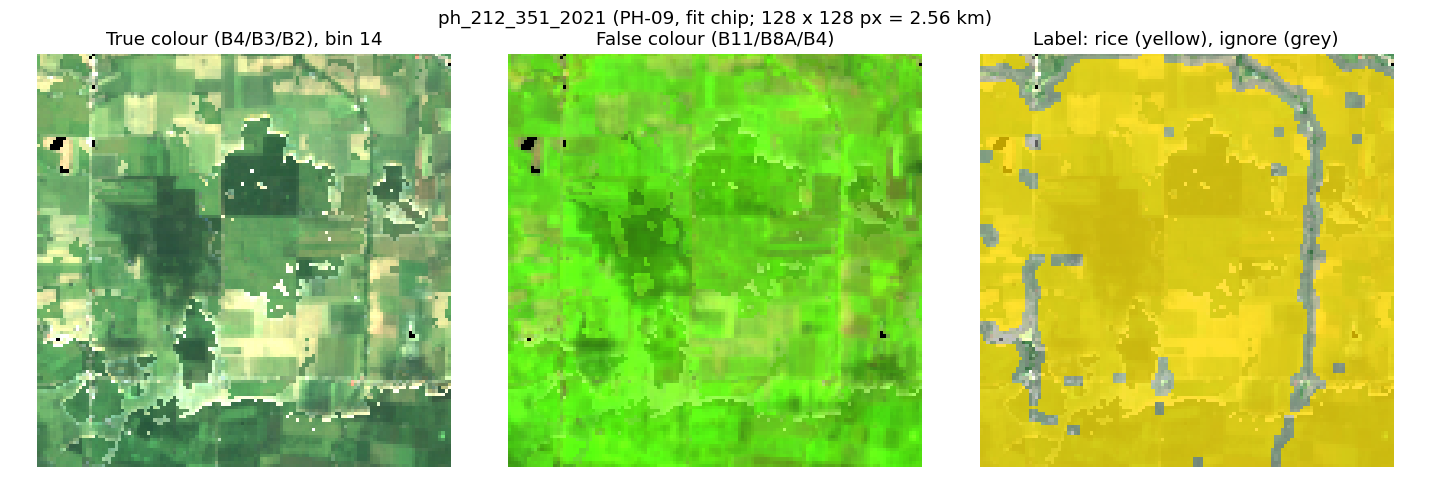

`overview_ndvi_series.png`

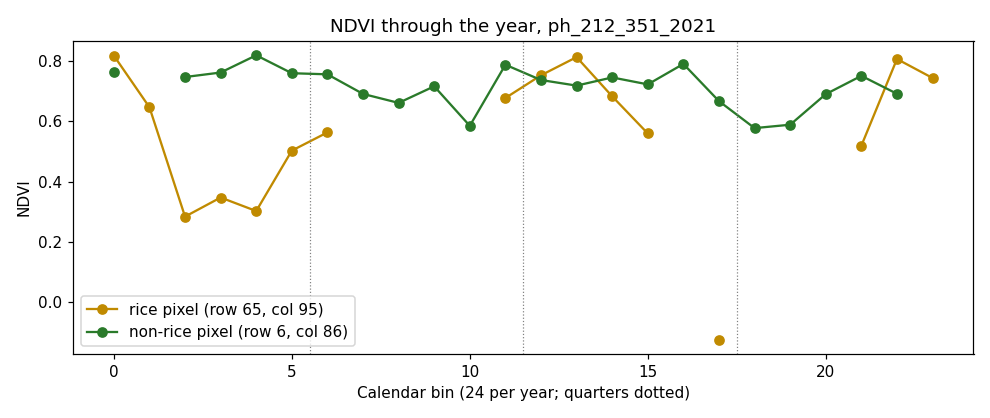

`overview_valid_by_bin.png`

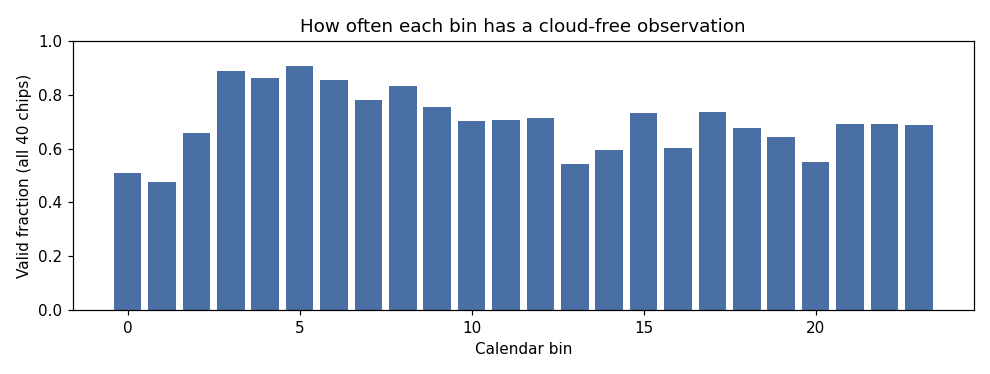

In [4]:
run_stage('prepare')
show_record('prepare.json')
show_figures('overview_*')

**What to notice:** the table lists every chip with its role, the four bins chosen as Prithvi's frames, the lowest valid fraction among them, and the share of model input that had to be filled. The three refusal probes show that a malformed chip is stopped with a message naming the broken rule, before any model runs. In the NDVI figure, look for the dips and rises of the rice pixel against the flatter non-rice pixel; in the valid-fraction bar chart, find the bins where clouds removed most observations.

**Checkpoint:** name one month range with frequent gaps, one feature of the rice NDVI curve, and one reason the label might disagree with what you see in the composite.

<details>
<summary>Check your reasoning (open after answering)</summary>

Gaps cluster in the wet season, when clouds are persistent; that is exactly when some rice is growing, so missing data and the signal you need overlap. Many Philippine rice areas are cropped twice a year, so the rice curve often shows two green-up peaks separated by low values at harvest and flooding; a forest or grass pixel stays high or changes slowly. The label can disagree because it comes from a published map with its own errors, because a 20 m pixel can mix a field edge with a road or levee (hence the ignored edge band), and because the composite you see is one bin, not the whole year.

</details>

## 3. Predict, declare the protocol and run the baselines · [Evaluation practice]

**Predict first:** where do you expect a pretrained model and a hand-built baseline to disagree — field edges, cloudy chips, small fields, wet but non-rice land? Write one guess.

**Roles.** The 32 training chips are split by **whole region** into **fit** (trains models) and **development** (makes every choice) with a declared, seeded rule: regions are ordered by a SHA-256 hash and added to development until it holds about 25 % of chips with at least two rice chips. Whole regions keep neighbouring chips out of both roles, because nearby pixels and chips are not independent [5]. The 8 **validation** chips are scored once, after every choice is frozen. The development example is never used.

**Frozen rules (written to `selection.json`).**
- A threshold is chosen on development from 0.10 to 0.90 in steps of 0.05 by the highest pooled development rice F1; ties go to the threshold closest to 0.5, then the lower one. A pixel is rice when its score is **≥** the threshold.
- Head C's training epoch is chosen on development; the activity in Section 6 runs on development only.
- Validation is scored once for A, B and C, and the result is kept even if a baseline wins.

**Systems.**
- **A — all non-rice:** predicts non-rice everywhere. Rice is a minority class, so A can score high accuracy while finding nothing.
- **B — spectral-temporal LightGBM:** the course study's M1 recipe — 70 features per pixel (per-band mean, spread, minimum, maximum and 10th/50th/90th percentiles over the observed year; quarterly band means; quarterly valid fractions) — on a class-stratified sample of at most 65,536 fit pixels, one fixed configuration (31 leaves), early stopping on development. Lesson [L3](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) [11] teaches this recipe.

**Metrics.** Counts are pooled over every pixel with `label ≠ 255`. Rice F1 is primary; IoU, precision and recall are reported beside it, and accuracy only to show why it misleads. For an imbalanced class, precision-based measures stay informative where accuracy does not [6]. A ratio with a zero denominator is reported as **undefined** with its reason, never as 0 or 1.

**Expected result:** B's threshold sweep on development and a two-row development table.

In [5]:
run_stage('baseline')
show_record('selection.json')
show_table('development_metrics.csv', ['system', 'threshold', 'f1', 'iou', 'precision', 'recall', 'accuracy', 'scored_pixels'])

Running baseline - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/baseline.log
{"stage": "baseline", "seconds": 250.29, "best_iteration": 187, "peak_gpu_gib": 0.0}
B: M1 spectral-temporal LightGBM | threshold 0.5 | development F1 0.8132


| Threshold | Dev F1 | Dev IoU | Dev precision | Dev recall |
|---|---|---|---|---|
| 0.1000 | 0.6813 | 0.5166 | 0.5222 | 0.9800 |
| 0.1500 | 0.7390 | 0.5860 | 0.5995 | 0.9630 |
| 0.2000 | 0.7728 | 0.6297 | 0.6536 | 0.9451 |
| 0.2500 | 0.7908 | 0.6540 | 0.6902 | 0.9258 |
| 0.3000 | 0.8021 | 0.6695 | 0.7190 | 0.9068 |
| 0.3500 | 0.8096 | 0.6801 | 0.7432 | 0.8891 |
| 0.4000 | 0.8125 | 0.6842 | 0.7636 | 0.8680 |
| 0.4500 | 0.8130 | 0.6850 | 0.7805 | 0.8484 |
| 0.5000 | 0.8132 | 0.6853 | 0.7987 | 0.8284 |
| 0.5500 | 0.8107 | 0.6816 | 0.8147 | 0.8067 |
| 0.6000 | 0.8063 | 0.6755 | 0.8280 | 0.7857 |
| 0.6500 | 0.8014 | 0.6686 | 0.8442 | 0.7627 |
| 0.7000 | 0.7925 | 0.6562 | 0.8576 | 0.7365 |
| 0.7500 | 0.7814 | 0.6412 | 0.8724 | 0.7075 |
| 0.8000 | 0.7632 | 0.6171 | 0.8871 | 0.6697 |
| 0.8500 | 0.7361 | 0.5824 | 0.9005 | 0.6225 |
| 0.9000 | 0.6883 | 0.5247 | 0.9179 | 0.5505 |

| system | threshold | f1 | iou | precision | recall | accuracy | scored_pixels |
|---|---|---|---|---|---|---|---|
| A all-non-rice | undefined | 0.0000 | 0.0000 | undefined | 0.0000 | 0.9203 | 119885 |
| B LightGBM | 0.5000 | 0.8132 | 0.6853 | 0.7987 | 0.8284 | 0.9697 | 119885 |

undefined -> A all-non-rice: precision: no pixel predicted rice


**What to notice:** A's accuracy equals the share of non-rice pixels, while its recall and F1 are 0 and its precision is undefined (it never predicts rice). Read B's sweep around the selected threshold: a broad plateau means the choice is not fragile.

<details>
<summary>Check your reasoning (open after answering)</summary>

If about nine in ten development pixels are non-rice, A scores about 0.9 accuracy without finding a single paddy — which is why the comparison is read in F1 and IoU. B's threshold is a real choice made on development only; its development F1 is therefore optimistic for B and is not a held-out score. The threshold is now frozen.

</details>

## 4. Trace how Prithvi's input is built and extract frozen features · [Concept]

**Input:** each chip's 24 bins. **Model:** Prithvi-EO-2.0-300M, a vision transformer pretrained by masked reconstruction of multispectral, multitemporal imagery [3], loaded from an immutable revision of its model card [10]. **Output:** for every chip, an 8 × 8 grid of 1024-number features from encoder block 12.

How the input is built, and what each step costs:

1. **Four frames.** The model was pretrained on four time steps. We take the clearest bin of each calendar quarter — highest valid fraction, earliest bin on ties — and record the chosen bins and their valid fractions (Section 2 table).
2. **Normalisation.** Reflectance × 10,000, then subtract and divide by the model's pinned band means and standard deviations. This is the repository's audited preprocessing, not a new recipe.
3. **Gaps.** After standardisation every missing value is set to 0, which is the pretraining mean. The filled share is recorded per chip and per frame. Pixels with no observation in any chosen frame stay in the scoring, as in the course study.
4. **No resizing.** Prithvi was pretrained on 30 m Harmonized Landsat–Sentinel (HLS) data; these chips are 20 m Sentinel-2 surface reflectance. We do not resample to 30 m to hide the mismatch: the model sees finer pixels than it was trained on, and the processing level is close to, but not the same as, HLS. Both are stated limitations.
5. **Patches.** Each 16 × 16 pixel patch — **320 m** at 20 m — becomes one token. A 128-pixel chip gives 8 × 8 patches per frame. Block 12 of 24 is fixed in advance (the repository's validated `FEATURE_LAYER`); there is no layer sweep. Tokens are averaged over the four frames.

Steps 1–3 are the functions `select_frames` and `prithvi_input` in `capstone.py`, which the second Infrastructure cell (*write and verify the embedded source*) writes to the run directory printed in Section 1; open it from the file browser under `outputs/philippines_rice/`. Reading them is optional; the steps above describe what they do.

The upstream checkpoint is a pickle. Its imported globals are audited statically against a pinned digest, it is unpickled once with torch's `weights_only` loader and converted to safetensors, and the model is loaded strictly from the verified file. No downloaded model code is executed. Features are computed once in float32 with deterministic GPU settings and cached, so later stages train on the cache.

**Predict before running:** how many patch tokens does the encoder return for one chip with four frames? (Hint: one extra summary token is added.)

In [6]:
run_stage('features')
show_record('model.json')
show_record('features.json')

Running features - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/features.log
/content/outputs/philippines_rice/040eb744c708/env/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
{"stage": "features", "seconds": 83.51, "peak_gpu_gib": 1.306}


| Record | Value |
|---|---|
| converted_sha256 | 15b8ed6dacf8b3ca02c542bb8eaffc92c7a7addc5351b3d967873ad3f73a24b0 |
| device | cuda |
| feature_layer_zero_based | 11 |
| model_id | ibm-nasa-geospatial/Prithvi-EO-2.0-300M |
| parameters | 330419712 |
| pickle_audit_sha256 | e7b998d087a5dcadd37713daf30b63cc571160c3180ebc138500ab662197e932 |
| revision | 9eb1b1102806593963daa333bcc491b1c6f8562f |
| source | converted from the manifest-verified source checkpoint |
| source_checkpoint_sha256 | faab2c8b776f0723f93431747603a7ec586a54fc45473613b4322c29752486e7 |
| strict_load | true |

| Record | Value |
|---|---|
| chips_t1_per_quarter | 32 |
| chips_t4 | 40 |
| feature | block 12 (zero-based 11) patch tokens, temporal mean, grid 8 x 8 x 1024 per 128 px chip |
| gpu | Tesla T4 |
| peak_gpu_gib | 1.3060 |
| precision | float32, inference mode, deterministic cuDNN |
| seconds | 11.8000 |
| torch | 2.14.0+cu130 |

**What to notice:** the model record shows the pinned revision, the audit and conversion (or that a verified file was reused), the parameter count and a strict load. The feature record shows grid shapes of 1024 × 8 × 8, the time taken and the peak GPU memory measured in this run.

<details>
<summary>Check your reasoning (open after answering)</summary>

Four frames × 8 × 8 patches = 256 patch tokens, plus one class token = 257; the stage refuses to continue if the count differs. Each token summarises a 320 m square, so the features cannot resolve a 40 m field boundary by themselves: whatever head we train will start from a coarse grid.

</details>

## 5. Train head C on the fit chips · [Concept]

**System C:** the frozen block-12 features → a 1 × 1 convolution from 1024 to 256 channels → GELU → a 1 × 1 convolution to 2 classes → bilinear upsampling from 8 × 8 to 128 × 128 pixels. Loss: cross-entropy with label 255 ignored, no class weights. Fixed in advance: AdamW, learning rate 0.001, weight decay 0.01, batch 8, at most 30 epochs, seed 0, no augmentation. The epoch with the highest development rice F1 at 0.5 is kept (earliest on ties), then C's threshold is chosen on development with the same rule as B. Training runs on the cached features, so it takes seconds. The head is `_head_module` and the training loop `train_head` in the same `capstone.py`.

**Predict before running:** will the development loss keep falling for 30 epochs? Will C's development F1 beat B's?

Running train-head - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/train-head.log
/content/outputs/philippines_rice/040eb744c708/capstone.py:1140: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  losses.append(float(loss))
epoch  1  fit loss 0.5022  dev loss 0.1974  dev F1@0.5 0.0
epoch  2  fit loss 0.3744  dev loss 0.2619  dev F1@0.5 0.6703456536618754
epoch  3  fit loss 0.2314  dev loss 0.2073  dev F1@0.5 0.6577116038193882
epoch  4  fit loss 0.1689  dev loss 0.1481  dev F1@0.5 0.7035124447545941
epoch  5  fit loss 0.1479  dev loss 0.1348  dev F1@0.5 0.709873417721519
epoch  6  fit loss 0.1312  dev loss 0.1593  dev F1@0.5 0.6742871189773845
epoch  7  fit loss 0.1183  dev loss 0.1478  dev F1@0.5 0.6885371132708059
epoch  8  fit loss 0.1112  dev loss 0.1199 

`head_training_curves.png`

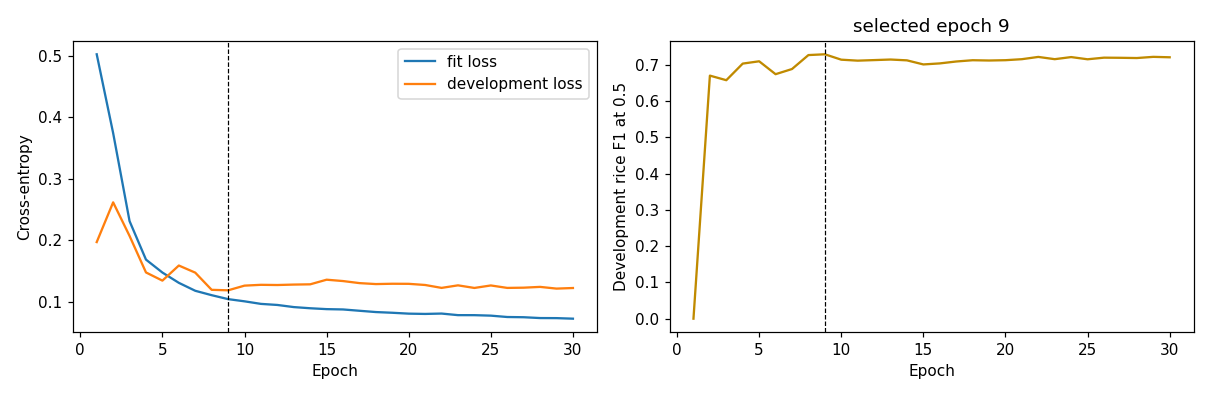

B: M1 spectral-temporal LightGBM | threshold 0.5 | development F1 0.8132
C: frozen Prithvi-EO-2.0 block 12 + 1x1-conv head | threshold 0.7 | development F1 0.7665 | epoch 9


| Threshold | Dev F1 | Dev IoU | Dev precision | Dev recall |
|---|---|---|---|---|
| 0.1000 | 0.5724 | 0.4010 | 0.4162 | 0.9164 |
| 0.1500 | 0.6097 | 0.4385 | 0.4616 | 0.8976 |
| 0.2000 | 0.6391 | 0.4696 | 0.5011 | 0.8818 |
| 0.2500 | 0.6609 | 0.4936 | 0.5340 | 0.8670 |
| 0.3000 | 0.6763 | 0.5109 | 0.5605 | 0.8522 |
| 0.3500 | 0.6891 | 0.5257 | 0.5862 | 0.8359 |
| 0.4000 | 0.7030 | 0.5421 | 0.6120 | 0.8260 |
| 0.4500 | 0.7165 | 0.5582 | 0.6379 | 0.8172 |
| 0.5000 | 0.7292 | 0.5738 | 0.6643 | 0.8081 |
| 0.5500 | 0.7426 | 0.5905 | 0.6944 | 0.7979 |
| 0.6000 | 0.7524 | 0.6031 | 0.7232 | 0.7842 |
| 0.6500 | 0.7638 | 0.6179 | 0.7580 | 0.7697 |
| 0.7000 | 0.7665 | 0.6214 | 0.7861 | 0.7478 |
| 0.7500 | 0.7624 | 0.6161 | 0.8105 | 0.7198 |
| 0.8000 | 0.7519 | 0.6025 | 0.8364 | 0.6830 |
| 0.8500 | 0.7208 | 0.5635 | 0.8613 | 0.6198 |
| 0.9000 | 0.6451 | 0.4761 | 0.8794 | 0.5094 |

| system | threshold | f1 | iou | precision | recall | accuracy |
|---|---|---|---|---|---|---|
| A all-non-rice | undefined | 0.0000 | 0.0000 | undefined | 0.0000 | 0.9203 |
| B LightGBM | 0.5000 | 0.8132 | 0.6853 | 0.7987 | 0.8284 | 0.9697 |
| C frozen Prithvi + head | 0.7000 | 0.7665 | 0.6214 | 0.7861 | 0.7478 | 0.9637 |

undefined -> A all-non-rice: precision: no pixel predicted rice


In [7]:
run_stage('train-head')
show_figures('head_training_curves*')
show_record('selection.json')
show_table('development_metrics.csv', ['system', 'threshold', 'f1', 'iou', 'precision', 'recall', 'accuracy'])

**What to notice:** fit loss usually keeps falling while development loss flattens or rises; the dashed line marks the kept epoch. The development table now has three rows. All three were selected on these development chips, so this table is for choosing, not for claiming.

<details>
<summary>Check your reasoning (open after answering)</summary>

With 24 fit chips the head can memorise the fit set; the development curve is what tells you when that starts. If C's development F1 is below B's, that is a legitimate result: B sees all 24 bins at every pixel, while C sees four frames through 320 m patches. If C wins on development, the margin may still shrink on validation, because development informed C's epoch and threshold.

</details>

## 6. Change one thing: one frame versus four · [Evaluation practice]

**Predict → Change one thing → Run → Observe → Explain.** Keep the frozen Prithvi weights, the head's recipe (architecture, optimiser, seed), the epoch count (C's selected epoch) and the threshold fixed, and train one head per frame count with that recipe. Change only the number of frames: **T = 1** — only one quarter's clearest frame, tried for each of the four quarters — versus the canonical **T = 4**. Everything is scored on development chips only; validation is untouched.

**Predict before running:** which single quarter will work best? How far below T = 4 will it fall?

This activity does **not** change the canonical system: validation uses T = 4, as declared before the activity.

Running activity - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/activity.log
/content/outputs/philippines_rice/040eb744c708/capstone.py:1140: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  losses.append(float(loss))
{"stage": "activity", "seconds": 11.42, "peak_gpu_gib": 0.0}


| variant | epochs | threshold | f1 | iou | precision | recall |
|---|---|---|---|---|---|---|
| T=4 (one frame per quarter) | 9 | 0.7000 | 0.7665 | 0.6214 | 0.7861 | 0.7478 |
| T=1 (quarter 1 only) | 9 | 0.7000 | 0.4849 | 0.3201 | 0.5851 | 0.4141 |
| T=1 (quarter 2 only) | 9 | 0.7000 | 0.6789 | 0.5139 | 0.7026 | 0.6568 |
| T=1 (quarter 3 only) | 9 | 0.7000 | 0.6201 | 0.4493 | 0.7636 | 0.5219 |
| T=1 (quarter 4 only) | 9 | 0.7000 | 0.6722 | 0.5063 | 0.7076 | 0.6402 |

`activity_frames.png`

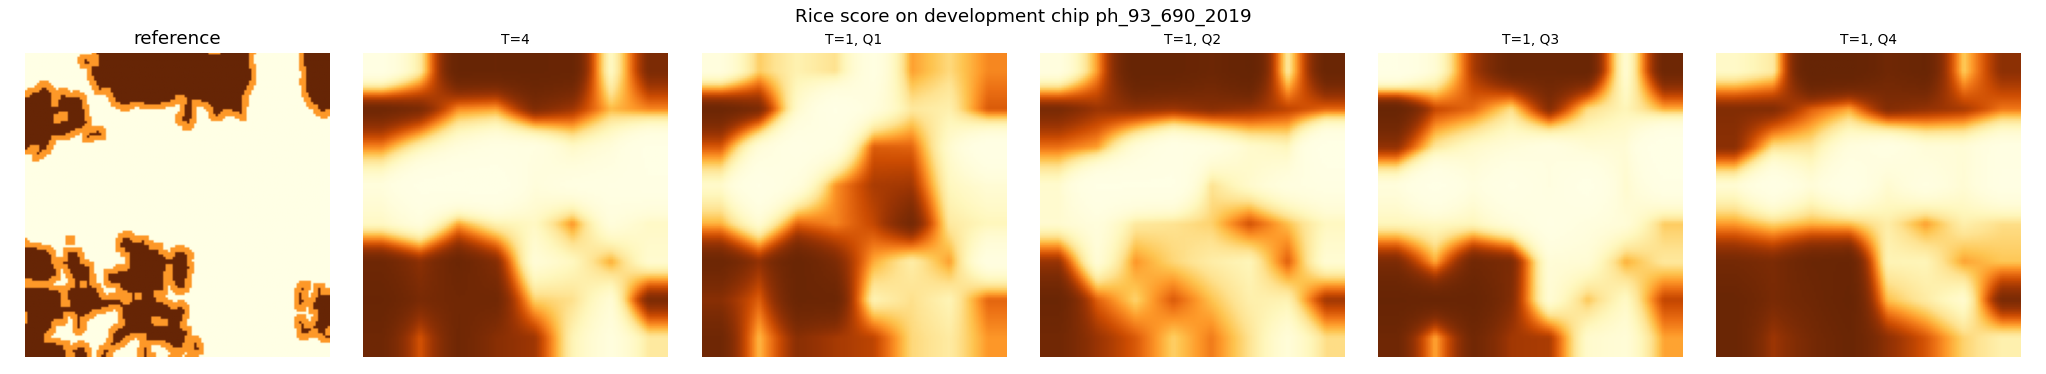

In [8]:
run_stage('activity')
show_table('activity.csv', ['variant', 'epochs', 'threshold', 'f1', 'iou', 'precision', 'recall'])
show_figures('activity_*')

**Observe and explain:** compare the best single quarter with T = 4. The T = 4 row reproduces C's development result exactly (same recipe, seed and epochs), which shows the procedure is unchanged; each T = 1 row is a head trained with the same recipe on one-frame features, so the comparison asks how much information one frame carries, not how C copes with fewer frames. One caveat: the epoch count and threshold were chosen for T = 4 on the same development chips and the T = 1 heads borrow them, so T = 4 has a head start; part of the gap comes from that tuning, and the direction of the result is more robust than its size.

<details>
<summary>Check your reasoning (open after answering)</summary>

Usually T = 4 beats every single quarter, and the best quarter is one that catches flooding or peak green-up. That supports the season-based explanation: rice is identified by how a pixel changes, which one snapshot cannot show. If a single quarter matched T = 4 here, the honest reading is that on these eight development chips one well-timed image carried most of the signal — not that time never matters, because eight chips from four regions are a small sample.

</details>

## 7. Optional extension: fine-tune the encoder (C-FT) · [Evaluation practice]

Switched off by default. When `RUN_FINETUNE` is ticked, a separate system **C-FT** unfreezes the patch embedding, the CLS token and encoder blocks 1–12 (the blocks that feed block 12; blocks 13–24 and the decoder stay frozen) and trains them with a fresh head under the same fit/development protocol: AdamW (encoder 0.00001, head 0.001), batch 4, 10 epochs fixed in advance, fp16 mixed precision, epoch and threshold chosen on development. Its validation predictions are computed without labels at the selected epoch and stay sealed; C-FT is scored in Section 8 only because it was selected **before** validation scoring. If you tick it after Section 8 has run, the stage refuses: a model chosen after seeing validation results would be exploratory. The run records its peak GPU memory with the full AdamW state. For scale (not re-run here): the recorded Colab CLI runs with the fine-tune switched on, of the earlier blobs `c1c966bb` (commit `d6956ab`) and `33037307` (commit `d82963c`) on a Tesla T4 on 2026-10-11, each measured a 4.404 GiB peak for this stage (see `docs/release-verification.md` in the host repository). The canonical comparison and the exported artifact remain the frozen-encoder system C.

To use it: tick the box, then Runtime → Run all on a fresh runtime.

**Expected result / What to notice:** a fine-tune curve with development loss and F1 per epoch and a record naming the selected epoch, threshold and peak GPU memory; in Section 8 a fourth validation row, C-FT. Fine-tuning far more parameters on 24 fit chips can overfit, so C-FT may score below C; that is a result, not an error. Some PyTorch operations it uses are non-deterministic, so its numbers can vary slightly between runs.

In [9]:
RUN_FINETUNE = False  # @param {type:"boolean"}
if RUN_FINETUNE:
    run_stage('finetune')
    show_table('finetune_curve.csv')
    show_record('finetune.json')
else:
    print('C-FT not run (RUN_FINETUNE = False); the canonical comparison is A, B and C.')

C-FT not run (RUN_FINETUNE = False); the canonical comparison is A, B and C.


## 8. Score A, B and C once on the validation chips · [Evaluation practice]

**Question tested:** with every choice frozen on development, how do the all-non-rice rule, B at its development threshold and C at its development threshold compare on the 8 validation chips from PH-07 and PH-08?

The stage first records the digest of `selection.json`, then scores. It refuses a second scoring in the same run directory, and the export stage refuses if the selection changed afterwards.

**Predict before running:** will the ranking on validation match development? Which validation chip will be hardest?

In [10]:
run_stage('evaluate')
show_table('metrics.csv', ['system', 'threshold', 'f1', 'iou', 'precision', 'recall', 'accuracy', 'tp', 'fp', 'fn', 'tn'])
show_table('per_chip_metrics.csv', ['chip', 'region', 'system', 'f1', 'iou', 'precision', 'recall', 'reference_rice_pixels'])

Running evaluate - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/evaluate.log
{"stage": "evaluate", "seconds": 66.16, "systems": ["A all-non-rice", "B LightGBM", "C frozen Prithvi + head"], "peak_gpu_gib": 0.0}


| system | threshold | f1 | iou | precision | recall | accuracy | tp | fp | fn | tn |
|---|---|---|---|---|---|---|---|---|---|---|
| A all-non-rice | undefined | 0.0000 | 0.0000 | undefined | 0.0000 | 0.8868 | 0 | 0 | 12889 | 100932 |
| B LightGBM | 0.5000 | 0.7579 | 0.6102 | 0.6793 | 0.8571 | 0.9380 | 11047 | 5215 | 1842 | 95717 |
| C frozen Prithvi + head | 0.7000 | 0.6014 | 0.4300 | 0.7716 | 0.4927 | 0.9260 | 6350 | 1880 | 6539 | 99052 |

undefined -> A all-non-rice: precision: no pixel predicted rice


| chip | region | system | f1 | iou | precision | recall | reference_rice_pixels |
|---|---|---|---|---|---|---|---|
| ph_240_427_2021 | PH-07 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 2112 |
| ph_242_425_2019 | PH-07 | A all-non-rice | undefined | undefined | undefined | undefined | 0 |
| ph_243_420_2021 | PH-07 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 1061 |
| ph_245_424_2019 | PH-07 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 677 |
| ph_251_427_2019 | PH-07 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 1980 |
| ph_273_485_2019 | PH-08 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 3121 |
| ph_278_478_2021 | PH-08 | A all-non-rice | 0.0000 | 0.0000 | undefined | 0.0000 | 3938 |
| ph_293_513_2020 | PH-08 | A all-non-rice | undefined | undefined | undefined | undefined | 0 |
| ph_240_427_2021 | PH-07 | B LightGBM | 0.6614 | 0.4941 | 0.5426 | 0.8466 | 2112 |
| ph_242_425_2019 | PH-07 | B LightGBM | undefined | undefined | undefined | undefined | 0 |
| ph_243_420_2021 | PH-07 | B LightGBM | 0.7521 | 0.6027 | 0.7080 | 0.8021 | 1061 |
| ph_245_424_2019 | PH-07 | B LightGBM | 0.5206 | 0.3519 | 0.4108 | 0.7105 | 677 |
| ph_251_427_2019 | PH-07 | B LightGBM | 0.6188 | 0.4480 | 0.4907 | 0.8374 | 1980 |
| ph_273_485_2019 | PH-08 | B LightGBM | 0.8883 | 0.7990 | 0.8703 | 0.9071 | 3121 |
| ph_278_478_2021 | PH-08 | B LightGBM | 0.8704 | 0.7705 | 0.8677 | 0.8730 | 3938 |
| ph_293_513_2020 | PH-08 | B LightGBM | undefined | undefined | undefined | undefined | 0 |
| ph_240_427_2021 | PH-07 | C frozen Prithvi + head | 0.3712 | 0.2279 | 0.6806 | 0.2552 | 2112 |
| ph_242_425_2019 | PH-07 | C frozen Prithvi + head | undefined | undefined | undefined | undefined | 0 |
| ph_243_420_2021 | PH-07 | C frozen Prithvi + head | 0.0000 | 0.0000 | undefined | 0.0000 | 1061 |
| ph_245_424_2019 | PH-07 | C frozen Prithvi + head | 0.5126 | 0.3446 | 0.4861 | 0.5421 | 677 |
| ph_251_427_2019 | PH-07 | C frozen Prithvi + head | 0.3359 | 0.2019 | 0.6279 | 0.2293 | 1980 |
| ph_273_485_2019 | PH-08 | C frozen Prithvi + head | 0.6806 | 0.5159 | 0.8068 | 0.5886 | 3121 |
| ph_278_478_2021 | PH-08 | C frozen Prithvi + head | 0.8275 | 0.7057 | 0.8561 | 0.8007 | 3938 |
| ph_293_513_2020 | PH-08 | C frozen Prithvi + head | undefined | undefined | undefined | undefined | 0 |

undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: f1: no reference rice and no predicted rice; iou: no reference rice and no predicted rice; precision: no pixel predicted rice; recall: no reference rice pixel
undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: precision: no pixel predicted rice
undefined -> A all-non-rice: f1: no reference rice and no predicted rice; iou: no reference rice and no predicted rice; precision: no pixel predicted rice; recall: no reference rice pixel
undefined -> B LightGBM: f1: no reference rice and no predicted rice; iou: no reference rice and no predicted rice; precision: no pixel predicted rice; recall: no reference rice pixel
undefined -> B LightGBM: f1: no reference rice and no pr

## 9. Interpret the result · [Evaluation practice]

**Pooled first.** The first table is the comparison: one pooled F1, IoU, precision and recall per system over the same labelled pixels. **Per chip second**, for diagnosis only. Two validation chips contain no reference rice: their recall is undefined, and their F1 is undefined if a system also predicts no rice there (or 0 if it predicts any). Undefined values are printed with their reason, never averaged in as numbers.

**What the evidence can bear.** Eight chips from two neighbouring regions, many of them close together. Pixels and chips are spatially dependent, so treating them as independent samples would overstate confidence [5], and spatially naive validation can make mapping models look far better than they are [7]. We therefore compute no significance tests and no confidence intervals, and make no national or operational claim. Labels are published map products, so disagreement is not proof of model error. Whether Prithvi's pretraining imagery included these places is unknown.

**For reference only (not re-run here):** on the same 8 validation chips, the course lessons report teaching-scale F1 of **0.760** for Sentinel-2 LightGBM ([Lesson 3](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) [11], Kaggle version 4, notebook code SHA-256 `c30514a4…`) and **0.928** for AlphaEarth LightGBM ([Lesson 3B](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline) [12], Kaggle version 3, notebook code SHA-256 `e98f6a57…`). Those are lesson results with their own caveats — in particular, they chose their threshold on these same validation chips, so they are development scores, not held-out ones. AlphaEarth annual embeddings [8] combine several sensors and had crop-related supervision; they are not used by A, B or C.

The next cell shows the error maps for every validation chip (TP, FP, FN, TN; ignored pixels grey), where B and C disagree, and the 320 m patch effect on the chip with the most rice.

`validation_error_maps.png`

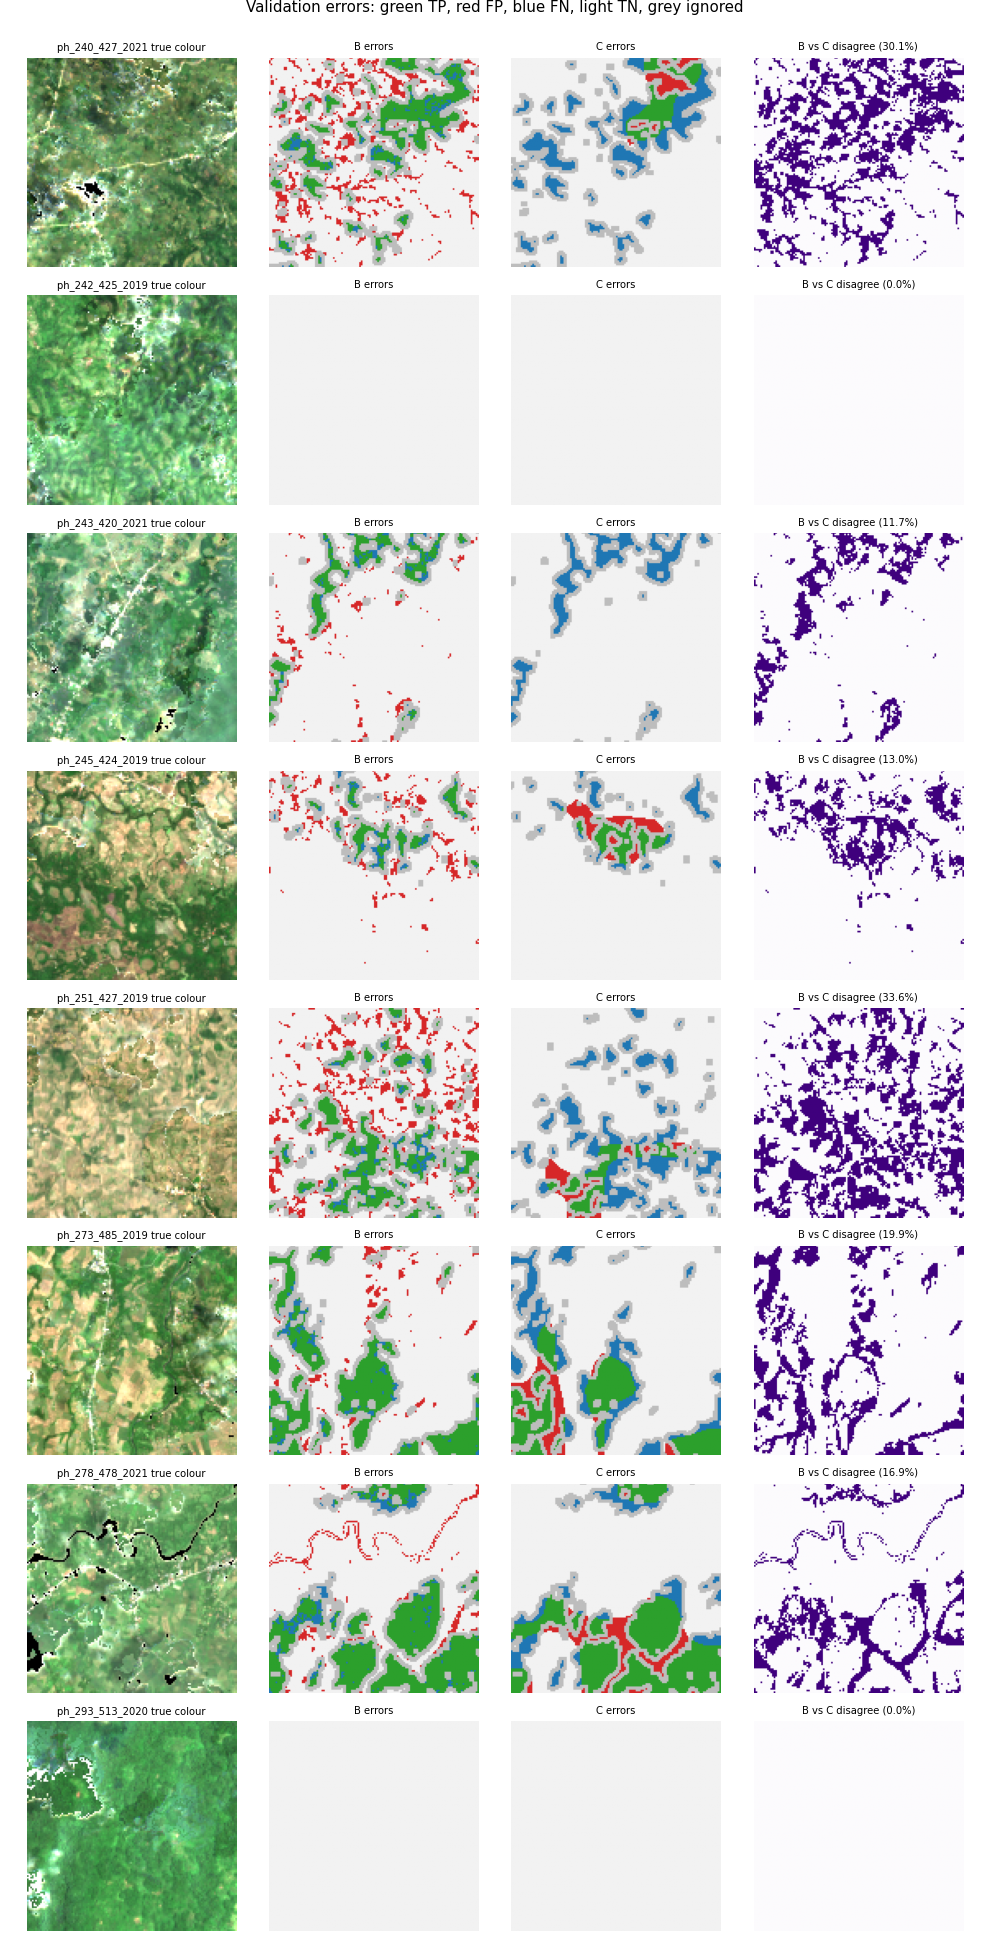

`validation_patch_effect.png`

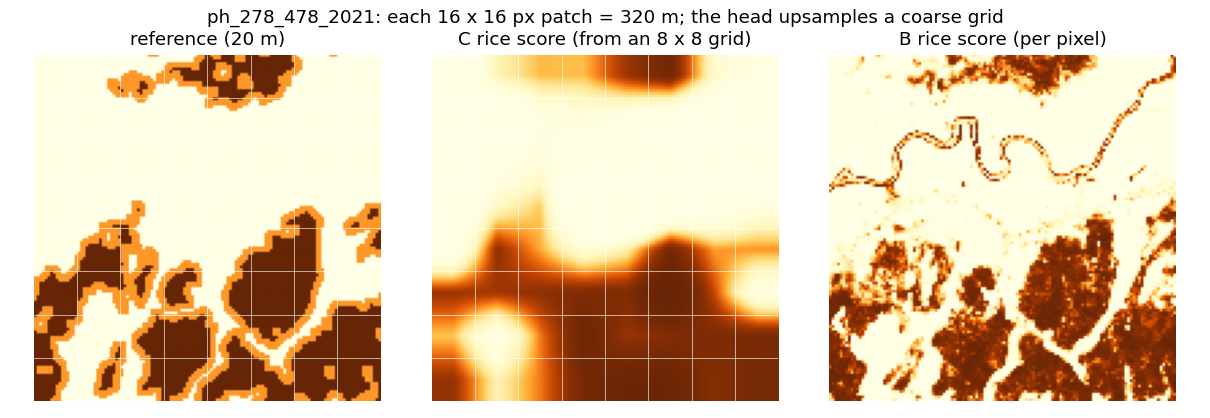

In [11]:
show_figures('validation_*')

**Interpret:** pick one chip where B and C disagree. Is the disagreement along field edges, in whole fields, or near cloud-filled areas? In the patch figure, can you see C's 16-pixel blocks? Weigh model error, label error and the 320 m grid as competing explanations.

<details>
<summary>Check your reasoning (open after answering)</summary>

Read the maps rather than assuming a pattern. Two things to look for: C decides from 320 m patches that are then smoothed, so check whether its misses are whole fields (low recall) or edges; B decides per 20 m pixel without spatial context, so check whether its errors are speckled. Compare the pooled F1 gap with the per-chip table: if the gap comes from one or two chips, a different chip selection could change it; if most chips agree, it is more robust, though eight clustered chips from two regions still cannot establish a national ranking. The defensible sentence names the chips, the systems and the numbers, then says what the sample cannot establish. If B beats C, report it: the hand-built baseline is a real competitor, and a foundation model is not required to win.

</details>

## 10. Export, reload in a fresh process and verify · [Engineering]

**Exported artifact:** `head_adapter/` — `adapter.safetensors` (the head's four tensors only; no base weights, no training data) and `manifest.json` (format, base model revision and converted-weights digest, feature block, frame rule, normalisation, threshold, training configuration, selection basis, file sizes and SHA-256). A consumer needs the base model at the recorded revision plus this folder.

**Fresh reload:** a new process verifies the artifact's digests, rebuilds the base model strictly from verified files, recomputes the validation chips' features from the HDF5 files, and compares the reloaded head's scores with the evaluation's scores (tolerance 0.0001) and decisions (must be identical). It reopens the prediction GeoTIFFs (EPSG:32651, 20 m) and recomputes the metrics from them.

**Prediction files, per validation chip:** `<chip>_C.tif` is the scored map (0 non-rice, 1 rice, 255 where the reference label is ignored, so it reproduces the evaluation); `<chip>_C_all_pixels.tif` gives C's decision for every pixel; `<chip>_C_score.tif` holds C's rice score in [0, 1] as float32, so you can apply a different threshold. The reload checks all three against the evaluation's scores. Passing shows the saved computation is reproducible from files; it does not show the model or the labels are right.

**Expected result:** a verification table whose checks are all true, a download link for `results.zip` (records, tables, figures, GeoTIFFs, the adapter, attribution and `checksums.json`; no source imagery or base weights), and then **this run's answer** to the driving question — the validation metrics, whether C scored above B, and the evidence level — followed by a conclusion scaffold.

In [12]:
run_stage('export')
run_stage('reload')
run_stage('report')
show_record('verification.json')
display(FileLink(str(ROOT / 'outputs' / 'results.zip')))
display(Markdown((ROOT / 'outputs' / 'conclusion.md').read_text(encoding='utf-8')))

Running export - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/export.log
{"stage": "export", "seconds": 1.01, "geotiffs": 24, "peak_gpu_gib": 0.0}
Running reload - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/reload.log
/content/outputs/philippines_rice/040eb744c708/env/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
{"stage": "reload", "seconds": 26.37, "peak_gpu_gib": 1.306}
Running report - one process per stage; log: /content/outputs/philippines_rice/040eb744c708/report.log
{"stage": "report", "seconds": 0.47, "zip_members": 49, "peak_gpu_gib": 0.0}


| Record | Value |
|---|---|
| artifact_digests_verified | true |
| base_model_strict_load | true |
| binary_decisions_identical | true |
| geotiffs_match_and_georeferenced | true |
| max_abs_score_difference | 0.0000 |
| meaning | the saved computation is reproducible from files in a fresh process; not evidence of accuracy |
| metrics_recomputed_from_geotiffs | true |
| results_zip: members | 49 |
| results_zip: verified | true |
| score_and_all_pixel_geotiffs_match | true |
| tolerance | 0.0001 |

/content/outputs/philippines_rice/040eb744c708/outputs/results.zip

# This run's answer

Validation metrics (8 chips, PH-07/PH-08, pooled over labelled pixels):

- A all-non-rice: F1 0.000, IoU 0.000, precision undefined, recall 0.000
- B LightGBM: F1 0.758, IoU 0.610, precision 0.679, recall 0.857
- C frozen Prithvi + head: F1 0.601, IoU 0.430, precision 0.772, recall 0.493

**Answer to the driving question, from this run:** on the labelled pixels of these 8 validation chips, the head on frozen Prithvi-EO-2.0 features (C, F1 0.601) did not map rice better than the spectral-temporal LightGBM baseline (B, F1 0.758); calling everything non-rice (A) scored F1 0.000.

**Evidence level:** tutorial evidence from one run at teaching scale: 8 validation chips from two neighbouring regions, scored once after every choice was frozen on development chips; map-derived labels; no confidence intervals. It does not establish which approach is better nationally or operationally.

# Conclusion scaffold

Complete in your own words:

> On the labelled pixels of eight validation chips from two regions, [system] reached a pooled rice F1 of [value] against [baselines]. On the development chips, [T=1 vs T=4 result]. The error maps show [pattern], and the 320 m patch grid [effect]. Labels are published map products, the sample is small and spatially clustered, and Prithvi's pretraining overlap with these places is unknown, so [bounded claim]. Next we would [specific evidence].


## 11. Conclude with evidence · [Evaluation practice]

The output above ends with **This run's answer**, written from the validation table the run just produced: it states whichever result occurred, with its evidence level. Read it, then complete the conclusion scaffold that follows it in your own words. A strong conclusion states the task and pixel population, reports every system on the same pixels — including a baseline that may have won — names the frame activity's result, uses the error maps to say *where* systems differ, and states the limits: eight validation chips from two regions, spatial clustering, map-derived labels, the 20 m versus 30 m mismatch, the 320 m patch grid and unknown pretraining overlap.

<details>
<summary>Check your reasoning: what makes a conclusion strong? (open after writing yours)</summary>

Strong: "On the labelled pixels of eight validation chips in Central and Eastern Visayas, the frozen-Prithvi head reached pooled rice F1 *x* against *y* for the LightGBM baseline and 0 for all-non-rice; on development, four frames beat the best single quarter by *z*, consistent with rice being a seasonal signal. The error maps show [where C and B differ: whole fields, edges or cloud-filled areas]. With eight clustered chips and map-derived labels, this does not establish which approach is better nationally; next we would score a larger, spatially separated test set." Weak: "Prithvi is better at mapping rice" from one pooled number.

</details>

**Transfer:** Lessons [L3](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) [11] and [L3B](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline) [12] show the feature-engineering and embedding routes in depth; Section 12 lets you score your own chips with the exported head and, with enough labelled sites, adapt a new head under the same protocol.

## 12. Optional: bring your own chips · [Engineering]

Switched off by default, so Run all never waits for an upload. After Run all has finished:

1. Tick `USE_BYOD`.
2. Either set `BYOD_PATH` to a folder or `.zip` already in this runtime, or leave it empty to get an upload dialog (Colab).
3. Run this cell (the code cell below). You do not need to Run all again: it uses the head exported earlier in this session. If the runtime has restarted since then, Run all first.

**Required format — this dataset's own schema (checked before any model runs):**

| Key | Contract |
|---|---|
| `S2` | float32 `[24, 6, 128, 128]`: 24 equal calendar bins × bands B2, B3, B4, B8A, B11, B12 in that order; surface reflectance (digital number × 0.0001); NaN allowed where `S2_valid` = 0 |
| `S2_valid` | 0/1 `[24, 128, 128]` |
| `label` | uint8 `[128, 128]`: 0 non-rice, 1 rice, 255 ignore — needed for scoring and adaptation; optional for prediction only |
| attributes (optional) | Location, either this dataset's `affine` (JSON `[a, b, c, d, e, f]`) with `crs` = `EPSG:32651`, used only for a 20 m north-up grid, or plain `x_min`, `y_max` (EPSG:32651 metres, upper-left corner); a chip without a usable location is still scored, its GeoTIFF has no location and the notebook says so. Site: `group_id` or `group` (default: the file name without a trailing `_YYYY`) |

One `.h5` file per chip-year with a unique file name, at most 200 files and 4 GiB in total; a `.zip` with an absolute or `..` member is refused. Values above 2.0 mean the file stores reflectance × 10,000; it is refused, not rescaled. Other keys (AlphaEarth, `label_raw`) are ignored.

**What happens:** every file is validated with the same rules as the sample data (a failure names the file and the broken rule); every chip is scored with the exported head at its frozen threshold (GeoTIFFs and, if labelled, per-chip metrics). With at least 6 labelled chips from at least three sites, the notebook also adapts a new head under the same protocol: sites are split into fit, development and test by a declared hash rule, the epoch and threshold are chosen on development, the test sites are scored against the all-non-rice baseline, and the adapted head is exported and reloaded from files.

**Expected result / What to notice:** a per-chip table (bins, filled share, predicted rice share, whether the GeoTIFF is georeferenced and, for labelled chips, the scores) and a summary; with enough labelled sites, the adapted head's test result beside the all-non-rice baseline and the exported canonical head on the same test sites, so you can see whether adapting helped; and a download link for `byod_results.zip`. A refused file names the file and the broken rule.

**Privacy:** your files stay in this runtime; nothing is sent to any other service. Do not upload confidential, restricted, licensed or personal data unless you are authorised to process it in Google Colab.

In [13]:
USE_BYOD = False  # @param {type:"boolean"}
BYOD_PATH = ''  # @param {type:"string"}
if USE_BYOD:
    sources = [Path(BYOD_PATH)] if BYOD_PATH else []
    if not sources:
        from google.colab import files  # only on Colab, only after the sample path has completed
        sources = [Path(name).resolve() for name in files.upload()]
    # The stage empties its input folder and its outputs first, refuses unsafe archives and duplicate file names,
    # validates every chip, then scores, adapts, exports and bundles byod_results.zip.
    run_stage('byod', '--input', *[str(source) for source in sources])
    show_table('byod/byod_canonical_head.csv')
    print(json.dumps(json.loads((ROOT / 'outputs' / 'byod' / 'byod_summary.json').read_text()), indent=1)[:4000])
    display(FileLink(str(ROOT / 'outputs' / 'byod_results.zip')))
else:
    print('BYOD not run (USE_BYOD = False).')

BYOD not run (USE_BYOD = False).


## Troubleshooting

| Observation | Appropriate response |
|---|---|
| "Select a fresh T4 GPU runtime" or CUDA not detected | Runtime → Change runtime type → T4 GPU, then Runtime → Run all. |
| "Supported runtime: Google Colab (Linux x86_64)" | The lock is built for manylinux x86_64; use Colab (or another Linux x86_64 GPU runtime). |
| Download, size or SHA-256 mismatch (uv, packages, model, INDEX, chips) | Re-run once for a transient network error. A persistent mismatch means a pinned source changed: stop and report it; do not remove the check. |
| Kaggle download fails | The dataset is public and needs no account; retry once. If Kaggle is unreachable, the notebook cannot run. |
| Out of disk | Start a fresh runtime with at least 12 GiB free. |
| GPU out of memory | Use a fresh T4 runtime; do not run the optional fine-tune with a larger batch. Never record a skipped stage as a success. |
| "run the earlier stages in order" | A stage's inputs are missing: Runtime → Run all from the top. |
| "validation was already scored" / fine-tune refuses | Scoring happens once per run directory. Start a fresh runtime to change a development choice. |
| B beats C, or C beats B | Preserve the result and examine the error maps; either outcome is valid. |
| Reload parity fails | Preserve `verification.json` and the logs; the release cannot be qualified until the mismatch is explained. |
| BYOD file refused | Read the message: it names the key, shape, dtype, value range or label rule that failed. Fix the file and retry. |

## Data, model, attribution and licences

**Data:** `kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching`, version 1 (public, CC BY 4.0; later versions change only the card and rights wording, with identical data files), verified by `INDEX.jsonl` SHA-256 `e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d` and every chip's SHA-256. Component attribution, from the dataset's rights file:

- **Rice labels:** Chen et al., *20 m resolution maps of paddy rice cropping intensity and planting dates in Monsoon Asia from 2018 to 2021* [4], https://doi.org/10.5281/zenodo.15124936, CC BY 4.0 — reprojected, converted to binary and given an ignored edge band.
- **Optical inputs:** Contains modified Copernicus Sentinel data 2019–2021 (cloud/quality masking, six-band selection, 20 m resampling, 24 annual median bins), under the Copernicus Sentinel data terms.
- **AlphaEarth Foundations Satellite Embedding** (Google and Google DeepMind) [8], CC BY 4.0 — present in the dataset files; not read or shown by this notebook.
- **Regional boundaries:** geoBoundaries PHL ADM1 (2020 vintage; NAMRIA/PSA/OCHA), CC BY 3.0 IGO.
- **Dataset compilation:** Kurt Valcorza, CC BY 4.0. Component terms continue to apply.

**Model:** `ibm-nasa-geospatial/Prithvi-EO-2.0-300M` at revision `9eb1b1102806593963daa333bcc491b1c6f8562f` (checkpoint SHA-256 `faab2c8b776f0723f93431747603a7ec586a54fc45473613b4322c29752486e7`), Apache-2.0 [3], [10]. The carried repository code is Apache-2.0. The exported head contains no base weights and no training data.

**AI Assistance Disclosure:** Generative AI assisted this notebook's code and technical writing under maintainer direction, including checking scholarly references through the Scite literature service. The maintainer remains responsible for reviewing the implementation, validating results and making release decisions. AI assistance is not independent verification, provider endorsement or release approval.

## References

[1] X. Xiao et al., "Mapping paddy rice agriculture in southern China using multi-temporal MODIS images," *Remote Sens. Environ.*, vol. 95, no. 4, pp. 480–492, 2005, doi: 10.1016/j.rse.2004.12.009. [Online]. Available: https://doi.org/10.1016/j.rse.2004.12.009

[2] M. Drusch et al., "Sentinel-2: ESA's optical high-resolution mission for GMES operational services," *Remote Sens. Environ.*, vol. 120, pp. 25–36, 2012, doi: 10.1016/j.rse.2011.11.026. [Online]. Available: https://doi.org/10.1016/j.rse.2011.11.026

[3] D. Szwarcman et al., "Prithvi-EO-2.0: A versatile multitemporal foundation model for Earth observation applications," *IEEE Trans. Geosci. Remote Sens.*, vol. 64, pp. 1–20, 2026, doi: 10.1109/TGRS.2025.3642610. [Online]. Available: https://doi.org/10.1109/TGRS.2025.3642610

[4] Y. Chen, S. Liang, W. Li, H. Ma, H. Fang, and J. Xu, "20 m resolution maps of paddy rice cropping intensity and planting dates in Monsoon Asia from 2018 to 2021," Zenodo, 2025, data set, doi: 10.5281/zenodo.15124936. [Online]. Available: https://doi.org/10.5281/zenodo.15124936

[5] D. R. Roberts et al., "Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure," *Ecography*, vol. 40, no. 8, pp. 913–929, 2017, doi: 10.1111/ecog.02881. [Online]. Available: https://doi.org/10.1111/ecog.02881

[6] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," *PLOS ONE*, vol. 10, no. 3, Art. no. e0118432, 2015, doi: 10.1371/journal.pone.0118432. [Online]. Available: https://doi.org/10.1371/journal.pone.0118432

[7] P. Ploton et al., "Spatial validation reveals poor predictive performance of large-scale ecological mapping models," *Nature Commun.*, vol. 11, no. 1, 2020, doi: 10.1038/s41467-020-18321-y. [Online]. Available: https://doi.org/10.1038/s41467-020-18321-y

[8] C. F. Brown et al., "AlphaEarth Foundations: An embedding field model for accurate and efficient global mapping from sparse label data," 2025, arXiv:2507.22291, doi: 10.48550/arXiv.2507.22291. [Online]. Available: https://doi.org/10.48550/arXiv.2507.22291

[9] K. Valcorza, "Philippines Rice S2 AlphaEarth v1 Teaching," Kaggle, data set, version 1, Oct. 2026. [Online]. Available: https://www.kaggle.com/datasets/kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching/versions/1

[10] IBM and NASA, "Prithvi-EO-2.0-300M," Hugging Face model card, revision 9eb1b1102806593963daa333bcc491b1c6f8562f. [Online]. Available: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M/tree/9eb1b1102806593963daa333bcc491b1c6f8562f

[11] K. Valcorza, "Rice from space — Lesson 3: LightGBM baseline," Kaggle notebook, version 4, Oct. 2026. [Online]. Available: https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline

[12] K. Valcorza, "Rice from space — Lesson 3B: AlphaEarth baseline," Kaggle notebook, version 3, Oct. 2026. [Online]. Available: https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline

**Data and software sources:** [Teaching dataset on Kaggle, version 1](https://www.kaggle.com/datasets/kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching/versions/1) · [Prithvi-EO-2.0-300M model card at the pinned revision](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M/tree/9eb1b1102806593963daa333bcc491b1c6f8562f) · [Host repository](https://github.com/kurtvalcorza/prithvi-eo-feature-extraction-pipeline) · [Lesson 3](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) and [Lesson 3B](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline) of *Rice from space* · DIMER Notebook Specification 2.4 (maintained in the DIMER fleet specifications) · [Reference capstone](https://github.com/kurtvalcorza/prithvi-flood-segmentation-pipeline/blob/main/tutorials/DIMER_Philippines_Flood_Mapping_Capstone.ipynb)